# RSNA Knee Abnormality Detection — the complete pipeline in one notebook

**The task.** For every knee MRI study, score 12 possible findings: ACL tear, MCL tear, medial and lateral meniscus tear, osteoarthritis in three compartments, effusion, synovitis, Baker's cyst, bone contusion and fracture. The metric is the **macro ROC-AUC**: for each finding, how well the scores *order* the studies from least to most likely abnormal, averaged over the 12 findings. Only the order counts, which is why this pipeline works with percentile **ranks** in many places.

**What makes it hard.** There are 4,407 training studies, but only 58 carry official labels. The others come with a free-text radiology report, so training labels had to be derived from the reports by a language model, and those labels are noisy (Part C). And no two studies look alike: different scanners, pixel sizes, numbers of series and slices. Most of the work is **image processing**: turning a folder of DICOM files into a tensor of fixed shape that a network can read.

**One notebook, run once.** Run all cells; the notebook writes `submission.csv`; submit that version. Every code cell has a heading above it and prints an output.

## Map of the notebook

| Part | Content |
|---|---|
| A | Settings, and what the competition data contains |
| B | The radiology reports (text preprocessing) |
| C | The report-derived labels and how good they are |
| D | Image processing step by step, on one example study |
| **E** | **The model pipeline**, in this order: **Branch B** (the first notebook's pipeline), **Branch A** (the two models behind the 0.949 score), **Branch S** (the model we trained ourselves), **Stage C** (final blend and `submission.csv`) |
| F | How such models are trained: checkpoint contents, augmentation, a live training run |
| G | Experiment: leave one preprocessing step out and measure the damage |
| H | Did the run do what it should? Model outputs compared |
| I | Validation against official labels (validate mode) |

## The pipeline at a glance

| | Stage | Model | Input it builds from a study | Combined how |
|---|---|---|---|---|
| **Branch B** (first notebook) | B1 | **DINOv2 ViT-S/14** × 20 | 6 slots × 12 slices, right knees mirrored | mean of 20 ranks |
| | B2 | **A5** × 5 | 6 slots × 16 slices used as 16 image channels | 52 % into B1 |
| | B4 | **Raptor CoAtNet** × 4 views | up to 96 slices per study at 384 px | weighted mean |
| | B5 | **CoAtNet family** × 4 | similar | 40 % into B4, then 60–100 % against B1–B2 |
| **Branch A** (0.949) | A1 | **CoAtNet**, 1 checkpoint | 96 slices in 5 slots → 94 three-slice windows, predicted plain and mirrored | percentile rank |
| | A2 | **ConvNeXt 2.5D reader** | 6 slots × 16 three-slice windows, 8 test-time variants | mean probability |
| | A3 | fusion | — | per finding: (1−w)·rank(A1) + w·rank(A2) |
| **Branch S** (ours) | S | frozen **DINOv2-small** features + **our 5 trained fold heads** | 4 slots × 16 slices at 224 px, raw intensities | mean probability of 5 folds |
| **Stage C** | | final blend | — | rank((1−v−s)·rank(A) + v·rank(B) + s·rank(S)) |

Stage B3 of the first notebook (RadImageNet heads) is not here: its head file exists only as the output of two other notebooks (`…e11-train`, `…e13-train`), and those inputs are no longer used.

## How to run

| Setting (first code cell) | Effect |
|---|---|
| `RUN_MODE = "submit"` (default) | predicts the competition test set, writes `submission.csv` |
| `RUN_MODE = "validate"` | runs the same pipeline on the 58 officially labelled training studies and scores every stage (Part I); writes no `submission.csv` |
| `FIRST_PIPELINE_WEIGHT` | share of Branch B in the scored file (default 0) |
| `OWN_MODEL_WEIGHT` | share of Branch S in the scored file (default 0) |
| `RUN_DEMOS` | `False` skips the live training demo and the experiment |
| `TIME_LIMIT_HOURS`, `BRANCH_A_RESERVE_HOURS` | Kaggle's run-time limit, and the time kept free for Branch A when Branch B runs before it |

**Speed.** When you submit, Kaggle runs the notebook again on the hidden test set, and nobody sees that run's output. Everything that cannot change the scored file switches itself off there: the model tours, the training demo, the experiment and every branch whose weight is 0. With the defaults the scoring run consists of Parts A–D (a few minutes) and Branch A. Inside Branch A the ConvNeXt reader decodes every series once instead of twice (`[edit 4]`).

**Safety.** Branch A must succeed; an error there stops the notebook. Branches B and S are optional: an error or a time-out in them is reported and the notebook carries on. The teaching cells run under a guard that prints an error instead of raising it.

**Inputs** (GPU T4 ×2, internet off). The notebook file carries the dataset list of the earlier versions without the two notebook outputs, so Kaggle attaches those on import. **Add by hand:** `harshikasipani7/knee-model-weights`.

---
**Notes for reviewers**
- **Post-processing:** no manual or hand-tuned edits are applied to predictions.
- **Data handling:** competition report text is processed in memory only and never written to outputs. The report examples in Part B are invented sentences.
- **Attribution (all inputs are public on Kaggle):** CoAtNet weights by `nartaa`; ConvNeXt reader code and weights by `goodpjw2008`; the fusion cell comes from the public notebook *RSNA Knee Apex Grandmaster Stack V5*, which credits `matterhorn3838` and Jiwei Liu; DINOv2 by Meta (Apache-2.0) with knee weights from `pilkwang`; A5 weights by `mattiaangeli`; further Branch B weights by `dreaddevelopment`, `antoinegg1` and `prvsiyan`, as credited in the first notebook; RadImageNet ResNet-50 file via `marwanmath`; report-derived labels by `pilkwang`. Credit and thanks to these authors.

# Part A — Setup and a first look at the data

## A.1 Configuration, paths and shared helpers

**What.** Holds every setting of the notebook, finds the attached inputs, and defines the helpers used by the teaching cells.

**Why.** Two things in this cell exist because of real failures in the original notebook:

- *Path resolution.* The original looked for the data in `/kaggle/input/rsna-knee-abnormality-detection`. Kaggle mounts it at `/kaggle/input/competitions/rsna-knee-abnormality-detection`. Nothing crashed: three analysis sections simply printed "skipped". The cell now tries both locations and says clearly what it found.
- *`AX_cell`.* In a notebook all cells share one namespace. A plotting cell that writes `studies = ...` overwrites the `studies` the model code relies on. `AX_cell` takes a snapshot of all variables before a teaching block runs and puts back any that were re-bound, so explanation code can never change what the models compute.

**Effect on predictions.** None by itself. Everything named `AX_...` is analysis code; the pipeline never reads it (except `AX_RUN_MODE`, which decides *which studies* are predicted).


**Three more helpers in this cell.**
- *`%%branch_a` and `%%branch_b`.* Every cell of model code starts with one of these lines. The cell then runs exactly as written, and afterwards one line reports how long it took and which classes, functions and settings it defined, so no cell is silent. An error in a `%%branch_a` cell stops the notebook. An error in a `%%branch_b` cell is shown and recorded, the remaining Branch B cells are skipped, and the notebook publishes Branch A alone.
- *`AX_skip_while_scoring`.* Lets a teaching cell skip itself while Kaggle scores the hidden test set.
- *`AX_describe_checkpoint`.* Prints what a weight file contains without assuming anything about the model it belongs to.

In [1]:
# ======================= Part A.1 - configuration, paths, shared helpers =======================
# Everything defined in the teaching/analysis parts of this notebook is prefixed with AX_ so it
# cannot collide with a name the model pipeline (Part E) uses.
import os, re, glob, json, shutil, time, unicodedata, warnings, contextlib
from pathlib import Path as AX_Path
import numpy as AX_np, pandas as AX_pd
import matplotlib.pyplot as AX_plt
from matplotlib.colors import LinearSegmentedColormap as AX_LSC
warnings.filterwarnings("ignore")   # kept from the original notebook (silences library deprecation noise)

# ------------------------------------------------------------------------------------------------
# RUN MODE  <- the one setting you may want to change
#   "submit"   : predict the competition test set and write submission.csv            (default)
#   "validate" : run the SAME pipeline on the officially labelled training studies and score it.
#                Never submit a notebook version saved in this mode.
# ------------------------------------------------------------------------------------------------
RUN_MODE = "submit"

# ------------------------------------------------------------------------------------------------
# DEMONSTRATIONS (the teaching parts that need a few minutes of GPU time)
#   RUN_DEMOS            : True -> run the live training demo (Part F) and the image-processing
#                          experiment (Part G). They are always skipped while Kaggle scores a
#                          submission, so they never cost scoring time.
#   TRAIN_DEMO_STUDIES   : how many report-labelled training studies the live demo trains on
#   EXPERIMENT_STUDIES   : how many officially labelled studies the experiment evaluates on
# ------------------------------------------------------------------------------------------------
RUN_DEMOS = True
TRAIN_DEMO_STUDIES = 120
EXPERIMENT_STUDIES = 58

# ------------------------------------------------------------------------------------------------
# WHAT GOES INTO THE SCORED FILE (and with it: how long Kaggle's scoring run takes)
#   final = rank( (1 - v - s) * rank(Branch A) + v * rank(Branch B) + s * rank(Branch S) )
#   Branch A : CoAtNet + ConvNeXt reader            - always runs; alone it is the 0.949 configuration
#   Branch B : the first notebook's pipeline          (DINOv2 x20, A5 x5, Raptor x4, CoAtNet family x4)
#   Branch S : our own model                          (frozen DINOv2 features + our 5 trained fold heads)
#   FIRST_PIPELINE_WEIGHT (v), OWN_MODEL_WEIGHT (s):
#       0    -> the branch is NOT in the scored file. It still runs wherever you can see the output
#               (so every cell shows its result) and is skipped while Kaggle scores: a short scoring run.
#       > 0  -> the branch also runs while scoring and is blended in. Untested values - treat such a run
#               as an extra submission and compare the public scores.
#   USE_FIRST_PIPELINE / USE_OWN_MODEL : False -> never run that branch, not even for teaching
#   TIME_LIMIT_HOURS       : Kaggle's run-time limit
#   BRANCH_A_RESERVE_HOURS : Branch B runs first; it is cut off early enough to leave Branch A this much time
# ------------------------------------------------------------------------------------------------
USE_FIRST_PIPELINE = True
FIRST_PIPELINE_WEIGHT = 0.0
USE_OWN_MODEL = True
OWN_MODEL_WEIGHT = 0.0
TIME_LIMIT_HOURS = 9.0
BRANCH_A_RESERVE_HOURS = 3.0

AX_IS_RERUN = bool(os.environ.get("KAGGLE_IS_COMPETITION_RERUN"))   # set by Kaggle while scoring a submission
AX_RUN_MODE = os.environ.get("RSNA_RUN_MODE", RUN_MODE).strip().lower()
if AX_RUN_MODE not in ("submit", "validate"):
    raise ValueError(f"RUN_MODE must be 'submit' or 'validate', got {AX_RUN_MODE!r}")
if AX_IS_RERUN and AX_RUN_MODE != "submit":
    print("Kaggle scoring rerun detected: forcing RUN_MODE='submit' so a valid submission.csv is written.")
    AX_RUN_MODE = "submit"

AX_T_START = time.time()
AX_DEMOS = bool(RUN_DEMOS) and not AX_IS_RERUN
AX_BRANCH_B_WEIGHT = float(FIRST_PIPELINE_WEIGHT)
AX_BRANCH_S_WEIGHT = float(OWN_MODEL_WEIGHT)
if min(AX_BRANCH_B_WEIGHT, AX_BRANCH_S_WEIGHT) < 0 or AX_BRANCH_B_WEIGHT + AX_BRANCH_S_WEIGHT > 1:
    raise ValueError("FIRST_PIPELINE_WEIGHT and OWN_MODEL_WEIGHT must be >= 0 and add up to at most 1")
# A branch with weight 0 cannot change the scored file, so it is not run while Kaggle scores.
AX_BRANCH_B_OFF_REASON = ("USE_FIRST_PIPELINE = False" if not USE_FIRST_PIPELINE else
                          "its blend weight is 0 and this is a Kaggle scoring run" if AX_BRANCH_B_WEIGHT == 0 and AX_IS_RERUN else "")
AX_BRANCH_S_OFF_REASON = ("USE_OWN_MODEL = False" if not USE_OWN_MODEL else
                          "its blend weight is 0 and this is a Kaggle scoring run" if AX_BRANCH_S_WEIGHT == 0 and AX_IS_RERUN else "")
AX_USE_BRANCH_B = not AX_BRANCH_B_OFF_REASON
AX_USE_BRANCH_S = not AX_BRANCH_S_OFF_REASON
AX_BRANCH_B_DEADLINE = AX_T_START + (float(TIME_LIMIT_HOURS) - float(BRANCH_A_RESERVE_HOURS)) * 3600 - 35 * 60
AX_BRANCH_B = {"failed": None, "ran": [], "skipped": []}
AX_UID = "StudyInstanceUID"
AX_LAB = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
          "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]   # the 12 targets, in submission order
AX_norm = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
AX_NLAB = {AX_norm(l): l for l in AX_LAB}


def AX_first_dir(candidates, required=()):
    """First existing directory that contains every `required` entry; else the first candidate (for messages)."""
    candidates = [AX_Path(c) for c in candidates if c]
    for c in candidates:
        if c.is_dir() and all((c / r).exists() for r in required):
            return c
    return candidates[0]


# Kaggle mounts competitions under /kaggle/input/competitions/<slug>; older sessions used /kaggle/input/<slug>.
AX_COMP = AX_first_dir([os.environ.get("COMP_DIR"),
                        "/kaggle/input/competitions/rsna-knee-abnormality-detection",
                        "/kaggle/input/rsna-knee-abnormality-detection"], required=("test.csv",))
AX_LLM = AX_first_dir([os.environ.get("LLM_DIR"),
                       "/kaggle/input/datasets/pilkwang/rsna-knee-llm-labels",
                       "/kaggle/input/rsna-knee-llm-labels"])
AX_STUDENT = AX_first_dir([os.environ.get("STUDENT_WEIGHTS_DIR"),
                           "/kaggle/input/datasets/harshikasipani7/knee-model-weights",
                           "/kaggle/input/knee-model-weights"])           # our own trained folds
AX_OUT = AX_Path(os.environ.get("OUT_DIR", "/kaggle/working"))
AX_STAGE_DIR = AX_OUT / "diagnostics" / "stages"      # copies of Branch B's running blend after each stage
AX_LLM_FILE = os.environ.get("LLM_LABEL_FILE", "")     # manual overrides if auto-detection picks the wrong file
AX_GOLD_FILE = os.environ.get("GOLD_LABEL_FILE", "")
AX_REPORT_FILE = os.environ.get("REPORT_FILE", "")
AX_SHOW_REPORT_TEXT = False   # keep False: competition report text must not be published in notebook output
AX_OUT.mkdir(parents=True, exist_ok=True)

# ---- plotting style: one blue for magnitude, blue<->red around a neutral grey for signed values ----
AX_C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "grey": "#8a8984",
        "ink": "#0b0b0b", "muted": "#52514e", "grid": "#e6e5e0"}
AX_SEQ = AX_LSC.from_list("ax_seq", ["#f4f8fe", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
AX_DIV = AX_LSC.from_list("ax_div", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a3a2", "#c23130"])


def AX_style(ax, grid="x"):
    """Recessive axes: hairline grid on one axis, no top/right frame."""
    ax.spines[["top", "right"]].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AX_C["grid"])
    ax.tick_params(colors=AX_C["muted"], labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=AX_C["grid"], linewidth=0.6)
        ax.set_axisbelow(True)
    else:
        ax.grid(False)
    return ax


def AX_is_text(series):
    """True for a text column on every pandas version (object dtype before 3.0, 'str' dtype from 3.0)."""
    return series.dtype == object or AX_pd.api.types.is_string_dtype(series.dtype)


def AX_show(frame, caption=None, max_rows=30):
    """Display a small table (never a whole dataset)."""
    frame = frame.head(max_rows)
    try:
        from IPython.display import display
        styler = frame.style.set_caption(caption or "").format(precision=3)
        if isinstance(frame.index, AX_pd.RangeIndex):
            styler = styler.hide(axis="index")            # a 0..n row counter carries no information
        display(styler)
    except Exception:
        if caption:
            print(caption)
        print(frame.to_string())


# ---- the guard every teaching cell runs under -----------------------------------------------------
_AX_MISSING = object()
_AX_IPY_NAMES = re.compile(r"^(_|__|___|_i|_ii|_iii|In|Out|_ih|_oh|_dh|_i\d+|_\d+)$")


@contextlib.contextmanager
def AX_cell(name):
    """Run a teaching / analysis block so that it can never damage the model pipeline.

    1. An exception inside the block is printed, not raised -> the pipeline still runs.
    2. Afterwards every pre-existing global that the block re-bound is put back and reported.
       (The original notebook lost a whole model stage because a plotting cell re-used the
       variable name `studies`. See the A5 section.)  Names starting with AX_ belong to the
       analysis code and are exempt.
    """
    g = globals()
    before = dict(g)
    try:
        yield
    except Exception as exc:  # deliberately broad: analysis must never stop inference
        print(f"[{name}] skipped: {type(exc).__name__}: {exc}")
    finally:
        rebound = [k for k, v in before.items()
                   if g.get(k, _AX_MISSING) is not v and not k.startswith("AX_") and not _AX_IPY_NAMES.match(k)]
        for k in rebound:
            g[k] = before[k]
        if rebound:
            print(f"[{name}] restored pipeline variable(s) this cell re-bound: {sorted(rebound)[:10]}")
        AX_plt.close("all")


def AX_rankpct(values):
    """Column-wise percentile rank in (0, 1], ties share their average rank (same rule the pipeline uses)."""
    ranks = AX_pd.DataFrame(AX_np.asarray(values, dtype=AX_np.float64)).rank(method="average", pct=True)
    return AX_np.array(ranks, dtype=AX_np.float64)        # a fresh, writable array on every pandas version


def AX_auc_matrix(y, s):
    """ROC-AUC of every column of scores `s` against the matching column of 0/1 labels `y`.

    AUC = probability that a random positive study is ranked above a random negative one
    (Mann-Whitney U / (n_pos * n_neg)), ties counted half. Columns with only one class -> NaN.
    """
    from scipy.stats import rankdata
    y = AX_np.asarray(y, dtype=AX_np.float64)
    r = rankdata(AX_np.asarray(s, dtype=AX_np.float64), axis=0)
    n1 = y.sum(0)
    n0 = len(y) - n1
    with AX_np.errstate(invalid="ignore", divide="ignore"):
        auc = ((r * y).sum(0) - n1 * (n1 + 1) / 2.0) / (n1 * n0)
    return AX_np.where((n1 > 0) & (n0 > 0), auc, AX_np.nan)


def AX_snapshot(tag):
    """Copy Branch B's running blend (_pipeline_stage.csv) so its stages can be compared afterwards."""
    src = AX_OUT / "_pipeline_stage.csv"
    if src.is_file():
        AX_STAGE_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(src, AX_STAGE_DIR / f"{tag}.csv")
        print(f"[snapshot] blend after stage '{tag}' saved")


def AX_run_model_cell(name, cell):
    """Run one cell of model code unchanged and report what it defined, so that every cell shows an output."""
    import inspect
    shell = get_ipython()
    before = {k: id(v) for k, v in shell.user_ns.items()}
    t0 = time.time()
    result = shell.run_cell(cell, store_history=False)
    error = result.error_before_exec or result.error_in_exec
    new = {k: v for k, v in shell.user_ns.items()
           if before.get(k) != id(v) and not k.startswith("AX_") and not _AX_IPY_NAMES.match(k)}
    own = lambda v: getattr(v, "__module__", None) == "__main__"          # defined by the cell, not imported by it
    groups = {"classes": sorted(k for k, v in new.items() if inspect.isclass(v) and own(v)),
              "functions": sorted(k for k, v in new.items() if inspect.isfunction(v) and own(v)),
              "settings": sorted(k for k, v in new.items() if k.isupper() and len(k) > 1 and not k.startswith("_")
                                 and not callable(v) and not inspect.ismodule(v))}
    parts = [f"{kind}: {', '.join(names[:7])}" + (f" (+{len(names) - 7} more)" if len(names) > 7 else "")
             for kind, names in groups.items() if names]
    if error is None:
        print(f"[{name}] ran in {time.time() - t0:.1f} s" + (" | defined " + " | ".join(parts) if parts else ""))
    return error


def AX_register_magics():
    """`%%branch_a <name>` and `%%branch_b <name>`: the first line of every model cell.

    Both run the cell exactly as written and then print what it defined.
    %%branch_a : an error stops the notebook (Branch A is the part that must work).
    %%branch_b : an error is shown and recorded, the remaining Branch B cells are skipped, and the
                 notebook publishes Branch A alone. Branch B is an optional addition; one failing cell
                 in it (or its time limit) must not cost the submission.
    """
    from IPython.core.magic import register_cell_magic

    @register_cell_magic
    def branch_a(line, cell):
        error = AX_run_model_cell(line.strip() or "Branch A", cell)
        if error is not None:
            raise RuntimeError(f"Branch A cell '{line.strip()}' failed: {type(error).__name__}: {str(error)[:300]}")

    @register_cell_magic
    def branch_b(line, cell):
        name = line.strip() or "Branch B"
        if not AX_USE_BRANCH_B:
            AX_BRANCH_B["skipped"].append(name)
            print(f"[{name}] not run: {AX_BRANCH_B_OFF_REASON}")
            return
        if AX_BRANCH_B["failed"] is not None:
            AX_BRANCH_B["skipped"].append(name)
            print(f"[{name}] skipped: an earlier Branch B cell failed ({AX_BRANCH_B['failed']['stage']}).")
            return
        error = AX_run_model_cell(name, cell)
        if error is None:
            AX_BRANCH_B["ran"].append(name)
        else:
            AX_BRANCH_B["failed"] = {"stage": name, "error": f"{type(error).__name__}: {str(error)[:600]}",
                                     "hours_into_run": round((time.time() - AX_T_START) / 3600, 2)}
            print(f"\n[{name}] FAILED: {AX_BRANCH_B['failed']['error'][:300]}")
            print("The remaining Branch B cells are skipped. The notebook will publish Branch A alone.")


AX_register_magics()


def AX_boot_macro(y, score_sets, n_boot=2000, seed=0):
    """Macro AUC (mean over findings) for several prediction sets on the SAME bootstrap resamples of studies.
    Using the same resamples for every set is what makes paired differences meaningful."""
    rng = AX_np.random.default_rng(seed)
    idx = rng.integers(0, len(y), (n_boot, len(y)))
    return {k: AX_np.array([AX_np.nanmean(AX_auc_matrix(y[i], s[i])) for i in idx]) for k, s in score_sets.items()}


def AX_test_root():
    """The folder the pipeline predicts from: the competition test set, or the validation stand-in."""
    return AX_Path(os.environ.get("RSNA_COMP_ROOT") or str(AX_COMP))


def AX_test_ids():
    return AX_pd.read_csv(AX_test_root() / "test.csv", dtype={AX_UID: str})[AX_UID].tolist()


def AX_read_predictions(path, name):
    """Load a prediction file and insist that it is complete: the 12 findings, exactly the test studies, finite values in [0, 1]."""
    ids = AX_test_ids()
    frame = AX_pd.read_csv(path, dtype={AX_UID: str})
    if list(frame.columns) != [AX_UID] + AX_LAB:
        raise RuntimeError(f"{name}: columns are not the 12 findings in competition order")
    if frame[AX_UID].duplicated().any() or set(frame[AX_UID]) != set(ids):
        raise RuntimeError(f"{name}: studies differ from test.csv")
    frame = frame.set_index(AX_UID).loc[ids]
    values = frame.to_numpy(float)
    if not AX_np.isfinite(values).all() or values.min() < 0 or values.max() > 1:
        raise RuntimeError(f"{name}: values must be finite and lie in [0, 1]")
    return frame


def AX_reader_ckpts():
    """Checkpoints of the ConvNeXt reader, found the same way the pipeline finds them."""
    for pattern in ("/kaggle/input/*/", "/kaggle/input/*/*/", "/kaggle/input/*/*/*/"):
        for folder in sorted(glob.glob(pattern)):
            if os.path.exists(os.path.join(folder, "cnxt_v0_fold0.pt")):
                return sorted(glob.glob(os.path.join(folder, "cnxt_v0_fold*.pt")))
    return []


def AX_find_input_file(name):
    """First attached file with this name (searched to a depth of four folders, never inside the competition data)."""
    for top in sorted(glob.glob("/kaggle/input/*/")):
        if "competition" in top.lower() or "abnormality-detection" in top:
            continue
        for depth in range(4):
            hits = sorted(glob.glob(top + "*/" * depth + name))
            if hits:
                return hits[0]
    return None


def AX_skip_while_scoring(name):
    """Teaching cells that need a GPU or minutes of time are skipped while Kaggle scores a submission
    (nobody sees their output then, and the time belongs to the predictions)."""
    if AX_IS_RERUN:
        print(f"[{name}] skipped: Kaggle scoring run")
    return AX_IS_RERUN


def AX_describe_checkpoint(path, max_tensors=14):
    """Print what a .pt file contains WITHOUT assuming anything about the model it belongs to."""
    import torch
    path = AX_Path(path)
    ck = torch.load(path, map_location="cpu", weights_only=False)
    print(f"{path.name}: {path.stat().st_size / 2 ** 20:.1f} MB | top-level type: {type(ck).__name__}")
    state = ck
    if isinstance(ck, dict):
        for k, v in ck.items():
            if not hasattr(v, "shape") and not (isinstance(v, dict) and v and all(hasattr(t, "shape") for t in v.values())):
                print(f"    stored setting  {k!s:<14s} = {str(v)[:260]}")
        state = next((v for v in ck.values() if isinstance(v, dict) and v and all(hasattr(t, "shape") for t in v.values())), ck)
    tensors = {k: v for k, v in state.items() if hasattr(v, "shape")} if isinstance(state, dict) else {}
    print(f"    weight tensors: {len(tensors):,} | numbers stored: {sum(int(v.numel()) for v in tensors.values()):,}")
    groups = {}
    for k, v in tensors.items():
        g = groups.setdefault(str(k).split(".")[0], [0, 0]); g[0] += 1; g[1] += int(v.numel())
    for g, (n, size) in sorted(groups.items(), key=lambda kv: -kv[1][1])[:10]:
        print(f"    group {g:<22s} {n:>4d} tensors  {size:>12,d} numbers")
    for k, v in list(tensors.items())[:max_tensors]:
        print(f"      {str(k):<58s} {tuple(v.shape)}")
    if len(tensors) > max_tensors:
        print(f"      ... and {len(tensors) - max_tensors} more")
    return ck


def AX_reader_module(name):
    """Import preprocess.py / knee.py of the ConvNeXt reader (written to disk in Part E) under a private name."""
    import importlib.util, sys
    key = f"ax_reader_{name}"
    if key not in sys.modules:
        spec = importlib.util.spec_from_file_location(key, str(AX_OUT / "own_src" / f"{name}.py"))
        sys.modules[key] = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(sys.modules[key])
    return sys.modules[key]


_ax_parts = [f"{1 - AX_BRANCH_B_WEIGHT - AX_BRANCH_S_WEIGHT:.2f} x Branch A (CoAtNet + ConvNeXt reader)"]
if AX_USE_BRANCH_B and AX_BRANCH_B_WEIGHT > 0:
    _ax_parts.append(f"{AX_BRANCH_B_WEIGHT:.2f} x Branch B (first notebook's pipeline)")
if AX_USE_BRANCH_S and AX_BRANCH_S_WEIGHT > 0:
    _ax_parts.append(f"{AX_BRANCH_S_WEIGHT:.2f} x Branch S (our own model)")
print("scored file       : " + ("Branch A alone (CoAtNet + ConvNeXt reader)" if len(_ax_parts) == 1 else "rank blend of " + " + ".join(_ax_parts)))
for _ax_name, _ax_on, _ax_why, _ax_w in (("Branch B", AX_USE_BRANCH_B, AX_BRANCH_B_OFF_REASON, AX_BRANCH_B_WEIGHT),
                                         ("Branch S", AX_USE_BRANCH_S, AX_BRANCH_S_OFF_REASON, AX_BRANCH_S_WEIGHT)):
    print(f"{_ax_name}          : " + (f"not run ({_ax_why})" if not _ax_on else
                                       "runs for teaching only (weight 0)" if _ax_w == 0 else "runs and is blended in"))
print(f"time              : Branch B must finish within {(AX_BRANCH_B_DEADLINE - AX_T_START) / 3600:.2f} h of notebook start")
del _ax_parts, _ax_name, _ax_on, _ax_why, _ax_w
print(f"demonstrations    : {'ON' if AX_DEMOS else 'OFF'}"
      + (" (switched off automatically: Kaggle scoring rerun)" if RUN_DEMOS and AX_IS_RERUN else "")
      + f" | train demo on {TRAIN_DEMO_STUDIES} studies | experiment on {EXPERIMENT_STUDIES} studies")
print(f"our own weights   : {AX_STUDENT}  | exists: {AX_STUDENT.is_dir()}")
print(f"run mode          : {AX_RUN_MODE}" + ("  (Kaggle scoring rerun)" if AX_IS_RERUN else ""))
print(f"competition dir   : {AX_COMP}  | exists: {AX_COMP.is_dir()}")
print(f"LLM-label dataset : {AX_LLM}  | exists: {AX_LLM.is_dir()}")
if not AX_COMP.is_dir():
    print("WARNING: competition data not found - the data overview and report sections will be skipped, "
          "and the model pipeline below will stop at its own input check.")

scored file       : Branch A alone (CoAtNet + ConvNeXt reader)
Branch B          : runs for teaching only (weight 0)
Branch S          : runs for teaching only (weight 0)
time              : Branch B must finish within 5.42 h of notebook start
demonstrations    : ON | train demo on 120 studies | experiment on 58 studies
our own weights   : /kaggle/input/datasets/harshikasipani7/knee-model-weights  | exists: False
run mode          : submit
competition dir   : /kaggle/input/competitions/rsna-knee-abnormality-detection  | exists: True
LLM-label dataset : /kaggle/input/datasets/pilkwang/rsna-knee-llm-labels  | exists: True


## A.2 What is in the competition data?

**What.** Lists the tables, counts missing values, and summarises how studies are built from MRI series.

**Why it matters for the models.** An MRI *study* is one visit; it contains several *series*, each a stack of 2-D slices taken in one **plane** (sagittal = side view, coronal = front view, axial = top-down) with one **contrast** (for example fat-suppressed, where fluid and bone bruises light up, or T1, which shows anatomy). Every model below expects a fixed set of "slots" such as *sagittal fat-suppressed*. If a study lacks a slot, the model gets a mask instead of an image. The **slot coverage** chart therefore shows directly how often models work with incomplete input.

**How to read the missing-value chart.** In `train.csv` the label columns are empty for almost every study. That is the design of the competition (reports instead of labels), not a data error. The 58 studies with all 12 labels are the only official ground truth available.

top-level entries: ['sample_submission.csv', 'test.csv', 'test_series', 'test_series.csv', 'train.csv', 'train_series', 'train_series.csv']


file,rows,columns,studies,column names
train.csv,4407,14,4407,"StudyInstanceUID, Report (free text), ACL, MCL, Medial Meniscus, Lateral Meniscus, Medial OA, Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fractu"
train_series.csv,24371,5,4407,"StudyInstanceUID, SeriesInstanceUID, Fluid_Sensitive, Fat_Suppression, Anatomical_Plane"
test.csv,3,1,3,StudyInstanceUID
test_series.csv,15,5,3,"StudyInstanceUID, SeriesInstanceUID, Fluid_Sensitive, Fat_Suppression, Anatomical_Plane"
sample_submission.csv,3,13,3,"StudyInstanceUID, ACL, MCL, Medial Meniscus, Lateral Meniscus, Medial OA, Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fracture"


train_series/: 4,407 study folders
test_series/: 3 study folders
train_series.csv: no missing values in any of its 5 columns
test.csv: no missing values in any of its 1 columns
test_series.csv: no missing values in any of its 5 columns


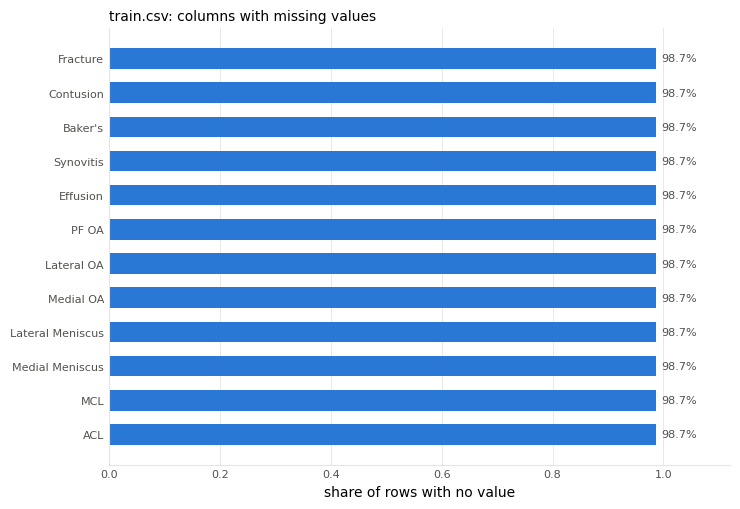

train.csv: 4,407 studies | officially labelled on all 12 findings: 58 | partially labelled: 0 | no official label: 4,349


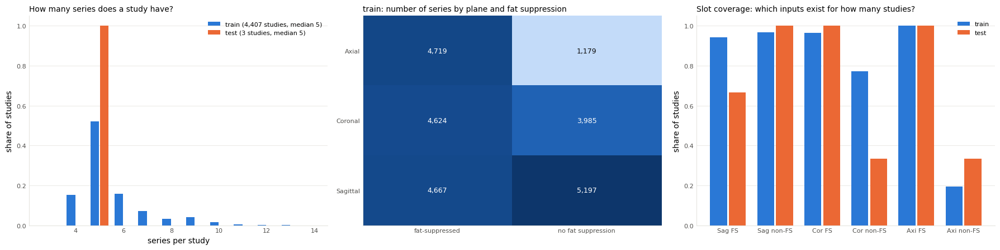

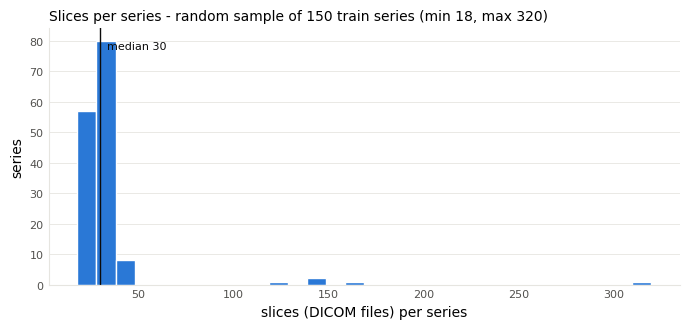

In [2]:
# ======================= Part A.2 - what is in the competition data? =======================
AX_tables = {}     # name -> DataFrame, reused by later analysis cells (kept in memory only)


def AX_data_overview():
    top = sorted(p.name for p in AX_COMP.iterdir())          # top level only: the tree holds ~820k DICOM files
    print("top-level entries:", top)
    rows = []
    for name in ("train.csv", "train_series.csv", "test.csv", "test_series.csv", "sample_submission.csv"):
        f = AX_COMP / name
        if not f.is_file():
            rows.append({"file": name, "rows": "missing"})
            continue
        d = AX_pd.read_csv(f, dtype={AX_UID: str, "SeriesInstanceUID": str})
        AX_tables[name] = d
        text_cols = [c for c in d.columns if AX_is_text(d[c]) and d[c].dropna().astype(str).str.len().mean() > 150]
        rows.append({"file": name, "rows": len(d), "columns": d.shape[1],
                     "studies": d[AX_UID].nunique() if AX_UID in d else None,
                     "column names": ", ".join(c if c not in text_cols else f"{c} (free text)" for c in d.columns)[:160]})
    AX_show(AX_pd.DataFrame(rows), "Tables in the competition directory")
    for split in ("train_series", "test_series"):
        p = AX_COMP / split
        if p.is_dir():
            print(f"{split}/: {sum(1 for _ in os.scandir(p)):,} study folders")


def AX_missing_values():
    """Fraction of empty cells per column. In train.csv most label cells are empty BY DESIGN:
    only a small set of studies has official labels, the rest only have a report."""
    use = []
    for n in ("train.csv", "train_series.csv", "test.csv", "test_series.csv"):
        if n in AX_tables:
            miss = AX_tables[n].isna().mean()
            if (miss > 0).any():
                use.append((n, miss[miss > 0].sort_values()))
            else:
                print(f"{n}: no missing values in any of its {AX_tables[n].shape[1]} columns")
    if use:
        fig, axes = AX_plt.subplots(1, len(use), figsize=(7.5 * len(use), 0.3 * max(len(m) for _, m in use) + 1.6), squeeze=False)
        for ax, (name, miss) in zip(axes[0], use):
            ax.barh(miss.index.astype(str), miss.values, color=AX_C["blue"], height=0.6)
            for y, v in enumerate(miss.values):
                ax.text(v + 0.01, y, f"{v:.1%}", va="center", fontsize=8, color=AX_C["muted"])
            ax.set_xlim(0, 1.12); ax.set_xlabel("share of rows with no value")
            ax.set_title(f"{name}: columns with missing values", fontsize=10, loc="left")
            AX_style(ax)
        AX_plt.tight_layout(); AX_plt.show()
    if "train.csv" in AX_tables:
        d = AX_tables["train.csv"]
        lab = [c for c in d.columns if AX_norm(c) in AX_NLAB]
        if lab:
            n_all = int(d[lab].notna().all(axis=1).sum()); n_any = int(d[lab].notna().any(axis=1).sum())
            print(f"train.csv: {len(d):,} studies | officially labelled on all {len(lab)} findings: {n_all} "
                  f"| partially labelled: {n_any - n_all} | no official label: {len(d) - n_any:,}")


def AX_series_statistics():
    """How studies are built from series: this decides which model 'slots' can be filled."""
    have = {k: AX_tables[f"{k}_series.csv"] for k in ("train", "test") if f"{k}_series.csv" in AX_tables}
    if not have:
        print("no series tables loaded"); return
    need = {"Anatomical_Plane", "Fat_Suppression"}
    fig, axes = AX_plt.subplots(1, 3, figsize=(18, 4.6))
    # (1) series per study
    ax = axes[0]
    width = 0.8 / len(have)
    for k, ((split, d), color) in enumerate(zip(have.items(), (AX_C["blue"], AX_C["orange"]))):
        per = d.groupby(AX_UID).size()
        share = per.value_counts(normalize=True).sort_index()
        ax.bar(share.index + k * width - 0.4 + width / 2, share.values, width=width * 0.9, color=color,
               label=f"{split} ({len(per):,} studies, median {per.median():.0f})")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.set_xlabel("series per study"); ax.set_ylabel("share of studies")
    ax.set_title("How many series does a study have?", fontsize=10, loc="left"); ax.legend(frameon=False, fontsize=8)
    AX_style(ax, "y")
    # (2) plane x fat-suppression counts (train if present)
    split, d = next(iter(have.items()))
    ax = axes[1]
    if need.issubset(d.columns):
        tab = AX_pd.crosstab(d["Anatomical_Plane"].fillna("missing"), d["Fat_Suppression"].fillna(-1).map(
            {0: "no fat suppression", 1: "fat-suppressed", -1: "flag missing"}))
        im = ax.imshow(tab.to_numpy(), cmap=AX_SEQ, vmin=0, aspect="auto")
        ax.set_xticks(range(tab.shape[1]), tab.columns, fontsize=8); ax.set_yticks(range(tab.shape[0]), tab.index, fontsize=8)
        for i in range(tab.shape[0]):
            for j in range(tab.shape[1]):
                v = tab.iat[i, j]
                ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=9,
                        color="white" if v > tab.to_numpy().max() * 0.55 else AX_C["ink"])
        ax.set_title(f"{split}: number of series by plane and fat suppression", fontsize=10, loc="left")
        AX_style(ax, None)
    else:
        ax.axis("off"); ax.text(0.5, 0.5, "plane / fat-suppression columns not found", ha="center")
    # (3) slot coverage: share of studies owning at least one series of each (plane, fat-sat) kind
    ax = axes[2]
    slots = [(p, f) for p in ("Sagittal", "Coronal", "Axial") for f in (1, 0)]
    names = [f"{p[:3]} {'FS' if f else 'non-FS'}" for p, f in slots]
    width = 0.8 / len(have)
    for k, ((split, d), color) in enumerate(zip(have.items(), (AX_C["blue"], AX_C["orange"]))):
        if not need.issubset(d.columns):
            continue
        n = d[AX_UID].nunique()
        cov = [d[(d.Anatomical_Plane == p) & (d.Fat_Suppression == f)][AX_UID].nunique() / max(n, 1) for p, f in slots]
        ax.bar(AX_np.arange(len(slots)) + k * width - 0.4 + width / 2, cov, width=width * 0.9, color=color, label=split)
    ax.set_xticks(range(len(slots)), names, fontsize=8); ax.set_ylim(0, 1.05); ax.set_ylabel("share of studies")
    ax.set_title("Slot coverage: which inputs exist for how many studies?", fontsize=10, loc="left")
    ax.legend(frameon=False, fontsize=8); AX_style(ax, "y")
    AX_plt.tight_layout(); AX_plt.show()


def AX_slices_per_series(max_series=150, seed=0):
    """Count DICOM files in a random sample of series folders (a full scan of ~820k files is not needed)."""
    split = "train" if (AX_COMP / "train_series").is_dir() and "train_series.csv" in AX_tables else "test"
    d = AX_tables.get(f"{split}_series.csv")
    if d is None or "SeriesInstanceUID" not in d:
        print("series table not available"); return
    sample = d.sample(min(max_series, len(d)), random_state=seed)
    counts = []
    for r in sample.itertuples(index=False):
        p = AX_COMP / f"{split}_series" / str(getattr(r, AX_UID)) / str(r.SeriesInstanceUID)
        if p.is_dir():
            counts.append(sum(1 for e in os.scandir(p) if e.name.endswith(".dcm")))
    if not counts:
        print("no series folders readable for the slice count"); return
    c = AX_np.asarray(counts)
    fig, ax = AX_plt.subplots(figsize=(7, 3.4))
    ax.hist(c, bins=min(30, max(5, len(set(counts)))), color=AX_C["blue"], edgecolor="white", linewidth=1)
    ax.axvline(AX_np.median(c), color=AX_C["ink"], lw=1)
    ax.text(AX_np.median(c), ax.get_ylim()[1] * 0.95, f"  median {AX_np.median(c):.0f}", fontsize=8, color=AX_C["ink"], va="top")
    ax.set_xlabel("slices (DICOM files) per series"); ax.set_ylabel("series")
    ax.set_title(f"Slices per series - random sample of {len(c)} {split} series (min {c.min()}, max {c.max()})", fontsize=10, loc="left")
    AX_style(ax, "y"); AX_plt.tight_layout(); AX_plt.show()


with AX_cell("A.2 data overview"):
    AX_data_overview()
with AX_cell("A.2 missing values"):
    AX_missing_values()
with AX_cell("A.2 series statistics"):
    AX_series_statistics()
with AX_cell("A.2 slices per series"):
    AX_slices_per_series()

# Part B — Radiology-report text preprocessing

**What.** Finds the report column, normalises the text, guesses script and language, measures length, and sets simple English keyword flags.

**Why.** The reports are the only supervision for 4,349 of the 4,407 training studies. Before a language model can turn them into labels they have to be clean and their language mix understood. This notebook does *not* run a language model: the labels were produced upstream (Part C). The preprocessing here documents the input those labels came from and yields a crude, independent signal (keywords) to cross-check them.

**How.**
1. `AX_clean`: Unicode NFKC normalisation (full-width characters, ligatures and non-breaking spaces become ordinary characters) and whitespace collapse. Nothing is translated or removed.
2. `AX_script`: counts characters per Unicode block to find the writing system.
3. `AX_lang`: for Latin-script text, counts common function words per language. This is a rough guess, good enough for a bar chart.
4. Keyword flags: regular expressions for English terms only.

**Effect on predictions.** None. This part is descriptive.

**Fixed here.** A missing report used to be converted to the string `"nan"` and counted as a three-letter Latin report. Missing reports are now empty and excluded from the language and length statistics.

*Real report text is never printed (`AX_SHOW_REPORT_TEXT = False`). The before/after table uses invented sentences.*

raw (invented example),after AX_clean,script,language guess,English keyword flags
'MRI of the right knee.\n\nComplete tear of the ACL .\xa0Moderate joi,MRI of the right knee. Complete tear of the ACL . Moderate joint effus,Latin,en,"ACL, Effusion"
'ＭＲＩ：膝関節。前十字靭帯の断裂を認める。',MRI:膝関節。前十字靭帯の断裂を認める。,CJK,CJK,-
'RM de rodilla izquierda. Se observa rotura del menisco medial sin der,RM de rodilla izquierda. Se observa rotura del menisco medial sin derr,Latin,es,-
'MRT des Kniegelenks. Es zeigt sich ein Erguss und eine Baker-Zyste oh,MRT des Kniegelenks. Es zeigt sich ein Erguss und eine Baker-Zyste ohn,Latin,de,Baker's
"'МРТ коленного сустава: выпот, разрыв мениска.'","МРТ коленного сустава: выпот, разрыв мениска.",Cyrillic,Cyrillic,-
None,,-,-,-


Note the last three rows: the keyword flags only fire on English text, and the keyword 'fracture' would fire on 'No fracture' too.
That is why keywords are used only as a rough cross-check, never as labels.
report table: train.csv, text column 'Report' | studies: 4,407 | with a report: 4,407 | without: 0
cleaning changed 76.7% of reports; median characters removed (extra whitespace): 1


col_0,no official labels,official labels
has_report,,
has report,4349,58


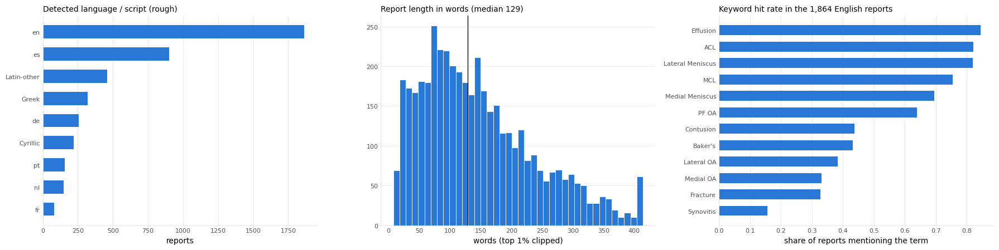

In [3]:
# ======================= Part B - radiology-report text preprocessing =======================
AX_reports = None


def AX_find_reports():
    """Locate the table that holds the free-text reports (longest average text column next to a study id)."""
    cands = [AX_Path(AX_REPORT_FILE)] if AX_REPORT_FILE else sorted(AX_COMP.glob("*.csv"))
    best = None
    for f in cands:
        try:
            d = AX_tables[f.name] if f.name in AX_tables and not AX_REPORT_FILE else AX_pd.read_csv(f)
        except Exception:
            continue
        uid = next((c for c in d.columns if "uid" in c.lower() or AX_norm(c) in ("studyid",)), None)
        txt = [c for c in d.columns if AX_is_text(d[c]) and c != uid]
        if uid is None or not txt:
            continue
        tcol = max(txt, key=lambda c: d[c].dropna().astype(str).str.len().mean() if d[c].notna().any() else 0)
        score = d[tcol].dropna().astype(str).str.len().mean() if d[tcol].notna().any() else 0
        if score > 150 and (best is None or score > best[0]):
            best = (score, f, uid, tcol, d)
    return best


def AX_clean(t):
    """NFKC unicode normalisation (full-width digits, ligatures, odd spaces -> plain forms) + whitespace collapse.
    Nothing is deleted or translated: the text stays readable for any later labelling step."""
    if t is None or (isinstance(t, float) and AX_np.isnan(t)):
        return ""                      # FIX: a missing report used to become the 3-letter string "nan"
    t = unicodedata.normalize("NFKC", str(t))
    return re.sub(r"\s+", " ", t).strip()


def AX_script(t):
    """Dominant writing system among the first 1,500 characters."""
    c = {"Latin": 0, "Cyrillic": 0, "CJK": 0, "Arabic": 0, "Hangul": 0, "Greek": 0, "Hebrew": 0, "Thai": 0, "Devanagari": 0}
    for ch in t[:1500]:
        o = ord(ch)
        if 0x41 <= o <= 0x24F: c["Latin"] += 1
        elif 0x400 <= o <= 0x4FF: c["Cyrillic"] += 1
        elif 0x4E00 <= o <= 0x9FFF or 0x3040 <= o <= 0x30FF: c["CJK"] += 1
        elif 0x600 <= o <= 0x6FF: c["Arabic"] += 1
        elif 0xAC00 <= o <= 0xD7AF: c["Hangul"] += 1
        elif 0x370 <= o <= 0x3FF: c["Greek"] += 1
        elif 0x590 <= o <= 0x5FF: c["Hebrew"] += 1
        elif 0xE00 <= o <= 0xE7F: c["Thai"] += 1
        elif 0x900 <= o <= 0x97F: c["Devanagari"] += 1
    return max(c, key=c.get) if sum(c.values()) else "Unknown"


AX_STOP = {
    "en": {"the", "and", "of", "with", "is", "no", "there", "are", "without", "normal", "seen"},
    "es": {"el", "la", "de", "con", "sin", "y", "en", "los", "las", "se", "del"},
    "fr": {"le", "la", "les", "de", "du", "et", "avec", "sans", "des", "une", "est"},
    "de": {"der", "die", "das", "und", "mit", "ohne", "keine", "ein", "eine", "im", "zeigt"},
    "pt": {"o", "a", "os", "as", "de", "com", "sem", "e", "uma", "um", "do", "da"},
    "it": {"il", "lo", "gli", "di", "con", "senza", "e", "una", "un", "del", "della"},
    "nl": {"de", "het", "een", "en", "met", "zonder", "geen", "van", "is", "er"},
}


def AX_lang(t, script):
    """Very rough language guess for Latin-script text by counting common function words."""
    if script != "Latin":
        return script
    w = re.findall(r"[a-zà-ÿ]+", t.lower())[:300]
    sc = {k: sum(x in v for x in w) for k, v in AX_STOP.items()}
    k = max(sc, key=sc.get)
    return k if sc[k] >= 3 else "Latin-other"


AX_KW = {  # English-only rough flags: an independent, deliberately simple signal
    "ACL": r"\bacl\b|anterior cruciate", "MCL": r"\bmcl\b|medial collateral",
    "Medial Meniscus": r"medial menisc", "Lateral Meniscus": r"lateral menisc",
    "Effusion": r"effusion", "Baker's": r"baker", "Fracture": r"fracture",
    "Contusion": r"contusion|bone bruis|marrow edema", "Synovitis": r"synovitis",
    "Medial OA": r"medial.{0,40}(osteoarth|cartilage)", "Lateral OA": r"lateral.{0,40}(osteoarth|cartilage)",
    "PF OA": r"patellofemoral|retropatellar|trochlea"}


def AX_report_demo():
    """Before/after on INVENTED sentences (not competition data), so the steps can be shown in public output."""
    demo = [
        "MRI  of the right knee.\n\nComplete tear of the ACL . Moderate joint effusion.",
        "ＭＲＩ：膝関節。前十字靭帯の断裂を認める。",                       # full-width Latin letters + Japanese
        "RM de rodilla izquierda. Se observa rotura del menisco medial sin derrame.",
        "MRT des Kniegelenks. Es zeigt sich ein Erguss und eine Baker-Zyste ohne Fraktur.",
        "МРТ коленного сустава: выпот, разрыв мениска.",
        None,
    ]
    rows = []
    for raw in demo:
        clean = AX_clean(raw); script = AX_script(clean) if clean else "-"
        hits = [k for k, rx in AX_KW.items() if re.search(rx, clean.lower())]
        rows.append({"raw (invented example)": repr(raw)[:70], "after AX_clean": clean[:70],
                     "script": script, "language guess": AX_lang(clean, script) if clean else "-",
                     "English keyword flags": ", ".join(hits) or "-"})
    AX_show(AX_pd.DataFrame(rows), "Report preprocessing on invented examples: each step made visible")
    print("Note the last three rows: the keyword flags only fire on English text, and the keyword 'fracture' "
          "would fire on 'No fracture' too.\nThat is why keywords are used only as a rough cross-check, never as labels.")


def AX_process_reports():
    global AX_reports
    found = AX_find_reports()
    if found is None:
        print("No report table detected under the competition dir. Set REPORT_FILE to enable this analysis.")
        return
    _, rf, uid_col, text_col, d = found
    d = d.rename(columns={uid_col: AX_UID}).copy(); d[AX_UID] = d[AX_UID].astype(str)
    d["has_report"] = d[text_col].notna() & (d[text_col].astype(str).str.strip() != "")
    d["report_clean"] = d[text_col].map(AX_clean)
    raw_len = d[text_col].fillna("").astype(str).str.len()
    d["script"] = d["report_clean"].map(AX_script)
    d["lang"] = [AX_lang(t, s) if h else "no report" for t, s, h in zip(d["report_clean"], d["script"], d["has_report"])]
    d["n_chars"] = d["report_clean"].str.len(); d["n_words"] = d["report_clean"].str.split().str.len()
    low = d["report_clean"].str.lower()
    for k, rx in AX_KW.items():
        d["kw_" + k] = low.str.contains(rx, regex=True).astype(int)
    AX_reports = d   # NOTE: held in memory only, never written to disk (competition data must not be redistributed)
    r = d[d.has_report]
    changed = (r["report_clean"] != r[text_col].astype(str)).mean() if len(r) else float("nan")
    removed = (raw_len[d.has_report] - r["n_chars"]).clip(lower=0)
    print(f"report table: {rf.name}, text column '{text_col}' | studies: {len(d):,} | with a report: {len(r):,} "
          f"| without: {len(d) - len(r):,}")
    print(f"cleaning changed {changed:.1%} of reports; median characters removed (extra whitespace): {removed.median():.0f}")
    lab = [c for c in d.columns if AX_norm(c) in AX_NLAB]
    if lab:
        has_lab = d[lab].notna().all(axis=1)
        AX_show(AX_pd.crosstab(d.has_report.map({True: "has report", False: "no report"}),
                               has_lab.map({True: "official labels", False: "no official labels"})),
                "Which supervision exists for which training study?")
    fig, ax = AX_plt.subplots(1, 3, figsize=(18, 4.6))
    vc = r["lang"].value_counts().head(12)
    ax[0].barh(vc.index[::-1], vc.values[::-1], color=AX_C["blue"], height=0.6)
    ax[0].set_title("Detected language / script (rough)", fontsize=10, loc="left"); ax[0].set_xlabel("reports")
    ax[1].hist(r["n_words"].clip(upper=r["n_words"].quantile(.99)), bins=40, color=AX_C["blue"], edgecolor="white", linewidth=0.6)
    ax[1].axvline(r["n_words"].median(), color=AX_C["ink"], lw=1)
    ax[1].set_title(f"Report length in words (median {r['n_words'].median():.0f})", fontsize=10, loc="left"); ax[1].set_xlabel("words (top 1% clipped)")
    en = r[r.lang == "en"]
    kwm = en[[c for c in d.columns if c.startswith("kw_")]].mean().sort_values(); kwm.index = [i[3:] for i in kwm.index]
    ax[2].barh(kwm.index, kwm.values, color=AX_C["blue"], height=0.6)
    ax[2].set_title(f"Keyword hit rate in the {len(en):,} English reports", fontsize=10, loc="left"); ax[2].set_xlabel("share of reports mentioning the term")
    AX_style(ax[0]); AX_style(ax[1], "y"); AX_style(ax[2])
    AX_plt.tight_layout(); AX_plt.show()
    if AX_SHOW_REPORT_TEXT and len(r):   # off by default - see the data-handling note at the top
        for t_raw, t_clean in zip(r[text_col].head(2), r["report_clean"].head(2)):
            print("RAW  :", repr(str(t_raw)[:200])); print("CLEAN:", t_clean[:200]); print()


with AX_cell("B report demo"):
    AX_report_demo()
with AX_cell("B report preprocessing"):
    AX_process_reports()

# Part C — LLM pseudo-labels: description and quality audit

**What.** Loads the attached label file (`rsna-knee-llm-labels`), describes it, and compares it with the official labels on the studies that have both.

**Why.** A model can only be as good as its training labels. These labels were written by a language model reading reports, so they inherit three kinds of error: the report may not mention a finding that is visible, the language model may misread the report (negation, another language), and a "soft" score may be undecided. The pipeline's networks were trained by their authors on report-derived labels of this kind (which exact file each author used is not recorded here). Knowing how noisy each finding is tells you where to expect weak predictions.

**How to read the audit.**
- *ROC-AUC against official labels*: 1.0 means the LLM score ranks every officially positive study above every negative one; 0.5 is chance. Intervals come from resampling the studies (bootstrap).
- *Sensitivity / specificity / kappa* use the 0.5 threshold. Kappa corrects agreement for chance.
- The right-hand chart compares class frequencies. If the LLM labels call a finding positive much more often than the official labels do, the pseudo-labels are systematically shifted.

**Three cautions.**
1. With 58 studies and sometimes fewer than ten positives, the intervals are wide. Treat single-finding numbers as rough.
2. This is a check of **label quality**. It says nothing about how accurate any image model is.
3. The reverse also holds: a model that agrees well with pseudo-labels has learned the pseudo-labels, including their mistakes. Model accuracy is only ever measured against official labels. The live training demo in Part F.3 plots both quantities next to each other.

**Effect on predictions.** None. The label file is read for analysis only.

LLM-label dataset files: ['report_labels_v2.csv']
  report_labels_v2.csv: wide (12/12)
using report_labels_v2.csv: 4,406 studies x 12 findings | soft scores in [0, 1] | missing cells 0


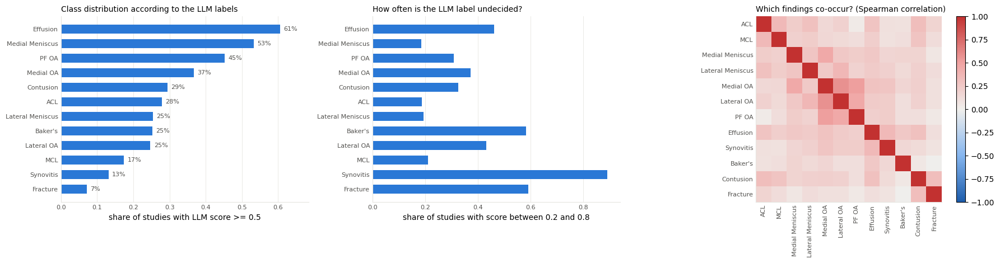

coverage: 4,406 of 4,407 training studies have an LLM label; 0 LLM rows match no training study
official labels: train.csv, 58 labelled studies | with an LLM label too: 57 | fully usable: 57


,n,positives,gold prevalence,LLM prevalence (>=0.5),auc,auc 95% low,auc 95% high,sensitivity,specificity,agreement,kappa
finding,,,,,,,,,,,
ACL,57,23,0.404,0.561,0.997,0.990,1.000,1.000,0.735,0.842,0.692
MCL,57,9,0.158,0.316,0.976,0.945,1.000,1.000,0.812,0.842,0.578
Medial Meniscus,57,26,0.456,0.561,0.943,0.875,0.991,0.962,0.774,0.860,0.722
Lateral Meniscus,57,23,0.404,0.526,0.841,0.722,0.931,0.870,0.706,0.772,0.548
Medial OA,57,15,0.263,0.386,0.908,0.796,0.986,0.933,0.810,0.842,0.646
Lateral OA,57,11,0.193,0.281,0.789,0.584,0.946,0.818,0.848,0.842,0.568
PF OA,57,20,0.351,0.421,0.891,0.787,0.965,0.800,0.784,0.789,0.558
Effusion,57,34,0.596,0.877,0.830,0.733,0.909,1.000,0.304,0.719,0.343
Synovitis,57,27,0.474,0.281,0.694,0.586,0.800,0.481,0.900,0.702,0.389


macro AUC of the LLM labels against official labels: 0.870 (95% bootstrap interval 0.831 - 0.900, n = 57 studies)


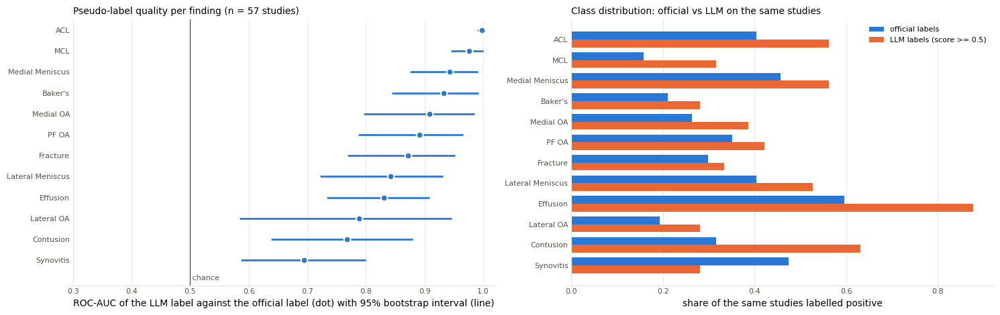

English reports with LLM labels: 1,863


,agreement_auc,n,keyword_rate
finding,,,
ACL,0.566,1863,0.820
MCL,0.538,1863,0.755
Medial Meniscus,0.752,1863,0.695
Lateral Meniscus,0.545,1863,0.819
Medial OA,0.544,1863,0.331
Lateral OA,0.446,1863,0.384
PF OA,0.540,1863,0.639
Effusion,0.571,1863,0.843
Synovitis,0.940,1863,0.156


In [4]:
# ======================= Part C - LLM pseudo-labels: load, describe, and audit against official labels =======================
AX_llm = None; AX_llm_corr = None; AX_gold = None; AX_gold_auc = None; AX_gold_macro_ci = None


def AX_to_wide(df):
    """Bring any label table into the shape [study x finding], whatever the column spelling is."""
    cols = {AX_norm(c): c for c in df.columns}
    uid_col = next((cols[k] for k in cols if k in ("studyinstanceuid", "studyuid", "uid", "studyid")), None) \
        or next((c for c in df.columns if "uid" in c.lower() or "study" in c.lower()), None)
    if uid_col is None:
        return None, "no study-id column"
    m = {}
    for c in df.columns:
        if c == uid_col:
            continue
        n = AX_norm(c)
        hit = [k for k in AX_NLAB if n == k] or [k for k in sorted(AX_NLAB, key=len, reverse=True) if k in n]
        if hit and AX_NLAB[hit[0]] not in m and AX_pd.api.types.is_numeric_dtype(df[c]):
            m[AX_NLAB[hit[0]]] = c
    if len(m) >= 6:
        w = df[[uid_col] + list(m.values())].rename(columns={uid_col: AX_UID, **{v: k for k, v in m.items()}})
        w[AX_UID] = w[AX_UID].astype(str)
        return w.drop_duplicates(AX_UID).set_index(AX_UID), f"wide ({len(m)}/12)"
    fcol = next((c for c in df.columns if AX_norm(c) in ("finding", "label", "target", "abnormality", "name")), None)
    vcol = next((c for c in df.columns if AX_norm(c) in ("value", "score", "prob", "probability", "pred", "prediction", "llmlabel", "y")), None)
    if fcol and vcol:
        t = df[[uid_col, fcol, vcol]].copy(); t[fcol] = t[fcol].map(lambda s: AX_NLAB.get(AX_norm(s)))
        t = t.dropna(subset=[fcol]); t[uid_col] = t[uid_col].astype(str)
        return t.pivot_table(index=uid_col, columns=fcol, values=vcol, aggfunc="mean").rename_axis(AX_UID), "long->wide"
    return None, "could not map columns"


def AX_read(f):
    return AX_pd.read_parquet(f) if f.suffix == ".parquet" else (AX_pd.read_json(f, lines=True) if f.suffix == ".jsonl" else AX_pd.read_csv(f))


def AX_find_gold():
    """Official ('gold') labels = the training studies whose 12 label cells are filled with 0/1.

    Only files from the competition's TRAINING side are considered: a sample submission full of zeros
    would otherwise look like a label table.
    """
    files = [AX_Path(AX_GOLD_FILE)] if AX_GOLD_FILE else [
        f for f in sorted(AX_COMP.glob("*.csv")) if not f.name.lower().startswith(("test", "sample"))]
    best = None
    for f in files:
        try:
            w, _ = AX_to_wide(AX_pd.read_csv(f))
        except Exception:
            continue
        if w is None:
            continue
        w = w.dropna(how="all"); a = w.to_numpy(float)
        if len(w) >= 10 and AX_np.isin(AX_np.unique(a[~AX_np.isnan(a)]), [0, 1]).all():
            if best is None or w.shape[1] > best[0].shape[1]:
                best = (w[[c for c in AX_LAB if c in w.columns]], f)
    return best if best is not None else (None, None)


def AX_load_llm():
    global AX_llm, AX_llm_corr
    files = [AX_Path(AX_LLM_FILE)] if AX_LLM_FILE else sorted(AX_LLM.rglob("*.csv")) + sorted(AX_LLM.rglob("*.parquet")) + sorted(AX_LLM.rglob("*.jsonl"))
    print("LLM-label dataset files:", [f.name for f in files][:15])
    best = None
    for f in files:
        try:
            w, note = AX_to_wide(AX_read(f))
        except Exception as e:
            print("  skip", f.name, e); continue
        print(f"  {f.name}: {note}")
        if w is not None and (best is None or len(w) > len(best[0])):
            best = (w, f)
    if best is None:
        raise RuntimeError("could not parse LLM labels; set LLM_LABEL_FILE")
    AX_llm = best[0][[c for c in AX_LAB if c in best[0].columns]]
    vals = AX_llm.to_numpy(float); binary = AX_np.isin(AX_np.unique(vals[~AX_np.isnan(vals)]), [0, 1]).all()
    print(f"using {best[1].name}: {AX_llm.shape[0]:,} studies x {AX_llm.shape[1]} findings | "
          f"{'hard 0/1 labels' if binary else 'soft scores in [0, 1]'} | missing cells {int(AX_np.isnan(vals).sum())}")
    AX_llm_corr = AX_llm.corr(method="spearman")


def AX_llm_eda():
    """Class distribution, how 'decided' the soft labels are, and which findings co-occur."""
    if AX_llm is None:
        print("LLM labels not loaded"); return
    L = AX_llm
    pos = (L >= 0.5).mean().sort_values()                       # share of studies called positive
    unsure = ((L > 0.2) & (L < 0.8)).mean().reindex(pos.index)   # share of studies with an undecided score
    fig, ax = AX_plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.15]})
    ax[0].barh(pos.index, pos.values, color=AX_C["blue"], height=0.6)
    for y, v in enumerate(pos.values):
        ax[0].text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=8, color=AX_C["muted"])
    ax[0].set_xlim(0, max(0.6, pos.max() + 0.08)); ax[0].set_xlabel("share of studies with LLM score >= 0.5")
    ax[0].set_title("Class distribution according to the LLM labels", fontsize=10, loc="left"); AX_style(ax[0])
    ax[1].barh(unsure.index, unsure.values, color=AX_C["blue"], height=0.6)
    ax[1].set_xlim(0, max(0.2, float(unsure.max()) + 0.05)); ax[1].set_xlabel("share of studies with score between 0.2 and 0.8")
    ax[1].set_title("How often is the LLM label undecided?", fontsize=10, loc="left"); AX_style(ax[1])
    im = ax[2].imshow(AX_llm_corr, cmap=AX_DIV, vmin=-1, vmax=1)
    ax[2].set_xticks(range(len(AX_llm_corr)), AX_llm_corr.columns, rotation=90, fontsize=8)
    ax[2].set_yticks(range(len(AX_llm_corr)), AX_llm_corr.columns, fontsize=8)
    ax[2].set_title("Which findings co-occur? (Spearman correlation)", fontsize=10, loc="left"); AX_style(ax[2], None)
    fig.colorbar(im, ax=ax[2], fraction=.046)
    AX_plt.tight_layout(); AX_plt.show()
    if "train.csv" in AX_tables:
        train_ids = set(AX_tables["train.csv"][AX_UID].astype(str))
        print(f"coverage: {len(train_ids & set(L.index)):,} of {len(train_ids):,} training studies have an LLM label; "
              f"{len(set(L.index) - train_ids)} LLM rows match no training study")


def AX_llm_vs_gold(n_boot=2000, seed=0):
    """Pseudo-label QUALITY check: LLM labels vs the official labels of the same studies.
    This measures how noisy the training signal is. It is not a measure of any model's accuracy."""
    global AX_gold, AX_gold_auc, AX_gold_macro_ci
    gold, gf = AX_find_gold()
    if gold is None or AX_llm is None:
        print("official-label check skipped (labels not auto-detected; set GOLD_LABEL_FILE)"); return
    AX_gold = gold
    both = [u for u in gold.index if u in AX_llm.index]
    labs = [l for l in AX_LAB if l in gold.columns and l in AX_llm.columns]
    G = gold.loc[both, labs]; P = AX_llm.loc[both, labs]
    ok = (G.notna().all(axis=1) & P.notna().all(axis=1)).to_numpy()
    y = G.to_numpy(float)[ok]; s = P.to_numpy(float)[ok]; hard = (s >= 0.5).astype(float)
    print(f"official labels: {gf.name}, {len(gold)} labelled studies | with an LLM label too: {len(both)} | fully usable: {int(ok.sum())}")
    if ok.sum() < 10:
        print("too few overlapping studies for a meaningful comparison"); return
    auc = AX_auc_matrix(y, s)
    tp = (hard * y).sum(0); tn = ((1 - hard) * (1 - y)).sum(0); n1 = y.sum(0); n0 = len(y) - n1
    with AX_np.errstate(invalid="ignore", divide="ignore"):
        sens = tp / n1; spec = tn / n0; acc = (tp + tn) / len(y)
        pe = (n1 / len(y)) * hard.mean(0) + (n0 / len(y)) * (1 - hard.mean(0)); kappa = (acc - pe) / (1 - pe)
    rng = AX_np.random.default_rng(seed)                      # bootstrap: resample studies with replacement
    boot = AX_np.stack([AX_auc_matrix(y[i], s[i]) for i in rng.integers(0, len(y), (n_boot, len(y)))])
    lo, hi = AX_np.nanpercentile(boot, [2.5, 97.5], axis=0)
    macro = AX_np.nanmean(boot, axis=1); AX_gold_macro_ci = (float(AX_np.nanmean(auc)), *AX_np.percentile(macro, [2.5, 97.5]))
    AX_gold_auc = AX_pd.DataFrame({"n": len(y), "positives": n1.astype(int), "gold prevalence": n1 / len(y),
                                   "LLM prevalence (>=0.5)": hard.mean(0), "auc": auc, "auc 95% low": lo, "auc 95% high": hi,
                                   "sensitivity": sens, "specificity": spec, "agreement": acc, "kappa": kappa},
                                  index=AX_pd.Index(labs, name="finding"))
    AX_show(AX_gold_auc.round(3), "LLM labels vs official labels (threshold 0.5 for sensitivity / specificity / kappa)")
    print(f"macro AUC of the LLM labels against official labels: {AX_gold_macro_ci[0]:.3f} "
          f"(95% bootstrap interval {AX_gold_macro_ci[1]:.3f} - {AX_gold_macro_ci[2]:.3f}, n = {len(y)} studies)")
    few = [l for l, k in zip(labs, n1) if min(k, len(y) - k) < 8]
    if few:
        print(f"fewer than 8 positives or negatives -> very wide intervals for: {', '.join(few)}")
    order = AX_np.argsort(AX_np.nan_to_num(auc, nan=0))
    fig, ax = AX_plt.subplots(1, 2, figsize=(15, 4.8))
    yy = AX_np.arange(len(labs))
    ax[0].hlines(yy, lo[order], hi[order], color=AX_C["blue"], lw=2)
    ax[0].plot(auc[order], yy, "o", color=AX_C["blue"], ms=7, mec="white", mew=1.5)
    ax[0].axvline(0.5, color=AX_C["muted"], lw=1); ax[0].text(0.5, -0.85, " chance", fontsize=8, color=AX_C["muted"], va="center")
    ax[0].set_yticks(yy, [labs[i] for i in order], fontsize=8); ax[0].set_ylim(-1.2, len(labs) - 0.5)
    ax[0].set_xlim(min(0.3, float(AX_np.nanmin(lo)) - 0.03), 1.02)
    ax[0].set_xlabel("ROC-AUC of the LLM label against the official label (dot) with 95% bootstrap interval (line)")
    ax[0].set_title(f"Pseudo-label quality per finding (n = {len(y)} studies)", fontsize=10, loc="left"); AX_style(ax[0])
    w = 0.38
    ax[1].barh(yy + w / 2, (n1 / len(y))[order], height=w, color=AX_C["blue"], label="official labels")
    ax[1].barh(yy - w / 2, hard.mean(0)[order], height=w, color=AX_C["orange"], label="LLM labels (score >= 0.5)")
    ax[1].set_yticks(yy, [labs[i] for i in order], fontsize=8); ax[1].set_xlabel("share of the same studies labelled positive")
    ax[1].set_title("Class distribution: official vs LLM on the same studies", fontsize=10, loc="left")
    ax[1].legend(frameon=False, fontsize=8); AX_style(ax[1])
    AX_plt.tight_layout(); AX_plt.show()


def AX_llm_vs_keywords():
    """Second, weaker cross-check on English reports only: does the LLM score rise when the finding is mentioned?"""
    if AX_llm is None or AX_reports is None:
        print("keyword cross-check skipped (needs LLM labels and the report table)"); return
    en = AX_reports[AX_reports["lang"] == "en"].set_index(AX_UID); both = en.index.intersection(AX_llm.index); rows = []
    from sklearn.metrics import roc_auc_score
    for l in AX_LAB:
        c = "kw_" + l
        if c in en.columns and l in AX_llm.columns and len(both) > 30:
            y = en.loc[both, c]; p = AX_llm.loc[both, l]; ok = p.notna()
            if y[ok].nunique() == 2 and p[ok].nunique() > 1:
                rows.append((l, roc_auc_score(y[ok], p[ok]), int(ok.sum()), float(y[ok].mean())))
    if not rows:
        print("keyword cross-check skipped (not enough English reports with variation)"); return
    kw = AX_pd.DataFrame(rows, columns=["finding", "agreement_auc", "n", "keyword_rate"]).set_index("finding")
    print(f"English reports with LLM labels: {len(both):,}")
    AX_show(kw.round(3), "LLM label vs 'the report mentions the term' (agreement, not accuracy)")


with AX_cell("C load LLM labels"):
    AX_load_llm()
with AX_cell("C LLM-label EDA"):
    AX_llm_eda()
with AX_cell("C LLM vs official labels"):
    AX_llm_vs_gold()
with AX_cell("C LLM vs keywords"):
    AX_llm_vs_keywords()

# Part D — Image processing: from a DICOM file to the numbers a network reads

A neural network needs every input in the same shape and on the same scale. A knee MRI study is the opposite: a folder with a varying number of series, each a stack of a varying number of images, in different sizes, pixel spacings, orientations and brightness ranges. **Preprocessing** is the list of decisions that turns one into the other. This part takes one example study (the first test study) through those decisions, one cell per decision.

| Step | Question it answers | Cell |
|---|---|---|
| 1 | What is stored in a DICOM file? | D.1 |
| 2 | In which order do the slices belong? | D.2 |
| 3 | How large is a pixel, and how much of the leg is in the picture? | D.3 |
| 4 | What does a pixel value mean? | D.4 |
| 5 | Which way round is the picture, and is it a left or a right knee? | D.5 |
| 6 | How does a 2-D network get depth information? | D.6 |
| 7 | Which size and number format does the network receive? | D.7 |

**The same seven decisions, taken four times.** Each model family in this notebook answers them in its own way. The answers are not interchangeable: a network must be given at inference exactly what it was given in training.

| Decision | A1 CoAtNet | A2 ConvNeXt reader | B1 DINOv2 | B2 A5 |
|---|---|---|---|---|
| Slice order | physical position | physical position, in a fixed direction | physical position | `InstanceNumber` |
| Slices used | 96 per study in 5 slots, from 2–98 % of each series | up to 64 per series; 16 windows per slot | 12 per slot, from the central 20–80 % | 16 per slot, from 12–88 % |
| Field of view | central 140 mm | 153.6 mm at 0.4 mm per pixel | central 130 mm | central 130 mm |
| Intensity window | 2nd–98th percentile of the chosen slices | 1st–99.5th percentile of the series | 1st–99th percentile of the chosen slices | 1st–99th percentile of each slice |
| Image size | 384 px, network sees the central 320 | 384 px cache, resized to 256 and 320 | 336 px | 336 px |
| Left / right | predicted twice: plain and mirrored | standard orientation; plain and flipped | right knees mirrored once, before the network | coronal and axial mirrored for right knees |
| Depth | 3 neighbouring slices as 3 channels | 3 neighbouring slices as 3 channels | 3 neighbouring slices as 3 channels | 16 slices as 16 channels |

Part G tests what happens when one of these steps is left out at inference.

## D.0 A small toolbox and the example study

The functions in this cell are written to be read: `AX_read_slice` (one file → image and header), `AX_slice_position`, `AX_load_series`, `AX_window` (percentile windowing) and `AX_mm_crop` (crop of a fixed physical size). The model stages below use their own, faster readers that follow the same ideas.

In [5]:
# ======================= Part D.0 - a small DICOM toolbox for the walkthrough =======================
# Deliberately simple code, written for reading. The model pipeline in Part E uses its own, faster
# readers; the last cells of each stage show that they produce the same kind of picture.
import pydicom as AX_dcm

AX_DEMO = {}      # the example study used by every figure in Part D


def AX_read_slice(path):
    """One DICOM file -> (2-D float image in real intensity units, header)."""
    ds = AX_dcm.dcmread(str(path))
    img = ds.pixel_array.astype(AX_np.float32)
    img = img * float(getattr(ds, "RescaleSlope", 1) or 1) + float(getattr(ds, "RescaleIntercept", 0) or 0)
    if str(getattr(ds, "PhotometricInterpretation", "")) == "MONOCHROME1":     # stored inverted: flip to "bright = high signal"
        img = img.max() - img
    return img, ds


def AX_slice_position(ds):
    """Position of the slice along the scan direction, in millimetres.
    The header gives the position of the image corner (ImagePositionPatient) and the directions of its
    rows and columns (ImageOrientationPatient). Their cross product is the direction the stack runs in."""
    iop = AX_np.asarray(ds.ImageOrientationPatient, float)
    normal = AX_np.cross(iop[:3], iop[3:])
    return float(AX_np.dot(AX_np.asarray(ds.ImagePositionPatient, float), normal))


def AX_natural_key(name):
    return [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", str(name))]


def AX_load_series(sdir):
    """All slices of one series, sorted by physical position. Returns (images, headers, file names)."""
    files = sorted((p for p in AX_Path(sdir).iterdir() if p.suffix == ".dcm"), key=lambda p: AX_natural_key(p.name))
    items = []
    for f in files:
        try:
            img, ds = AX_read_slice(f)
            items.append((AX_slice_position(ds), img, ds, f.name))
        except Exception:
            continue                                   # an unreadable file is skipped, exactly as the pipeline does
    items.sort(key=lambda t: t[0])
    return [t[1] for t in items], [t[2] for t in items], [t[3] for t in items]


def AX_choose_demo_study():
    """First test study, and for each plane its series with the most slices (fat-suppressed preferred)."""
    ids = AX_pd.read_csv(AX_COMP / "test.csv", dtype={AX_UID: str})[AX_UID].tolist()
    tser = AX_pd.read_csv(AX_COMP / "test_series.csv", dtype={AX_UID: str, "SeriesInstanceUID": str})
    study = ids[0]
    rows = tser[tser[AX_UID] == study]
    chosen = {}
    for plane in ("Sagittal", "Coronal", "Axial"):
        cand = rows[rows.Anatomical_Plane == plane].copy()
        if cand.empty:
            continue
        cand["n"] = [len(list((AX_COMP / "test_series" / study / s).glob("*.dcm"))) for s in cand.SeriesInstanceUID]
        cand = cand.sort_values(["Fat_Suppression", "n"], ascending=[False, False]) if "Fat_Suppression" in cand else cand.sort_values("n", ascending=False)
        chosen[plane] = AX_COMP / "test_series" / study / cand.iloc[0].SeriesInstanceUID
    AX_DEMO.clear()
    AX_DEMO.update(study=study, series=chosen)
    main = chosen.get("Sagittal") or next(iter(chosen.values()))
    AX_DEMO["images"], AX_DEMO["headers"], AX_DEMO["names"] = AX_load_series(main)
    AX_DEMO["main"] = main
    print(f"example study : {study}")
    for plane, d in chosen.items():
        print(f"  {plane:<9s}: series ...{d.name[-12:]}  ({len(list(d.glob('*.dcm')))} files)")
    print(f"walkthrough series: {main.name[-12:]} | {len(AX_DEMO['images'])} readable slices | "
          f"image size {AX_DEMO['images'][0].shape[0]} x {AX_DEMO['images'][0].shape[1]} px")


def AX_window(img, lo_pct=1, hi_pct=99, ref=None):
    """Percentile windowing: clip to the [lo, hi] percentiles of `ref` (default: the image itself) and scale to 0..1."""
    lo, hi = AX_np.percentile(img if ref is None else ref, [lo_pct, hi_pct])
    return AX_np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1)


def AX_mm_crop(img, spacing_mm, crop_mm):
    """Centre crop of a fixed PHYSICAL size (crop_mm x crop_mm), whatever the pixel size is."""
    h, w = img.shape
    n = int(round(crop_mm / max(spacing_mm, 1e-3)))
    n = min(n, h, w)
    y, x = (h - n) // 2, (w - n) // 2
    return img[y:y + n, x:x + n]


def AX_resize(img, size, how="area"):
    """Resize a 2-D float image to size x size pixels. how='area' averages the pixels that fall into each new
    pixel when shrinking (the idea of OpenCV's INTER_AREA, which the pipeline uses); how='nearest' picks single pixels.
    Pillow is used here on purpose: the pipeline later starts worker processes that use OpenCV, and OpenCV's
    own thread pool should not be started in the notebook process before that."""
    from PIL import Image
    im = Image.fromarray(AX_np.ascontiguousarray(img, dtype=AX_np.float32), mode="F")
    if how == "nearest":
        method = Image.NEAREST
    else:
        method = Image.BOX if size < min(img.shape) else Image.BILINEAR
    return AX_np.asarray(im.resize((size, size), method), dtype=AX_np.float32)


def AX_imshow(ax, img, title=None, **kw):
    ax.imshow(img, cmap="gray", **kw)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    if title:
        ax.set_title(title, fontsize=9)


with AX_cell("D.0 choose example study"):
    AX_choose_demo_study()

example study : 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
  Sagittal : series ...518906646132  (30 files)
  Coronal  : series ...304653662081  (30 files)
  Axial    : series ...096767429689  (160 files)
walkthrough series: 518906646132 | 30 readable slices | image size 800 x 800 px


## D.1 What is inside one DICOM file?

**What.** DICOM is the file format of medical imaging. One file holds one slice: a **header** with named fields that describe how and where the picture was taken, and the **pixel data**.

**Why it matters.** Almost every preprocessing step needs a header field: the position for sorting, the pixel spacing for cropping, the orientation for mirroring. An image file without its header (a PNG export, for example) could not be processed correctly.

**What to look at.** The value range in the printed line: MRI pixels are 12- or 16-bit numbers, not 0–255. In the histogram most pixels are near zero (air around the leg) and a thin tail reaches very high values. That tail is the reason for step D.4.

header field,value,meaning
SeriesDescription,t2_tse_sag_d,what the technician called the scan
Rows,800,image height in pixels
Columns,800,image width in pixels
PixelSpacing,"[0.188, 0.188]","size of one pixel in mm (row, column)"
SliceThickness,3,thickness of the slice in mm
ImagePositionPatient,"[59.775, -133.45, 76.545]","where the image corner sits in the scanner, in mm"
ImageOrientationPatient,"[0.158, 0.985, 0.066, 0.016, 0.065, -0.998]",directions of the image rows and columns
InstanceNumber,15,running number given by the scanner
BitsStored,12,bits used per pixel value
PhotometricInterpretation,MONOCHROME2,MONOCHROME2 = bright means high signal


pixel data: array of shape (800, 800), type uint16, values 0 to 1849 (a JPEG photo would have values 0 to 255)


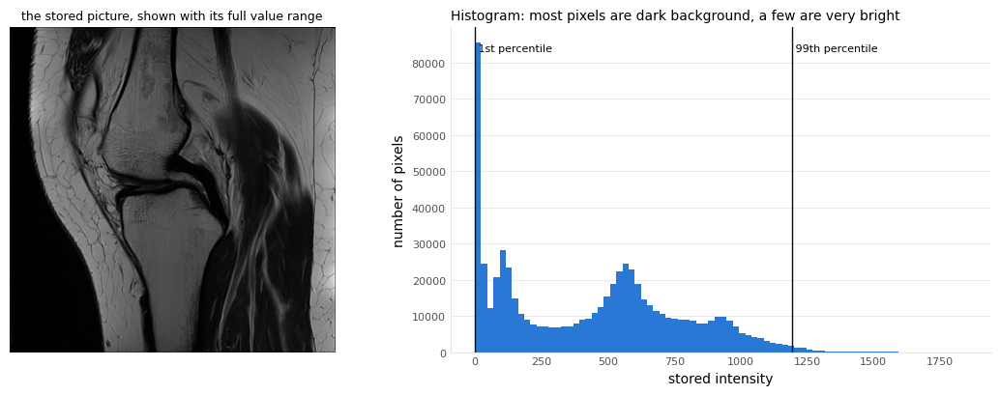

In [6]:
# ======================= Part D.1 - what is inside one DICOM file? =======================
def AX_show_dicom_anatomy():
    k = len(AX_DEMO["images"]) // 2
    img, ds = AX_DEMO["images"][k], AX_DEMO["headers"][k]
    fields = [("SeriesDescription", "what the technician called the scan"),
              ("Rows", "image height in pixels"), ("Columns", "image width in pixels"),
              ("PixelSpacing", "size of one pixel in mm (row, column)"),
              ("SliceThickness", "thickness of the slice in mm"),
              ("ImagePositionPatient", "where the image corner sits in the scanner, in mm"),
              ("ImageOrientationPatient", "directions of the image rows and columns"),
              ("InstanceNumber", "running number given by the scanner"),
              ("BitsStored", "bits used per pixel value"),
              ("PhotometricInterpretation", "MONOCHROME2 = bright means high signal"),
              ("RepetitionTime", "TR in ms: a scan setting that controls contrast"),
              ("EchoTime", "TE in ms: a scan setting that controls contrast")]
    rows = []
    for name, meaning in fields:
        v = getattr(ds, name, None)
        if v is not None:
            v = [round(float(x), 3) for x in v] if hasattr(v, "__len__") and not isinstance(v, str) else v
            rows.append({"header field": name, "value": str(v)[:60], "meaning": meaning})
    AX_show(AX_pd.DataFrame(rows), f"Header of slice {k + 1} of {len(AX_DEMO['images'])}: the part of the file that is not picture")
    raw = ds.pixel_array
    print(f"pixel data: array of shape {raw.shape}, type {raw.dtype}, values {int(raw.min())} to {int(raw.max())} "
          f"(a JPEG photo would have values 0 to 255)")
    fig, ax = AX_plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
    AX_imshow(ax[0], img, "the stored picture, shown with its full value range")
    ax[1].hist(img.ravel(), bins=80, color=AX_C["blue"])
    p1, p99 = AX_np.percentile(img, [1, 99])
    for v, name in ((p1, "1st percentile"), (p99, "99th percentile")):
        ax[1].axvline(v, color=AX_C["ink"], lw=1); ax[1].text(v, ax[1].get_ylim()[1] * 0.95, " " + name, fontsize=8, va="top")
    ax[1].set_xlabel("stored intensity"); ax[1].set_ylabel("number of pixels")
    ax[1].set_title("Histogram: most pixels are dark background, a few are very bright", fontsize=10, loc="left")
    AX_style(ax[1], "y"); AX_plt.tight_layout(); AX_plt.show()


with AX_cell("D.1 DICOM anatomy"):
    AX_show_dicom_anatomy()

## D.2 Putting the slices in the right order

**What.** A series is a stack of parallel slices. The files in its folder have to be sorted so that neighbours in the list are neighbours in the knee.

**How.** The header gives the position of the image corner in the scanner's coordinate system (`ImagePositionPatient`) and the directions of the image rows and columns (`ImageOrientationPatient`). The cross product of the two directions is the direction the stack runs in; the dot product of the corner position with that direction is the slice's position along the stack in millimetres. Sorting by this number is correct by construction.

**Why not simply sort the file names?** The table checks three shortcuts on this series. Sorting names as text is the classic trap: `10.dcm` comes before `2.dcm`. `InstanceNumber` usually works, but scanners are free to number slices in either direction or per acquisition.

**Why it matters for the models.** All four models stack neighbouring slices (D.6). With a wrong order the "neighbours" are unrelated images and the depth information is destroyed. Part G measures this.

sort the files by,gives the anatomical order?
physical position (what the pipeline does),"yes, by definition"
InstanceNumber in the header,yes
"file name, numbers read as numbers",NO
"file name, plain text ('10.dcm' before '2.dcm')",NO


slice positions run from -130.1 mm to -34.4 mm; distance between neighbours: 3.30 mm (median)


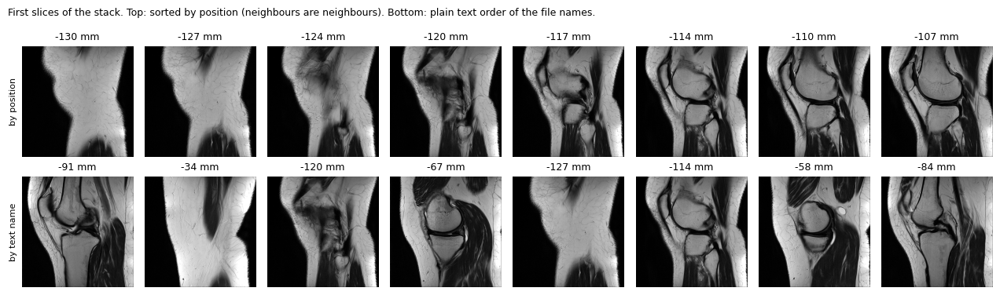

In [7]:
# ======================= Part D.2 - putting the slices in the right order =======================
def AX_show_slice_order():
    names, heads, imgs = AX_DEMO["names"], AX_DEMO["headers"], AX_DEMO["images"]      # already sorted by position
    pos = AX_np.array([AX_slice_position(h) for h in heads])
    by_name = sorted(range(len(names)), key=lambda i: AX_natural_key(names[i]))          # order of the file names
    by_text = sorted(range(len(names)), key=lambda i: names[i])                          # plain alphabetical order
    inst = [int(getattr(h, "InstanceNumber", 0) or 0) for h in heads]
    by_inst = sorted(range(len(names)), key=lambda i: inst[i])
    same = lambda order: order == list(range(len(names))) or order == list(range(len(names)))[::-1]
    AX_show(AX_pd.DataFrame([
        {"sort the files by": "physical position (what the pipeline does)", "gives the anatomical order?": "yes, by definition"},
        {"sort the files by": "InstanceNumber in the header", "gives the anatomical order?": "yes" if same(by_inst) else "NO"},
        {"sort the files by": "file name, numbers read as numbers", "gives the anatomical order?": "yes" if same(by_name) else "NO"},
        {"sort the files by": "file name, plain text ('10.dcm' before '2.dcm')", "gives the anatomical order?": "yes" if same(by_text) else "NO"},
    ]), "Four ways to order the slices of this series")
    gap = AX_np.diff(pos)
    print(f"slice positions run from {pos.min():.1f} mm to {pos.max():.1f} mm; distance between neighbours: "
          f"{AX_np.median(AX_np.abs(gap)):.2f} mm (median)")
    n_show = min(8, len(imgs))
    ref = AX_np.concatenate([i[::4, ::4].ravel() for i in imgs])
    fig, axes = AX_plt.subplots(2, n_show, figsize=(1.6 * n_show, 3.9), squeeze=False)
    for c in range(n_show):
        AX_imshow(axes[0][c], AX_window(imgs[c], ref=ref), f"{pos[c]:.0f} mm")
        j = by_text[c]
        AX_imshow(axes[1][c], AX_window(imgs[j], ref=ref), f"{pos[j]:.0f} mm")
    axes[0][0].set_ylabel("by position", fontsize=8); axes[1][0].set_ylabel("by text name", fontsize=8)
    fig.suptitle("First slices of the stack. Top: sorted by position (neighbours are neighbours). Bottom: plain text order of the file names.",
                 fontsize=9, x=0.01, ha="left")
    AX_plt.tight_layout(); AX_plt.show()


with AX_cell("D.2 slice order"):
    AX_show_slice_order()

## D.3 Physical size: crop in millimetres, not in pixels

**What.** Two scans of the same knee can differ in pixel size (for example 0.3 mm or 0.6 mm) and in how much of the leg is in the picture (the *field of view*). The scatter plot shows this variety for a sample of series.

**How.** `PixelSpacing` gives the size of one pixel. A crop of a fixed physical size, for example 140 mm around the image centre, therefore needs `140 / PixelSpacing` pixels, a different number for each scan. After the crop every image is resized to the same number of pixels.

**Why.** After this step one pixel covers the same piece of anatomy in every study. Without it, the same meniscus would be 40 pixels wide in one study and 80 in the next, and the network would have to learn each size separately.

**What to look at.** The two knee images: the whole picture squeezed into the square, and the 140 mm crop. The crop removes thigh and calf that carry no information for the twelve findings.

95 series inspected | pixel size 0.14 to 0.89 mm | image height 192 to 1024 px | field of view 130 to 230 mm


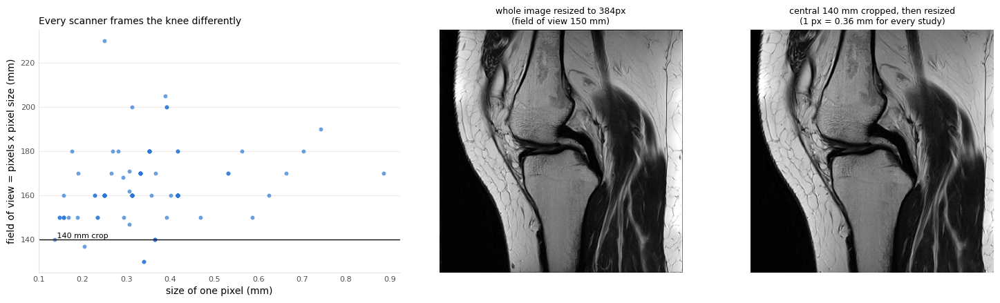

With the millimetre crop a knee fills the same share of the picture in every study, so the network does not have to learn that the same tear can come in different sizes.


In [8]:
# ======================= Part D.3 - physical size: crop in millimetres, not in pixels =======================
def AX_show_physical_size(max_series=80, crop_mm=140.0, out_px=384):
    # (a) how different are the scans? one header per series, from random samples of the test and the training series
    recs = []
    for split in ("test", "train"):
        f = AX_COMP / f"{split}_series.csv"
        if not f.is_file() or not (AX_COMP / f"{split}_series").is_dir():
            continue
        table = AX_pd.read_csv(f, dtype={AX_UID: str, "SeriesInstanceUID": str})
        table = table.sample(min(len(table), max_series), random_state=0)       # a sample is enough; never the whole hidden test set
        for r in table.itertuples(index=False):
            d = AX_COMP / f"{split}_series" / getattr(r, AX_UID) / r.SeriesInstanceUID
            files = sorted(d.glob("*.dcm")) if d.is_dir() else []
            if not files:
                continue
            try:
                h = AX_dcm.dcmread(str(files[len(files) // 2]), stop_before_pixels=True)
                recs.append({"split": split, "pixel_mm": float(h.PixelSpacing[0]), "rows": int(h.Rows),
                             "fov_mm": float(h.PixelSpacing[0]) * int(h.Rows)})
            except Exception:
                continue
    info = AX_pd.DataFrame(recs)
    print(f"{len(info)} series inspected | pixel size {info.pixel_mm.min():.2f} to {info.pixel_mm.max():.2f} mm | "
          f"image height {info.rows.min()} to {info.rows.max()} px | field of view {info.fov_mm.min():.0f} to {info.fov_mm.max():.0f} mm")
    img, ds = AX_DEMO["images"][len(AX_DEMO["images"]) // 2], AX_DEMO["headers"][len(AX_DEMO["images"]) // 2]
    sp = float(ds.PixelSpacing[0])
    whole = AX_resize(AX_window(img), out_px)
    crop = AX_resize(AX_mm_crop(AX_window(img), sp, crop_mm), out_px)
    fig, ax = AX_plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.2, 1, 1]})
    ax[0].scatter(info.pixel_mm, info.fov_mm, s=18, color=AX_C["blue"], alpha=0.7, linewidths=0)
    ax[0].axhline(crop_mm, color=AX_C["ink"], lw=1); ax[0].text(info.pixel_mm.min(), crop_mm, f" {crop_mm:.0f} mm crop", fontsize=8, va="bottom")
    ax[0].set_xlabel("size of one pixel (mm)"); ax[0].set_ylabel("field of view = pixels x pixel size (mm)")
    ax[0].set_title("Every scanner frames the knee differently", fontsize=10, loc="left"); AX_style(ax[0], "y")
    AX_imshow(ax[1], whole, f"whole image resized to {out_px}px\n(field of view {sp * img.shape[0]:.0f} mm)")
    AX_imshow(ax[2], crop, f"central {crop_mm:.0f} mm cropped, then resized\n(1 px = {crop_mm / out_px:.2f} mm for every study)")
    AX_plt.tight_layout(); AX_plt.show()
    print("With the millimetre crop a knee fills the same share of the picture in every study, "
          "so the network does not have to learn that the same tear can come in different sizes.")


with AX_cell("D.3 physical size"):
    AX_show_physical_size()

## D.4 Intensity: MRI numbers have no fixed scale

**What.** In a CT scan a pixel value has a physical unit. In MRI it has none: the same tissue can read 300 on one scanner and 3,000 on another, and even two series of the same study differ (the table shows three series of the example study).

**How.** *Percentile windowing*: find the values below which 1 % and 99 % of the pixels lie, clip everything outside, and stretch the rest to 0–1.

**Why not min–max scaling?** The minimum and the maximum are set by single pixels. The second image shows what nine artificially bright pixels do to a min–max scaled picture: everything else turns dark. Percentiles ignore such outliers (third image).

**A detail that matters.** The window is computed over a whole series (or the chosen slices), not slice by slice, in three of the four models. That keeps the same tissue at the same grey value through the stack.

series,minimum,median,99th percentile,maximum
Sagittal,0.000,425.000,1282.000,2185.000
Coronal,0.000,137.000,386.000,1423.000
Axial,0.000,5.000,219.000,745.000


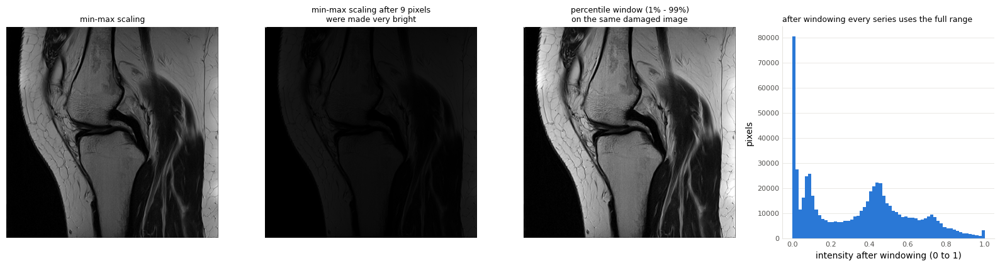

Min-max scaling lets a handful of extreme pixels decide the brightness of the whole image. Percentiles ignore them: the darkest 1% and the brightest 1% are clipped, the rest is stretched to 0..1.
The window is computed once per series, not per slice, so the same tissue keeps the same grey value through the stack.


In [9]:
# ======================= Part D.4 - intensity: MRI numbers have no fixed scale =======================
def AX_show_intensity():
    # the same kind of tissue, three different series of one study: compare their raw value ranges
    series = {plane: AX_load_series(d)[0] for plane, d in AX_DEMO["series"].items()}
    rows = []
    for plane, imgs in series.items():
        v = AX_np.concatenate([i[::4, ::4].ravel() for i in imgs])
        rows.append({"series": plane, "minimum": float(v.min()), "median": float(AX_np.median(v)),
                     "99th percentile": float(AX_np.percentile(v, 99)), "maximum": float(v.max())})
    AX_show(AX_pd.DataFrame(rows).round(0), "Raw intensity statistics of three series of the SAME study")
    img = AX_DEMO["images"][len(AX_DEMO["images"]) // 2]
    ref = AX_np.concatenate([i[::4, ::4].ravel() for i in AX_DEMO["images"]])
    minmax = (img - img.min()) / max(float(img.max() - img.min()), 1e-6)
    spiked = img.copy(); spiked[2:5, 2:5] = img.max() * 6                # nine very bright pixels, as a scanner artefact would give
    spiked_minmax = (spiked - spiked.min()) / float(spiked.max() - spiked.min())
    fig, ax = AX_plt.subplots(1, 4, figsize=(16, 4.2))
    AX_imshow(ax[0], minmax, "min-max scaling")
    AX_imshow(ax[1], spiked_minmax, "min-max scaling after 9 pixels\nwere made very bright", vmin=0, vmax=1)
    AX_imshow(ax[2], AX_window(spiked, 1, 99, ref=ref), "percentile window (1% - 99%)\non the same damaged image", vmin=0, vmax=1)
    ax[3].hist(AX_window(img, 1, 99, ref=ref).ravel(), bins=60, color=AX_C["blue"])
    ax[3].set_xlabel("intensity after windowing (0 to 1)"); ax[3].set_ylabel("pixels")
    ax[3].set_title("after windowing every series uses the full range", fontsize=9, loc="left"); AX_style(ax[3], "y")
    AX_plt.tight_layout(); AX_plt.show()
    print("Min-max scaling lets a handful of extreme pixels decide the brightness of the whole image. "
          "Percentiles ignore them: the darkest 1% and the brightest 1% are clipped, the rest is stretched to 0..1.")
    print("The window is computed once per series, not per slice, so the same tissue keeps the same grey value through the stack.")


with AX_cell("D.4 intensity"):
    AX_show_intensity()

## D.5 Planes, orientation and the left / right problem

**What.** A knee study contains series in three **planes**: sagittal (seen from the side), coronal (seen from the front) and axial (seen from above). The header's orientation vectors say which plane a series is in and which way round the picture is stored.

**The left / right problem.** Two of the twelve findings exist as a medial (inner) and a lateral (outer) version: the menisci and the osteoarthritis compartments. In a coronal image of a right knee the medial side is on one side of the picture, in a left knee on the other. A network that is not told which knee it is looking at can confuse the two.

**Two solutions, both used in this notebook.**
1. *Mirror before the network* (Branch B): decide from the header whether it is a right knee and flip it, so that medial is always on the same side.
2. *Predict twice* (Branch A): show the network the study as stored and as its mirror image, and average the two answers. This is a form of test-time augmentation.

**How the side is found.** In the DICOM patient coordinate system x grows towards the patient's left. A knee whose images are centred at negative x is a right knee.

plane (from the series table),the stack runs along,row direction,column direction,image centre x (mm)
Sagittal,left-right (x),"[0.16, 0.99, 0.07]","[0.02, 0.06, -1.0]",72.800
Coronal,front-back (y),"[0.99, 0.11, 0.02]","[0.02, -0.02, -1.0]",83.700
Axial,head-foot (z),"[0.99, 0.15, 0.05]","[-0.14, 0.99, -0.05]",81.100


x grows towards the patient's left. These images are centred at x = 81 mm, so the knee side is: left.


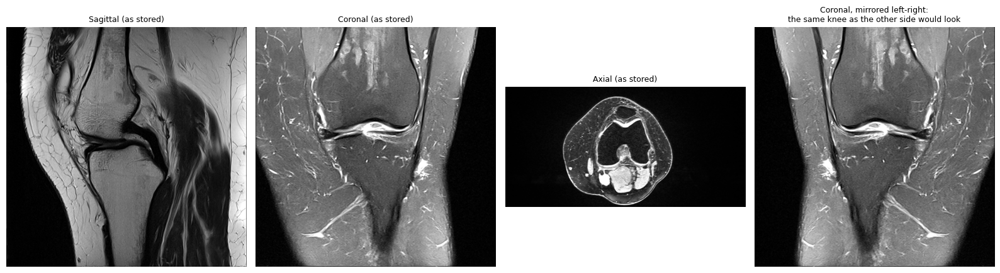

A left knee is the mirror image of a right knee. Two ways to deal with it appear in this notebook:
  1. mirror every right knee before the network sees it (Branch B), so 'medial' is always on the same side;
  2. leave the knees as they are, and at test time predict each study twice, plain and mirrored (Branch A).


In [10]:
# ======================= Part D.5 - planes, orientation and the left/right problem =======================
def AX_show_planes():
    rows, fig_items = [], []
    for plane, d in AX_DEMO["series"].items():
        imgs, heads, _ = AX_load_series(d)
        h = heads[len(heads) // 2]
        iop = AX_np.asarray(h.ImageOrientationPatient, float)
        normal = AX_np.cross(iop[:3], iop[3:])
        axis = "left-right (x)" if abs(normal[0]) == max(abs(normal)) else "front-back (y)" if abs(normal[1]) == max(abs(normal)) else "head-foot (z)"
        cx = float(h.ImagePositionPatient[0]) + iop[0] * float(h.PixelSpacing[1]) * h.Columns / 2 + iop[3] * float(h.PixelSpacing[0]) * h.Rows / 2
        rows.append({"plane (from the series table)": plane, "the stack runs along": axis,
                     "row direction": AX_np.round(iop[:3], 2).tolist(), "column direction": AX_np.round(iop[3:], 2).tolist(),
                     "image centre x (mm)": round(cx, 1)})
        fig_items.append((plane, AX_window(imgs[len(imgs) // 2], ref=AX_np.concatenate([i[::4, ::4].ravel() for i in imgs]))))
    AX_show(AX_pd.DataFrame(rows), "Orientation read from the headers")
    xs = [r["image centre x (mm)"] for r in rows]
    side = "right" if AX_np.median(xs) < -20 else "left" if AX_np.median(xs) > 20 else "undetermined"
    print(f"x grows towards the patient's left. These images are centred at x = {AX_np.median(xs):.0f} mm, so the knee side is: {side}.")
    fig, ax = AX_plt.subplots(1, len(fig_items) + 1, figsize=(4 * (len(fig_items) + 1), 4.2))
    for a, (plane, im) in zip(ax, fig_items):
        AX_imshow(a, im, f"{plane} (as stored)")
    cor = dict(fig_items).get("Coronal", fig_items[0][1])
    AX_imshow(ax[-1], cor[:, ::-1], "Coronal, mirrored left-right:\nthe same knee as the other side would look")
    AX_plt.tight_layout(); AX_plt.show()
    print("A left knee is the mirror image of a right knee. Two ways to deal with it appear in this notebook:\n"
          "  1. mirror every right knee before the network sees it (Branch B), so 'medial' is always on the same side;\n"
          "  2. leave the knees as they are, and at test time predict each study twice, plain and mirrored (Branch A).")


with AX_cell("D.5 planes and orientation"):
    AX_show_planes()

## D.6 2.5-D: three neighbouring slices become one colour image

**What.** The networks used here were first trained on colour photographs, which have three channels (red, green, blue). An MRI slice has one. The trick is to put **three neighbouring slices** into the three channels.

**Why.** A tear or a fluid collection continues over several slices; an artefact usually does not. With three slices the network can see whether a structure persists through the depth. A true 3-D network could do this better, but it would be much slower and could not start from weights pre-trained on photographs. Hence the name 2.5-D.

**What to look at.** The composite image: grey where the three slices agree, coloured fringes where the anatomy changes from slice to slice. The last panel shows the difference between the two outer slices.

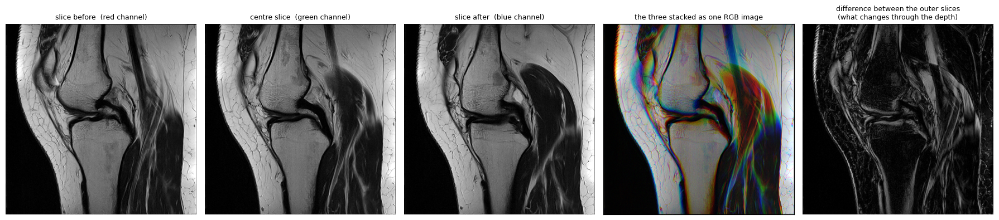

network input for this window: array of shape (3, 800, 800) (channels, height, width)
Where the three slices agree the composite is grey; coloured fringes mark structures that change from one slice to the next.
A network built for colour photographs can use this directly: it gets depth information without any 3-D layers.


In [11]:
# ======================= Part D.6 - 2.5-D: three neighbouring slices become one colour image =======================
def AX_show_25d():
    imgs = AX_DEMO["images"]
    c = len(imgs) // 2
    ref = AX_np.concatenate([i[::4, ::4].ravel() for i in imgs])
    tri = AX_np.stack([AX_window(imgs[c + d], ref=ref) for d in (-1, 0, 1)], axis=-1)       # H x W x 3: slices as R, G, B
    fig, ax = AX_plt.subplots(1, 5, figsize=(18, 4))
    for k, name in enumerate(("slice before  (red channel)", "centre slice  (green channel)", "slice after  (blue channel)")):
        AX_imshow(ax[k], tri[..., k], name, vmin=0, vmax=1)
    ax[3].imshow(tri); ax[3].set_xticks([]); ax[3].set_yticks([]); ax[3].set_title("the three stacked as one RGB image", fontsize=9)
    diff = AX_np.abs(tri[..., 2] - tri[..., 0])
    AX_imshow(ax[4], diff, "difference between the outer slices\n(what changes through the depth)")
    AX_plt.tight_layout(); AX_plt.show()
    print(f"network input for this window: array of shape {tri.transpose(2, 0, 1).shape} (channels, height, width)")
    print("Where the three slices agree the composite is grey; coloured fringes mark structures that change from one slice to the next.\n"
          "A network built for colour photographs can use this directly: it gets depth information without any 3-D layers.")


with AX_cell("D.6 2.5-D stacking"):
    AX_show_25d()

## D.7 Resizing, number formats and normalisation

**Resizing.** Shrinking an image by keeping every n-th pixel throws information away and creates grain (aliasing). Averaging the pixels that fall into each new pixel (`INTER_AREA` in OpenCV) keeps it. The figure shrinks hard on purpose to make the difference visible.

**Number formats.** A study is stored as 8-bit integers (0–255) while it waits in memory, four times smaller than 32-bit floats; with thousands of slices this decides whether the data fits in RAM. It is converted to floating point only on the GPU.

**Normalisation.** The backbones were pre-trained on images from which a fixed mean was subtracted and which were divided by a fixed spread (the ImageNet statistics). They expect the same at inference; the last table row shows the resulting value range.

**This ends the walkthrough.** A study has become a small set of arrays of fixed shape: for stage A1, for example, 96 slices of 384 × 384 8-bit pixels.

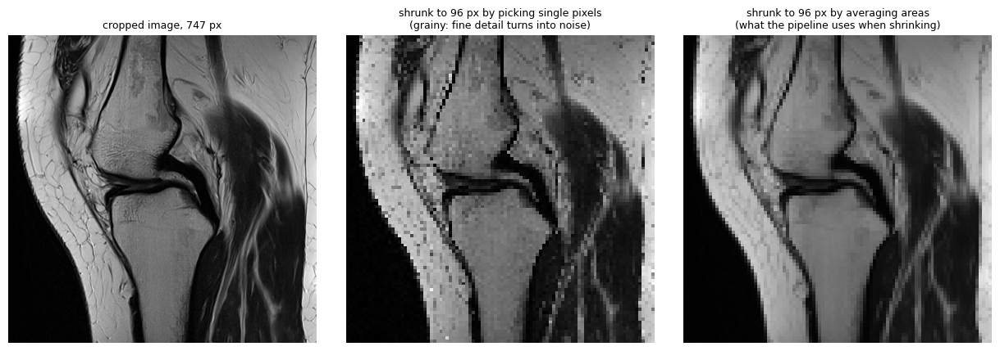

stage,type,value range,bytes per slice
stored in the DICOM file,uint16,0 .. 1849,1280000
"after window + crop + resize, kept in memory",uint8,0 .. 255,147456
converted on the GPU,float32,0.00 .. 1.00,589824
normalised with the ImageNet mean and spread,float32,-2.12 .. 2.25,589824


Slices wait in memory as 8-bit integers (4x smaller than floats) and become floats only on the GPU.
The last step subtracts the mean and divides by the spread the backbone was pre-trained with; a pre-trained network expects inputs on that scale.


In [12]:
# ======================= Part D.7 - resizing, data types and the numbers the network finally sees =======================
def AX_show_resize_and_normalise(crop_mm=140.0):
    img, ds = AX_DEMO["images"][len(AX_DEMO["images"]) // 2], AX_DEMO["headers"][len(AX_DEMO["images"]) // 2]
    win = AX_mm_crop(AX_window(img, ref=AX_np.concatenate([i[::4, ::4].ravel() for i in AX_DEMO["images"]])), float(ds.PixelSpacing[0]), crop_mm)
    small = 96                                                           # shrink hard on purpose, so the effect is visible
    nearest = AX_resize(win, small, "nearest")
    area = AX_resize(win, small, "area")
    fig, ax = AX_plt.subplots(1, 3, figsize=(12.5, 4.2))
    AX_imshow(ax[0], win, f"cropped image, {win.shape[0]} px")
    AX_imshow(ax[1], nearest, f"shrunk to {small} px by picking single pixels\n(grainy: fine detail turns into noise)")
    AX_imshow(ax[2], area, f"shrunk to {small} px by averaging areas\n(what the pipeline uses when shrinking)")
    AX_plt.tight_layout(); AX_plt.show()
    u8 = (AX_np.clip(AX_resize(win, 384), 0, 1) * 255).astype(AX_np.uint8)
    f32 = u8.astype(AX_np.float32) / 255.0
    norm = (f32 - 0.485) / 0.229
    AX_show(AX_pd.DataFrame([
        {"stage": "stored in the DICOM file", "type": str(ds.pixel_array.dtype), "value range": f"{int(ds.pixel_array.min())} .. {int(ds.pixel_array.max())}", "bytes per slice": ds.pixel_array.nbytes},
        {"stage": "after window + crop + resize, kept in memory", "type": "uint8", "value range": f"{u8.min()} .. {u8.max()}", "bytes per slice": u8.nbytes},
        {"stage": "converted on the GPU", "type": "float32", "value range": f"{f32.min():.2f} .. {f32.max():.2f}", "bytes per slice": f32.nbytes},
        {"stage": "normalised with the ImageNet mean and spread", "type": "float32", "value range": f"{norm.min():.2f} .. {norm.max():.2f}", "bytes per slice": norm.nbytes},
    ]), "The same slice on its way into the network")
    print("Slices wait in memory as 8-bit integers (4x smaller than floats) and become floats only on the GPU.\n"
          "The last step subtracts the mean and divides by the spread the backbone was pre-trained with; "
          "a pre-trained network expects inputs on that scale.")


with AX_cell("D.7 resize and normalise"):
    AX_show_resize_and_normalise()

# Part E — The model pipeline

The model code in this part comes from two public pipelines and is unchanged apart from the edits marked `[edit …]`. Cells written for this notebook say so in their heading (**new**).

## Training versus inference

| | Training (done before, by the checkpoint authors) | Inference (this part) |
|---|---|---|
| Input | training studies with labels derived from reports | test studies, no labels |
| What changes | the network's weights, by gradient descent over many passes through the data, with augmentation and dropout | nothing: weights are loaded and frozen (`model.eval()`, `torch.no_grad()`) |
| Output | checkpoint files (`.pt`) | one score per study and finding |
| Folds | the data is split into parts; each model trains on all but one | every model predicts every test study and the answers are averaged |

Three consequences you will see in the code:

- **Preprocessing must match training exactly.** Each model family brings its own DICOM reader (table in Part D), and this notebook does not unify them. Part G shows what a mismatch costs.
- **Integrity checks.** Checkpoints are identified by a SHA-256 hash or a stored fingerprint. A mismatch stops the model instead of silently producing other predictions.
- **Test-time augmentation (TTA) is an inference-only trick.** The same study is predicted several times in slightly different forms and the answers are averaged. It helps only if the variants look like something the network saw in training.

Part F turns to the training side.

## E.1 Environment check

**What.** Prints Python, PyTorch and GPU details and lists the attached inputs. Branch B insists on two T4 GPUs; seeing the hardware first makes a later refusal understandable. **Effect on predictions.** None (read-only).

In [13]:
# Read-only environment and input check. Defines no state used by later cells.
import os
import platform
import sys
from pathlib import Path

import torch

print("python :", sys.version.split()[0], "|", platform.platform())
print("torch  :", torch.__version__, "| CUDA available:", torch.cuda.is_available())
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"  cuda:{i} {p.name}  {p.total_memory / 2**30:.1f} GiB")
if torch.cuda.device_count() < 2:
    print("WARNING: pipeline is tuned for 2x T4; runtime will be longer with fewer GPUs.")

input_root = Path("/kaggle/input")
print("attached inputs:")
for d in sorted(input_root.iterdir()) if input_root.is_dir() else []:
    print("  -", d.name)


python : 3.13.15 | Linux-6.18.48+-x86_64-with-glibc2.39
torch  : 2.11.0+cu128 | CUDA available: True
  cuda:0 Tesla T4  14.6 GiB
  cuda:1 Tesla T4  14.6 GiB
attached inputs:
  - competitions
  - datasets
  - models


## E.2 Run-mode switch (new)

**What.** In submit mode the first cell only prints a line. In validate mode it builds a small folder that looks like the competition test set but contains the 58 officially labelled training studies (as links; no data is copied) and points the pipeline at it.

**Why this design.** Both branches are hard-wired to "the test set". Re-implementing them for validation would create a second code path that could differ from the one that is submitted. Redirecting the input means the validated code *is* the submitted code.

**Is that valid validation data?** Only partly:
- The labels are official, so they are the right yardstick.
- The studies are **not unseen**. They belong to the training data: fold models have each seen four fifths of them, and a checkpoint with `alldata` in its name was by its name trained on all of them. Scores on these studies are optimistic.
- Two versions of *this notebook* evaluated on the same studies are affected in a similar way, so *differences* are more informative than levels. With 58 studies the intervals remain wide.
- The only leakage-free measurement is the leaderboard.

In [14]:
# ======================= Validation mode: point the pipeline at the officially labelled training studies =======================
# This is NOT a teaching cell: in validate mode a failure here must stop the run, so it is not wrapped in AX_cell.
AX_VAL = None
AX_SHADOW_ROOT = AX_Path(os.environ.get("RSNA_VAL_ROOT", "/tmp/rsna_val_root"))   # scratch disk: never saved as notebook output


def AX_prepare_validation_root():
    """Build a small directory that LOOKS like the competition test set but contains the gold-labelled
    training studies (as symlinks - no pixel data is copied). The pipeline then runs on it unchanged."""
    gold, gold_file = AX_find_gold()
    if gold is None:
        raise RuntimeError("validate mode: no official labels found under the competition dir (set GOLD_LABEL_FILE)")
    gold = gold.dropna(how="any")
    series_csv, series_dir = AX_COMP / "train_series.csv", AX_COMP / "train_series"
    if not series_csv.is_file() or not series_dir.is_dir():
        raise RuntimeError("validate mode needs train_series.csv and train_series/ in the competition dir")
    ser = AX_pd.read_csv(series_csv, dtype={AX_UID: str, "SeriesInstanceUID": str})
    need = {AX_UID, "SeriesInstanceUID", "Anatomical_Plane", "Fat_Suppression"}
    if not need.issubset(ser.columns):
        raise RuntimeError(f"train_series.csv lacks columns the pipeline reads: {sorted(need - set(ser.columns))}")
    ids = [u for u in gold.index if (series_dir / u).is_dir() and (ser[AX_UID] == u).any()]
    limit = int(os.environ.get("RSNA_VAL_LIMIT", "0"))
    if limit:
        ids = ids[:limit]
    if len(ids) < 10:
        raise RuntimeError(f"validate mode: only {len(ids)} labelled studies with images were found")
    marker = AX_SHADOW_ROOT / ".rsna_validation_root"
    if AX_SHADOW_ROOT.exists():
        if not marker.is_file():
            raise RuntimeError(f"{AX_SHADOW_ROOT} exists and was not created by this notebook; refusing to replace it")
        shutil.rmtree(AX_SHADOW_ROOT)            # removes symlinks only, never the linked competition data
    (AX_SHADOW_ROOT / "test_series").mkdir(parents=True)
    marker.write_text("created by the validation mode of this notebook\n")
    for u in ids:
        os.symlink(series_dir / u, AX_SHADOW_ROOT / "test_series" / u, target_is_directory=True)
    AX_pd.DataFrame({AX_UID: ids}).to_csv(AX_SHADOW_ROOT / "test.csv", index=False)
    ser[ser[AX_UID].isin(set(ids))].to_csv(AX_SHADOW_ROOT / "test_series.csv", index=False)
    sample = AX_pd.DataFrame(0.5, index=range(len(ids)), columns=AX_LAB); sample.insert(0, AX_UID, ids)
    sample.to_csv(AX_SHADOW_ROOT / "sample_submission.csv", index=False)
    os.symlink(AX_COMP / "train.csv", AX_SHADOW_ROOT / "train.csv")
    return {"root": AX_SHADOW_ROOT, "ids": ids, "gold": gold.loc[ids, AX_LAB].astype(float), "gold_file": gold_file.name}


if AX_RUN_MODE == "validate":
    AX_VAL = AX_prepare_validation_root()
    os.environ["RSNA_COMP_ROOT"] = str(AX_VAL["root"])      # the pipeline's own root finder honours this variable
    print("=" * 100)
    print(f"VALIDATE MODE: the pipeline below will predict {len(AX_VAL['ids'])} officially labelled TRAINING studies "
          f"(labels from {AX_VAL['gold_file']}).")
    print("No submission.csv will be published from this run. Switch RUN_MODE back to 'submit' before submitting.")
    print("=" * 100)
else:
    if os.environ.get("RSNA_COMP_ROOT", "") == str(AX_SHADOW_ROOT):
        os.environ.pop("RSNA_COMP_ROOT")     # a validate run earlier in this session must not leak into a submit run
    print("SUBMIT MODE: the pipeline below predicts the competition test set.")

SUBMIT MODE: the pipeline below predicts the competition test set.


### E.3 File names and a clean working folder (new)

Fixes the file names the branches use to hand over their results and deletes prediction files left over from an earlier run in the same session, so that an old file can never pose as this run's result.

In [15]:
# ---- Before the models: file names, a clean working folder, and PyTorch's global speed switches ----
import gc as AX_gc
import torch as AX_torch

AX_DEV = "cuda" if AX_torch.cuda.is_available() else "cpu"       # used by the teaching cells only
AX_TORCH_FLAGS = {"cudnn_benchmark": AX_torch.backends.cudnn.benchmark,
                  "matmul_tf32": AX_torch.backends.cuda.matmul.allow_tf32}
AX_A_FILES = {"coatnet": AX_OUT / "_sota_0949.csv",            # stage A1 ranks (file name chosen by the public notebook)
              "coatnet_raw": AX_OUT / "_coatnet_raw.npz",       # stage A1 raw probabilities (added for diagnostics)
              "convnext": AX_OUT / "_own.csv",                  # stage A2 probabilities
              "fusion_v1": AX_OUT / "_apex_0950_verified.csv",  # stage A3 with the first weight table
              "final": AX_OUT / "_branch_a_final.csv"}          # what Branch A hands to the final blend
AX_B_FILE = AX_OUT / "_branch_b_final.csv"                     # what Branch B hands to the final blend
AX_S_FILE = AX_OUT / "_branch_s_final.csv"                     # what Branch S (our own model) hands to the final blend
AX_BRANCH_S = {"status": "not run", "detail": AX_BRANCH_S_OFF_REASON}
for _ax_f in list(AX_A_FILES.values()) + [AX_B_FILE, AX_S_FILE] + [AX_OUT / n for n in (
        "submission.csv", "validation_predictions.csv", "_pipeline_stage.csv", "final_blend_receipt.json",
        "_coat_raptor_blend_receipt.json", "_raptor.csv", "_coat_family_rank.csv", "raptor_raw.npz")]:
    _ax_f.unlink(missing_ok=True)                               # files of an earlier run must never pose as this run's results
shutil.rmtree(AX_STAGE_DIR, ignore_errors=True)
(AX_OUT / "own_model").mkdir(parents=True, exist_ok=True)       # our own model code is written here in Branch S
del _ax_f


def AX_free_gpu():
    """Return cached GPU memory to the driver (teaching cells call this when they are done)."""
    AX_gc.collect()
    if AX_torch.cuda.is_available():
        for d in range(AX_torch.cuda.device_count()):
            with AX_torch.cuda.device(d):
                AX_torch.cuda.empty_cache()


print(f"device for the teaching cells: {AX_DEV}"
      + (f" ({AX_torch.cuda.device_count()} x {AX_torch.cuda.get_device_name(0)})" if AX_DEV == "cuda" else ""))
print("PyTorch switches before the models run:", AX_TORCH_FLAGS)
print("working folder cleaned: no prediction file of an earlier run is left")

device for the teaching cells: cuda (2 x Tesla T4)
PyTorch switches before the models run: {'cudnn_benchmark': False, 'matmul_tf32': False}
working folder cleaned: no prediction file of an earlier run is left


# Branch B — the first notebook's pipeline

**What.** The staged ensemble of the first notebook, in its original order: DINOv2 ×20 → A5 ×5 → Raptor CoAtNet ×4 views → four more CoAtNet readers, each stage blended into a running file `_pipeline_stage.csv`. The cells are byte-identical to that notebook apart from one marked edit (`[edit B1]`: the folders of the two dropped notebook outputs are no longer searched), and each starts with `%%branch_b`.

**What is missing.** Stage B3 (RadImageNet heads with a calibrator). It needs a head file that exists only as the output of two other notebooks; those inputs are no longer used. The stages after it now blend against the DINOv2 + A5 result directly.

**Its role here.** With the default weight 0 this branch is a complete worked example: it runs on the studies you can see, every stage shows what it received and produced, and it is skipped while Kaggle scores. With `FIRST_PIPELINE_WEIGHT > 0` it also runs while scoring and enters the final blend. With RadImageNet this ensemble scored 0.943; without it, it has no score of its own.

**If something goes wrong.** An error or a time-out in any cell of this branch is shown and recorded, the remaining Branch B cells are skipped, and the notebook carries on with Branch A.

*Inside this branch the texts speak of stages 1, 2, 4 and 5. They are B1, B2, B4 and B5 in the overview table.*

## B · setup — library settings (new)

Four environment settings the first notebook applied before its model cells: thread counts for the numerical libraries and a cap on cuDNN's convolution workspace.

In [16]:
%%branch_b setup: library settings
# Library thread counts and the cuDNN workspace cap that Branch B's models were validated with.
# (Same four settings the previous notebook applied before its first model cell.)
import os

for _thread_env in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(_thread_env, '4')
os.environ.setdefault('CUDNN_CONV_WSCAP_DBG', '1024')
print({k: os.environ[k] for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'CUDNN_CONV_WSCAP_DBG')})

{'OMP_NUM_THREADS': '4', 'OPENBLAS_NUM_THREADS': '4', 'MKL_NUM_THREADS': '4', 'CUDNN_CONV_WSCAP_DBG': '1024'}
[setup: library settings] ran in 0.0 s


## B · setup — Runtime contract and checkpoint integrity

**What.** Helper functions that (a) verify hashes of the CoAtNet "D4" reader's files, batch sizes and library versions, (b) locate every attached weight file by name and hash, (c) run a required model in a child process with a time limit, and (d) patch the dense slice sampling into two external reader scripts.

**Why.** The pipeline combines files from more than a dozen datasets. If one of them were replaced by a different version, the notebook would still run and the predictions would silently change. Pinning hashes turns that into an immediate, readable error.

**How.** `_asset_find_asset(name, sha256)` walks only the listed dataset folders and demands exactly one match. `_d4_check_runtime` / `_d4_check_outputs` compare a long list of expected properties (model count, epochs, resolution, exact numeric round-trip of the written CSV).

**Effect on predictions.** None when everything matches; a hard stop otherwise.

In [17]:
%%branch_b setup: runtime contract
import os

for _thread_env in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(_thread_env, '4')
os.environ.setdefault('CUDNN_CONV_WSCAP_DBG', '1024')


def _d4_check_runtime(rt, artifact_root):
    import hashlib
    import json
    from pathlib import Path
    import torch

    root = Path(artifact_root)
    manifest_path = root / 'coatnet_pairfilm_manifest.json'
    digest = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
    if digest != '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d':
        raise RuntimeError('D4 reference manifest identity changed')
    expected = json.loads(manifest_path.read_text())
    manifest, paths = rt.validate_artifact_root(root, verify_hashes=True)
    if manifest != expected or len(paths) != 1 or rt.N_MODELS != 1:
        raise RuntimeError('D4 must load exactly the reference SWA model')
    if Path(paths[0]).name != 'coatnet_d4_parent_rank8_swa2.pt':
        raise RuntimeError('D4 must use its reference rank-8 parent checkpoint')
    if (
        manifest['slice_depth']['adapter_sha256']
        != 'b7c48b19997bc7ecb7e997f8dcf491ec5701ff917d1dac4b369eb85ac97ae89a'
    ):
        raise RuntimeError('D4 reference adapter identity changed')
    if rt.GPU_BATCH_STUDIES != 2 or rt.BACKBONE_MICRO_IMAGES != 8:
        raise RuntimeError('D4 reference batching changed')
    if rt.CUDNN_BENCHMARK is not False:
        raise RuntimeError('D4 reference convolution policy changed')
    if rt.base.cv2.__version__ != '4.12.0' or rt.parent.timm.__version__ != '1.0.22':
        raise RuntimeError('D4 reference dependency versions changed')
    if torch.cuda.device_count() != 2:
        raise RuntimeError('D4 requires exactly two T4 GPUs')
    names = [torch.cuda.get_device_name(i) for i in range(2)]
    if not all(('T4' in name for name in names)):
        raise RuntimeError(f'D4 reference device mismatch: {names}')
    return (manifest, paths)


def _d4_check_outputs(rt, manifest, receipt, output, competition):
    import hashlib
    from pathlib import Path
    import numpy as np
    import pandas as pd

    def need(condition, message):
        if not condition:
            raise RuntimeError('D4 release check: ' + message)

    need(receipt['status'] == rt.SUBMISSION_STATUS, 'unsuccessful status')
    expected_fields = {
        'models': 1,
        'fallback_studies': 0,
        'dicom_preparations_per_study': 1,
        'model_passes_per_study': 1,
        'rank_after_probability_average': True,
        'canonical_sagittal': True,
        'common_physical_triplet_warp': False,
        'resolution': 384,
        'slice_depth_arm': 'd4_zones',
        'slice_depth_state_elements': 3255,
        'slice_depth_parent_checkpoint_sha256': '5de38e333e3184d7b52fb068183f0cc198d6cbabb6ffbe36b26338622e82d297',
        'fsx_attention_heads': 2,
        'fsx_attention_width': 128,
        'fsx_serving_delta_cap': 0.3,
        'fsx_training_delta_cap': 0.5,
        'head': 'rank8_swa2_plus_d4_three_zone_expanded_fsx',
        'slice_depth_swa_member_epochs': [11, 9, 5],
        'slice_depth_checkpoint_sha256': manifest['slice_depth']['adapter_sha256'],
    }
    for key, value in expected_fields.items():
        need(receipt[key] == value, key)
    need(1 <= int(receipt['maximum_eval_windows']) <= 94, 'window limit')
    checkpoints = receipt['checkpoints']
    need(len(checkpoints) == 1, 'parent checkpoint count')
    need(
        checkpoints[0]['sha256']
        == '5de38e333e3184d7b52fb068183f0cc198d6cbabb6ffbe36b26338622e82d297',
        'parent checkpoint hash',
    )
    need(checkpoints[0]['member_epochs'] == [15, 16], 'parent SWA member epochs')
    need(
        receipt['slice_depth_checkpoint_sha256']
        == 'b7c48b19997bc7ecb7e997f8dcf491ec5701ff917d1dac4b369eb85ac97ae89a',
        'adapter checkpoint hash',
    )
    processes = receipt['processes']
    need(
        len(processes) == 2 and all((int(p['returncode']) == 0 for p in processes)),
        'worker process failure',
    )
    shards = receipt['shards']
    need(len(shards) == 2, 'shard count')
    for s in shards:
        need(s['device'] == 'cuda', 'non-CUDA shard')
        need(
            int(s['fallback_studies']) == 0 and int(s['preparation_warnings']) == 0,
            'failed study/preparation',
        )
        need(int(s['models_resident']) == 1, 'resident model count')
        need(int(s['peak_reserved_bytes']) < int(15.5 * 1024**3), 'reference memory gate')
        need(
            s['specialized_worker_loader_contract'] == manifest['worker_loader_contract'],
            'specialized loader',
        )
    output = Path(output)
    prediction_path = output.parent / rt.PREDICTIONS_NAME
    with np.load(prediction_path, allow_pickle=False) as payload:
        uids = payload['study_uids'].astype(str).tolist()
        raw = np.asarray(payload['raw_probabilities'], dtype=np.float32)
        mean = np.asarray(payload['probability_mean'], dtype=np.float32)
        ranked = np.asarray(payload['submission_percentile_rank'], dtype=np.float64)
    ids = pd.read_csv(
        Path(competition) / 'test.csv', dtype={'StudyInstanceUID': str}
    ).StudyInstanceUID.tolist()
    need(len(ids) > 0 and len(ids) == len(set(ids)), 'test identity')
    need(uids == ids and int(receipt['studies']) == len(ids), 'prediction identity/count')
    need(raw.shape == (1, len(ids), 12), 'raw probability shape')
    need(np.isfinite(raw).all() and ((raw >= 0) & (raw <= 1)).all(), 'raw probabilities')
    need(
        np.array_equal(raw.astype(np.float64).mean(0).astype(np.float32), mean), 'probability mean'
    )
    need(np.array_equal(rt.percentile_rank64(mean), ranked), 'global percentile ranks')
    frame = pd.read_csv(output, dtype={'StudyInstanceUID': str}, float_precision='round_trip')
    need(frame.columns.tolist() == ['StudyInstanceUID', *rt.base.LABELS], 'CSV labels')
    need(frame.StudyInstanceUID.tolist() == ids, 'CSV identity')
    need(np.array_equal(frame.iloc[:, 1:].to_numpy(np.float64), ranked), 'CSV numeric round trip')
    actual_hash = hashlib.sha256(output.read_bytes()).hexdigest()
    need(actual_hash == receipt['output_sha256'], 'CSV hash')
    receipt['reference_wrapper_checks'] = {
        'export_sha256': '7f8410fdf1b60cd3831d50f517bb25798a4e4a3404c59dc269193d5fe7cce729',
        'validated_manifest_sha256': '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d',
        'probability_mean_exact': True,
        'ranks_exact': True,
        'csv_roundtrip_exact': True,
        'source_and_model_hashes_validated': True,
        'input_identity_equals_original_grid': False,
    }
    return receipt


def _run_required_child(command, environment, logfile):
    import os
    import signal
    import subprocess
    import time
    from pathlib import Path

    remaining = TIME_BUDGET - (time.time() - T0)
    if remaining <= 0:
        raise TimeoutError('No time remains for a required model branch')
    path = Path(logfile)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('w') as log_handle:
        process = subprocess.Popen(
            command,
            env=environment,
            stdout=log_handle,
            stderr=subprocess.STDOUT,
            start_new_session=True,
        )
        try:
            returncode = process.wait(timeout=remaining)
        except BaseException:
            try:
                os.killpg(process.pid, signal.SIGTERM)
            except ProcessLookupError:
                pass
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                try:
                    os.killpg(process.pid, signal.SIGKILL)
                except ProcessLookupError:
                    pass
                process.wait()
            raise
    if returncode != 0:
        with path.open('rb') as handle:
            handle.seek(max(0, path.stat().st_size - 5000))
            tail = handle.read().decode('utf-8', errors='replace')
        raise RuntimeError(f'Required model branch failed ({returncode}); {path}\n{tail}')
    return returncode


ASSET_ROOTS = [
    '/kaggle/input/datasets/dreaddevelopment/raptor-knee-maxspan',
    '/kaggle/input/raptor-knee-maxspan',
    '/kaggle/input/datasets/dreaddevelopment/raptor-knee-native384',
    '/kaggle/input/raptor-knee-native384',
    '/kaggle/input/datasets/dreaddevelopment/raptor-knee-native384dense',
    '/kaggle/input/raptor-knee-native384dense',
    '/kaggle/input/datasets/mattiaangeli/knee-mri-fold-weights',
    '/kaggle/input/knee-mri-fold-weights',
    '/kaggle/input/datasets/mattiaangeli/opencv-python-headless-4120088-x86',
    '/kaggle/input/opencv-python-headless-4120088-x86',
    '/kaggle/input/datasets/marwanmath/resnet-50-radimagenet-marwan',
    '/kaggle/input/resnet-50-radimagenet-marwan',
    '/kaggle/input/datasets/mattiaangeli/rsna-knee-coat-resgated-ep10-top3',
    '/kaggle/input/rsna-knee-coat-resgated-ep10-top3',
    '/kaggle/input/datasets/antoinegg1/rsna-knee-e11-diverse-heads-v20',
    '/kaggle/input/rsna-knee-e11-diverse-heads-v20',
    '/kaggle/input/datasets/antoinegg1/rsna-knee-e9-radimagenet-heads-v15',
    '/kaggle/input/rsna-knee-e9-radimagenet-heads-v15',
    '/kaggle/input/datasets/pilkwang/rsna-knee-llm-labels',
    '/kaggle/input/rsna-knee-llm-labels',
    '/kaggle/input/datasets/prvsiyan/rsna-knee-v52-radimagenet-heads-20260812',
    '/kaggle/input/rsna-knee-v52-radimagenet-heads-20260812',
    '/kaggle/input/datasets/pilkwang/rsna-knee-weights',
    '/kaggle/input/rsna-knee-weights',
    '/kaggle/input/datasets/mattiaangeli/rsna-knee-coatnet-d4-depthzone-swa3-b2',
    '/kaggle/input/rsna-knee-coatnet-d4-depthzone-swa3-b2',
    '/kaggle/input/datasets/mattiaangeli/rsna-knee-coatnet-global96-top3',
    '/kaggle/input/rsna-knee-coatnet-global96-top3',
    # [edit B1] the two notebook-output folders (e11-train, e13-train) are no longer searched
    '/kaggle/input/models/metaresearch/dinov2/pytorch/small/1',
    '/kaggle/input/dinov2/pytorch/small/1',
]


def _asset_walk():
    from pathlib import Path

    seen = set()
    for root in ASSET_ROOTS:
        root = Path(root).resolve()
        if not root.is_dir():
            continue
        level = [root]
        for _depth in range(6):
            following = []
            for directory in sorted(level):
                if str(directory) in seen:
                    continue
                seen.add(str(directory))
                children = sorted(directory.iterdir())
                dirs = [
                    p
                    for p in children
                    if p.is_dir()
                    and p.name not in ('train_series', 'test_series', 'train_images', 'test_images')
                ]
                files = [p.name for p in children if p.is_file()]
                yield (str(directory), [p.name for p in dirs], files)
                following.extend(dirs)
            level = following


def _asset_find_asset(name, digest=None):
    import fnmatch, hashlib
    from pathlib import Path

    hits = []
    for root, _, files in _asset_walk():
        for file in files:
            if fnmatch.fnmatchcase(file, name):
                p = Path(root) / file
                if digest:
                    h = hashlib.sha256()
                    with p.open('rb') as handle:
                        for block in iter(lambda: handle.read(8 << 20), b''):
                            h.update(block)
                    if h.hexdigest() != digest:
                        continue
                if p.resolve() not in [h.resolve() for h in hits]:
                    hits.append(p)
    if len(hits) != 1:
        raise RuntimeError(f'expected one pinned asset {name}, got {hits}')
    return hits[0]


def _asset_half_rank_mix(*members):
    if len(members) < 2:
        raise ValueError('CoAt family rank mix needs at least two members')
    first = members[0]
    for other in members[1:]:
        if other.shape != first.shape or not other.index.equals(first.index):
            raise ValueError('CoAt family alignment changed')
    for member in members:
        if member.isna().any().any():
            raise ValueError('missing CoAt family prediction')
    units = members[0].rank(method='average')
    for other in members[1:]:
        units = units + other.rank(method='average')
    return units / (float(len(members)) * len(units))


def _asset_write_coat_runtime(artifact, output, helper_source):
    from pathlib import Path
    import hashlib

    source = Path(artifact) / 'coatnet_resgated_ep10_top3_inference.py'
    text = source.read_text()
    if (
        hashlib.sha256(source.read_bytes()).hexdigest()
        != 'b11e58f8d7cabe9e264ac70b01e811dc6a846aa01248ace1f0e6536d0d4094d9'
    ):
        raise RuntimeError('unexpected parent CoAt runtime')
    edits = {
        'if not 1 <= windows <= MAX_EVAL_WINDOWS:': 'if not 1 <= windows <= 94:',
        'or int(counts.max()) > MAX_EVAL_WINDOWS:': 'or int(counts.max()) > 94:',
        '"runtime_contract": RUNTIME_CONTRACT,': '"runtime_contract": RUNTIME_CONTRACT, "input_max_windows": 94,',
        '"eval_grid": "saved_training_gold_unique_center_slot_budgets",': '"eval_grid": "input_unique_native_centers_six_slot_v1",',
    }
    for old, new in edits.items():
        if old not in text:
            raise RuntimeError('CoAt patch target missing: ' + old)
        text = text.replace(old, new)
    text = text.replace(
        '"gold58_rank_ensemble_auc": manifest["selection"]',
        '"historical_parent_gold58_rank_ensemble_auc": manifest["selection"]',
    )
    text = text.replace(
        '"t4_gold58_rank_ensemble_auc": manifest["t4_numerical_portability"]',
        '"historical_parent_t4_gold58_rank_ensemble_auc": manifest["t4_numerical_portability"]',
    )
    marker = 'if __name__ == "__main__":'
    if text.count(marker) != 1:
        raise RuntimeError('CoAt entrypoint changed')
    patch = helper_source + (
        '\n_original_train_faithful_eval_specs = train_faithful_eval_specs\n'
        'def _tolerant_coat_specs(study):\n    try:\n        return _dense_coat_specs(study)\n'
        '    except Exception as exc:\n        print("[dense-fallback] " + str(getattr(study, "study_uid", "?")) + ": " + type(exc).__name__ + ": " + str(exc), flush=True)\n'
        '        return _original_train_faithful_eval_specs(study)\n'
        'train_faithful_eval_specs = _tolerant_coat_specs\nRUNTIME_CONTRACT = "resgated_ep10_input_nativecenters_v1"\n'
    )
    text = text.replace(marker, patch + '\n' + marker)
    compile(text, str(output), 'exec')
    Path(output).write_text(text)
    return hashlib.sha256(text.encode()).hexdigest()


def _asset_patch_d4(rt, grid_source):
    import ast
    import hashlib
    import inspect
    import json
    import os
    import textwrap
    from pathlib import Path

    audited = rt.parent.audited
    original = audited.prepare_global96_bag
    original_shard = rt._PARENT_INFER_SHARD
    if getattr(original, '_input_patch_installed', False):
        raise RuntimeError('D4 input preparation was already patched')
    src = textwrap.dedent(inspect.getsource(original))
    tree = ast.parse(src)
    fn = next((n for n in tree.body if isinstance(n, ast.FunctionDef)), None)
    if fn is None or fn.name != 'prepare_global96_bag':
        raise RuntimeError('D4 preparation function identity changed')
    if 'study_uid' not in inspect.signature(original).parameters:
        raise RuntimeError('D4 preparation study-UID contract changed')
    candidates = [
        n
        for n in ast.walk(fn)
        if isinstance(n, ast.Assign)
        and any((isinstance(t, ast.Name) and t.id == 'specs' for t in n.targets))
        and isinstance(n.value, ast.Call)
        and isinstance(n.value.func, ast.Attribute)
        and isinstance(n.value.func.value, ast.Name)
        and (n.value.func.value.id == 'global_stack')
        and (n.value.func.attr == 'sample_global_windows')
    ]
    if len(candidates) != 1 or candidates[0] not in fn.body:
        raise RuntimeError('D4 expected one top-level Global96 specs constructor')
    call = candidates[0]
    keywords = {k.arg: k.value for k in call.value.keywords}
    if not (
        isinstance(keywords.get('count'), ast.Constant)
        and keywords['count'].value is None
        and isinstance(keywords.get('train'), ast.Constant)
        and (keywords['train'].value is False)
    ):
        raise RuntimeError('D4 original evaluation must use count=None, train=False')
    exec(compile(grid_source, '<input-grid>', 'exec'), audited.__dict__)
    audit_dir = Path(os.environ['RSNA_D4_INPUT_AUDIT_DIR'])
    audit_dir.mkdir(parents=True, exist_ok=True)

    def record_input(study_uid, stack, audit):
        import numpy as np

        arrays = (
            'global_indices',
            'nominal_slots',
            'canonical_depths',
            'nominal_steps',
            'source_series_rows',
            'source_slot_ids',
        )
        digest = hashlib.sha256()
        for name in arrays:
            value = np.ascontiguousarray(getattr(stack, name))
            digest.update(name.encode())
            digest.update(str(value.dtype).encode())
            digest.update(str(value.shape).encode())
            digest.update(value.tobytes())
        record = {
            'study_uid': str(study_uid),
            'pid': os.getpid(),
            'positions': int(len(stack.global_indices)),
            'windows_expected': int(len(stack.global_indices) - 2),
            'slot_widths': list(map(int, stack.slot_widths)),
            'stack_sidecars_sha256': digest.hexdigest(),
            'slots': audit,
        }
        with (audit_dir / f'input_{os.getpid()}.jsonl').open('a') as handle:
            handle.write(json.dumps(record, sort_keys=True, allow_nan=False) + '\n')

    audited.__dict__['_record_input'] = record_input
    injection = ast.parse(
        'try:\n    stack, input_audit = _dense_stack(stack, study.offsets, study.valid, study.source_depth)\n'
        'except Exception as _dense_exc:\n    print("[dense-fallback] " + str(study_uid) + ": " + type(_dense_exc).__name__ + ": " + str(_dense_exc), flush=True)\n'
        '    input_audit = [{"fallback": type(_dense_exc).__name__ + ": " + str(_dense_exc)}]\n'
        '_record_input(study_uid, stack, input_audit)\n'
    ).body
    where = fn.body.index(call)
    fn.body[where:where] = injection
    ast.fix_missing_locations(tree)
    exec(compile(tree, '<D4-input-preparation-only>', 'exec'), audited.__dict__)
    patched = audited.prepare_global96_bag
    patched._input_patch_installed = True
    for module in (rt, rt.parent):
        if getattr(module, 'prepare_global96_bag', None) is original:
            module.prepare_global96_bag = patched
    if rt._PARENT_INFER_SHARD is not original_shard:
        raise RuntimeError('D4 parent shard must remain the official callable')
    files = {}
    for name, module in [
        ('d4_runtime', rt),
        ('parent_runtime', rt.parent),
        ('audited_runtime', audited),
    ]:
        path = Path(module.__file__)
        if path.is_file():
            files[name] = {
                'file': path.name,
                'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
            }
    receipt = {
        'contract': 'd4-original-runtime-input-preparation-only-v2',
        'reference_script_version_id': 348764100,
        'reference_export_available': True,
        'original_prepare_source_sha256': hashlib.sha256(src.encode()).hexdigest(),
        'patched_prepare_source_sha256': hashlib.sha256(ast.unparse(tree).encode()).hexdigest(),
        'model_loader_modified': False,
        'zone_head_modified': False,
        'parent_infer_shard_replaced': False,
        'grid_source_sha256': hashlib.sha256(grid_source.encode()).hexdigest(),
        'artifact_source_files': files,
    }
    (audit_dir / f'patch_{os.getpid()}.json').write_text(json.dumps(receipt, indent=2))
    return receipt


def _asset_run_d4(artifact, environment_dir, competition, output):
    import hashlib, inspect, json, os, sys
    from pathlib import Path
    import pandas as pd

    artifact, output = (Path(artifact), Path(output))
    manifest = artifact / 'coatnet_pairfilm_manifest.json'
    if (
        hashlib.sha256(manifest.read_bytes()).hexdigest()
        != '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d'
    ):
        raise RuntimeError('D4 SWA3 manifest changed')
    grid = (
        'import numpy as np\nfrom raptor_global_stack_smart336 import FixedGlobalStack, INFERRED96_WIDTHS\n'
        + '\n'.join((inspect.getsource(f) for f in (_dense_quotas, _dense_stack)))
    )
    audit_dir = output.parent / 'study_input_receipts'
    audit_dir.mkdir(parents=True, exist_ok=True)
    for stale in audit_dir.glob('*.json*'):
        stale.unlink()
    output.unlink(missing_ok=True)
    output.with_suffix('.receipt.json').unlink(missing_ok=True)
    wrapper = output.parent / 'd4_worker_entry.py'
    code = (
        f'import sys\nsys.path.insert(0,{str(environment_dir)!r})\nsys.path.insert(0,{str(artifact)!r})\nfrom pathlib import Path\nimport json\nimport coatnet_d4_depthzone_swa_inference as rt\n'
        + inspect.getsource(_asset_patch_d4)
        + '\n'
        + inspect.getsource(_d4_check_runtime)
        + '\n'
        + inspect.getsource(_d4_check_outputs)
        + '\n'
        + f"if __name__ == '__main__' and '--worker-output' not in sys.argv:\n    _checked_manifest, _checked_paths = _d4_check_runtime(rt, Path({str(artifact)!r}))\n"
        + f'_asset_patch_d4(rt,{grid!r})\n'
        + 'rt.parent.audited.__file__ = __file__\n'
        + "if __name__ == '__main__':\n"
        + "    if '--worker-output' in sys.argv:\n        raise SystemExit(rt.main())\n"
        + '    manifest, paths = _checked_manifest, _checked_paths\n'
        + '    r = rt.run_submission(\n'
        + f'        competition_root=Path({str(competition)!r}), artifact_root=Path({str(artifact)!r}),\n'
        + f'        output_path=Path({str(output)!r}), gpu_batch_studies=2, backbone_micro_images=8)\n'
        + f'    r = _d4_check_outputs(rt, manifest, r, Path({str(output)!r}), Path({str(competition)!r}))\n'
        + f"    Path({str(output.with_suffix('.receipt.json'))!r}).write_text(json.dumps(r,indent=2,allow_nan=False))\n"
    )
    compile(code, str(wrapper), 'exec')
    wrapper.write_text(code)
    env = dict(os.environ)
    env['RSNA_D4_INPUT_AUDIT_DIR'] = str(audit_dir)
    env['PYTHONPATH'] = f'{environment_dir}:/kaggle/working/_coat_env:{artifact}:' + env.get(
        'PYTHONPATH', ''
    )
    env.pop('CUDNN_CONV_WSCAP_DBG', None)
    _run_required_child([sys.executable, str(wrapper)], env, output.with_suffix('.log'))
    receipt = json.loads(output.with_suffix('.receipt.json').read_text())
    expected = pd.read_csv(
        Path(competition) / 'test.csv', dtype={'StudyInstanceUID': str}
    ).StudyInstanceUID.tolist()
    records = []
    for path in sorted(audit_dir.glob('input_*.jsonl')):
        records.extend((json.loads(line) for line in path.read_text().splitlines() if line.strip()))
    ids = [r['study_uid'] for r in records]
    if len(ids) != len(expected) or len(ids) != len(set(ids)) or set(ids) != set(expected):
        raise RuntimeError('D4 input hook must execute exactly once for every test study')
    if not all(
        (
            1 <= r['windows_expected'] <= 94 and r['positions'] == r['windows_expected'] + 2
            for r in records
        )
    ):
        raise RuntimeError('D4 input record cardinality drift')
    receipt['input_coverage'] = {
        'studies': len(records),
        'folder': str(audit_dir),
        'min_windows': min((r['windows_expected'] for r in records)),
        'max_windows': max((r['windows_expected'] for r in records)),
        'original_model_loader_retained': True,
        'original_shard_scheduler_retained': True,
    }
    output.with_suffix('.receipt.json').write_text(json.dumps(receipt, indent=2, allow_nan=False))
    return receipt


_speed_original_asset_walk = _asset_walk
_speed_original_find_asset = _asset_find_asset
'Catalogue named immutable attachments once; no competition-tree search.'
import threading as _speed_threading

_speed_asset_lock = _speed_threading.RLock()
_speed_asset_catalogue = None
_speed_asset_hits = {}


def _asset_walk():
    global _speed_asset_catalogue
    with _speed_asset_lock:
        if _speed_asset_catalogue is None:
            _speed_asset_catalogue = tuple(
                (
                    (root, tuple(dirs), tuple(files))
                    for root, dirs, files in _speed_original_asset_walk()
                )
            )
        catalogue = _speed_asset_catalogue
    for root, dirs, files in catalogue:
        yield (root, list(dirs), list(files))


def _asset_find_asset(name, digest=None):
    key = (str(name), digest)
    with _speed_asset_lock:
        if key not in _speed_asset_hits:
            _speed_asset_hits[key] = _speed_original_find_asset(name, digest)
        return _speed_asset_hits[key]


[setup: runtime contract] ran in 0.0 s | defined functions: _asset_find_asset, _asset_half_rank_mix, _asset_patch_d4, _asset_run_d4, _asset_walk, _asset_write_coat_runtime, _d4_check_outputs (+4 more) | settings: ASSET_ROOTS


## B · setup — Slice sampling for the dense CoAtNet inputs

**What.** Functions that decide *which slices* of each series the Raptor and CoAtNet readers see.

**Why.** A series can have anywhere from about 10 to several hundred slices, and the readers accept at most 96. Taking a fixed number per series would duplicate slices in short series and skip large parts of long ones.

**How.** `_dense_allocate` distributes a budget across the slots in fixed proportions (for example 18 : 14 : 12 : 8 : 12), capped by how many slices each series really has; budget a short series cannot use is handed to the others. `_dense_unique_linspace` then picks evenly spaced, never repeated positions. `_dense_stack` does the same for the "Global96" layout and writes an audit record per study.

**Effect on predictions.** Decides the image evidence stages 4–5 receive. The code refuses duplicated or out-of-range slices instead of padding.

In [18]:
%%branch_b setup: slice sampling
import numpy as np


def _dense_allocate(capacities, proportions, target):
    capacities = np.asarray(capacities, dtype=np.int64)
    proportions = np.asarray(proportions, dtype=np.float64)
    if (
        capacities.ndim != 1
        or capacities.shape != proportions.shape
        or np.any(capacities < 0)
        or (not np.isfinite(proportions).all())
        or np.any(proportions <= 0)
        or (int(target) < 1)
    ):
        raise ValueError('invalid capacity-aware sampling allocation')
    ideal = int(target) * proportions / proportions.sum()
    initial = np.floor(ideal).astype(np.int64)
    for i in np.argsort(-(ideal - initial), kind='stable')[: int(target) - int(initial.sum())]:
        initial[i] += 1
    quotas = np.minimum(initial, capacities)
    wanted = min(int(target), int(capacities.sum()))
    deficit = np.zeros(len(quotas), dtype=np.float64)
    while int(quotas.sum()) < wanted:
        donors = quotas < capacities
        weights = np.where(donors, proportions, 0.0)
        deficit[donors] += weights[donors] / weights.sum()
        chosen = int(np.argmax(np.where(donors, deficit, -np.inf)))
        quotas[chosen] += 1
        deficit[chosen] -= 1
    assert int(quotas.sum()) == wanted and np.all(quotas <= capacities)
    return quotas


def _dense_unique_linspace(capacity, count):
    if not 0 <= count <= capacity:
        raise ValueError('cannot create unique picks beyond physical capacity')
    result = np.linspace(0, capacity - 1, count).round().astype(np.int64)
    if count and (result.min() < 0 or result.max() >= capacity):
        raise AssertionError('out-of-range source')
    assert len(np.unique(result)) == count
    return result


def _dense_coat_specs(study):
    import raptor_light224 as sampler

    capacities = []
    for row in study.series_rows:
        if int(row) < 0:
            capacities.append(0)
        else:
            centers, _, _, _ = sampler._candidate_centers(
                int(row), study.offsets, study.valid, study.source_depth
            )
            capacities.append(len(centers))
    if sum(capacities) < 1:
        raise ValueError('no usable CoAt triplets')
    quotas = _dense_allocate(capacities, (20, 12, 12, 8, 16, 8), 94)
    specs = sampler.sample_eval_windows(
        study.series_rows,
        study.offsets,
        study.valid,
        study.source_depth,
        count=None,
        slot_budgets=np.maximum(quotas, 1).tolist(),
    )
    if len(specs) != min(94, sum(capacities)):
        raise RuntimeError('capacity-aware sampling window-count drift')
    keys = [(s.series_row, s.center_local) for s in specs]
    if len(keys) != len(set(keys)):
        raise RuntimeError('capacity-aware sampling repeated a native center')
    for s in specs:
        start = int(study.offsets[s.series_row])
        if not np.all(study.valid[start + np.asarray(s.local_indices)]):
            raise RuntimeError('capacity-aware sampling invalid source channel')
    return specs


INFERRED96_WIDTHS = (27, 21, 18, 12, 18)


def _dense_quotas(capacities) -> np.ndarray:
    capacities = np.asarray(capacities, dtype=np.int64)
    base = np.asarray(INFERRED96_WIDTHS, dtype=np.int64)
    if capacities.shape != (5,) or bool((capacities < 0).any()):
        raise ValueError('expected five nonnegative source capacities')
    quotas = np.minimum(base, capacities)
    target = min(96, int(capacities.sum()))
    deficit = np.zeros(5, dtype=np.float64)
    while int(quotas.sum()) < target:
        donors = quotas < capacities
        weights = np.where(donors, base, 0).astype(np.float64)
        deficit[donors] += weights[donors] / weights.sum()
        selected = int(np.argmax(np.where(donors, deficit, -np.inf)))
        quotas[selected] += 1
        deficit[selected] -= 1
    if int(quotas.sum()) != target or bool((quotas > capacities).any()):
        raise RuntimeError('additional quota allocation changed')
    return quotas


def _dense_stack(reference, offsets, valid, source_depth):
    from types import SimpleNamespace
    from raptor_global_stack_smart336 import FixedGlobalStack

    if tuple(reference.slot_widths) != tuple(INFERRED96_WIDTHS):
        raise ValueError('capacity-aware sampling is pinned to the Global96 reference layout')
    pools = []
    audit = []
    begin = 0
    for slot, width in enumerate(reference.slot_widths, 1):
        end = begin + width
        old = reference.global_indices[begin:end]
        row = int(reference.source_series_rows[begin])
        info = {'slot': slot, 'original_width': width, 'source_row': row}
        audit.append(info)
        if row < 0 or bool((old < 0).all()):
            pools.append((np.empty(0, dtype=np.int64), np.empty(0, dtype=np.float32)))
            begin = end
            continue
        start, stop = map(int, offsets[row : row + 2])
        if not 0 <= start < stop <= len(valid) == len(source_depth):
            raise ValueError('source offset drift')
        depth = np.asarray(source_depth[start:stop], dtype=np.float32)
        keep = (
            np.asarray(valid[start:stop], dtype=bool)
            & np.isfinite(depth)
            & (depth >= 0.02)
            & (depth <= 0.98)
        )
        eligible = np.flatnonzero(keep).astype(np.int64) + start
        reverse = bool(
            old[0] > old[-1]
            or (
                old[0] == old[-1]
                and np.float32(source_depth[old[0]]) != reference.canonical_depths[begin]
            )
        )
        if reverse:
            eligible = eligible[::-1].copy()
        depth = np.asarray(source_depth[eligible], dtype=np.float32)
        if reverse:
            depth = (1.0 - depth).astype(np.float32)
        pools.append((eligible, depth))
        begin = end
    quotas = _dense_quotas([len(pool[0]) for pool in pools])
    if int(quotas.sum()) < 3:
        raise ValueError('study has fewer than three usable unique source slices')
    parts = {
        key: []
        for key in (
            'global_indices',
            'nominal_slots',
            'canonical_depths',
            'nominal_steps',
            'source_series_rows',
            'source_slot_ids',
        )
    }
    for slot, ((eligible, depth), quota, info) in enumerate(zip(pools, quotas, audit), 1):
        quota = int(quota)
        info.update(
            eligible=len(eligible),
            allocated_width=quota,
            additional=max(0, quota - info['original_width']),
        )
        info['reason'] = (
            'missing_no_padding'
            if not quota
            else (
                'short_slot_all_unique'
                if len(eligible) < info['original_width']
                else 'uniform_native_centers' if info['additional'] else 'uniform_native_centers'
            )
        )
        positions = np.linspace(0, len(eligible) - 1, quota).round().astype(np.int64)
        if len(positions) != quota or not bool((np.diff(positions) > 0).all()):
            raise RuntimeError('capacity-aware sampling slot selection repeated a source')
        mask = reference.nominal_slots == slot
        source_slot = int(reference.source_slot_ids[mask][0])
        parts['global_indices'].append(eligible[positions])
        parts['canonical_depths'].append(depth[positions])
        parts['nominal_slots'].append(np.full(quota, slot, dtype=np.int8))
        parts['nominal_steps'].append(np.full(quota, 0.96 / max(quota - 1, 1), dtype=np.float32))
        parts['source_series_rows'].append(np.full(quota, info['source_row'], dtype=np.int32))
        parts['source_slot_ids'].append(np.full(quota, source_slot, dtype=np.int8))
    result = FixedGlobalStack(
        **{key: np.concatenate(value) for key, value in parts.items()},
        slot_widths=tuple((int(value) for value in quotas))
    )
    if len(np.unique(result.global_indices)) != len(result.global_indices) or bool(
        (result.global_indices < 0).any()
    ):
        raise RuntimeError('capacity-aware sampling output contains a repeated/missing source')
    return (result, audit)


[setup: slice sampling] ran in 0.0 s | defined functions: _dense_allocate, _dense_coat_specs, _dense_quotas, _dense_stack, _dense_unique_linspace | settings: INFERRED96_WIDTHS


## B · setup — Startup: imports, GPU probe, constants and audit helpers

**What.** Imports the libraries, runs a tiny convolution on each GPU to prove it works, defines the 12 targets, the anatomical slots and the helper functions used for integrity and logging (`rsna_*`).

**Key ideas.**
- **Slots.** `SLOTS_RECOVERED` names the six inputs of the DINOv2 stage: sagittal/coronal/axial fluid-sensitive fat-suppressed, sagittal fluid-sensitive without fat suppression, coronal T1 and sagittal T1.
- **Ranks.** `rsna_rank01` and `rsna_rankpct` convert scores into percentile ranks. Because AUC only depends on order, averaging ranks lets models with very different probability scales vote equally.
- **Fail closed.** `rsna_strict_load` refuses a checkpoint with missing or extra tensors (a partly random network would still produce numbers). `rsna_finite` refuses NaN before ranking. `rsna_event` writes every tolerated irregularity to an audit trail, shown as a table in Part H.

**Effect on predictions.** Defines the ranking functions used in every blend.

In [19]:
%%branch_b setup: startup and GPU check
from __future__ import annotations
import time as _startup_time

_STARTUP_T0 = _startup_time.perf_counter()
import os

for _v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(_v, '4')
import gc
import hashlib
import json
import re
import time
import traceback
import threading
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
import pydicom
import torch
import torch.nn as nn
import torch.nn.functional as F


def _cuda_execution_probe(index):
    dev = torch.device(f'cuda:{index}')
    try:
        major, minor = torch.cuda.get_device_capability(index)
        probe = nn.Conv2d(3, 4, kernel_size=3, padding=1).eval().to(dev)
        with torch.inference_mode():
            out = probe(torch.zeros((1, 3, 16, 16), device=dev))
            if tuple(out.shape) != (1, 4, 16, 16):
                raise RuntimeError(f'unexpected CUDA probe shape {tuple(out.shape)}')
        torch.cuda.synchronize(index)
        print(f'cuda:{index} probe PASS (compute {major}.{minor})')
        del probe, out
        torch.cuda.empty_cache()
        return True
    except Exception as exc:
        print(f'cuda:{index} probe FAIL ({type(exc).__name__}: {exc}); rejecting device')
        try:
            torch.cuda.empty_cache()
        except Exception:
            pass
        return False


DEVS = []
if torch.cuda.is_available():
    DEVS = [
        torch.device(f'cuda:{i}')
        for i in range(torch.cuda.device_count())
        if _cuda_execution_probe(i)
    ]
if len(DEVS) != 2:
    raise RuntimeError(
        'This complete ensemble requires two working GPUs; no CPU/single-GPU partial fallback'
    )
if any('T4' not in torch.cuda.get_device_name(d) for d in DEVS):
    raise RuntimeError('Select the reference T4 x2 accelerator')
print(f'devices: {[str(d) for d in DEVS]}')
_STARTUP_GPU_IMPORT_S = _startup_time.perf_counter() - _STARTUP_T0
print(f'[startup] imports+GPU preflight: {_STARTUP_GPU_IMPORT_S:.2f}s', flush=True)
T0 = time.time()
SEED = 2026
np.random.seed(SEED)
torch.manual_seed(SEED)
TARGETS = [
    'ACL',
    'MCL',
    'Medial Meniscus',
    'Lateral Meniscus',
    'Medial OA',
    'Lateral OA',
    'PF OA',
    'Effusion',
    'Synovitis',
    "Baker's",
    'Contusion',
    'Fracture',
]
CROP_MM = 130.0
CACHE_IMG = 336
GROUP = 3
N_GROUP_MAX = 1
CACHE_FRACTION = 0.45
CACHE_BUDGET_MAX_GB = 24.0
CACHE_BUDGET_GB = 12.0
TEST_SHARE = 0.3
HDR_THREADS = 16
PIX_THREADS = 12
ORDER_THREADS = 32
ORDER_BUDGET_S = 5400
RUNS = [{'name': 'r224', 'img': 224}, {'name': 'r336', 'img': 336}]
EPOCHS = 10
BATCH_STUDIES = 8
AUG_ROT_DEG = 8.0
AUG_SCALE = 0.08
AUG_SHIFT = 0.05
AUG_INTENSITY = 0.1
LAT_MIN_OFFSET_MM = 20.0
SLICE_BAND = (0.2, 0.8)
RULES_NATIVE = {
    'order': 'normal',
    'lat': 'centre',
    'slot_fallback': False,
    'decode_fill': 'nearest',
}
RULES_LEGACY = {
    'order': 'dominant_axis',
    'lat': 'corner_x',
    'slot_fallback': True,
    'decode_fill': 'zero',
}
RULES = dict(RULES_NATIVE)
LEGACY_LAT_OFFSET_MM = 5.0
LR_HEAD = 0.001
LR_BACKBONE = 8e-06
UNFREEZE_LAST = 6
WEIGHT_DECAY = 0.02
EVAL_BATCH = 8
TIME_BUDGET = 8.0 * 3600
SLOTS_RECOVERED = [
    ('SAG_FLUID_FS', 'Sagittal', True, True),
    ('COR_FLUID_FS', 'Coronal', True, True),
    ('AX_FLUID_FS', 'Axial', True, True),
    ('SAG_FLUID_NOFS', 'Sagittal', True, False),
    ('COR_T1', 'Coronal', False, False),
    ('SAG_T1', 'Sagittal', False, False),
]
SLOTS_PUBLIC = [
    ('SAG_FLUID', 'Sagittal', None, True),
    ('COR_FLUID', 'Coronal', None, True),
    ('AX_FLUID', 'Axial', None, True),
    ('SAG_STRUCT', 'Sagittal', None, False),
    ('COR_STRUCT', 'Coronal', None, False),
    ('AX_STRUCT', 'Axial', None, False),
]
SLOT_SCHEME = os.environ.get('SLOT_SCHEME', 'recovered')
SLOTS = SLOTS_PUBLIC if SLOT_SCHEME == 'public' else SLOTS_RECOVERED
N_SLOT = len(SLOTS)
POOL_PARTS = {'cls_mean': 2, 'cls_mean_focal': 3}
SLOT_PRIOR_TABLE = {
    'ACL': (0, 3, 5),
    'MCL': (1, 4),
    'Medial Meniscus': (0, 1, 3, 4),
    'Lateral Meniscus': (0, 1, 3, 4),
    'Medial OA': (1, 4, 5),
    'Lateral OA': (1, 4, 5),
    'PF OA': (0, 2, 5),
    'Effusion': (0, 2),
    'Synovitis': (0, 2),
    "Baker's": (0,),
    'Contusion': (0, 1, 2),
    'Fracture': (0, 1, 2, 4, 5),
}
SLOT_PRIOR_STRENGTH = 0.55
FATSAT_OPTS = {'FS', 'FATSAT', 'FAT_SAT', 'FSAT'}
_SEP = re.compile('[_\\-.]')
_FATSAT_RX = re.compile(
    '\\bfs\\b|fatsat|fat sat|\\bstir\\b|\\bspair\\b|\\bspir\\b|\\bwe\\b|water excit|\\btirm\\b|\\bsting\\b|\\bfatsup\\b|smart fat|\\bwater\\b'
)  # 2026-09-17: GE Dixon water images ('SMART FAT', 'Water: SMART FAT', seq FSEfw) are fat-suppressed; 37/4407 training studies had no fat-sat series detected before
_T1_RX = re.compile('\\bt1\\b|\\bt1w\\b')
_T2_RX = re.compile('\\bt2\\b|\\bt2w\\b')
_PD_RX = re.compile('\\bpd\\b|\\bpdw\\b|proton|\\bdp\\b|dens')

# Runtime integrity: no partial ensemble is ever published as submission.csv.
import os, json, hashlib, time, threading, tempfile
from pathlib import Path
import numpy as np
import pandas as pd

_RSNA_AUDIT_LOCK = threading.RLock()
_RSNA_AUDIT = {'contract': 'btkd_speedy_v558_input_uniform', 'events': [], 'phases': {}}
_RSNA_ORDER_MEMO = {}
_RSNA_HEADERS_MEMO = {}
_RSNA_CACHE_FILES = []
_RSNA_TEST_IDS = None
_RSNA_LABELS = [
    'ACL',
    'MCL',
    'Medial Meniscus',
    'Lateral Meniscus',
    'Medial OA',
    'Lateral OA',
    'PF OA',
    'Effusion',
    'Synovitis',
    "Baker's",
    'Contusion',
    'Fracture',
]


def rsna_sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda: f.read(8 << 20), b''):
            h.update(b)
    return h.hexdigest()


def rsna_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name('.' + path.name + '.tmp')
    with tmp.open('w') as f:
        json.dump(value, f, indent=2, sort_keys=True, allow_nan=False, default=str)
        f.write('\n')
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)


def rsna_event(kind, **details):
    with _RSNA_AUDIT_LOCK:
        _RSNA_AUDIT['events'].append({'kind': kind, **details})


def rsna_finite(values, tag, probability=False):
    x = np.asarray(values)
    if not np.issubdtype(x.dtype, np.number) or not np.isfinite(x).all():
        raise RuntimeError(f'{tag}: nonfinite/non-numeric values BEFORE ranking')
    if probability and x.size and (x.min() < 0 or x.max() > 1):
        raise RuntimeError(f'{tag}: probability outside [0,1]')
    return x


def rsna_rank01(values):
    """Parent endpoint scale; tied values share their average rank."""
    x = np.asarray(rsna_finite(values, 'rank01'), dtype=np.float64)
    if x.ndim != 2 or not len(x):
        raise ValueError('rank01 requires a nonempty [study,finding] matrix')
    if len(x) == 1:
        return np.full_like(x, 0.5)
    return (pd.DataFrame(x).rank(method='average').to_numpy() - 1) / (len(x) - 1)


def rsna_rankpct(values):
    x = np.asarray(rsna_finite(values, 'rankpct'), dtype=np.float64)
    if x.ndim != 2 or not len(x):
        raise ValueError('rankpct requires a nonempty matrix')
    return pd.DataFrame(x).rank(method='average', pct=True).to_numpy(np.float64)


def rsna_frame(frame, ids, labels, tag):
    ids = [str(u) for u in ids]
    labels = list(labels)
    if len(ids) != len(set(ids)):
        raise RuntimeError(f'{tag}: duplicate expected UID')
    if frame.columns.tolist() != ['StudyInstanceUID', *labels]:
        raise RuntimeError(f'{tag}: label order/schema mismatch')
    frame = frame.copy()
    frame['StudyInstanceUID'] = frame['StudyInstanceUID'].astype(str)
    if frame.StudyInstanceUID.duplicated().any() or set(frame.StudyInstanceUID) != set(ids):
        raise RuntimeError(f'{tag}: missing/extra/duplicate UID')
    frame = frame.set_index('StudyInstanceUID').loc[ids].reset_index()
    rsna_finite(frame[labels].to_numpy(), tag, probability=True)
    return frame


def rsna_save_predictions(tag, ids, values, labels=None):
    x = rsna_finite(values, tag)
    target = Path('/kaggle/working/diagnostics')
    target.mkdir(parents=True, exist_ok=True)
    path = target / (tag + '.npz')
    np.savez_compressed(
        path,
        study_uids=np.asarray(ids, dtype=str),
        labels=np.asarray(labels or _RSNA_LABELS, dtype=str),
        values=x,
    )
    with _RSNA_AUDIT_LOCK:
        _RSNA_AUDIT['phases'][tag] = {
            'path': str(path),
            'sha256': rsna_sha(path),
            'shape': list(x.shape),
        }


def rsna_strict_load(model, state, tag):
    """A random frozen encoder is never an acceptable missing-state fallback."""
    expected = model.state_dict()
    missing = sorted(set(expected) - set(state))
    extra = sorted(set(state) - set(expected))
    bad_shape = [
        k for k in set(expected) & set(state) if tuple(expected[k].shape) != tuple(state[k].shape)
    ]
    if missing or extra or bad_shape:
        raise RuntimeError(
            f'{tag}: incomplete/mismatched checkpoint; missing={missing[:20]}, extra={extra[:20]}, shapes={bad_shape[:20]}. A partial encoder needs its exact pinned source weights; random initialization is forbidden.'
        )
    for k, t in state.items():
        if t.is_floating_point() and not bool(t.isfinite().all()):
            raise RuntimeError(f'{tag}: nonfinite checkpoint tensor {k}')
    return model.load_state_dict(state, strict=True)


def rsna_deadline(tag):
    if time.time() - T0 > TIME_BUDGET:
        raise TimeoutError(
            f'{tag}: full-run budget exceeded; no incomplete output may be submitted'
        )


def rsna_array(shape, tag):
    """Large temporary pixels belong in scratch space, not saved notebook outputs."""
    size = int(np.prod(shape))
    if size <= float(os.environ.get('RSNA_CACHE_RAM_GIB', '1')) * (1 << 30):
        return np.zeros(shape, np.uint8)
    directory = Path(os.environ.get('RSNA_PIXEL_SCRATCH', '/kaggle/temp/rsna_pixels_v559'))
    try:
        directory.mkdir(parents=True, exist_ok=True)
    except (
        OSError
    ) as scratch_error:  # /kaggle/temp is not guaranteed; /tmp is non-persisted scratch with ~1 TiB free
        rsna_event(
            'scratch_fallback',
            tag=tag,
            requested=str(directory),
            error=f'{type(scratch_error).__name__}: {scratch_error}',
        )
        directory = Path('/tmp/rsna_pixels_v559')
        directory.mkdir(parents=True, exist_ok=True)
    import shutil

    free = shutil.disk_usage(directory).free
    rsna_event(
        'scratch_allocation', tag=tag, bytes=size, directory=str(directory), free_bytes=int(free)
    )
    if free < size + (1 << 30) and str(directory) != '/tmp/rsna_pixels_v559':
        rsna_event(
            'scratch_fallback',
            tag=tag,
            requested=str(directory),
            error=f'insufficient free space ({free} bytes)',
        )
        directory = Path('/tmp/rsna_pixels_v559')
        directory.mkdir(parents=True, exist_ok=True)
        free = shutil.disk_usage(directory).free
    if free < size + (1 << 30):
        raise RuntimeError(
            f'{tag}: not enough scratch disk for complete cache ({size} bytes; {free} free)'
        )
    fd, path = tempfile.mkstemp(prefix='pixels_', suffix='.npy', dir=directory)
    os.close(fd)
    try:
        a = np.lib.format.open_memmap(path, mode='w+', dtype=np.uint8, shape=tuple(shape))
        a[:] = 0
    except BaseException:
        Path(path).unlink(missing_ok=True)
        raise
    _RSNA_CACHE_FILES.append(path)
    return a


def rsna_release_pixels(array):
    if isinstance(array, np.memmap):
        path = str(array.filename)
        array.flush()
        # POSIX unlink releases the file after the last view is closed.
        Path(path).unlink(missing_ok=True)
        if path in _RSNA_CACHE_FILES:
            _RSNA_CACHE_FILES.remove(path)


def rsna_initialize(ids):
    global _RSNA_TEST_IDS
    _RSNA_TEST_IDS = [str(u) for u in ids]
    if not _RSNA_TEST_IDS or len(set(_RSNA_TEST_IDS)) != len(_RSNA_TEST_IDS):
        raise RuntimeError('empty or duplicate competition study IDs')
    work = Path('/kaggle/working')
    work.mkdir(parents=True, exist_ok=True)
    os.chdir(work)
    for f in [
        'submission.csv',
        '_pipeline_stage.csv',
        'btkd_v559_complete.json',
        'btkd_v559_complete.json',
    ]:
        (work / f).unlink(missing_ok=True)
    (work / 'diagnostics').mkdir(exist_ok=True)
    _RSNA_AUDIT['cohort'] = len(_RSNA_TEST_IDS)
    _RSNA_AUDIT['environment'] = {
        'python': __import__('sys').version,
        'torch': str(torch.__version__),
        'cuda': torch.version.cuda,
        'gpu_names': [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
    }
    rsna_json(work / 'diagnostics/runtime_started.json', _RSNA_AUDIT)


def rsna_asset_preflight():
    """Locate required additions before spending time on the public parent."""
    names = [
        'raptor_ft_coatnet_v5_full_swa.pt',
        'raptor_ft_coatnet_v10_full.pt',
        'raptor_ft_coatnet_v8_full_swa.pt',
    ]
    receipt = {name: str(_asset_find_asset(name)) for name in names}
    for name, digest in [
        (
            'coat_resgated_ep10_top3_manifest.json',
            '98511a8fdeb9da0e6e70c78d013ff636e1476f31c80b5dc134d294b18c3f284e',
        ),
        (
            'coatnet_pairfilm_manifest.json',
            '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d',
        ),
        (
            'opencv_python_headless-4.12.0.88-*.whl',
            '236c8df54a90f4d02076e6f9c1cc763d794542e886c576a6fee46ec8ff75a7a9',
        ),
    ]:
        receipt[name] = {'path': str(_asset_find_asset(name, digest)), 'sha256': digest}
    roots = [
        Path(p)
        for p in [
            '/kaggle/input/datasets/mattiaangeli/knee-mri-fold-weights',
            '/kaggle/input/knee-mri-fold-weights',
        ]
        if (Path(p) / 'm_f0.pt').is_file()
    ]
    roots = list({str(p.resolve()): p for p in roots}.values())
    if len(roots) != 1:
        raise RuntimeError(f'A5: expected one complete attached root, found {roots}')
    missing = [
        str(roots[0] / f'm_f{i}.pt') for i in range(5) if not (roots[0] / f'm_f{i}.pt').is_file()
    ]
    if missing:
        raise FileNotFoundError(f'A5 missing folds: {missing}')
    receipt['A5_root'] = str(roots[0])
    receipt['tensor_loading_and_fingerprints'] = (
        'validated by mandatory component loaders before predictions'
    )
    d4_manifest_path = _asset_find_asset(
        'coatnet_pairfilm_manifest.json',
        '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d',
    )
    timm_wheel = d4_manifest_path.parent / 'timm-1.0.22-py3-none-any.whl'
    if (
        not timm_wheel.is_file()
        or rsna_sha(timm_wheel)
        != '888981753e65cbaacfc07494370138b1700a27b1f0af587f4f9b47bc024161d0'
    ):
        raise RuntimeError('D4 pinned timm wheel missing or changed')
    receipt['D4_timm_wheel_sha256'] = rsna_sha(timm_wheel)
    rsna_json('/kaggle/working/diagnostics/asset_preflight.json', receipt)


def rsna_phase(stage, status='START', **extra):
    """Local phase evidence; this does not expose Kaggle's hidden rerun logs."""
    import json, os, resource, time
    from pathlib import Path

    work = Path('/kaggle/working/diagnostics')
    work.mkdir(parents=True, exist_ok=True)
    current = {
        'stage': stage,
        'status': status,
        'elapsed_seconds': time.time() - T0,
        'max_rss_kib': int(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss),
        **extra,
    }
    for path in ['/sys/fs/cgroup/memory.current', '/sys/fs/cgroup/memory.max']:
        try:
            current[path.rsplit('/', 1)[-1]] = Path(path).read_text().strip()
        except OSError:
            pass
    if torch.cuda.is_initialized():
        current['gpus'] = [
            {
                'id': i,
                'allocated_bytes': torch.cuda.memory_allocated(i),
                'reserved_bytes': torch.cuda.memory_reserved(i),
            }
            for i in range(torch.cuda.device_count())
        ]
    print('[phase] ' + json.dumps(current, sort_keys=True), flush=True)
    rsna_json(work / 'current_phase.json', current)
    with (work / 'phase_events.jsonl').open('a') as f:
        f.write(json.dumps(current, sort_keys=True) + '\n')
    return current


# Record uncaught cell errors locally; Kaggle may still withhold hidden-run logs.
def _rsna_capture_cell_error(result):
    error = getattr(result, 'error_in_exec', None) or getattr(result, 'error_before_exec', None)
    if error is None:
        return
    try:
        path = Path('/kaggle/working/diagnostics/current_phase.json')
        previous = json.loads(path.read_text()) if path.is_file() else {}
        rsna_phase(
            previous.get('stage', 'unknown'),
            'FAILED',
            error_type=type(error).__name__,
            error=str(error),
        )
    except Exception as logging_error:
        print('[diagnostic-write-failed]', type(logging_error).__name__, flush=True)


try:
    _rsna_ip = get_ipython()
    if _rsna_ip is not None:
        _rsna_ip.events.register('post_run_cell', _rsna_capture_cell_error)
except NameError:
    pass


cuda:0 probe PASS (compute 7.5)
cuda:1 probe PASS (compute 7.5)
devices: ['cuda:0', 'cuda:1']
[startup] imports+GPU preflight: 2.24s
[setup: startup and GPU check] ran in 2.3 s | defined functions: _cuda_execution_probe, _rsna_capture_cell_error, rsna_array, rsna_asset_preflight, rsna_deadline, rsna_event, rsna_finite (+10 more) | settings: AUG_INTENSITY, AUG_ROT_DEG, AUG_SCALE, AUG_SHIFT, BATCH_STUDIES, CACHE_BUDGET_GB, CACHE_BUDGET_MAX_GB (+37 more)


## B · setup — time limit for Branch B (new)

Branch B calls `rsna_deadline()` once per block of studies. This cell wraps that function with the notebook-wide limit: Branch B must end early enough to leave Branch A its reserved time. When that moment has passed the next call raises a `TimeoutError`, the `%%branch_b` line records it, and the notebook carries on with Branch A.

In [20]:
%%branch_b setup: time limit
# Branch B checks its own 8-hour budget through rsna_deadline(). This adds the notebook-wide limit: Branch B must
# be finished early enough to leave Branch A its reserved time. When that moment has passed, the next check raises
# a TimeoutError, the %%branch_b line records it, and the notebook carries on with Branch A.
_ax_branch_b_own_deadline = rsna_deadline


def rsna_deadline(tag):
    if time.time() > AX_BRANCH_B_DEADLINE:
        raise TimeoutError(f"{tag}: the time reserved for Branch B is used up "
                           f"({(time.time() - AX_T_START) / 3600:.2f} h since notebook start)")
    return _ax_branch_b_own_deadline(tag)


TIME_BUDGET = min(TIME_BUDGET, AX_BRANCH_B_DEADLINE - T0)      # also bounds the child processes of stage B5
rsna_deadline('Branch B start')
print(f"Branch B time budget: {TIME_BUDGET / 3600:.2f} h from now")

Branch B time budget: 5.40 h from now
[setup: time limit] ran in 0.0 s | defined functions: _ax_branch_b_own_deadline, rsna_deadline | settings: TIME_BUDGET


## B · setup — Locating inputs and planning memory

**What.** Finds the competition folder and the DINOv2 model, plans the size of the slice cache from available memory, registers the list of test studies (`_RSNA_TEST_IDS`, the single source of truth for study order from here on) and checks that all required weight files are attached. It also records which studies have no series the A5 stage could use; the A5 coverage gate later compares against this list.

**Effect on predictions.** Fixes the study order and set. Every later stage is checked against `_RSNA_TEST_IDS`.

In [21]:
%%branch_b setup: inputs
def log(msg):
    print(f'[{time.time() - T0:7.1f}s] {msg}', flush=True)


def _one_direct(tag, candidates, required):
    matches = []
    for candidate in map(Path, candidates):
        if candidate.is_dir() and all((candidate / item).exists() for item in required):
            matches.append(candidate)
    unique = []
    for match in matches:
        if str(match.resolve()) not in {str(item.resolve()) for item in unique}:
            unique.append(match)
    if len(unique) != 1:
        raise FileNotFoundError(
            f'{tag}: expected exactly one direct mounted artifact, found '
            f'{[str(item) for item in unique]}; checked {[str(Path(item)) for item in candidates]}'
        )
    return unique[0]


def find_root():
    return _one_direct(
        'competition',
        [
            os.environ.get(
                'RSNA_COMP_ROOT', '/kaggle/input/competitions/rsna-knee-abnormality-detection'
            ),
            '/kaggle/input/rsna-knee-abnormality-detection',
        ],
        ['test.csv', 'test_series.csv', 'test_series'],
    )


def find_dinov2(variant='small'):
    if variant != 'small':
        raise ValueError(f'unpinned DINOv2 variant: {variant}')
    return _one_direct(
        'DINOv2-S model',
        [
            '/kaggle/input/models/metaresearch/dinov2/PyTorch/small/1',
            '/kaggle/input/models/metaresearch/dinov2/pytorch/small/1',
            '/kaggle/input/dinov2/PyTorch/small/1',
            '/kaggle/input/dinov2/pytorch/small/1',
        ],
        ['config.json', 'pytorch_model.bin'],
    )


ROOT = find_root()
DINOV2_SOURCE = find_dinov2('small')
log(f'input root: {ROOT}')
_STARTUP_PATH_S = _startup_time.perf_counter() - _STARTUP_T0 - _STARTUP_GPU_IMPORT_S
print(f'[startup] competition-root preflight: {_STARTUP_PATH_S:.2f}s', flush=True)
IMG = CACHE_IMG


def available_gb():
    try:
        with open('/proc/meminfo') as fh:
            info = {k.strip(): v for k, v in (l.split(':', 1) for l in fh if ':' in l)}
        return int(info['MemAvailable'].split()[0]) / 1024**2
    except Exception:
        return CACHE_BUDGET_GB / CACHE_FRACTION


def plan_cache(n_study, n_test=0):
    avail = available_gb()
    budget = min(avail * CACHE_FRACTION, CACHE_BUDGET_MAX_GB)
    n_total = n_study + max(n_test, int(TEST_SHARE * n_study))
    per_slice = n_total * N_SLOT * IMG * IMG
    afford = int(budget * 1024**3 // max(per_slice, 1))
    groups = max(1, min(N_GROUP_MAX, afford // GROUP))
    log(
        f'memory: {avail:.1f} GB available, {budget:.1f} GB to the cache; sizing for {n_study} train + {n_total - n_study} test studies -> {groups} group(s) of {GROUP} = {groups * GROUP} slices per slot'
        + (f' (wanted {N_GROUP_MAX})' if groups < N_GROUP_MAX else '')
    )
    return groups


N_GROUP = plan_cache(len(pd.read_csv(ROOT / 'train.csv')), len(pd.read_csv(ROOT / 'test.csv')))
CACHE_SLICES = GROUP * N_GROUP
log(f'cache layout: {N_GROUP} groups x {GROUP} slices = {CACHE_SLICES} per slot')
rsna_initialize(
    pd.read_csv(ROOT / 'test.csv', dtype={'StudyInstanceUID': str}).StudyInstanceUID.tolist()
)
os.environ['RSNA_COMP_ROOT'] = str(ROOT)
rsna_asset_preflight()

# Resolve unsupported A5 metadata before long model inference, without inventing labels.
_meta = pd.read_csv(ROOT / 'test_series.csv', dtype={'StudyInstanceUID': str})
_required = {'StudyInstanceUID', 'Anatomical_Plane', 'Fat_Suppression'}
if not _required.issubset(_meta.columns):
    raise RuntimeError(
        'Missing required series metadata columns: ' + str(sorted(_required - set(_meta.columns)))
    )
_a5_matches = _meta.Anatomical_Plane.isin(
    ['Sagittal', 'Coronal', 'Axial']
) & _meta.Fat_Suppression.isin([0, 1])
_a5_ids = set(_meta.loc[_a5_matches, 'StudyInstanceUID'])
_a5_unavailable = [u for u in _RSNA_TEST_IDS if u not in _a5_ids]
rsna_json(
    '/kaggle/working/diagnostics/a5_metadata_applicability.json',
    {
        'studies': len(_RSNA_TEST_IDS),
        'no_matching_acquisition_uids': _a5_unavailable,
        'policy': 'base-only contribution for explicit A5 absence; model failures remain fatal',
    },
)
rsna_phase(
    'input_metadata',
    'COMPLETE',
    a5_without_matching_acquisition=len(_a5_unavailable),
    missing_fluid_flags=(
        int(_meta.Fluid_Sensitive.isna().sum()) if 'Fluid_Sensitive' in _meta else len(_meta)
    ),
)
del _meta, _a5_matches, _a5_ids, _a5_unavailable


[    0.4s] input root: /kaggle/input/competitions/rsna-knee-abnormality-detection
[startup] competition-root preflight: 0.42s
[    0.5s] memory: 29.2 GB available, 13.1 GB to the cache; sizing for 4407 train + 1322 test studies -> 1 group(s) of 3 = 3 slices per slot
[    0.5s] cache layout: 1 groups x 3 slices = 3 per slot
[phase] {"a5_without_matching_acquisition": 0, "elapsed_seconds": 2.5037899017333984, "gpus": [{"allocated_bytes": 0, "id": 0, "reserved_bytes": 0}, {"allocated_bytes": 0, "id": 1, "reserved_bytes": 0}], "max_rss_kib": 2063796, "memory.current": "2374762496", "memory.max": "32212254720", "missing_fluid_flags": 0, "stage": "input_metadata", "status": "COMPLETE"}
[setup: inputs] ran in 2.1 s | defined functions: _one_direct, available_gb, find_dinov2, find_root, log, plan_cache | settings: CACHE_SLICES, DINOV2_SOURCE, IMG, N_GROUP, ROOT


## B · setup — Preprocessing, step 1 — read DICOM headers, classify series, find the knee side

**What.** A DICOM file is an image plus a header of named fields. `probe` reads the header of the middle slice of every series; `annotate` derives the *contrast* of the series; `lat_of` decides whether the study is a left or a right knee.

**How.**
- *Fat suppression*: detected from words in the series description (`fs`, `stir`, `spair`, ...) or the scan options.
- *Weighting*: from the description (`t1`, `t2`, `pd`) and otherwise from repetition and echo time (short TR → T1, long TE → T2, long TR → PD). PD and T2 count as "fluid-sensitive".
- *Side*: the `Laterality` field if present, otherwise geometry: in the DICOM patient coordinate system x grows towards the patient's left, so an image centre far to the negative side is a right knee.

**Why the side matters.** Left and right knees are mirror images. Right knees are flipped so that every network always sees the medial side in the same place; "medial meniscus" versus "lateral meniscus" depends on it.

**Effect on predictions.** A misclassified series ends up in the wrong slot or in none; a wrong side swaps medial and lateral findings.

In [22]:
%%branch_b preprocessing: headers
HDR_TAGS = [
    'SeriesDescription',
    'SequenceName',
    'ScanOptions',
    'ScanningSequence',
    'RepetitionTime',
    'EchoTime',
    'Laterality',
    'PixelSpacing',
    'Rows',
    'Columns',
    'RescaleSlope',
    'RescaleIntercept',
    'ImagePositionPatient',
    'ImageOrientationPatient',
]


def _hdr_vec(s, n):
    if not isinstance(s, str):
        return None
    try:
        v = [float(x) for x in s.split('|')]
    except ValueError:
        return None
    return np.array(v) if len(v) >= n else None


def side_from_geometry(h):
    cx = {}
    for r in h.itertuples(index=False):
        ipp = _hdr_vec(getattr(r, 'ImagePositionPatient', None), 3)
        iop = _hdr_vec(getattr(r, 'ImageOrientationPatient', None), 6)
        ps = _hdr_vec(getattr(r, 'PixelSpacing', None), 2)
        rows, cols = (getattr(r, 'Rows', None), getattr(r, 'Columns', None))
        if ipp is None or iop is None or ps is None or (not rows) or (not cols):
            continue
        try:
            c = ipp[:3] + iop[:3] * ps[1] * float(cols) / 2 + iop[3:6] * ps[0] * float(rows) / 2
        except (TypeError, ValueError):
            continue
        cx.setdefault(r.StudyInstanceUID, []).append(float(c[0]))
    out = {}
    for st, xs in cx.items():
        m = float(np.median(xs))
        out[st] = None if abs(m) < LAT_MIN_OFFSET_MM else 'R' if m < 0 else 'L'
    return out


def side_from_corner_x(h):
    out = {}
    for st, g in h.groupby('StudyInstanceUID'):
        xs = []
        for r in g.itertuples(index=False):
            ipp = _hdr_vec(getattr(r, 'ImagePositionPatient', None), 3)
            if ipp is not None and np.isfinite(ipp).all():
                xs.append(float(ipp[0]))
        if not xs:
            out[st] = None
            continue
        x = float(np.median(xs))
        out[st] = None if abs(x) < LEGACY_LAT_OFFSET_MM else 'R' if x < 0 else 'L'
    return out


def lat_of(h, tag=''):
    geo = side_from_corner_x(h) if RULES['lat'] == 'corner_x' else side_from_geometry(h)
    d, n_tag, n_geo, n_none, n_disagree = ({}, 0, 0, 0, 0)
    for st, g in h.groupby('StudyInstanceUID'):
        v = [str(x).strip().upper() for x in g['Laterality'].dropna()]
        if RULES['lat'] == 'corner_x' and 'ImageLaterality' in g.columns:
            v += [str(x).strip().upper() for x in g['ImageLaterality'].dropna()]
        v = [x[0] for x in v if x and x[0] in ('L', 'R')]
        side = v[0] if v else None
        if side is not None:
            n_tag += 1
            if geo.get(st) is not None and geo[st] != side:
                n_disagree += 1
        else:
            side = geo.get(st)
            n_geo += side is not None
            n_none += side is None
        d[st] = side
    log(
        f'{tag}laterality: {n_tag} from the tag, {n_geo} from geometry, {n_none} unresolved; tag and geometry disagree on {n_disagree} ({n_disagree / max(n_tag, 1):.1%} of the tagged)'
    )
    return d


def probe(item):
    split, study, series, path = item
    row = {'split': split, 'StudyInstanceUID': study, 'SeriesInstanceUID': series, 'dir': path}
    try:
        files = sorted((e.name for e in os.scandir(path) if e.name.endswith('.dcm')))
        row['files'] = files
        row['n_slices'] = len(files)
        if not files:
            return row
        ds = pydicom.dcmread(
            os.path.join(path, files[len(files) // 2]), stop_before_pixels=True, force=True
        )
        for t in HDR_TAGS:
            v = getattr(ds, t, None)
            if v is None:
                row[t] = None
            elif isinstance(v, (list, tuple)) or type(v).__name__ == 'MultiValue':
                row[t] = '|'.join((str(x) for x in v))
            else:
                row[t] = str(v)
    except Exception as exc:
        row['err'] = str(exc)[:120]
    return row


def walk(split):
    key = (str(ROOT.resolve()), str(split))
    if key in _RSNA_HEADERS_MEMO:
        return _RSNA_HEADERS_MEMO[key].copy(deep=True)
    base = ROOT / split
    items = []
    if not base.is_dir():
        return pd.DataFrame(
            columns=['split', 'StudyInstanceUID', 'SeriesInstanceUID', 'dir', 'files', 'n_slices']
            + HDR_TAGS
        )
    for study in os.scandir(base):
        if study.is_dir():
            for series in os.scandir(study.path):
                if series.is_dir():
                    items.append((split, study.name, series.name, series.path))
    with ThreadPoolExecutor(max_workers=HDR_THREADS) as pool:
        rows = list(pool.map(probe, items))
    result = pd.DataFrame(rows)
    _RSNA_HEADERS_MEMO[key] = result.copy(deep=True)
    return result


def annotate(df):
    desc = df['SeriesDescription'].fillna('') + ' ' + df['SequenceName'].fillna('')
    desc = desc.str.lower().str.replace(_SEP, ' ', regex=True)
    opts = df['ScanOptions'].fillna('').str.upper().str.split('|')
    opts_fs = opts.apply(lambda ts: any((t.strip() in FATSAT_OPTS for t in ts)))
    df['fatsat'] = desc.str.contains(_FATSAT_RX) | opts_fs
    tr = pd.to_numeric(df['RepetitionTime'], errors='coerce')
    te = pd.to_numeric(df['EchoTime'], errors='coerce')
    gre = df['ScanningSequence'].fillna('').str.upper().str.contains('GR')
    t1, t2, pdw = (desc.str.contains(_T1_RX), desc.str.contains(_T2_RX), desc.str.contains(_PD_RX))
    df['weight'] = np.where(
        t1 & ~t2 & ~pdw,
        'T1',
        np.where(
            t2 & ~pdw,
            'T2',
            np.where(
                pdw,
                'PD',
                np.where(
                    gre,
                    'GRE',
                    np.where(
                        tr < 800, 'T1', np.where(te > 60, 'T2', np.where(tr >= 800, 'PD', 'UNK'))
                    ),
                ),
            ),
        ),
    )
    df['fluid'] = np.isin(df['weight'], ['PD', 'T2'])
    df['px'] = pd.to_numeric(
        df['PixelSpacing'].fillna('').str.split('|').str[0].replace('', np.nan), errors='coerce'
    )
    return df


[preprocessing: headers] ran in 0.0 s | defined functions: _hdr_vec, annotate, lat_of, probe, side_from_corner_x, side_from_geometry, walk | settings: HDR_TAGS


## B · setup — Preprocessing, step 2 — choose one series per slot

**What.** `pick_slots` gives every study at most one series for each slot (plane × fluid-sensitivity × fat suppression). If several qualify, the one with the most slices wins. **Missing slots** are simply absent from the result and are masked out in the model. The *plane* comes from the competition's series table, the contrast from the header analysis above.

**Effect on predictions.** Determines which images each DINOv2 member sees.

In [23]:
%%branch_b preprocessing: slots
def pick_slots(series_df, plane_map):
    series_df = series_df.copy()
    series_df['plane'] = series_df['SeriesInstanceUID'].map(plane_map)
    out = {}
    for study, g in series_df.groupby('StudyInstanceUID'):
        chosen = {}
        for name, plane, fluid, fs in SLOTS:
            sel = (g['plane'] == plane) & (g['fatsat'] == fs)
            if fluid is not None:
                sel &= g['fluid'] == fluid
            cand = g[sel]
            if len(cand) == 0 and RULES['slot_fallback'] and (fluid is False):
                cand = g[(g['plane'] == plane) & ~g['fatsat']]
            if len(cand):
                chosen[name] = cand.sort_values('n_slices', ascending=False).iloc[0]
        out[study] = chosen
    return out


[preprocessing: slots] ran in 0.0 s | defined functions: pick_slots


## B · setup — Preprocessing, step 3 — order slices, pick a subset, read and normalise pixels

**What.** `order_slices` sorts the files of a series by physical position; `read_slot` picks evenly spaced slices from the central band of the series, converts them to a standard image; `normalise_laterality` mirrors right knees.

**How.**
1. *Ordering.* File names are not a reliable order. The position of each slice along the scan direction is the dot product of `ImagePositionPatient` with the slice normal (the cross product of the two orientation vectors). `InstanceNumber` and the file name are fall-backs.
2. *Slice selection.* Only the band given by `SLICE_BAND` (for example the central 60 %) is used, because the outermost slices mostly show skin and fat. `np.linspace` spreads the requested number of slices evenly over that band.
3. *Pixels.* Stored values are rescaled with the header's slope/intercept, the image is centre-cropped to a fixed physical size (`CROP_MM`, using the pixel spacing, so that a knee has the same size in pixels whatever the scanner's field of view), intensities are clipped to the 1st–99th percentile of the selected slices and scaled to 0–255, and the result is resized.
4. *Corrupted slices.* A slice that cannot be decoded is replaced by its nearest readable neighbour and the event is logged. A series with no readable slice leaves its slot empty and masked.

**Why percentiles?** MRI intensities have no fixed unit. The same tissue can be 300 on one scanner and 3,000 on another. Percentile windowing puts every series on a comparable scale.

**Effect on predictions.** This is the image the networks see. The figure after Stage 1 shows the result for one study.

In [24]:
%%branch_b preprocessing: pixels
ORDER_TAGS = [(32, 50), (32, 55), (32, 19)]
DECODE_FAILED = []
RAPTOR_HEADER_CACHE = {}


def _natural_key(name):
    return tuple((int(x) if x.isdigit() else x.lower() for x in re.split('(\\d+)', str(name))))


def _order_dominant_axis(rec):
    files, d = (rec['files'], rec['dir'])
    rows = []
    for pos, f in enumerate(files):
        ipp = inst = None
        try:
            ds = pydicom.dcmread(
                os.path.join(d, f),
                force=True,
                stop_before_pixels=True,
                specific_tags=['ImagePositionPatient', 'InstanceNumber'],
            )
            raw = getattr(ds, 'ImagePositionPatient', None)
            if raw is not None and len(raw) >= 3:
                c = np.asarray(raw[:3], dtype=np.float64)
                if np.isfinite(c).all():
                    ipp = c
            n = getattr(ds, 'InstanceNumber', None)
            if n is not None:
                inst = float(n)
        except Exception:
            pass
        rows.append((f, ipp, inst, pos))
    placed = [r for r in rows if r[1] is not None]
    need = max(2, int(0.8 * len(rows)))
    if len(placed) >= need:
        xyz = np.stack([r[1] for r in placed])
        axis = int(np.argmax(np.ptp(xyz, axis=0)))
        spare = float(np.nanmedian(xyz[:, axis]))
        rows.sort(
            key=lambda r: (
                float(r[1][axis]) if r[1] is not None else spare,
                r[2] if r[2] is not None else float('inf'),
                r[3],
            )
        )
    elif sum((r[2] is not None for r in rows)) >= need:
        rows.sort(key=lambda r: (r[2] if r[2] is not None else float('inf'), r[3]))
    else:
        rows.sort(key=lambda r: _natural_key(r[0]))
    return ([r[0] for r in rows], True)


def order_slices(rec):
    if RULES['order'] == 'dominant_axis':
        return _order_dominant_axis(rec)
    files, d = (rec['files'], rec['dir'])
    RAPTOR_HEADER_CACHE.pop(str(d), None)
    keyed = []
    raptor_records = []
    raptor_safe = bool(files)
    for f in files:
        k = None
        ds = None
        file_raptor_safe = False
        try:
            try:
                ds = pydicom.dcmread(os.path.join(d, f), stop_before_pixels=True)
                file_raptor_safe = True
            except Exception:
                ds = pydicom.dcmread(
                    os.path.join(d, f),
                    force=True,
                    stop_before_pixels=True,
                    specific_tags=ORDER_TAGS,
                )
            iop = np.asarray(ds.ImageOrientationPatient, dtype=float)
            ipp = np.asarray(ds.ImagePositionPatient, dtype=float)
            k = float(np.dot(ipp, np.cross(iop[:3], iop[3:])))
        except Exception:
            file_raptor_safe = False
            try:
                k = float(ds.InstanceNumber)
            except Exception:
                k = None
        if file_raptor_safe:
            try:
                file_raptor_safe = (
                    iop.shape == (6,)
                    and ipp.shape == (3,)
                    and np.isfinite(iop).all()
                    and np.isfinite(ipp).all()
                    and np.isfinite(k)
                )
                spacing = getattr(ds, 'PixelSpacing', None)
                spacing = float(spacing[0]) if spacing is not None else 0.5
                file_raptor_safe = file_raptor_safe and np.isfinite(spacing) and spacing > 0
                if file_raptor_safe:
                    raptor_records.append((k, os.path.join(d, f), spacing))
            except Exception:
                file_raptor_safe = False
        raptor_safe = raptor_safe and file_raptor_safe
        keyed.append((k, f))
    if any((k is None for k, _ in keyed)):
        return (sorted(files, key=_natural_key), False)
    if (
        raptor_safe
        and len(raptor_records) == len(files)
        and len({item[0] for item in raptor_records}) == len(files)
    ):
        raptor_records.sort(key=lambda item: (item[0], item[1]))
        RAPTOR_HEADER_CACHE[str(d)] = (
            [(item[1], item[2]) for item in raptor_records],
            float(np.median([item[2] for item in raptor_records])),
        )
    return ([f for _, f in sorted(keyed, key=lambda t: t[0])], True)


def read_slot(rec, n_slice=None, out_size=None):
    """Same healthy pixels as BTKD; failed slices cannot erase good native planes."""
    n_slice = GROUP if n_slice is None else int(n_slice)
    out_size = IMG if out_size is None else int(out_size)
    files, d, px = rec.get('ordered') or rec['files'], rec['dir'], rec['px']
    if not files:
        rsna_event('slot_no_files', series=str(rec.get('SeriesInstanceUID', d)), dir=str(d))
        return None
    lo, hi = int(SLICE_BAND[0] * (len(files) - 1)), int(SLICE_BAND[1] * (len(files) - 1))
    idx = (
        np.unique(np.linspace(lo, hi, n_slice).astype(int))
        if hi > lo
        else np.array([len(files) // 2])
    )
    while len(idx) < n_slice:
        idx = np.append(idx, idx[-1])
    decoded, errors = {}, []
    for i in sorted(set(int(v) for v in idx[:n_slice])):
        path = os.path.join(d, files[i])
        try:
            ds = pydicom.dcmread(path, force=True)
            a = ds.pixel_array.astype(np.float32)
            a = a * float(getattr(ds, 'RescaleSlope', 1) or 1) + float(
                getattr(ds, 'RescaleIntercept', 0) or 0
            )
            if a.ndim != 2 or not np.isfinite(a).all():
                raise ValueError('expected finite 2-D pixels')
            decoded[i] = a
        except Exception as exc:
            decoded[i] = None
            errors.append({'path': path, 'error': f'{type(exc).__name__}: {exc}'})
    planes = [decoded[int(i)] for i in idx[:n_slice]]
    got = [i for i, p in enumerate(planes) if p is not None]
    if errors:
        DECODE_FAILED.append(rec.get('SeriesInstanceUID', d))
        rsna_event(
            'partial_slice_decode', series=str(rec.get('SeriesInstanceUID', d)), errors=errors
        )
    if not got:
        rsna_event(
            'slot_all_decode_failed',
            series=str(rec.get('SeriesInstanceUID', d)),
            dir=str(d),
            errors=errors[:5],
        )
        return None
    from collections import Counter

    shape = Counter(planes[i].shape for i in got).most_common(1)[0][0]
    odd = [i for i in got if planes[i].shape != shape]
    if odd:
        rsna_event(
            'slot_shape_mismatch',
            series=str(rec.get('SeriesInstanceUID', d)),
            dir=str(d),
            majority=[int(v) for v in shape],
            dropped=len(odd),
        )
        for i in odd:
            planes[i] = None
        got = [i for i in got if planes[i] is not None]
    for i, p in enumerate(planes):
        if p is None:
            planes[i] = (
                np.zeros(shape, np.float32)
                if RULES['decode_fill'] == 'zero'
                else planes[min(got, key=lambda j: abs(j - i))]
            )
    vol = np.stack(planes)
    if px and np.isfinite(px) and px > 0:
        want = int(round(CROP_MM / px))
        h, w = shape
        if 16 < want < min(h, w):
            cy, cx = h // 2, w // 2
            half = want // 2
            vol = vol[:, max(0, cy - half) : cy + half, max(0, cx - half) : cx + half]
    lo_v, hi_v = np.percentile(vol, [1, 99])
    vol = np.clip((vol - lo_v) / max(hi_v - lo_v, 1e-6), 0, 1)
    t = torch.from_numpy(np.ascontiguousarray(vol)).unsqueeze(0)
    t = F.interpolate(t, size=(out_size, out_size), mode='bilinear', align_corners=False)
    return (t.squeeze(0) * 255).round().clamp(0, 255).to(torch.uint8)


[preprocessing: pixels] ran in 0.0 s | defined functions: _natural_key, _order_dominant_axis, order_slices, read_slot | settings: DECODE_FAILED, ORDER_TAGS, RAPTOR_HEADER_CACHE


### B · setup — mirror right knees

`normalise_laterality` flips coronal and axial images of right knees so that the medial side is always on the same side of the picture.

In [25]:
%%branch_b preprocessing: laterality
def normalise_laterality(img, plane, lat):
    if lat != 'R':
        return img
    if plane in ('Coronal', 'Axial'):
        return torch.flip(img, dims=[-1])
    return torch.flip(img, dims=[0])


[preprocessing: laterality] ran in 0.0 s | defined functions: normalise_laterality


## B · setup — Preprocessing, step 4 — build the slice cache

**What.** `build_cache` runs ordering and decoding for all studies in parallel threads and stores the result as one array `[study, slot, slice, height, width]` of 8-bit images, plus a mask `[study, slot]` that is 1 where a slot was filled.

**Why a cache.** Twenty DINOv2 members read the same pixels. Decoding once and reusing the array is far cheaper than decoding twenty times. Large caches are memory-mapped to scratch disk.

**Corrupted or missing data.** A failed slot is logged and masked; a study with no usable slot at all stays in the array as an all-zero, fully masked row so that the study order never shifts. The function refuses to return if the number of processed slots differs from the number planned.

**Effect on predictions.** None beyond the previous steps; it guarantees every member sees identical input.

In [26]:
%%branch_b preprocessing: cache
def build_cache(slot_map, plane_map, lat_map, tag):
    studies = list(_RSNA_TEST_IDS) if _RSNA_TEST_IDS is not None else sorted(slot_map)
    if set(studies) != set(slot_map):
        rsna_event(
            'coverage_mismatch',
            tag=tag,
            missing=[str(s) for s in studies if s not in slot_map][:20],
            extra=len(set(slot_map) - set(studies)),
        )
        slot_map = {s: slot_map.get(s, {}) for s in studies}
    sidx = {s: i for i, s in enumerate(studies)}
    cache = rsna_array((len(studies), N_SLOT, CACHE_SLICES, IMG, IMG), tag)
    mask = np.zeros((len(studies), N_SLOT), np.float32)
    jobs = [
        (st, k, plane, slot_map[st][name])
        for st in studies
        for k, (name, plane, _, _) in enumerate(SLOTS)
        if name in slot_map[st]
    ]
    log(
        f'{tag}: {len(studies)} studies, {len(jobs)} slot-series, {cache.nbytes/2**30:.2f} GiB pixels'
    )
    missing = []
    reused = 0
    for job in jobs:
        rec = job[3]
        key = (str(Path(rec['dir']).resolve()), RULES['order'], tuple(sorted(rec['files'])))
        saved = _RSNA_ORDER_MEMO.get(key)
        if saved is not None:
            rec['ordered'] = list(saved[0])
            reused += 1
        else:
            missing.append((job, key))

    def ordered(item):
        job, key = item
        try:
            files, good = order_slices(job[3])
            if len(files) != len(job[3]['files']) or set(files) != set(job[3]['files']):
                raise ValueError(
                    f'ordering lost/added files ({len(files)} vs {len(job[3]["files"])})'
                )
        except Exception as exc:
            rsna_event(
                'ordering_fallback',
                tag=tag,
                series=str(job[3].get('SeriesInstanceUID')),
                error=f'{type(exc).__name__}: {exc}',
            )
            return key, sorted(job[3]['files']), False
        return key, files, bool(good)

    with ThreadPoolExecutor(max_workers=ORDER_THREADS) as pool:
        for start in range(0, len(missing), 256):
            rsna_deadline(tag + ' ordering')
            block = missing[start : start + 256]
            for (job, _), (key, files, good) in zip(block, pool.map(ordered, block)):
                job[3]['ordered'] = files
                _RSNA_ORDER_MEMO[key] = (tuple(files), good)
                if not good:
                    rsna_event(
                        'deterministic_order_fallback', series=str(job[3].get('SeriesInstanceUID'))
                    )
    done = 0
    unfilled = 0

    def _tolerant_read_slot(j):
        try:
            return read_slot(j[3], CACHE_SLICES, IMG)
        except Exception as exc:
            rsna_event(
                'slot_read_error',
                tag=tag,
                study=str(j[0]),
                series=str(j[3].get('SeriesInstanceUID')),
                error=f'{type(exc).__name__}: {exc}',
            )
            return None

    with ThreadPoolExecutor(max_workers=PIX_THREADS) as pool:
        for start in range(0, len(jobs), 128):
            rsna_deadline(tag + ' decoding')
            block = jobs[start : start + 128]
            for (st, k, plane, rec), img in zip(block, pool.map(_tolerant_read_slot, block)):
                done += 1
                if img is None:
                    unfilled += 1
                    rsna_event(
                        'slot_unfilled',
                        tag=tag,
                        study=str(st),
                        series=str(rec.get('SeriesInstanceUID')),
                        slot=int(k),
                    )
                    continue
                cache[sidx[st], k] = normalise_laterality(img, plane, lat_map.get(st)).numpy()
                mask[sidx[st], k] = 1
    if unfilled:
        log(f'{tag}: {unfilled} slot(s) left empty and masked (flagged)')
    _empty = [studies[i] for i in np.flatnonzero(mask.sum(1) == 0)]
    if _empty:
        rsna_event('empty_study_rows', tag=tag, count=len(_empty), studies=[str(s) for s in _empty])
        log(
            f'{tag}: {len(_empty)} study(ies) with no series matching this layout kept as all-zero masked rows (parent policy): {_empty[:5]}'
        )
    if done != len(jobs):
        raise RuntimeError(f'{tag}: incomplete cache; {done}/{len(jobs)} slots')
    if isinstance(cache, np.memmap):
        cache.flush()
    rsna_event(
        'cache_complete',
        tag=tag,
        studies=len(studies),
        slot_jobs=len(jobs),
        filled=done,
        order_cache_hits=reused,
        bytes=int(cache.nbytes),
    )
    log(f'{tag}: COMPLETE {done}/{len(jobs)}; reused ordering for {reused} series')
    return studies, cache, mask


[preprocessing: cache] ran in 0.0 s | defined functions: build_cache


## Stage B1 — DINOv2 ensemble (20 members)

**Architecture.**
- **Backbone: DINOv2 ViT-S/14.** A vision transformer cuts the image into 14×14-pixel patches, turns each into a vector ("token"), adds one extra summary token (CLS) and passes all tokens through 12 transformer blocks in which every token can attend to every other. DINOv2 was pre-trained by Meta on a very large set of ordinary photographs without labels, which gives general-purpose visual features.
- **2.5-D input.** A transformer for photographs expects three colour channels. Here the three channels are **three neighbouring MRI slices** (`GROUP = 3`), which gives the network a little depth context at the cost of a 2-D model.
- **Per-slot features.** Each slot's 3-slice image is encoded separately; the CLS token and the mean of the patch tokens are concatenated (2 × 384 = 768 numbers per slot).
- **`SlotHead`.** Twelve learned query vectors, one per finding, attend over the six slot features. A finding can thus learn which slots to trust: the ACL query can prefer sagittal images, the effusion query fluid-sensitive ones. Missing slots are excluded through the mask. Members marked `prior` start from a hand-written table of sensible slots per finding (`SLOT_PRIOR_TABLE`).
- **Fine-tuning depth.** During training the first 6 blocks stayed frozen (identical to the public DINOv2 weights) and the last 6 were adapted to knee MRI.

**Inference.**
- The cache holds 12 slices per slot, so a 3-slice window can be placed at 10 positions. Every member predicts all 10 windows.
- *Pooling over windows* depends on the finding: the mean probability by default; the **maximum** for focal findings that may be visible on only one or two slices (fracture, contusion, menisci, Baker's cyst); the mean of the top two for ACL and MCL.
- *Shared prefix.* Because the first 6 blocks are identical in all 20 members (verified by hash), they are computed once per window and only the last 6 blocks run per member. This is an exact speed-up, and a parity test confirms that the split computation equals the plain forward pass.
- *Fingerprint gate.* Each checkpoint stores its output for a fixed random input. The loaded model must reproduce it within 0.002, otherwise the run stops.

**Ensembling.** 5 folds × 4 members. Each member's probabilities are converted to percentile ranks and the 20 rank vectors are averaged with equal weight.

**Why an ensemble.** Members trained on different folds with different settings make partly different mistakes; averaging cancels some of them and almost always ranks better than any single member.

**Effect on predictions.** Produces the first version of the blend, `_pipeline_stage.csv`, which all later stages refine.

### B1 · model, part 1: the head over slots

`SlotHead`: twelve learned query vectors, one per finding, attend over the six slot features. Missing slots are excluded through the mask.

In [27]:
%%branch_b B1 model: slot head
class SlotHead(nn.Module):

    def __init__(self, dim, n_slot, n_out, hidden=256, p=0.2, prior=False):
        super().__init__()
        self.proj = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, hidden), nn.GELU())
        self.slot_emb = nn.Parameter(torch.randn(n_slot, hidden) * 0.02)
        self.query = nn.Parameter(torch.randn(n_out, hidden) * 0.02)
        self.drop = nn.Dropout(p)
        self.out = nn.Linear(hidden, n_out)
        self.hidden = hidden
        p_ = torch.zeros(n_out, n_slot)
        if prior and n_slot == len(SLOTS) and (n_out == len(TARGETS)):
            for t, slots in SLOT_PRIOR_TABLE.items():
                if t in TARGETS:
                    p_[TARGETS.index(t), list(slots)] = SLOT_PRIOR_STRENGTH
        self.prior = prior
        if prior:
            self.register_buffer('slot_prior', p_)

    def forward(self, x, mask):
        h = self.proj(x) + self.slot_emb
        att = torch.einsum('bsh,oh->bos', h, self.query) / self.hidden**0.5
        if self.prior:
            att = att + self.slot_prior.unsqueeze(0)
        att = att.masked_fill(mask.unsqueeze(1) < 0.5, -10000.0).softmax(-1)
        ctx = self.drop(torch.einsum('bos,bsh->boh', att, h))
        return (ctx * self.out.weight.unsqueeze(0)).sum(-1) + self.out.bias


[B1 model: slot head] ran in 0.0 s | defined classes: SlotHead


### B1 · model, part 2: backbone + head

`Model`: DINOv2 backbone → pooled slot features (CLS token and mean of the patch tokens) → `SlotHead`.

In [28]:
%%branch_b B1 model
class Model(nn.Module):

    def __init__(self, backbone, dim, pool='cls_mean', prior=False):
        super().__init__()
        self.backbone = backbone
        self.pool = pool
        self.head = SlotHead(dim * POOL_PARTS[pool], N_SLOT, len(TARGETS), prior=prior)
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, imgs, mask, img_size=None):
        B, S = imgs.shape[:2]
        x = imgs.reshape(B * S, *imgs.shape[2:]).float().div_(255.0)
        if img_size is not None and img_size != x.shape[-1]:
            x = F.interpolate(x, size=(img_size, img_size), mode='bilinear', align_corners=False)
        x = (x - self.mean) / self.std
        out = self.backbone(pixel_values=x).last_hidden_state
        patch = out[:, 1:]
        parts = [out[:, 0], patch.mean(1)]
        if self.pool == 'cls_mean_focal':
            k = max(1, patch.shape[1] // 8)
            parts.append(patch.topk(k, dim=1).values.mean(1))
        feat = torch.cat(parts, dim=1).reshape(B, S, -1)
        return self.head(feat, mask)


[B1 model] ran in 0.0 s | defined classes: Model


### B1 · model, part 3: the factory

`build_model` builds the architecture once on the CPU and hands out deep copies, so the 20 members do not re-read the backbone files; each copy then receives its own checkpoint.

In [29]:
%%branch_b B1 model factory
def build_model(unfreeze_last, source=None, variant='small', pool='cls_mean', prior=False):
    from transformers import AutoModel

    p = source if source is not None else DINOV2_SOURCE
    if p is None:
        raise FileNotFoundError('DINOv2 weights not attached')
    bb = AutoModel.from_pretrained(str(p))
    n_layer = len(bb.encoder.layer)
    for prm in bb.parameters():
        prm.requires_grad = False
    for blk in bb.encoder.layer[max(0, n_layer - unfreeze_last) :]:
        for prm in blk.parameters():
            prm.requires_grad = True
    for prm in bb.layernorm.parameters():
        prm.requires_grad = True
    dim = bb.config.hidden_size
    trainable = sum((p.numel() for p in bb.parameters() if p.requires_grad))
    log(
        f'backbone: {n_layer} blocks, last {unfreeze_last} trainable ({trainable / 1000000.0:.1f}M params), feature dim {dim * POOL_PARTS[pool]}'
    )
    return Model(bb, dim, pool=pool, prior=prior)


_speed_original_build_model = build_model
"""Reuse a CPU architecture template; every member still strict-loads and fingerprints."""
import copy as _speed_copy
import threading as _speed_dino_threading

_speed_dino_templates = {}
_speed_dino_lock = _speed_dino_threading.RLock()


def build_model(unfreeze_last, source=None, variant='small', pool='cls_mean', prior=False):
    key = (
        int(unfreeze_last),
        None if source is None else str(source),
        variant,
        pool,
        bool(prior),
        N_SLOT,
        tuple(TARGETS),
    )
    with _speed_dino_lock:
        if key not in _speed_dino_templates:
            template = _speed_original_build_model(unfreeze_last, source, variant, pool, prior)
            assert all(p.device.type == 'cpu' for p in template.parameters())
            _speed_dino_templates[key] = template
        # No mutable state or GPU tensors shared between independently trained models.
        return _speed_copy.deepcopy(_speed_dino_templates[key])


[B1 model factory] ran in 0.0 s | defined functions: _speed_original_build_model, build_model


### B1 · inference machinery

This long cell contains the shared-prefix execution, the fingerprint gate, the window pooling rules, the weight-package reader and `infer_from_package`, which ties them together: read the manifest → build the cache → run the members on both GPUs → verify that all 20 passed their fingerprint → rank-average → write the staged blend.

`adopt_config_globals` is worth a look: image size, number of slices, crop and slice band are taken from the weight package, and the cell refuses to continue if the package was trained on a different slot layout. This is the "preprocessing must match training" rule enforced in code.

In [30]:
%%branch_b B1 inference machinery
SHARED_DINO_PREFIX_LAYERS = 6
SHARED_DINO_PREFIX_SHA256 = '0a55b893bde971c864ea5aeea443f075b17c084d13aa36f30bd1c7863f655cf9'


def _shared_prefix_state_sha256(state):
    digest = hashlib.sha256()
    prefixes = (
        'backbone.embeddings.',
        *(f'backbone.encoder.layer.{index}.' for index in range(SHARED_DINO_PREFIX_LAYERS)),
    )
    keys = sorted(key for key in state if key.startswith(prefixes))
    if len(keys) != 113:
        raise WeightsError('shared DINOv2 prefix key-count drift: ' f'{len(keys)} != 113')
    for key in keys:
        tensor = state[key].detach().cpu().contiguous()
        digest.update(key.encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(str(tuple(tensor.shape)).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def _shared_prefix_eligible(members):
    if not members or not DEVS:
        return False
    return all(
        'state' not in member
        and int(member['config']['unfreeze_last']) == SHARED_DINO_PREFIX_LAYERS
        and member['config']['variant'] == 'small'
        and member['config'].get('pool', 'cls_mean') in POOL_PARTS
        for member in members
    )


def _shared_dino_prefix(model, images, img_size):
    batch, slots = images.shape[:2]
    values = (
        images.reshape(
            batch * slots,
            *images.shape[2:],
        )
        .float()
        .div_(255.0)
    )
    if img_size is not None and img_size != values.shape[-1]:
        values = F.interpolate(
            values,
            size=(img_size, img_size),
            mode='bilinear',
            align_corners=False,
        )
    values = (values - model.mean) / model.std
    hidden = model.backbone.embeddings(values)
    for layer in model.backbone.encoder.layer[:SHARED_DINO_PREFIX_LAYERS]:
        hidden = layer(hidden)
        hidden = hidden[0] if isinstance(hidden, (tuple, list)) else hidden
    return hidden


def _shared_dino_tail(
    model,
    hidden,
    batch,
    slots,
    slot_mask,
):
    value = hidden
    for layer in model.backbone.encoder.layer[SHARED_DINO_PREFIX_LAYERS:]:
        value = layer(value)
        value = value[0] if isinstance(value, (tuple, list)) else value
    value = model.backbone.layernorm(value)
    patch = value[:, 1:]
    parts = [
        value[:, 0],
        patch.mean(1),
    ]
    if model.pool == 'cls_mean_focal':
        count = max(
            1,
            patch.shape[1] // 8,
        )
        parts.append(
            patch.topk(
                count,
                dim=1,
            ).values.mean(1)
        )
    feature = torch.cat(
        parts,
        dim=1,
    ).reshape(
        batch,
        slots,
        -1,
    )
    return model.head(feature, slot_mask)


@torch.no_grad()
def _predict_shared_dino_members(
    entries,
    cache,
    mask,
    idx,
    dev,
    img_size,
    group,
    starts,
):
    target_idx = {target: index for index, target in enumerate(TARGETS)}
    states = {}
    for member, model, jitter in entries:
        generator = torch.Generator(device=dev)
        jitter_seed = SEED + int(
            hashlib.sha256(str(member['id']).encode()).hexdigest()[:8],
            16,
        )
        generator.manual_seed(int(jitter_seed) % (2**63 - 1))
        states[member['id']] = {
            'out': [],
            'public': [],
            'soft': [],
            'generator': generator,
            'jitter': jitter,
        }
        model.eval()

    reference = entries[0][1]
    for batch_start in range(
        0,
        len(idx),
        EVAL_BATCH,
    ):
        selected = idx[batch_start : batch_start + EVAL_BATCH]
        slot_mask = torch.from_numpy(mask[selected]).to(dev)
        batch = len(selected)
        slots = cache.shape[1]
        member_windows = {
            member['id']: (
                [],
                [],
                [],
            )
            for member, _, _ in entries
        }

        for start in starts:
            rows = torch.from_numpy(
                np.ascontiguousarray(
                    cache[
                        selected,
                        :,
                        start : start + group,
                    ]
                )
            ).to(dev)

            def _dino_shared_forward(_amp):
                with torch.autocast('cuda', enabled=_amp):
                    _common = _shared_dino_prefix(reference, rows, img_size)
                    return {
                        member['id']: _shared_dino_tail(
                            model, _common, batch, slots, slot_mask
                        ).float()
                        for member, model, _ in entries
                    }

            original_logits = _dino_shared_forward(dev.type == 'cuda')
            if dev.type == 'cuda' and not all(
                bool(torch.isfinite(v).all()) for v in original_logits.values()
            ):
                rsna_event('dino_fp16_nonfinite_retry_fp32', window_start=int(start))
                original_logits = _dino_shared_forward(False)

            for member, model, jitter in entries:
                member_id = member['id']
                view_logits = [original_logits[member_id]]
                if jitter:
                    jittered = augment(
                        rows,
                        generator=states[member_id]['generator'],
                    )
                    with torch.autocast(
                        'cuda',
                        enabled=dev.type == 'cuda',
                    ):
                        jitter_hidden = _shared_dino_prefix(
                            reference,
                            jittered,
                            img_size,
                        )
                        view_logits.append(
                            _shared_dino_tail(
                                model,
                                jitter_hidden,
                                batch,
                                slots,
                                slot_mask,
                            ).float()
                        )
                    if dev.type == 'cuda' and not bool(torch.isfinite(view_logits[-1]).all()):
                        rsna_event('dino_jitter_fp16_nonfinite_dropped', member=str(member_id))
                        view_logits.pop()
                view_probs = [torch.sigmoid(value) for value in view_logits]
                probabilities, logits, originals = member_windows[member_id]
                logits.append(torch.stack(view_logits).mean(0))
                probabilities.append(torch.stack(view_probs).mean(0))
                originals.append(view_probs[0])

        for member, _, _ in entries:
            member_id = member['id']
            win_probs, win_logits, win_originals = member_windows[member_id]
            probabilities = torch.stack(win_probs)
            logits = torch.stack(win_logits)
            originals = torch.stack(win_originals)
            value = torch.sigmoid(logits.mean(0)) if TTA_POOL == 'logit' else probabilities.mean(0)
            value = apply_target_window_pool(
                value,
                probabilities,
                logits,
                originals,
                TTA_TARGET_POOL,
                target_idx,
            )
            states[member_id]['out'].append(value.cpu().numpy())
            public_value = apply_target_window_pool(
                originals.mean(0),
                originals,
                logits,
                originals,
                PUBLIC_FRONTIER_TARGET_POOL,
                target_idx,
            )
            states[member_id]['public'].append(public_value.cpu().numpy())
            states[member_id]['soft'].append(
                legacy_fold_soft_window_pool(
                    originals,
                    target_idx,
                )
                .cpu()
                .numpy()
            )

    return {
        member['id']: (
            np.concatenate(states[member['id']]['out']),
            np.concatenate(states[member['id']]['public']),
            np.concatenate(states[member['id']]['soft']),
        )
        for member, _, _ in entries
    }


@torch.inference_mode()
def _check_shared_dino_path(model, dev, img_size, tag):
    model.eval()
    g = torch.Generator().manual_seed(SEED)
    im = torch.randint(
        0, 256, (2, N_SLOT, GROUP, img_size, img_size), generator=g, dtype=torch.uint8
    ).to(dev)
    mask = torch.ones(2, N_SLOT, device=dev)
    mask[1, -1] = 0
    direct = model(im, mask, img_size).float()
    split = _shared_dino_tail(
        model, _shared_dino_prefix(model, im, img_size), 2, N_SLOT, mask
    ).float()
    if not torch.isfinite(split).all() or not torch.allclose(split, direct, rtol=1e-5, atol=2e-5):
        raise RuntimeError(f'{tag}: shared-prefix execution differs from full forward')
    rsna_event('dino_shared_path_parity', member=tag, max_abs=float((split - direct).abs().max()))


def _run_shared_dino_group(
    path,
    members,
    cache,
    mask,
    idx,
    starts,
):
    ordered = sorted(
        members,
        key=lambda member: -(member.get('holdout') or 0),
    )
    # run_dinov2 retains only submission_public_0899.csv, whose member
    # predictions are built exclusively from the unaugmented views.
    # Jittering here affected only the intermediate submission.csv that the
    # retained public-frontier file replaces at the end of this stage.
    plans = [
        (
            member,
            False,
        )
        for member in ordered
    ]
    assignments = [plans[index :: len(DEVS)] for index in range(len(DEVS))]
    results = {}
    result_lock = threading.Lock()

    def worker(dev, plans_for_device):
        global _DINOV2_MATCHED_MEMBERS
        loaded = []
        for member, jitter in plans_for_device:
            with BUILD_LOCK:
                checkpoint = torch.load(
                    Path(path) / member['file'],
                    map_location='cpu',
                    weights_only=False,
                )
                state = checkpoint['model']
                prefix_sha256 = _shared_prefix_state_sha256(state)
                if prefix_sha256 != SHARED_DINO_PREFIX_SHA256:
                    raise WeightsError(
                        f"{member['id']}: frozen prefix " 'hash mismatch: ' f'{prefix_sha256}'
                    )
                model = build_model(
                    int(member['config']['unfreeze_last']),
                    variant=member['config']['variant'],
                    pool=member['config'].get(
                        'pool',
                        'cls_mean',
                    ),
                    prior=bool(
                        member['config'].get(
                            'prior',
                            False,
                        )
                    ),
                ).to(dev)
                model.load_state_dict(state)
                check_fingerprint(
                    model,
                    dev,
                    IMG,
                    checkpoint.get('fingerprint'),
                    tag=f"{member['id']}: ",
                )
                _check_shared_dino_path(model, dev, IMG, member['id'])
                _DINOV2_MATCHED_MEMBERS += 1
                del checkpoint, state
            loaded.append((member, model, jitter))

        predicted = _predict_shared_dino_members(
            loaded,
            cache,
            mask,
            idx,
            dev,
            IMG,
            GROUP,
            starts,
        )
        with result_lock:
            results.update(predicted)
        del loaded
        gc.collect()
        with torch.cuda.device(dev):
            torch.cuda.empty_cache()

    with ThreadPoolExecutor(max_workers=len(DEVS)) as pool:
        futures = [pool.submit(worker, dev, plan) for dev, plan in zip(DEVS, assignments)]
        for future in futures:
            future.result()
    if len(results) != len(ordered):
        raise WeightsError(
            'shared DINOv2 worker did not return '
            f'all members: {len(results)} / '
            f'{len(ordered)}'
        )
    log(
        'shared first 6 DINOv2 blocks for '
        f'{len(ordered)} members; original views '
        f'computed once per {len(DEVS)} device(s)'
    )
    return [
        (
            member,
            results[member['id']],
            jitter,
        )
        for member, jitter in plans
    ]


FINGERPRINT_TOL = 0.002
EXPECTED_DINOV2_MEMBERS = 20
_DINOV2_MATCHED_MEMBERS = 0


def fingerprint(model, dev, img_size, n_slot=None, group=None, seed=None):
    n_slot = N_SLOT if n_slot is None else n_slot
    group = GROUP if group is None else group
    seed = SEED if seed is None else seed
    g = torch.Generator().manual_seed(seed)
    imgs = torch.randint(
        0, 256, (2, n_slot, group, img_size, img_size), generator=g, dtype=torch.uint8
    ).to(dev)
    mask = torch.ones(2, n_slot, device=dev)
    mask[1, -1] = 0.0
    was_training = model.training
    model.eval()
    with torch.no_grad():
        out = model(imgs, mask, img_size).float().cpu().numpy()
    if was_training:
        model.train()
    return out


def check_fingerprint(model, dev, img_size, expected, tol=FINGERPRINT_TOL, tag=''):
    got = fingerprint(model, dev, img_size)
    exp = np.asarray(expected, np.float32)
    if not np.isfinite(got).all() or not np.isfinite(exp).all():
        raise WeightsError(f'{tag}: nonfinite fingerprint')
    if got.shape != exp.shape:
        raise WeightsError(
            f'{tag}fingerprint shape {got.shape} != stored {exp.shape}: the architecture is not the one these weights were fitted to'
        )
    d = float(np.abs(got - exp).max())
    if d > tol:
        raise WeightsError(
            f'{tag}fingerprint differs by {d:.4g} (tolerance {tol:g}). The weights load but do not compute what they computed when fitted - preprocessing, resolution or architecture has moved between the two runs.'
        )
    log(f'{tag}fingerprint matches within {d:.2g}')
    return d


class WeightsError(RuntimeError):
    pass


def find_weights(name='manifest.json'):
    import json

    roots = [
        Path('/kaggle/input/datasets/pilkwang/rsna-knee-weights'),
        Path('/kaggle/input/rsna-knee-weights'),
    ]
    valid = []
    for root in roots:
        path = root / name
        if not path.is_file():
            continue
        try:
            man = json.loads(path.read_text())
        except (OSError, ValueError) as exc:
            raise WeightsError(f'invalid pinned weights manifest at {path}: {exc}') from exc
        if (
            not isinstance(man.get('members'), list)
            or len(man['members']) != EXPECTED_DINOV2_MEMBERS
        ):
            raise WeightsError(f'{path} must list exactly {EXPECTED_DINOV2_MEMBERS} members')
        if len({m.get('id') for m in man['members']}) != EXPECTED_DINOV2_MEMBERS:
            raise WeightsError(f'{path} has duplicate or missing member ids')
        missing = [m['file'] for m in man['members'] if not (root / m['file']).is_file()]
        if missing:
            raise WeightsError(
                f'{root} lists {len(man["members"])} members but misses {missing[0]!r}'
            )
        valid.append(root)
    if len(valid) != 1:
        raise WeightsError(f'expected one pinned rsna-knee-weights root, found {valid}')
    return valid[0]


TTA_OVERLAP = True
TTA_POOL = 'prob'
PUBLIC_FRONTIER_TARGET_POOL = {
    'Fracture': 'max',
    'Contusion': 'max',
    'Medial Meniscus': 'max',
    'Lateral Meniscus': 'max',
    'ACL': 'top2',
    'MCL': 'top2',
    "Baker's": 'max',
}
TTA_TARGET_POOL = {**PUBLIC_FRONTIER_TARGET_POOL, 'Synovitis': 'original_mean'}
# No-extra-pass diversity branch: smooth focal pooling is evaluated from
# the same no-jitter public-member windows already used by the parent.
LEGACY_FOLD_SOFTPOOL_BETA = {
    'ACL': 6.0,
    'MCL': 6.0,
    'Medial Meniscus': 8.0,
    'Lateral Meniscus': 8.0,
    "Baker's": 8.0,
    'Contusion': 8.0,
    'Fracture': 10.0,
}
LEGACY_FOLD_SOFTPOOL_ALPHA = {
    'ACL': 0.20,
    'MCL': 0.20,
    'Medial Meniscus': 0.25,
    'Lateral Meniscus': 0.25,
    "Baker's": 0.20,
    'Contusion': 0.20,
    'Fracture': 0.15,
}
LEGACY_MEMBER_WEIGHT_BY_TARGET = {
    'Lateral Meniscus': 15.0,
    'Medial OA': 2.5,
    'Lateral OA': 15.0,
    'Contusion': 5.0,
}


def window_starts(n_slice, group, overlap=None):
    overlap = TTA_OVERLAP if overlap is None else overlap
    if overlap and n_slice >= group:
        return list(range(n_slice - group + 1))
    return [g * group for g in range(max(n_slice // group, 1))]


def apply_target_window_pool(values, probs, logits, original_probs, mapping, target_idx):
    for target, mode in mapping.items():
        j = target_idx[target]
        if mode == 'max':
            values[:, j] = probs[:, :, j].max(0).values
        elif mode == 'mean':
            values[:, j] = probs[:, :, j].mean(0)
        elif mode == 'logit_mean':
            values[:, j] = torch.sigmoid(logits[:, :, j].mean(0))
        elif mode == 'original_mean':
            values[:, j] = original_probs[:, :, j].mean(0)
        elif mode in ('top2', 'top3'):
            k = min(int(mode[3:]), probs.shape[0])
            values[:, j] = probs[:, :, j].topk(k, dim=0).values.mean(0)
        else:
            raise ValueError(f'unknown TTA pooling mode for {target}: {mode}')
    return values


def legacy_fold_soft_window_pool(original_probs, target_idx):
    values = original_probs.mean(0).clone()
    for target, beta in LEGACY_FOLD_SOFTPOOL_BETA.items():
        j = target_idx[target]
        x = original_probs[:, :, j]
        weight = torch.softmax(float(beta) * x, dim=0)
        values[:, j] = (weight * x).sum(0)
    return values


@torch.no_grad()
def predict_member(
    model,
    cache,
    mask,
    idx,
    dev,
    img_size,
    group=None,
    pool=None,
    starts=None,
    jitter=False,
    jitter_seed=SEED,
    return_public_frontier=False,
):
    group = GROUP if group is None else group
    pool = TTA_POOL if pool is None else pool
    starts = window_starts(cache.shape[2], group) if starts is None else list(starts)
    if not starts:
        raise ValueError('predict_member was given no windows to average over')
    target_idx = {t: j for j, t in enumerate(TARGETS)}
    unknown = (set(TTA_TARGET_POOL) | set(PUBLIC_FRONTIER_TARGET_POOL)) - set(target_idx)
    if unknown:
        raise ValueError(f'unknown target(s) in TTA_TARGET_POOL: {unknown}')
    jitter_gen = torch.Generator(device=dev)
    jitter_gen.manual_seed(int(jitter_seed) % (2**63 - 1))
    model.eval()
    out, public_frontier_out, public_soft_out = ([], [], [])
    for b in range(0, len(idx), EVAL_BATCH):
        sel = idx[b : b + EVAL_BATCH]
        m = torch.from_numpy(mask[sel]).to(dev)
        win_probs, win_logits, win_original_probs = ([], [], [])
        for st in starts:
            rows = torch.from_numpy(np.ascontiguousarray(cache[sel, :, st : st + group])).to(dev)
            views = [rows] + ([augment(rows, generator=jitter_gen)] if jitter else [])
            view_probs, view_logits = ([], [])
            for view in views:
                with torch.autocast('cuda', enabled=dev.type == 'cuda'):
                    z = model(view, m, img_size).float()
                if dev.type == 'cuda' and not bool(torch.isfinite(z).all()):
                    rsna_event('dino_legacy_fp16_nonfinite_retry_fp32')
                    with torch.autocast('cuda', enabled=False):
                        z = model(view, m, img_size).float()
                view_logits.append(z)
                view_probs.append(torch.sigmoid(z))
            win_logits.append(torch.stack(view_logits).mean(0))
            win_probs.append(torch.stack(view_probs).mean(0))
            win_original_probs.append(view_probs[0])
        probs = torch.stack(win_probs)
        logits = torch.stack(win_logits)
        original_probs = torch.stack(win_original_probs)
        v = torch.sigmoid(logits.mean(0)) if pool == 'logit' else probs.mean(0)
        v = apply_target_window_pool(v, probs, logits, original_probs, TTA_TARGET_POOL, target_idx)
        out.append(v.cpu().numpy())
        if return_public_frontier:
            public_v = apply_target_window_pool(
                original_probs.mean(0),
                original_probs,
                logits,
                original_probs,
                PUBLIC_FRONTIER_TARGET_POOL,
                target_idx,
            )
            public_frontier_out.append(public_v.cpu().numpy())
            public_soft = legacy_fold_soft_window_pool(original_probs, target_idx)
            public_soft_out.append(public_soft.cpu().numpy())
    primary = np.concatenate(out) if out else np.zeros((0, len(TARGETS)), np.float32)
    if not return_public_frontier:
        return primary
    public_frontier = (
        np.concatenate(public_frontier_out)
        if public_frontier_out
        else np.zeros((0, len(TARGETS)), np.float32)
    )
    public_soft = (
        np.concatenate(public_soft_out)
        if public_soft_out
        else np.zeros((0, len(TARGETS)), np.float32)
    )
    return (primary, public_frontier, public_soft)


BUILD_LOCK = threading.Lock()
STATE_LOCK = threading.Lock()
LEGACY_BUNDLE_FILE = 'rsna_20260807_v1.pt'
LEGACY_WEIGHT = 0.5


def find_legacy_bundle():
    candidates = [
        Path('/kaggle/input/datasets/pilkwang/rsna-knee-weights') / LEGACY_BUNDLE_FILE,
        Path('/kaggle/input/rsna-knee-weights') / LEGACY_BUNDLE_FILE,
    ]
    hits = [path for path in candidates if path.is_file()]
    if len(hits) > 1:
        raise WeightsError(f'ambiguous legacy bundle: {hits}')
    return hits[0] if hits else None


def legacy_group_members():
    return {}


def _run_member(path, m, dev, Cte, Mte, idx, starts, jitter):
    t0 = time.time()
    with BUILD_LOCK:
        if 'state' in m:
            raise WeightsError(f"{m['id']}: inline legacy state is forbidden")
        ck = torch.load(Path(path) / m['file'], map_location='cpu', weights_only=False)
        state, fp = (ck['model'], ck.get('fingerprint'))
        if fp is None:
            raise WeightsError(f"{m['id']}: stored fingerprint is required")
        model = build_model(
            int(m['config']['unfreeze_last']),
            variant=m['config']['variant'],
            pool=m['config'].get('pool', 'cls_mean'),
            prior=bool(m['config'].get('prior', False)),
        ).to(dev)
        model.load_state_dict(state)
        check_fingerprint(model, dev, IMG, fp, tag=f"{m['id']}: ")
        global _DINOV2_MATCHED_MEMBERS
        _DINOV2_MATCHED_MEMBERS += 1
    t_ready = time.time()
    jitter_seed = SEED + int(hashlib.sha256(str(m['id']).encode()).hexdigest()[:8], 16)
    public_member = 'state' not in m
    predicted = predict_member(
        model,
        Cte,
        Mte,
        idx,
        dev,
        IMG,
        starts=starts,
        jitter=jitter,
        jitter_seed=jitter_seed,
        return_public_frontier=public_member,
    )
    if public_member:
        p, public_p, public_soft = predicted
    else:
        p, public_p, public_soft = (predicted, None, None)
    t_done = time.time()
    del model, state
    gc.collect()
    if dev.type == 'cuda':
        with torch.cuda.device(dev):
            torch.cuda.empty_cache()
    passes = len(starts) * (2 if jitter else 1)
    return (p, public_p, public_soft, (t_ready - t0, (t_done - t_ready) / max(passes, 1)))


def _combine(per_member):
    all_ids = sorted({s for m in per_member for s in m['ids']})
    pos = {s: i for i, s in enumerate(all_ids)}
    acc = np.zeros((len(all_ids), len(TARGETS)), np.float64)
    tot = np.zeros(len(TARGETS), np.float64)
    for m in per_member:
        target_weight = m.get('target_weight')
        w = np.asarray(
            (
                target_weight
                if target_weight is not None
                else [float(m.get('weight', 1.0))] * len(TARGETS)
            ),
            dtype=np.float64,
        )
        if w.shape != (len(TARGETS),) or np.any(w < 0):
            raise ValueError(f"invalid target weights for {m.get('id')}: {w}")
        rsna_finite(m['pred'], str(m['id']) + ' retained raw', probability=True)
        r = pd.DataFrame(m['pred']).rank(pct=True).to_numpy()
        acc[[pos[s] for s in m['ids']]] += r * w[None, :]
        tot += w
    if np.any(tot <= 0):
        raise ValueError(f'at least one target has no ensemble vote: {tot}')
    return (all_ids, acc / tot[None, :])


def combine_public_members_by_fold(per_member, pred_key='pred'):
    # Raw-average the four members within each fold, rank each fold,
    # then give all five folds equal weight.
    all_ids = sorted({study for member in per_member for study in member['ids']})
    position = {study: i for i, study in enumerate(all_ids)}
    groups = {}
    for i, member in enumerate(per_member):
        fold = member.get('fold')
        key = f'fold_{fold}' if fold is not None else f'member_{i}'
        groups.setdefault(key, []).append(member)
    fold_ranks, diagnostics = ([], [])
    for key, members_in_fold in sorted(groups.items()):
        matrices = []
        for member in members_in_fold:
            values = np.full((len(all_ids), len(TARGETS)), np.nan, np.float64)
            values[[position[study] for study in member['ids']]] = np.asarray(
                member[pred_key], np.float64
            )
            if np.isnan(values).any():
                raise WeightsError(f"{member.get('id')}: incomplete {pred_key} coverage")
            matrices.append(values)
        raw_fold_mean = np.mean(matrices, axis=0)
        fold_ranks.append(
            pd.DataFrame(raw_fold_mean).rank(method='average', pct=True).to_numpy(np.float64)
        )
        diagnostics.append({'ensemble_group': key, 'members': len(members_in_fold)})
    if len(fold_ranks) != 5:
        raise WeightsError(f'legacy branch requires five folds, found {len(fold_ranks)}')
    return all_ids, np.mean(fold_ranks, axis=0), pd.DataFrame(diagnostics)


def blend_legacy_frontier_and_soft(frontier_rank, soft_rank):
    output = np.asarray(frontier_rank, np.float64).copy()
    for j, target in enumerate(TARGETS):
        alpha = float(LEGACY_FOLD_SOFTPOOL_ALPHA.get(target, 0.0))
        if alpha:
            output[:, j] = (1.0 - alpha) * frontier_rank[:, j] + alpha * soft_rank[:, j]
    return output


def infer_from_package(path, dev=None):
    man = json.loads((Path(path) / 'manifest.json').read_text())
    members = man['members']
    if len(members) != EXPECTED_DINOV2_MEMBERS:
        raise WeightsError(
            f'expected {EXPECTED_DINOV2_MEMBERS} DINOv2 members, found {len(members)}'
        )
    log(f'weights package: {len(members)} member(s) from {path}; {len(DEVS)} device(s)')
    test_df = pd.read_csv(ROOT / 'test.csv')
    test_series = pd.read_csv(ROOT / 'test_series.csv')
    plane_map = dict(zip(test_series['SeriesInstanceUID'], test_series['Anatomical_Plane']))
    hte = annotate(walk('test_series'))
    log(f'test header pass: {len(hte)} series')
    groups = {}
    for m in members:
        groups.setdefault(m['pixel_group'], []).append(m)
    groups.update(legacy_group_members())
    per_member, public_frontier_members = ([], [])
    failures = []
    abort = threading.Event()
    est = {'fixed': None, 'win': None}

    def bank(m, ids, pred, starts, jitter, public_pred=None, public_soft=None):
        if not np.isfinite(pred).all():
            rsna_event(
                'dino_member_nonfinite_neutral',
                member=str(m['id']),
                rows=int((~np.isfinite(pred)).reshape(len(pred), -1).any(axis=1).sum()),
            )
            pred = np.where(np.isfinite(pred), pred, 0.5)
        if public_pred is not None and not np.isfinite(public_pred).all():
            rsna_event('dino_member_public_nonfinite_neutral', member=str(m['id']))
            public_pred = np.where(np.isfinite(public_pred), public_pred, 0.5)
        rsna_finite(pred, m['id'] + ' DINO raw', probability=True)
        if public_pred is not None:
            rsna_finite(public_pred, m['id'] + ' DINO retained raw', probability=True)
        rsna_save_predictions(
            'dino_' + str(m['id']), ids, public_pred if public_pred is not None else pred, TARGETS
        )
        if float(np.std(pred)) < 1e-09:
            raise WeightsError(f"{m['id']}: degenerate predictions")
        with STATE_LOCK:
            per_member.append(
                {
                    'id': m['id'],
                    'fold': m.get('fold'),
                    'ids': ids,
                    'pred': pred,
                    'weight': m.get('weight', 1.0),
                    'target_weight': m.get('target_weight'),
                    'holdout': m.get('holdout'),
                }
            )
            if public_pred is not None and len(starts) == len(starts_full):
                if float(np.std(public_pred)) < 1e-09:
                    raise WeightsError(f"{m['id']}: degenerate public-frontier prediction")
                public_frontier_members.append(
                    {
                        'id': m['id'],
                        'fold': m.get('fold'),
                        'ids': ids,
                        'pred': public_pred,
                        'soft_pred': public_soft,
                    }
                )
            elif public_pred is not None:
                raise WeightsError(f"{m['id']}: incomplete public-frontier windows")
            log(
                f"  banked {m['id']} fold {m.get('fold', '?')} ({len(starts)} window(s); {len(per_member)} member(s)"
            )

    for gi, (key, gm) in enumerate(groups.items(), 1):
        cfg = json.loads(key)
        adopt_config_globals(cfg)
        log(
            f"decode group {gi}/{len(groups)}: {cfg['img']}px x {cfg['slices']} slices, crop {cfg['crop_mm']} mm -> {len(gm)} member(s)"
        )
        st_te, Cte, Mte = build_cache(
            pick_slots(hte, plane_map), plane_map, lat_of(hte, 'test '), f'test g{gi}'
        )
        idx = np.arange(len(st_te))
        starts_full = window_starts(Cte.shape[2], GROUP)
        if len(groups) == 1 and _shared_prefix_eligible(gm):
            shared_results = _run_shared_dino_group(
                path,
                gm,
                Cte,
                Mte,
                idx,
                starts_full,
            )
            for member, predicted, jitter in shared_results:
                prediction, public, soft = predicted
                bank(
                    member,
                    st_te,
                    prediction,
                    starts_full,
                    jitter,
                    public,
                    soft,
                )
            rsna_release_pixels(Cte)
            del Cte, Mte, shared_results
            gc.collect()
            continue
        pending = sorted(gm, key=lambda m: -(m.get('holdout') or 0))
        left_after = sum((len(g) for j, (_, g) in enumerate(groups.items(), 1) if j > gi))

        def pop_next():
            with STATE_LOCK:
                if not pending:
                    return (None, None, False)
                rsna_deadline('DINO complete-member inference')
                starts, jit = starts_full, False
                return (pending.pop(0), starts, jit)

        def worker(dev):
            while not abort.is_set():
                m, starts, jit = pop_next()
                if m is None:
                    return
                try:
                    p, public_p, public_soft, (fs, ws) = _run_member(
                        path, m, dev, Cte, Mte, idx, starts, jit
                    )
                    with STATE_LOCK:
                        est['fixed'], est['win'] = (fs, ws)
                    bank(m, st_te, p, starts, jit, public_p, public_soft)
                except Exception as exc:
                    with STATE_LOCK:
                        failures.append((m['id'], str(dev), type(exc).__name__, str(exc)))
                    abort.set()
                    return

        threads = [threading.Thread(target=worker, args=(d,)) for d in DEVS]
        for t in threads:
            t.start()
        for t in threads:
            t.join()
        if failures:
            raise WeightsError(f'DINOv2 member failure; no fallback permitted: {failures[0]}')
        rsna_release_pixels(Cte)
        del Cte, Mte
        gc.collect()
    if _DINOV2_MATCHED_MEMBERS != EXPECTED_DINOV2_MEMBERS:
        raise WeightsError(
            f'fingerprint gate failed: {_DINOV2_MATCHED_MEMBERS} / {EXPECTED_DINOV2_MEMBERS}'
        )
    if len(public_frontier_members) != EXPECTED_DINOV2_MEMBERS:
        raise WeightsError(
            f'public-frontier inference incomplete: {len(public_frontier_members)} / {EXPECTED_DINOV2_MEMBERS} members'
        )
    log(
        f'DINOv2 fail-closed gate PASS: {_DINOV2_MATCHED_MEMBERS}/{EXPECTED_DINOV2_MEMBERS} fingerprints and members'
    )
    frontier_ids, frontier_acc = _combine(public_frontier_members)
    sub = write_submission(frontier_acc, frontier_ids, test_df, '_pipeline_stage.csv')
    log(
        f'submission.csv = exact no-jitter public-frontier rank mean of {len(public_frontier_members)} member(s); {sub.shape}'
    )
    return sub


def adopt_config_globals(cfg):
    global IMG, CACHE_IMG, GROUP, CACHE_SLICES, N_GROUP, CROP_MM, SLICE_BAND, RULES
    CACHE_IMG = IMG = int(cfg['img'])
    GROUP = int(cfg['group'])
    CACHE_SLICES = int(cfg['slices'])
    N_GROUP = max(CACHE_SLICES // GROUP, 1)
    CROP_MM = float(cfg['crop_mm'])
    SLICE_BAND = tuple((float(x) for x in cfg['band']))
    rules = cfg.get('rules') or RULES_NATIVE
    unknown = {
        k: v
        for k, v in rules.items()
        if k not in RULES_NATIVE or v not in (RULES_NATIVE[k], RULES_LEGACY[k])
    }
    if unknown:
        raise WeightsError(
            f'the members record pixel rules this pipeline cannot reproduce: {unknown}'
        )
    RULES = {**RULES_NATIVE, **rules}
    if [s[0] for s in SLOTS] != list(cfg['slots']):
        raise WeightsError(
            f"the members were fitted on slots {cfg['slots']} and this pipeline defines {[s[0] for s in SLOTS]}; a weight would be read against the wrong slot"
        )


[B1 inference machinery] ran in 0.1 s | defined classes: WeightsError | functions: _check_shared_dino_path, _combine, _predict_shared_dino_members, _run_member, _run_shared_dino_group, _shared_dino_prefix, _shared_dino_tail (+15 more) | settings: BUILD_LOCK, EXPECTED_DINOV2_MEMBERS, FINGERPRINT_TOL, LEGACY_BUNDLE_FILE, LEGACY_FOLD_SOFTPOOL_ALPHA, LEGACY_FOLD_SOFTPOOL_BETA, LEGACY_MEMBER_WEIGHT_BY_TARGET (+8 more)


### B1 · writing and checking the staged file

`write_submission` turns predictions into percentile ranks in the competition's column order; `_v37_validate_submission` checks the file against `test.csv`; `main` ties stage B1 together.

In [31]:
%%branch_b B1 submission writer
def write_submission(pred, studies, test_df, path):
    sub = pd.DataFrame(pd.DataFrame(pred).rank(pct=True).values, columns=TARGETS)
    sub.insert(0, 'StudyInstanceUID', studies)
    sub = test_df[['StudyInstanceUID']].merge(sub, on='StudyInstanceUID', how='left')
    if sub[TARGETS].isna().any().any():
        rsna_event('submission_neutral_fill', studies=int(sub[TARGETS].isna().any(axis=1).sum()))
        sub[TARGETS] = sub[TARGETS].fillna(0.5)
    sub.to_csv(path, index=False)
    return sub


def _v37_validate_submission(path, test_df, tag):
    frame = pd.read_csv(path)
    expected = ['StudyInstanceUID'] + TARGETS
    if list(frame.columns) != expected:
        raise ValueError(f'{tag}: columns differ from the competition contract')
    if len(frame) != len(test_df) or not frame['StudyInstanceUID'].is_unique:
        raise ValueError(f'{tag}: row count or StudyInstanceUID uniqueness failed')
    if set(frame['StudyInstanceUID'].astype(str)) != set(test_df['StudyInstanceUID'].astype(str)):
        raise ValueError(f'{tag}: StudyInstanceUID set differs from test.csv')
    values = frame[TARGETS].to_numpy(np.float64)
    if not np.isfinite(values).all():
        raise ValueError(f'{tag}: non-finite prediction')
    return frame


def main():
    pkg = find_weights()
    if pkg is None:
        raise WeightsError('required public checkpoint manifest not found')
    infer_from_package(pkg, DEVS[0])
    _v37_validate_submission(
        '_pipeline_stage.csv', pd.read_csv(ROOT / 'test.csv'), 'public frontier'
    )


[B1 submission writer] ran in 0.0 s | defined functions: _v37_validate_submission, main, write_submission


### B1 · run

In [32]:
%%branch_b B1 run DINOv2
rsna_phase('dinov2', 'START')
main()
log('done')

_speed_dino_templates.clear()
gc.collect()

rsna_phase('dinov2', 'COMPLETE')


[phase] {"elapsed_seconds": 4.9060282707214355, "gpus": [{"allocated_bytes": 0, "id": 0, "reserved_bytes": 0}, {"allocated_bytes": 0, "id": 1, "reserved_bytes": 0}], "max_rss_kib": 2063796, "memory.current": "2592198656", "memory.max": "32212254720", "stage": "dinov2", "status": "START"}
[    5.8s] weights package: 20 member(s) from /kaggle/input/datasets/pilkwang/rsna-knee-weights; 2 device(s)
[    5.8s] test header pass: 15 series
[    5.8s] decode group 1/1: 336px x 12 slices, crop 130.0 mm -> 20 member(s)
[    5.9s] test laterality: 1 from the tag, 2 from geometry, 0 unresolved; tag and geometry disagree on 0 (0.0% of the tagged)
[    5.9s] test g1: 3 studies, 12 slot-series, 0.02 GiB pixels
[    7.8s] test g1: COMPLETE 12/12; reused ordering for 0 series


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[   40.3s] backbone: 12 blocks, last 6 trainable (10.7M params), feature dim 768
[   42.7s] e5427d6c21: fingerprint matches within 2.8e-06
[   45.5s] d47313baef: fingerprint matches within 2.1e-06
[   47.9s] ea3fbf6edf: fingerprint matches within 3.8e-06
[   50.9s] 5f8ba4c5ea: fingerprint matches within 3.3e-06
[   53.4s] 013dc75703: fingerprint matches within 3.3e-06
[   55.9s] 2f7e785e82: fingerprint matches within 1.1e-06
[   58.3s] 8baecb9d1b: fingerprint matches within 2.4e-06
[   60.8s] 44bc3c6f14: fingerprint matches within 3.8e-06
[   63.3s] 44128e3ff3: fingerprint matches within 4.3e-06
[   66.0s] 84079fe8cb: fingerprint matches within 1.2e-06
[   68.8s] ed427aa10a: fingerprint matches within 4.6e-06
[   71.2s] 2dce50ebd9: fingerprint matches within 3.8e-06
[   73.7s] 3d1f4c48fc: fingerprint matches within 1.3e-06
[   76.2s] 91f171fe6f: fingerprint matches within 2.6e-06
[   78.8s] 8476b29285: fingerprint matches within 4.4e-06
[   81.6s] 72081758ce: fingerprint matches within

{'stage': 'dinov2',
 'status': 'COMPLETE',
 'elapsed_seconds': 96.22798585891724,
 'max_rss_kib': 3140652,
 'memory.current': '6804742144',
 'memory.max': '32212254720',
 'gpus': [{'id': 0, 'allocated_bytes': 9568256, 'reserved_bytes': 23068672},
  {'id': 1, 'allocated_bytes': 9568256, 'reserved_bytes': 195035136}]}

[B1 run DINOv2] ran in 91.3 s | defined settings: CACHE_IMG, CACHE_SLICES, CROP_MM, IMG, N_GROUP, RULES, SLICE_BAND


### B1 · review: inputs and outputs (new)

**Figure 1** rebuilds, for the first test study, the exact slot images the members received, by calling the pipeline's own `pick_slots`, `read_slot` and `normalise_laterality` with the settings just used. A grey panel means the study has no series for that slot.

**Figure 2** shows the slice selection: the full series as a grey bar, the allowed band in light blue, and the slices that were read as blue ticks.

**Figure 3** summarises the answers: the spread of predicted probabilities per finding and, when at least 8 studies are present, how strongly the 20 members agree. The public test folder contains only a 3-study sample, so the agreement panel is informative in validate mode and on the hidden test set.

[snapshot] blend after stage '1_dino' saved
[   96.5s] illustration: laterality: 1 from the tag, 0 from geometry, 0 unresolved; tag and geometry disagree on 0 (0.0% of the tagged)
study 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191 | knee side used for flipping: L | image size 336px | crop 130 mm | 12 slices per slot from the 20%-80% band of each series


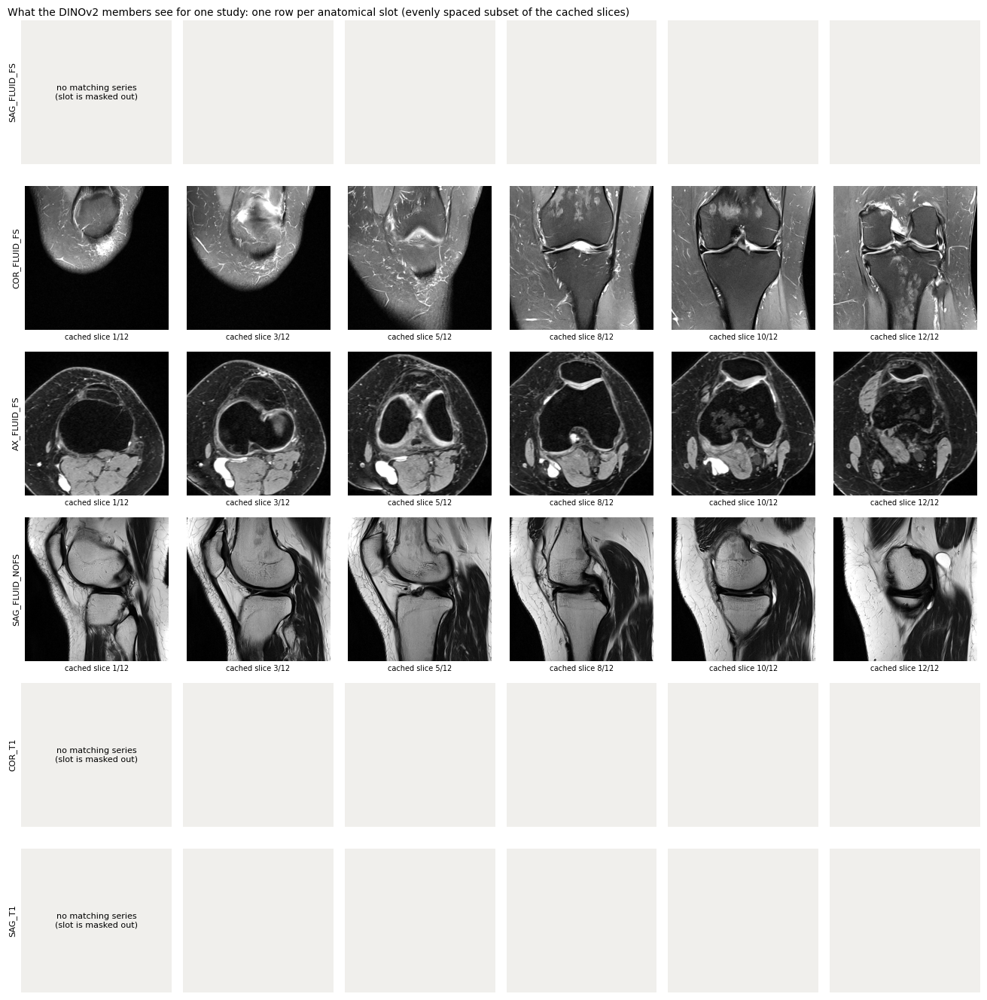

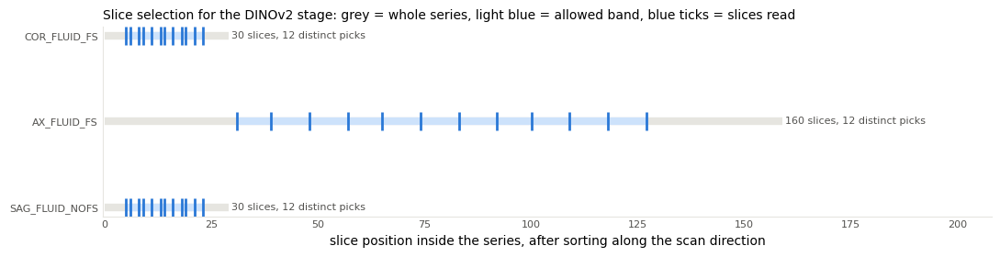

20 members x 3 studies x 12 findings; probability range 0.060 - 0.965


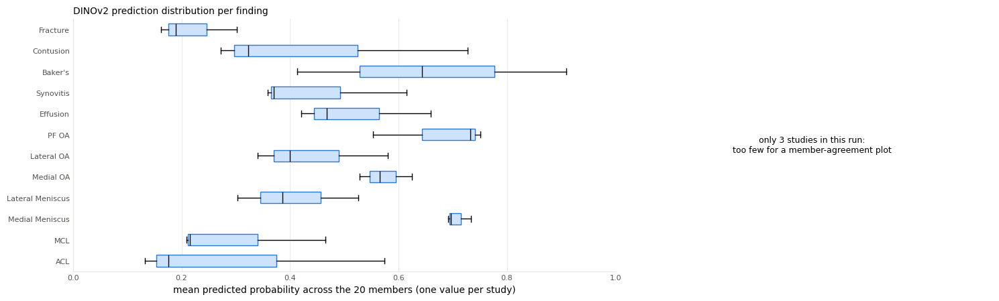

[review B1] ran in 2.0 s


In [33]:
%%branch_b review B1
# ======================= Stage 1 review: what the DINOv2 members were shown, and what they answered =======================
with AX_cell("snapshot stage 1"):
    AX_snapshot("1_dino")


def AX_dino_inputs(study_index=0, max_cols=6):
    """Rebuild, for ONE test study, exactly the slot images that were cached for the DINOv2 members,
    using the pipeline's own functions and its current settings (no model is run)."""
    import matplotlib.pyplot as plt
    hte = annotate(walk("test_series"))                         # header table is memoised: no DICOM is re-read
    tser = pd.read_csv(ROOT / "test_series.csv")
    plane_map = dict(zip(tser["SeriesInstanceUID"], tser["Anatomical_Plane"]))
    uid = _RSNA_TEST_IDS[study_index]
    chosen = pick_slots(hte[hte.StudyInstanceUID == uid], plane_map).get(uid, {})
    side = lat_of(hte[hte.StudyInstanceUID == uid], "illustration: ").get(uid)   # same rule as the pipeline: tag first, geometry second
    n_events, n_failed = len(_RSNA_AUDIT["events"]), len(DECODE_FAILED)
    rows = []
    try:
        for name, plane, _, _ in SLOTS:
            rec = chosen.get(name)
            if rec is None:
                rows.append((name, plane, None, None, None)); continue
            rec = dict(rec)                                     # plain copy: the pipeline's own records stay untouched
            memo = _RSNA_ORDER_MEMO.get((str(Path(rec["dir"]).resolve()), RULES["order"], tuple(sorted(rec["files"]))))
            if memo is not None:
                rec["ordered"] = list(memo[0])
            img = read_slot(rec, CACHE_SLICES, IMG)
            if img is not None:
                img = normalise_laterality(img, plane, side).numpy()
            n = len(rec["files"])
            lo, hi = int(SLICE_BAND[0] * (n - 1)), int(SLICE_BAND[1] * (n - 1))
            picks = np.unique(np.linspace(lo, hi, CACHE_SLICES).astype(int)) if hi > lo else np.array([n // 2])
            rows.append((name, plane, img, n, picks))
    finally:   # the audit trail must describe the real run only, not this illustration
        del _RSNA_AUDIT["events"][n_events:]
        del DECODE_FAILED[n_failed:]
    print(f"study {uid} | knee side used for flipping: {side or 'unresolved'} | image size {IMG}px | crop {CROP_MM:.0f} mm | "
          f"{CACHE_SLICES} slices per slot from the {SLICE_BAND[0]:.0%}-{SLICE_BAND[1]:.0%} band of each series")
    cols = min(max_cols, CACHE_SLICES)
    show = np.linspace(0, CACHE_SLICES - 1, cols).round().astype(int)
    fig, axes = plt.subplots(len(rows), cols, figsize=(2.2 * cols, 2.25 * len(rows)), squeeze=False)
    for r, (name, plane, img, n, picks) in enumerate(rows):
        for c, k in enumerate(show):
            ax = axes[r][c]; ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_visible(False)
            if img is None:
                ax.set_facecolor("#f0efec")
                if c == 0:
                    ax.text(0.5, 0.5, "no matching series\n(slot is masked out)", ha="center", va="center", fontsize=8, transform=ax.transAxes)
            else:
                ax.imshow(img[k], cmap="gray", vmin=0, vmax=255)
                ax.set_xlabel(f"cached slice {k + 1}/{CACHE_SLICES}", fontsize=7)
            if c == 0:
                ax.set_ylabel(name, fontsize=8)
    fig.suptitle("What the DINOv2 members see for one study: one row per anatomical slot (evenly spaced subset of the cached slices)",
                 fontsize=10, x=0.01, ha="left")
    plt.tight_layout(); plt.show()

    # slice selection: which positions of each original series were used
    present = [(name, n, picks) for name, _, img, n, picks in rows if img is not None]
    if present:
        fig, ax = plt.subplots(figsize=(11, 0.5 * len(present) + 1.4))
        for y, (name, n, picks) in enumerate(present):
            ax.hlines(y, 0, n - 1, color=AX_C["grid"], lw=6)
            ax.hlines(y, int(SLICE_BAND[0] * (n - 1)), int(SLICE_BAND[1] * (n - 1)), color="#cde2fb", lw=6)
            ax.plot(picks, [y] * len(picks), "|", color=AX_C["blue"], ms=14, mew=2)
            ax.text(n - 1 + 0.6, y, f"{n} slices, {len(picks)} distinct picks", va="center", fontsize=8, color=AX_C["muted"])
        ax.set_yticks(range(len(present)), [p[0] for p in present], fontsize=8); ax.invert_yaxis()
        ax.set_xlabel("slice position inside the series, after sorting along the scan direction")
        ax.set_title("Slice selection for the DINOv2 stage: grey = whole series, light blue = allowed band, blue ticks = slices read",
                     fontsize=10, loc="left")
        AX_style(ax, None); ax.set_xlim(-0.5, max(p[1] for p in present) * 1.3); plt.tight_layout(); plt.show()
        if any(len(p[2]) < CACHE_SLICES for p in present):
            print(f"A series whose band holds fewer than {CACHE_SLICES} slices is read completely and its last slice is repeated to fill the cache.")


def AX_dino_member_summary():
    """Do the 20 members agree? Low agreement = diverse ensemble; one member far from the rest = suspect."""
    import matplotlib.pyplot as plt
    files = sorted((AX_OUT / "diagnostics").glob("dino_*.npz"))
    if not files:
        print("no DINOv2 member predictions found"); return
    P = np.stack([np.load(f, allow_pickle=False)["values"] for f in files])       # [member, study, finding] probabilities
    print(f"{P.shape[0]} members x {P.shape[1]} studies x {P.shape[2]} findings; probability range {P.min():.3f} - {P.max():.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
    mean = P.mean(0)                                                              # ensemble mean probability per study
    bp = ax[0].boxplot([mean[:, j] for j in range(P.shape[2])], vert=False, tick_labels=TARGETS, widths=0.55,
                       patch_artist=True, medianprops=dict(color=AX_C["ink"]), flierprops=dict(marker=".", ms=3, mec=AX_C["grey"]))
    for b in bp["boxes"]:
        b.set(facecolor="#cde2fb", edgecolor=AX_C["blue"])
    ax[0].set_xlim(0, 1); ax[0].set_xlabel("mean predicted probability across the 20 members (one value per study)")
    ax[0].set_title("DINOv2 prediction distribution per finding", fontsize=10, loc="left"); AX_style(ax[0])
    if P.shape[1] >= 8:
        R = np.stack([AX_rankpct(p) for p in P])                                  # rank within each member
        flat = R.transpose(0, 2, 1).reshape(P.shape[0], -1)                       # ranks are comparable across findings
        C = np.corrcoef(flat)
        im = ax[1].imshow(C, cmap=AX_SEQ, vmin=min(0.5, float(C.min())), vmax=1)
        ax[1].set_xlabel("member"); ax[1].set_ylabel("member")
        ax[1].set_title(f"Agreement between members (rank correlation, mean off-diagonal {(C.sum() - len(C)) / (C.size - len(C)):.2f})",
                        fontsize=10, loc="left")
        AX_style(ax[1], None); fig.colorbar(im, ax=ax[1], fraction=.046)
    else:
        ax[1].axis("off")
        ax[1].text(0.5, 0.5, f"only {P.shape[1]} studies in this run:\ntoo few for a member-agreement plot", ha="center", va="center", fontsize=9)
    plt.tight_layout(); plt.show()


with AX_cell("stage 1 inputs"):
    AX_dino_inputs()
with AX_cell("stage 1 member summary"):
    AX_dino_member_summary()

## Stage B2 — A5 attention pooling (5 folds)

**Why a second, different model.** DINOv2 members see three slices at a time and combine *slots*. A5 looks at **16 slices of a slot at once** and combines evidence with a different mechanism. Models that look at the data differently make different errors, which is what makes blending them worthwhile.

**Input.** Six slots (three planes × fat-suppressed / not), 16 slices each at 336 px from the central 12–88 % of the series, ordered by `InstanceNumber`, cropped to 130 mm, each slice windowed to its own 1st–99th percentile. Coronal and axial images are mirrored when the image position indicates a right knee. Note that these rules differ slightly from Stage 1; each stage reproduces what *its* checkpoints were trained with.

**Architecture** (`Net`, configured by the checkpoint itself).
- *Slices as channels.* The 16 slices of a slot form one 16-channel image, so the very first layer already mixes neighbouring slices. Depending on the checkpoint's `stem` setting, a small depth module first blends neighbouring slices (`SlotDepthMixer`) or compresses 16 channels to 3 (`DepthCompress`).
- *Encoder.* A `timm` image backbone named in the checkpoint. With `cond == 'token'`, an extra learned token tells the transformer which slot it is looking at (`ViTSlotToken`).
- *Readout.* A study has a variable number of slots. The readout pools them with per-finding attention (`LabelAttentionPool`, `TokenXAttnPool`, residual variants) or mean+max pooling, again chosen by the checkpoint. An embedding of *which* slots are present is added, so the model knows what it could not see.

The loader checks that all five folds share one configuration and that image size and slice count match this notebook's loader, then loads strictly.

**Ensembling.** Each fold's probabilities are ranked, the five rank vectors averaged, and the result blended into stage 1 with weight **0.52**.

**Effect on predictions.** A5 supplies 52 % of the stage-2 blend. That blend is the input of stages B4–B5.

### The bug this stage had

In the very first version of this pipeline the visualization cell in the middle of this stage contained

```python
studies = sorted(p for p in Path(SERIES_ROOT).iterdir() if p.is_dir())
```

Two cells earlier, `studies` had been defined as the list of test study IDs (strings) that A5 iterates over. After the plotting cell it was a list of folder paths. A5 then looked up `by.get(study, [])` in a dictionary keyed by ID strings, got an empty list for every study, recorded "no metadata", and marked every study as not applicable. The blend function treats "not applicable" as a legitimate case (some studies really lack usable series) and returned the DINOv2 blend unchanged. No error, no warning in the cell output, and a complete, valid-looking `submission.csv` at the end.

The saved output of the original run shows the contradiction: the startup check reports `a5_without_matching_acquisition: 0` (every study has usable series), while the A5 stage ends with `"absent": 3, "applicable": 0`.

**What was done.**
1. The plotting code moved into a function and runs under `AX_cell`.
2. **New gate 1 — input contract** (before inference): `studies` must be exactly the list of test IDs.
3. **New gate 2 — coverage** (after inference): the studies without an A5 prediction must be explained by the metadata; if more than 25 % are unexplained the run stops.

The general lesson: a pipeline that tolerates missing inputs needs a check that the tolerated case is the exception.

### B2 · constants and the weight folder

Sets the A5 constants (crop, image size, slice band, slots) and finds the five fold checkpoints. A snapshot of all variables is taken first (`_A5_SAVED`) and restored at the end of the stage, because A5 re-uses names such as `SLOTS` and `SLICE_BAND` with other values than stage B1.

In [34]:
%%branch_b B2 constants
if globals().get('_DINOV2_MATCHED_MEMBERS') != 20:
    raise RuntimeError('DINOv2 20/20 fingerprint gate did not pass')
rsna_phase('a5', 'START')
_A5_SAVED = dict(globals())
import gc, os, time, warnings
from concurrent.futures import ThreadPoolExecutor as A5DecodePool, as_completed
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import pydicom
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings('ignore')
cv2.setNumThreads(1)
CROP_MM = 130.0
SIZE = 336
SLICE_BAND = (0.12, 0.88)
N_SLICE = 16
INTENSITY = 'slice'
SLOTS = [
    ('Sagittal', 1),
    ('Sagittal', 0),
    ('Coronal', 1),
    ('Coronal', 0),
    ('Axial', 1),
    ('Axial', 0),
]
N_SLOT = len(SLOTS)
LABELS = [
    'ACL',
    'MCL',
    'Medial Meniscus',
    'Lateral Meniscus',
    'Medial OA',
    'Lateral OA',
    'PF OA',
    'Effusion',
    'Synovitis',
    "Baker's",
    'Contusion',
    'Fracture',
]


def _one_a5_root(tag, candidates, marker):
    hits = [
        Path(path) for path in candidates if Path(path).is_dir() and (Path(path) / marker).exists()
    ]
    if len(hits) != 1:
        raise RuntimeError(f'{tag}: expected one direct root, found {hits}')
    return hits[0]


COMP = Path(ROOT)
CKPT = _one_a5_root(
    'A5 weights',
    [
        '/kaggle/input/datasets/mattiaangeli/knee-mri-fold-weights',
        '/kaggle/input/knee-mri-fold-weights',
    ],
    'm_f0.pt',
)
assert COMP is not None, 'competition data not attached'
assert CKPT is not None, 'fold weights not attached'
assert (COMP / 'sample_submission.csv').exists(), f'no competition data at {COMP}'
assert list(CKPT.glob('*_f*.pt')), f'no checkpoints at {CKPT}'
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'


[phase] {"elapsed_seconds": 98.87028121948242, "gpus": [{"allocated_bytes": 9568256, "id": 0, "reserved_bytes": 23068672}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 195035136}], "max_rss_kib": 3191344, "memory.current": "6941257728", "memory.max": "32212254720", "stage": "a5", "status": "START"}
[B2 constants] ran in 3.9 s | defined functions: _one_a5_root | settings: CKPT, COMP, CROP_MM, DEV, INTENSITY, LABELS, N_SLICE (+3 more)


### B2 · how a study is decoded

`ordered_files`, `read_crop`, `window`, `render` and `build_study`: the A5 answers to the seven image-processing decisions of Part D.

In [35]:
%%branch_b B2 inputs
SERIES_ROOT = COMP / 'test_series'
if not SERIES_ROOT.is_dir():
    raise FileNotFoundError('Missing test_series; train-series fallback is forbidden')
print('series root:', SERIES_ROOT)


def ordered_files(sdir, cap=64):
    # Preserve the parent's InstanceNumber ordering; remove pre-sort truncation.
    # The unused cap argument remains only for call compatibility.
    keyed = []
    unreadable = []
    for f in sorted(sdir.glob('*.dcm')):
        try:
            ds = pydicom.dcmread(str(f), stop_before_pixels=True)
            key = int(ds.InstanceNumber)
        except Exception as exc:
            unreadable.append(str(f))
            continue
        keyed.append((key, str(f)))
    if unreadable:
        rsna_event(
            'a5_order_unreadable_dropped',
            series=str(sdir),
            unreadable=len(unreadable),
            readable=len(keyed),
            examples=unreadable[:3],
        )
    return [f for _, f in sorted(keyed)]


def series_side(path):
    try:
        return float(pydicom.dcmread(path, stop_before_pixels=True).ImagePositionPatient[0])
    except Exception:
        return 0.0


def read_crop(path):
    try:
        ds = pydicom.dcmread(path)
        arr = ds.pixel_array.astype(np.float32)
    except Exception:
        return None
    try:
        ps = float(ds.PixelSpacing[0])
    except Exception:
        ps = CROP_MM / max(arr.shape)
    half = int(round(CROP_MM / ps / 2))
    cy, cx = (arr.shape[0] // 2, arr.shape[1] // 2)
    y0, y1 = (max(0, cy - half), min(arr.shape[0], cy + half))
    x0, x1 = (max(0, cx - half), min(arr.shape[1], cx + half))
    crop = arr[y0:y1, x0:x1]
    return None if crop.size == 0 else crop


def window(crop, lo, hi, flip):
    c = np.clip((crop - lo) / max(hi - lo, 1e-06), 0, 1)
    img = cv2.resize(c, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    return img[:, ::-1].copy() if flip else img


def render(path, flip):
    crop = read_crop(path)
    if crop is None:
        return None
    lo, hi = np.percentile(crop[::4, ::4], [1, 99])
    return window(crop, lo, hi, flip)


def build_study(args):
    idx, study, recs = args
    out = np.zeros((N_SLOT, N_SLICE, SIZE, SIZE), np.uint8)
    mask = np.zeros(N_SLOT, np.uint8)
    rows = pd.DataFrame(recs)
    if not len(rows):
        rsna_event('a5_no_metadata', study=str(study))
        return idx, out, mask
    for s_i, (plane, fs) in enumerate(SLOTS):
        sub = rows[(rows.Anatomical_Plane == plane) & (rows.Fat_Suppression == fs)]
        if sub.empty:
            continue  # Actual acquisition absence, not a decoding failure.
        series = str(sub.iloc[0].SeriesInstanceUID)
        files = ordered_files(SERIES_ROOT / str(study) / series)
        if not files:
            rsna_event('a5_slot_no_files', study=str(study), series=series)
            continue
        flip = plane != 'Sagittal' and series_side(files[0]) < 0
        i0 = int(round(SLICE_BAND[0] * (len(files) - 1)))
        i1 = int(round(SLICE_BAND[1] * (len(files) - 1)))
        avail = list(range(i0, i1 + 1))
        if len(avail) >= N_SLICE:
            picks = [avail[int(round(t))] for t in np.linspace(0, len(avail) - 1, N_SLICE)]
            off = 0
        else:
            picks, off = avail, (N_SLICE - len(avail)) // 2
        rendered = 0
        errors = []
        if INTENSITY == 'series':
            crops = [read_crop(files[p]) for p in picks]
            got = [x for x in crops if x is not None]
            if not got:
                rsna_event('a5_slot_all_crops_failed', study=str(study), series=series)
                continue
            samp = np.concatenate([x[::4, ::4].ravel() for x in got])
            lo_, hi_ = np.percentile(samp, [1, 99])
            for c, x in enumerate(crops):
                if x is None:
                    x = read_crop(files[min(len(files) - 1, picks[c] + 1)])
                if x is None:
                    errors.append(files[picks[c]])
                    continue
                img = window(x, lo_, hi_, flip)
                rsna_finite(img, 'A5 rendered pixels')
                out[s_i, off + c] = (img * 255).astype(np.uint8)
                rendered += 1
        else:
            for c, p in enumerate(picks):
                img = render(files[p], flip)
                if img is None:
                    img = render(files[min(len(files) - 1, p + 1)], flip)
                if img is None:
                    errors.append(files[p])
                    continue
                rsna_finite(img, 'A5 rendered pixels')
                out[s_i, off + c] = (img * 255).astype(np.uint8)
                rendered += 1
        if errors or rendered != len(picks):
            rsna_event(
                'a5_decode_failure',
                study=str(study),
                series=series,
                failed=errors,
                rendered=int(rendered),
                wanted=int(len(picks)),
            )
            if not rendered:
                continue
        mask[s_i] = rendered
    if not mask.any():
        rsna_event('a5_empty_study', study=str(study))
        print(f'[a5] {study}: no acquired slots; all-zero mask kept (parent policy)', flush=True)
    return idx, out, mask


sub_df = pd.read_csv(COMP / 'sample_submission.csv', dtype={'StudyInstanceUID': str})
ser_csv = pd.read_csv(
    COMP / 'test_series.csv', dtype={'StudyInstanceUID': str, 'SeriesInstanceUID': str}
)
if set(sub_df.StudyInstanceUID) != set(_RSNA_TEST_IDS):
    raise RuntimeError('A5 test/sample UID mismatch')
ser_csv = ser_csv.loc[:, ~ser_csv.columns.duplicated()]
studies = sub_df.StudyInstanceUID.tolist()
by = {
    s: g.to_dict('records')
    for s, g in ser_csv[ser_csv.StudyInstanceUID.isin(set(studies))].groupby('StudyInstanceUID')
}
print(f'{len(studies):,} test studies, {len(by):,} with series metadata')


series root: /kaggle/input/competitions/rsna-knee-abnormality-detection/test_series
3 test studies, 3 with series metadata
[B2 inputs] ran in 0.1 s | defined functions: build_study, ordered_files, read_crop, render, series_side, window | settings: SERIES_ROOT


### Raw slices and the A5 slice selection — **Fixed**

Shows raw slices of the first test study as stored in the DICOM files (before cropping and normalisation), taken from the positions A5 will read. This is the cell that caused the bug described above; it now cannot touch pipeline variables.

series 605155903947: 34 slices; A5 reads 16 of them between positions 5 and 30
series 518906646132: 30 slices; A5 reads 16 of them between positions 4 and 27
series 062489758495: 30 slices; A5 reads 16 of them between positions 4 and 27


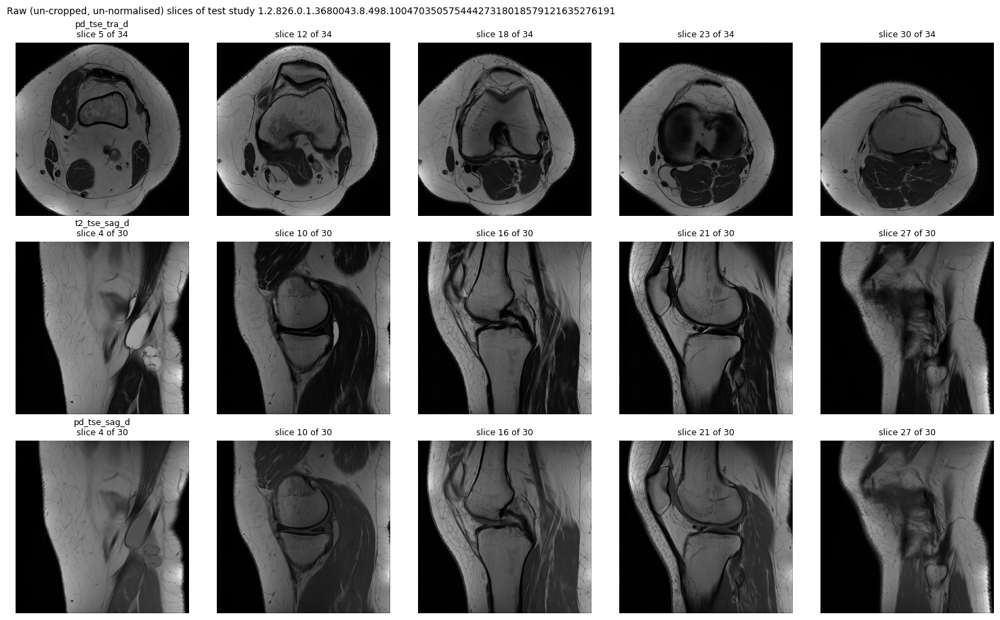

[review B2 raw slices] ran in 4.2 s


In [36]:
%%branch_b review B2 raw slices
# Visualization: raw slices of one test study, and which of them the A5 stage will read.
# FIX: the original version of this cell ran at top level and assigned `studies = sorted(<folders>)`.
# That replaced the list of study UIDs the A5 cells had just built, so A5 found no metadata for any
# study and was silently left out of the blend. The code now lives in a function (its variables are
# local) and runs under AX_cell, which additionally restores any pipeline variable a cell re-binds.
def AX_a5_raw_slices(max_series=3, n_show=5):
    import matplotlib.pyplot as plt
    study_dirs = sorted(p for p in Path(SERIES_ROOT).iterdir() if p.is_dir())
    if not study_dirs:
        print("no test studies found under", SERIES_ROOT); return
    study_dir = study_dirs[0]
    series_dirs = sorted(p for p in study_dir.iterdir() if p.is_dir())[:max_series]
    fig, axes = plt.subplots(len(series_dirs), n_show, figsize=(3 * n_show, 3.1 * len(series_dirs)), squeeze=False)
    n_events = len(_RSNA_AUDIT["events"])
    for r, sdir in enumerate(series_dirs):
        files = ordered_files(sdir)                       # the A5 ordering (by InstanceNumber)
        n = len(files)
        i0, i1 = int(round(SLICE_BAND[0] * (n - 1))), int(round(SLICE_BAND[1] * (n - 1)))
        avail = list(range(i0, i1 + 1))
        picks = [avail[int(round(t))] for t in np.linspace(0, len(avail) - 1, N_SLICE)] if len(avail) >= N_SLICE else avail
        shown = [picks[int(i)] for i in np.linspace(0, len(picks) - 1, n_show).round()] if picks else []
        for c in range(n_show):
            ax = axes[r][c]; ax.axis("off")
            if c < len(shown):
                ds = pydicom.dcmread(files[shown[c]], force=True)
                ax.imshow(ds.pixel_array, cmap="gray")
                title = f"slice {shown[c] + 1} of {n}"
                if c == 0:
                    title = f"{str(getattr(ds, 'SeriesDescription', ''))[:24]}\n{title}"
                ax.set_title(title, fontsize=9)
        print(f"series {sdir.name[-12:]}: {n} slices; A5 reads {len(picks)} of them between positions {i0 + 1} and {i1 + 1}")
    del _RSNA_AUDIT["events"][n_events:]                  # keep the audit trail about the real run only
    fig.suptitle(f"Raw (un-cropped, un-normalised) slices of test study {study_dir.name}", fontsize=10, x=0.01, ha="left")
    plt.tight_layout(); plt.show()


with AX_cell("stage 2 raw slices"):
    AX_a5_raw_slices()

### B2 · model components and checkpoint loading

Defines the pooling modules, the depth stems, the slot token and `Net`, then loads the five fold checkpoints with a strict check: every tensor must be present, have the right shape and be finite.

In [37]:
%%branch_b B2 model and checkpoints
N_SLOT_TYPES, MASK_IDX = (6, 0)


def segment_softmax(scores, sidx, B):
    T, K = scores.shape
    idx = sidx.unsqueeze(1).expand(-1, K)
    m = torch.full((B, K), float('-inf'), device=scores.device, dtype=scores.dtype)
    m = m.scatter_reduce(0, idx, scores, reduce='amax', include_self=True)
    e = (scores - m[sidx]).exp()
    s = torch.zeros(B, K, device=scores.device, dtype=scores.dtype).index_add_(0, sidx, e)
    return e / s[sidx].clamp(min=1e-06)


class MeanMaxPool(nn.Module):

    def forward(self, f, sidx, B, slot=None, return_attn=False):
        D = f.shape[1]
        cnt = torch.zeros(B, device=f.device, dtype=f.dtype).index_add_(
            0, sidx, torch.ones(f.shape[0], device=f.device, dtype=f.dtype)
        )
        mean = torch.zeros(B, D, device=f.device, dtype=f.dtype).index_add_(0, sidx, f)
        mean = mean / cnt.clamp(min=1).unsqueeze(1)
        mx = torch.full((B, D), -10000.0, device=f.device, dtype=f.dtype)
        mx = mx.scatter_reduce(
            0, sidx.unsqueeze(1).expand(-1, D), f, reduce='amax', include_self=True
        )
        return (torch.cat([mean, mx], 1), None)


class LabelAttentionPool(nn.Module):

    def __init__(self, d, n_labels=12, n_heads=4, slot_bias=True):
        super().__init__()
        self.d, self.k, self.h = (d, n_labels, n_heads)
        self.q = nn.Parameter(torch.randn(n_labels, d) * 0.02)
        self.key, self.val = (nn.Linear(d, d), nn.Linear(d, d))
        self.slot_bias = (
            nn.Parameter(torch.zeros(n_labels, N_SLOT_TYPES + 1)) if slot_bias else None
        )

    def forward(self, f, sidx, B, slot=None, return_attn=False):
        scores = self.key(f) @ self.q.t() / self.d**0.5
        if self.slot_bias is not None and slot is not None:
            scores = scores + self.slot_bias.t()[slot]
        a = segment_softmax(scores, sidx, B)
        out = torch.zeros(B, self.k, self.d, device=f.device, dtype=f.dtype)
        out = out.index_add_(0, sidx, a.unsqueeze(-1) * self.val(f).unsqueeze(1))
        return (out, a)


class TokenXAttnPool(nn.Module):

    def __init__(self, d, n_labels=12, n_heads=6, dropout=0.2):
        super().__init__()
        self.d, self.k = (d, n_labels)
        self.q = nn.Parameter(torch.randn(n_labels, d) * 0.02)
        self.slot_emb = nn.Embedding(N_SLOT_TYPES + 1, d, padding_idx=0)
        self.kv_norm = nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, n_heads, dropout=dropout, batch_first=True)

    def forward(self, tok, sidx, B, slot=None, return_attn=False):
        T, N, D = tok.shape
        cnt = torch.bincount(sidx, minlength=B)
        S = int(cnt.max().item())
        starts = torch.cumsum(cnt, 0) - cnt
        pos = torch.arange(T, device=tok.device) - starts[sidx]
        kv = tok + self.slot_emb(slot).unsqueeze(1)
        pad = tok.new_zeros(B, S, N, D)
        pad[sidx, pos] = kv
        keep = torch.zeros(B, S, dtype=torch.bool, device=tok.device)
        keep[sidx, pos] = True
        kpm = ~keep.repeat_interleave(N, dim=1)
        pad = self.kv_norm(pad.reshape(B, S * N, D))
        q = self.q.unsqueeze(0).expand(B, -1, -1)
        att, w = self.attn(
            q, pad, pad, key_padding_mask=kpm, need_weights=return_attn, average_attn_weights=True
        )
        cls = tok[:, 0]
        mean = torch.zeros(B, D, device=tok.device, dtype=tok.dtype).index_add_(
            0, sidx, cls
        ) / cnt.clamp(min=1).unsqueeze(1)
        mx = torch.full((B, D), -10000.0, device=tok.device, dtype=tok.dtype)
        mx = mx.scatter_reduce(
            0, sidx.unsqueeze(1).expand(-1, D), cls, reduce='amax', include_self=True
        )
        base = torch.cat([mean, mx], 1).unsqueeze(1).expand(-1, self.k, -1)
        return (torch.cat([att, base], -1), w)


class ViTSlotToken(nn.Module):

    def __init__(self, vit, n_cat, dim=None):
        super().__init__()
        self.vit = vit
        d = dim or vit.embed_dim
        self.tok = nn.Embedding(n_cat + 1, d, padding_idx=MASK_IDX)
        self.num_features = vit.num_features
        self._orig_prefix = getattr(vit, 'num_prefix_tokens', 1)
        vit.num_prefix_tokens = self._orig_prefix + 1
        for blk in vit.blocks:
            a = getattr(blk, 'attn', None)
            if a is not None and hasattr(a, 'num_prefix_tokens'):
                a.num_prefix_tokens = a.num_prefix_tokens + 1

    @staticmethod
    def _maybe(mod, x):
        return x if mod is None else mod(x)

    def forward_features(self, x, cat):
        v = self.vit
        x = v.patch_embed(x)
        pos = v._pos_embed(x)
        rope = None
        if isinstance(pos, tuple):
            x, rope = pos
        else:
            x = pos
        x = self._maybe(getattr(v, 'patch_drop', None), x)
        x = self._maybe(getattr(v, 'norm_pre', None), x)
        npt = self._orig_prefix
        tok = self.tok(cat).unsqueeze(1)
        x = torch.cat([x[:, :npt], tok, x[:, npt:]], dim=1)
        if rope is not None:
            if getattr(v, 'rope_mixed', False):
                for i, blk in enumerate(v.blocks):
                    x = blk(x, rope=rope[i])
            else:
                for blk in v.blocks:
                    x = blk(x, rope=rope)
        else:
            x = v.blocks(x)
        return v.norm(x)

    def forward_head(self, x, pre_logits=True):
        return self.vit.forward_head(x, pre_logits=pre_logits)


IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


class _GatedDepthBlock(nn.Module):

    def __init__(self, n_slice, dropout=0.0, ls_init=0.1):
        super().__init__()
        self.norm = nn.GroupNorm(1, n_slice)
        self.v = nn.Conv2d(n_slice, n_slice, 1)
        self.g = nn.Conv2d(n_slice, n_slice, 1)
        self.out = nn.Conv2d(n_slice, n_slice, 1)
        self.gamma = nn.Parameter(torch.full((n_slice, 1, 1), ls_init))
        self.drop = nn.Dropout2d(dropout) if dropout else nn.Identity()

    def forward(self, x):
        z = self.norm(x)
        return x + self.gamma * self.drop(self.out(self.v(z) * F.silu(self.g(z))))


class DepthCompress(nn.Module):

    def __init__(
        self,
        n_slice=16,
        out_ch=3,
        depth=1,
        dropout=0.0,
        ls_init=0.1,
        imagenet=True,
        proj_noise=0.25,
    ):
        super().__init__()
        self.imagenet = imagenet
        self.blocks = nn.ModuleList(
            [_GatedDepthBlock(n_slice, dropout, ls_init) for _ in range(depth)]
        )
        self.proj = nn.Conv2d(n_slice, out_ch, 1, bias=True)
        if imagenet:
            self.register_buffer('mu', torch.tensor(IMAGENET_MEAN).view(1, -1, 1, 1))
            self.register_buffer('sd', torch.tensor(IMAGENET_STD).view(1, -1, 1, 1))

    def forward(self, x):
        keep = (x.amax(dim=1, keepdim=True) > 0).to(x.dtype)
        z = x
        for b in self.blocks:
            z = b(z)
        z = self.proj(z)
        if self.imagenet:
            z = (z - self.mu.to(z.dtype)) / self.sd.to(z.dtype)
        return z * keep


N_PLANE, N_CONTRAST = (3, 2)
_PLANE_OF = lambda s: torch.clamp(s - 1, 0, 5) // 2
_CONTRAST_OF = lambda s: torch.clamp(s - 1, 0, 5) % 2


class SlotDepthMixer(nn.Module):

    def __init__(self, n_slice=16, ksize=5, alpha_max=0.25):
        super().__init__()
        self.n_slice, self.ksize, self.r = (n_slice, ksize, ksize // 2)
        self.alpha_max = alpha_max
        b = torch.tensor([1.0, 4.0, 6.0, 4.0, 1.0])
        self.register_buffer('base', b.log()[self.r :])
        n_u = self.r + 1
        self.shared = nn.Parameter(torch.zeros(n_u))
        self.plane_k = nn.Parameter(torch.zeros(N_PLANE, n_u))
        self.contrast_k = nn.Parameter(torch.zeros(N_CONTRAST, n_u))
        self.g0 = nn.Parameter(torch.zeros(()))
        self.gate_p = nn.Parameter(torch.zeros(N_PLANE))
        self.gate_c = nn.Parameter(torch.zeros(N_CONTRAST))
        idx = torch.arange(n_slice)
        self.register_buffer('off', idx[None, :] - idx[:, None])

    def kernel(self, slot):
        p, c = (_PLANE_OF(slot), _CONTRAST_OF(slot))
        half = self.base + self.shared + self.plane_k[p] + self.contrast_k[c]
        full = torch.cat([half.flip(-1)[..., : self.r], half], dim=-1)
        return F.softmax(full, dim=-1)

    def alpha(self, slot):
        p, c = (_PLANE_OF(slot), _CONTRAST_OF(slot))
        return self.alpha_max * torch.tanh(self.g0 + self.gate_p[p] + self.gate_c[c])

    def forward(self, x, slot, vmask):
        T, S, H, W = x.shape
        if vmask is None:
            raise ValueError('stem=mixer requires the padding mask')
        k = self.kernel(slot)
        v = vmask.to(k.dtype)
        d = self.off + self.r
        inb = (d >= 0) & (d < self.ksize)
        kk = k[:, d.clamp(0, self.ksize - 1)] * inb
        M = kk * v[:, None, :]
        den = M.sum(-1, keepdim=True)
        eye = torch.eye(S, device=x.device, dtype=M.dtype).expand(T, S, S)
        ok = (den > 1e-06) & v[:, :, None].bool()
        M = torch.where(ok, M / den.clamp(min=1e-06), eye)
        a = self.alpha(slot)[:, None, None]
        Aop = ((1.0 - a) * eye + a * M).to(x.dtype)
        if x.is_contiguous(memory_format=torch.channels_last) and (not x.is_contiguous()):
            y = torch.bmm(x.permute(0, 2, 3, 1).reshape(T, H * W, S), Aop.transpose(1, 2))
            return y.reshape(T, H, W, S).permute(0, 3, 1, 2)
        return torch.bmm(Aop, x.reshape(T, S, H * W)).reshape(T, S, H, W)


def _seg_mean_max(v, sidx, B):
    D = v.shape[1]
    cnt = torch.zeros(B, device=v.device, dtype=v.dtype).index_add_(
        0, sidx, torch.ones(v.shape[0], device=v.device, dtype=v.dtype)
    )
    mean = torch.zeros(B, D, device=v.device, dtype=v.dtype).index_add_(0, sidx, v)
    mean = mean / cnt.clamp(min=1).unsqueeze(1)
    mx = torch.full((B, D), -10000.0, device=v.device, dtype=v.dtype)
    mx = mx.scatter_reduce(0, sidx.unsqueeze(1).expand(-1, D), v, reduce='amax', include_self=True)
    return torch.cat([mean, mx], 1)


def _pad_kv(x, sidx, B, norm):
    T, P, D = x.shape
    cnt = torch.bincount(sidx, minlength=B)
    S = int(cnt.max().item())
    starts = torch.cumsum(cnt, 0) - cnt
    pos = torch.arange(T, device=x.device) - starts[sidx]
    pad = x.new_zeros(B, S, P, D)
    pad[sidx, pos] = x
    keep = torch.zeros(B, S, dtype=torch.bool, device=x.device)
    keep[sidx, pos] = True
    return (norm(pad.reshape(B, S * P, D)), ~keep.repeat_interleave(P, dim=1))


class _GatedDelta(nn.Module):

    def __init__(self, d, n_labels, n_heads, dropout):
        super().__init__()
        self.q = nn.Parameter(torch.randn(n_labels, d) * 0.02)
        self.kv_norm = nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, n_heads, dropout=dropout, batch_first=True)
        self.d_norm = nn.LayerNorm(d)
        self.dw = nn.Parameter(torch.randn(n_labels, d) * (1.0 / d**0.5))
        self.db = nn.Parameter(torch.zeros(n_labels))
        self.gate = nn.Parameter(torch.zeros(n_labels))

    def delta(self, pat, sidx, B, return_attn):
        kv, kpm = _pad_kv(pat, sidx, B, self.kv_norm)
        q = self.q.unsqueeze(0).expand(B, -1, -1)
        att, w = self.attn(
            q, kv, kv, key_padding_mask=kpm, need_weights=return_attn, average_attn_weights=True
        )
        return ((self.d_norm(att) * self.dw).sum(-1) + self.db, w)


class TokenResidualPool(_GatedDelta):

    def __init__(self, d, n_labels=12, n_heads=6, pe=64, dropout=0.2):
        super().__init__(d, n_labels, n_heads, dropout)
        self.base = nn.Sequential(
            nn.LayerNorm(2 * d + pe), nn.Dropout(dropout), nn.Linear(2 * d + pe, n_labels)
        )

    def forward(self, tok, slot, sidx, B, pres, return_attn=False):
        base = self.base(torch.cat([_seg_mean_max(tok[:, 1:].mean(1), sidx, B), pres], 1))
        d_, w = self.delta(tok[:, 1:], sidx, B, return_attn)
        return (base + self.gate * d_, w)


class CodexResidualPool(_GatedDelta):

    def __init__(self, d, n_labels=12, n_heads=6, pe=64, dropout=0.2):
        super().__init__(d, n_labels, n_heads, dropout)
        self.base = nn.Sequential(
            nn.LayerNorm(2 * d + pe), nn.Dropout(dropout), nn.Linear(2 * d + pe, n_labels)
        )

    def forward(self, tok, slot, sidx, B, pres, return_attn=False):
        base = self.base(torch.cat([_seg_mean_max(tok[:, 0], sidx, B), pres], 1))
        d_, w = self.delta(tok[:, 1:], sidx, B, return_attn)
        return (base + self.gate * d_, w)


class ClsAddPool(nn.Module):

    def __init__(self, d, n_labels=12, pe=64, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(4 * d + pe), nn.Dropout(dropout), nn.Linear(4 * d + pe, n_labels)
        )

    def forward(self, tok, slot, sidx, B, pres, return_attn=False):
        return (
            self.net(
                torch.cat(
                    [
                        _seg_mean_max(tok[:, 1:].mean(1), sidx, B),
                        _seg_mean_max(tok[:, 0], sidx, B),
                        pres,
                    ],
                    1,
                )
            ),
            None,
        )


class Readout(nn.Module):

    def __init__(self, pool, d, n_labels=12, pe=64):
        super().__init__()
        self.pool_kind, self.k = (pool, n_labels)
        self.pres_emb = nn.Embedding(N_SLOT_TYPES + 1, pe, padding_idx=0)
        if pool in ('xres', 'clsadd', 'xcodex'):
            self.pool = {
                'xres': TokenResidualPool,
                'clsadd': ClsAddPool,
                'xcodex': CodexResidualPool,
            }[pool](d, n_labels, pe=pe)
        elif pool in ('attn', 'xattn'):
            if pool == 'xattn':
                self.pool = TokenXAttnPool(d, n_labels)
                wd = 3 * d + pe
            else:
                self.pool = LabelAttentionPool(d, n_labels)
                wd = d + pe
            self.norm = nn.LayerNorm(wd)
            self.w = nn.Parameter(torch.randn(n_labels, wd) * (1.0 / wd**0.5))
            self.b = nn.Parameter(torch.zeros(n_labels))
        else:
            self.pool = MeanMaxPool()
            self.net = nn.Sequential(
                nn.LayerNorm(2 * d + pe), nn.Dropout(0.2), nn.Linear(2 * d + pe, n_labels)
            )
        self.drop = nn.Dropout(0.2)

    def forward(self, f, slot, sidx, B, return_attn=False):
        pe = self.pres_emb(slot)
        pres = torch.zeros(B, pe.shape[1], device=f.device, dtype=f.dtype).index_add_(0, sidx, pe)
        if self.pool_kind in ('xres', 'clsadd', 'xcodex'):
            return self.pool(f, slot, sidx, B, pres)[0]
        pooled, attn = self.pool(f, sidx, B, slot=slot, return_attn=return_attn)
        if self.pool_kind in ('attn', 'xattn'):
            x = torch.cat([pooled, pres.unsqueeze(1).expand(-1, self.k, -1)], -1)
            x = self.drop(self.norm(x))
            return (x * self.w).sum(-1) + self.b
        return self.net(torch.cat([pooled, pres], 1))


class Net(nn.Module):

    def __init__(self, enc, cond, n_meta=0, pool='mean_max', stem='native', n_slice=16):
        super().__init__()
        self.enc, self.cond = (enc, cond)
        self.compress = DepthCompress(n_slice, 3) if stem == 'compress' else None
        self.mixer = SlotDepthMixer(n_slice) if stem == 'mixer' else None
        self.tokens = pool in ('xattn', 'xres', 'clsadd', 'xcodex')
        D = enc.num_features
        self.meta_mlp = (
            nn.Sequential(
                nn.LayerNorm(n_meta), nn.Linear(n_meta, 128), nn.GELU(), nn.Linear(128, D)
            )
            if n_meta > 0
            else None
        )
        self.readout = Readout(pool, D)
        if cond == 'post':
            self.slot_emb = nn.Embedding(N_SLOT_TYPES + 1, D, padding_idx=MASK_IDX)

    def forward(self, im, slot, smeta, sidx, B, vm=None):
        if self.mixer is not None:
            im = self.mixer(im, slot, vm)
        if self.compress is not None:
            im = self.compress(im)
        f = (
            self.enc.forward_features(im, slot)
            if self.cond == 'token'
            else self.enc.forward_features(im)
        )
        if self.tokens:
            inner = getattr(self.enc, 'vit', self.enc)
            orig = getattr(self.enc, '_orig_prefix', getattr(inner, 'num_prefix_tokens', 1))
            f = torch.cat([f[:, :1], f[:, orig:]], 1)
        else:
            f = self.enc.forward_head(f, pre_logits=True)
            if f.dim() > 2:
                f = f.flatten(1)
        ex = (lambda v: v.unsqueeze(1)) if self.tokens else lambda v: v
        if self.cond == 'post':
            f = f + ex(self.slot_emb(slot))
        if self.meta_mlp is not None and smeta.shape[1] > 0:
            mt = self.meta_mlp(smeta)
            f = torch.cat([f, mt.unsqueeze(1)], 1) if self.tokens else f + mt
        return self.readout(f, slot, sidx, B)


models = []
_A5_LOAD_RECEIPT = []
_a5_paths = [CKPT / f'm_f{i}.pt' for i in range(5)]
if not all(p.is_file() for p in _a5_paths):
    raise RuntimeError(
        f'A5 requires m_f0.pt..m_f4.pt; missing {[str(p) for p in _a5_paths if not p.is_file()]}'
    )
_a5_config = None
for ckpt_path in _a5_paths:
    z = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    cfg = z['cfg']
    fold = int(z['fold'])
    if ckpt_path.name != f'm_f{fold}.pt':
        raise RuntimeError('A5 fold/file identity mismatch')
    fields = {
        'backbone': cfg['backbone'],
        'cond': cfg['cond'],
        'pool': cfg['pool'],
        'img': int(cfg['img']),
        'n_slice': int(cfg.get('n_slice', 16)),
        'n_meta': int(cfg.get('n_meta', 0)),
        'meta': cfg.get('meta', 'none'),
        'stem': cfg.get('stem', 'native'),
        'norm': cfg.get('norm', 'none'),
    }
    if _a5_config is None:
        _a5_config = fields
    if fields != _a5_config:
        raise RuntimeError(f'A5 per-fold input/model contract differs: {ckpt_path}')
    if fields['img'] != SIZE or fields['n_slice'] != N_SLICE or fields['n_meta'] != 0:
        raise RuntimeError(f'A5 checkpoint input contract incompatible with loader: {fields}')
    if 'labels' in z and list(z['labels']) != list(LABELS):
        raise RuntimeError('A5 label order differs')
    _stem = fields['stem']
    _in = 3 if _stem == 'compress' else fields['n_slice']
    enc = timm.create_model(
        cfg['backbone'],
        pretrained=False,
        num_classes=0,
        in_chans=_in,
        **({'img_size': cfg['img']} if 'vit_' in cfg['backbone'] else {}),
    )
    if cfg['cond'] == 'token':
        enc = ViTSlotToken(enc, N_SLOT_TYPES)
    m = Net(
        enc,
        cfg['cond'],
        cfg.get('n_meta', 0),
        cfg['pool'],
        stem=_stem,
        n_slice=cfg.get('n_slice', 16),
    )
    rsna_strict_load(m, z['state_dict'], f'A5 fold {fold}')
    models.append(m.eval())
    _A5_LOAD_RECEIPT.append(
        {
            'fold': fold,
            'file': str(ckpt_path),
            'sha256': rsna_sha(ckpt_path),
            'tensor_keys': len(z['state_dict']),
            'strict': True,
            'config': fields,
        }
    )
    print(f'A5 strict-loaded {ckpt_path.name}; all encoder and head tensors present')
CFG = dict(cfg)
rsna_json('/kaggle/working/diagnostics/a5_loads.json', _A5_LOAD_RECEIPT)


A5 strict-loaded m_f0.pt; all encoder and head tensors present
A5 strict-loaded m_f1.pt; all encoder and head tensors present
A5 strict-loaded m_f2.pt; all encoder and head tensors present
A5 strict-loaded m_f3.pt; all encoder and head tensors present
A5 strict-loaded m_f4.pt; all encoder and head tensors present
[B2 model and checkpoints] ran in 13.0 s | defined classes: ClsAddPool, CodexResidualPool, DepthCompress, LabelAttentionPool, MeanMaxPool, Net, Readout (+6 more) | functions: _CONTRAST_OF, _PLANE_OF, _pad_kv, _seg_mean_max, segment_softmax | settings: CFG, IMAGENET_MEAN, IMAGENET_STD, MASK_IDX, N_CONTRAST, N_PLANE, N_SLOT_TYPES


### B2 · gate 1 — A5 input contract

Stops the branch if the list of studies A5 iterates over is no longer the list of test study IDs. This is the check that would have caught the lost-A5 bug.

In [38]:
%%branch_b B2 gate 1
# ---- Pipeline gate (allowed to stop the run): the A5 input contract ---------------------------------
# A5 walks the list `studies`, looks each entry up in the metadata dict `by`, and stores the result
# under the UIDs of `sub_df` in the same order. All three must therefore describe the same studies in
# the same order. This is the check that would have caught the lost-A5 bug.
_a5_contract_expected = sub_df.StudyInstanceUID.astype(str).tolist()
if not isinstance(studies, list) or any(not isinstance(u, str) for u in studies) or studies != _a5_contract_expected:
    raise RuntimeError(
        "A5 input contract broken: `studies` is no longer the list of test StudyInstanceUIDs built in the "
        f"A5 input cell (type of first element: {type(studies[0]).__name__ if len(studies) else 'empty'}). "
        "A cell between the A5 input cell and here re-used the name `studies`."
    )
if set(studies) != set(_RSNA_TEST_IDS):
    raise RuntimeError("A5 input contract broken: `studies` does not cover exactly the test studies")
print(f"A5 input contract OK: {len(studies):,} study UIDs, {sum(u in by for u in studies):,} with series metadata")
del _a5_contract_expected

A5 input contract OK: 3 study UIDs, 3 with series metadata
[B2 gate 1] ran in 0.0 s


### B2 · inference

Studies are decoded on CPU threads one block ahead of the GPUs; each GPU holds a copy of the five folds. Studies with no usable slot receive `NaN` as an explicit "no prediction" marker, which is never confused with a failed prediction: a non-finite output on a study that *does* have input is retried at full precision and otherwise recorded.

In [39]:
%%branch_b B2 run A5
AMP_PREF = 'bf16'  # BTKD precision retained, including T4 execution; no unvalidated AMP change.


def amp_for(dev):
    if not str(dev).startswith('cuda'):
        return (torch.float32, False)
    cc = torch.cuda.get_device_capability(dev)
    if AMP_PREF == 'bf16':
        return (torch.bfloat16, True)
    if AMP_PREF == 'fp16':
        return (torch.float16, True)
    if AMP_PREF == 'fp32':
        return (torch.float32, False)
    return (torch.bfloat16 if cc >= (8, 0) else torch.float16, True)


AMP_DT, AMP_ON = amp_for(DEV)
WORKERS = max(1, min(4, os.cpu_count() or 4))
CHUNK = 48
MICRO = 8
import copy as _speed_a5_copy
from concurrent.futures import ThreadPoolExecutor as _SpeedA5Pool

if torch.cuda.device_count() != 2:
    raise RuntimeError('A5 optimized path requires exactly two GPUs')
_speed_a5_second = [_speed_a5_copy.deepcopy(m).to('cuda:1').eval() for m in models]
_speed_a5_models = [[m.to('cuda:0').eval() for m in models], _speed_a5_second]
del _speed_a5_second
models = _speed_a5_models[0]
_speed_a5_pool = _SpeedA5Pool(max_workers=2)
print(
    f"device {DEV} | amp {str(AMP_DT).split('.')[-1]} (on={AMP_ON}) | workers {WORKERS} | chunk {CHUNK} | micro {MICRO}"
)


def _norm_(im):
    k = CFG.get('norm', 'none')
    if k == 'zscore':
        m = (im > 0).float()
        n = m.sum(dim=(1, 2, 3), keepdim=True).clamp(min=1.0)
        mu = (im * m).sum(dim=(1, 2, 3), keepdim=True) / n
        var = (((im - mu) * m) ** 2).sum(dim=(1, 2, 3), keepdim=True) / n
        return (im - mu) / (var.sqrt() + 1e-06) * m
    if k == 'imagenet':
        m = (im > 0).float()
        return (im - 0.485) / 0.229 * m
    return im


@torch.no_grad()
def _speed_a5_micro(images, masks, *, dev, model_group, amp_dtype):
    """Predict acquired rows only; NaN is a sentinel exclusively for absent inputs."""
    active = np.flatnonzero((masks > 0).any(axis=1))
    out = np.full((len(model_group), len(masks), len(LABELS)), np.nan, np.float32)
    if not len(active):
        return out
    ims, slots, sidx, vms = [], [], [], []
    for compact_index, original_index in enumerate(active):
        present = np.flatnonzero(masks[original_index] > 0)
        blk = images[original_index][present]
        ims.append(torch.from_numpy(blk))
        vms.append(torch.from_numpy(blk.reshape(blk.shape[0], blk.shape[1], -1).max(2) > 0))
        slots.append(torch.from_numpy(present + 1).long())
        sidx.append(torch.full((len(present),), compact_index, dtype=torch.long))
    im = _norm_(torch.cat(ims).to(dev, non_blocking=True).float().div_(255.0))
    sl = torch.cat(slots).to(dev)
    si = torch.cat(sidx).to(dev)
    vm = torch.cat(vms).to(dev)
    sm = torch.zeros(len(sl), CFG.get('n_meta', 0), device=dev)
    per = torch.zeros(len(model_group), len(active), len(LABELS), device=dev, dtype=torch.float32)

    def _a5_forward(enabled):
        with torch.autocast(
            'cuda' if str(dev).startswith('cuda') else 'cpu', dtype=amp_dtype, enabled=enabled
        ):
            for fold_index, model in enumerate(model_group):
                per[fold_index] = torch.sigmoid(model(im, sl, sm, si, len(active), vm=vm).float())
        return per.cpu().numpy()

    got = _a5_forward(AMP_ON)
    if AMP_ON and not np.isfinite(got).all():
        rsna_event('a5_fp16_nonfinite_retry_fp32', rows=int(len(active)))
        got = _a5_forward(False)
    _bad = ~np.isfinite(got)
    if _bad.any():
        rsna_event('a5_nonfinite_neutral', rows=int(_bad.any(axis=(0, 2)).sum()))
        got = np.where(_bad, 0.5, got)
    rsna_finite(got, 'A5 acquired-row probabilities', probability=True)
    out[:, active] = got
    return out


"""Two GPU owners, preserving every original eight-study microbatch."""


def speed_a5_ranges(n, micro=8, devices=2):
    if n < 0 or micro < 1 or devices < 1:
        raise ValueError((n, micro, devices))
    return [
        [
            (start, min(start + micro, n))
            for i, start in enumerate(range(0, n, micro))
            if i % devices == d
        ]
        for d in range(devices)
    ]


def speed_a5_predict(images, masks, models_by_device, executor, dtype=None):
    """No shard-local ranks; output remains [fold, original study, finding]."""
    count = len(masks)
    assert len(images) == count
    output = np.full((len(models_by_device[0]), count, len(LABELS)), np.nan, np.float32)
    plans = speed_a5_ranges(count, MICRO, len(models_by_device))

    def owner(device_index, ranges):
        device = torch.device(f"cuda:{device_index}")
        result = []
        with torch.cuda.device(device):
            for start, stop in ranges:
                value = _speed_a5_micro(
                    images[start:stop],
                    masks[start:stop],
                    dev=device,
                    model_group=models_by_device[device_index],
                    amp_dtype=AMP_DT if dtype is None else dtype,
                )
                result.append((start, stop, value))
        return result

    tasks = [executor.submit(owner, d, ranges) for d, ranges in enumerate(plans) if ranges]
    for future in tasks:
        for start, stop, value in future.result():
            output[:, start:stop] = value
    return output


def predict(images, masks):
    return speed_a5_predict(images, masks, _speed_a5_models, _speed_a5_pool)


def _a5_validate_applicability(raw, eligible):
    """Never confuse an absent input with failed inference on an acquired input."""
    x = np.asarray(raw)
    m = np.asarray(eligible, dtype=bool)
    if x.ndim != 3 or x.shape[1] != len(m):
        raise ValueError('A5 eligibility/raw shape mismatch')
    if m.any():
        rsna_finite(x[:, m], 'A5 acquired-row complete tensor', probability=True)
    if (~m).any() and not np.isnan(x[:, ~m]).all():
        raise RuntimeError('A5 absent rows must retain explicit NaN sentinels')
    return m


def _a5_rank_available(raw, eligible):
    eligible = _a5_validate_applicability(raw, eligible)
    result = np.full((len(eligible), raw.shape[-1]), 0.5, dtype=np.float64)
    if eligible.any():
        result[eligible] = 0.0
        for fold in raw:
            result[eligible] += rsna_rank01(fold[eligible])
        result[eligible] /= raw.shape[0]
    return result


def _a5_blend_available(parent, a5_values, eligible, weight):
    """Parent-only on metadata-proven absence; no silent fallback on model error."""
    base = np.asarray(parent, dtype=np.float64)
    a5 = np.asarray(a5_values, dtype=np.float64)
    mask = np.asarray(eligible, dtype=bool)
    if base.shape != a5.shape or mask.shape != (len(base),):
        raise ValueError('A5 merge shape mismatch')
    rsna_finite(base, 'A5 parent probabilities', probability=True)
    if not mask.any() or weight == 0:
        return base.copy()
    rsna_finite(a5[mask], 'A5 applicable ranks', probability=True)
    base_rank = pd.DataFrame(base).rank(method='average', pct=True).to_numpy()
    a5_rank = pd.DataFrame(a5[mask]).rank(method='average', pct=True).to_numpy()
    result = base_rank.copy()
    result[mask] = (1 - weight) * base_rank[mask] + weight * a5_rank
    rsna_finite(result, 'A5 applicability-aware merge', probability=True)
    return result


# Macro ROC-AUC depends on ordering, so combine fold orderings rather
# than allowing a fold's probability scale to dominate the mean.
preds = np.full((len(models), len(studies), len(LABELS)), np.nan, np.float32)
_a5_eligible = np.zeros(len(studies), dtype=bool)
t0, done = (time.time(), 0)


def submit_study_block(executor, start):
    """Keep one bounded CPU decode block ahead of GPU inference."""
    block = studies[start : start + CHUNK]
    futures = [
        executor.submit(
            build_study,
            (index, study, by.get(study, [])),
        )
        for index, study in enumerate(block)
    ]
    return start, block, futures


# CPU decode threads avoid forking a process after CUDA/model initialization.
with A5DecodePool(max_workers=WORKERS) as ex:
    pending_block = submit_study_block(ex, 0)
    while pending_block is not None:
        rsna_deadline('A5 full-cohort inference')
        c0, block, futs = pending_block
        next_start = c0 + len(block)
        pending_block = submit_study_block(ex, next_start) if next_start < len(studies) else None
        imgs = np.zeros((len(block), N_SLOT, N_SLICE, SIZE, SIZE), np.uint8)
        msks = np.zeros((len(block), N_SLOT), np.uint8)
        _fut_index = {f: i for i, f in enumerate(futs)}
        for f in as_completed(futs):
            try:
                i, a, k = f.result()
                imgs[i], msks[i] = (a, k)
            except Exception as e:
                i = _fut_index[f]
                rsna_event(
                    'a5_study_failed',
                    study=str(block[i]),
                    error=f'{type(e).__name__}: {str(e)[:500]}',
                )
                print(
                    f'[a5] {block[i]}: build failed, treated as A5-absent (flagged): {type(e).__name__}: {str(e)[:200]}',
                    flush=True,
                )
                imgs[i] = 0
                msks[i] = 0
        _a5_eligible[c0 : c0 + len(block)] = (msks > 0).any(axis=1)
        preds[:, c0 : c0 + len(block)] = predict(imgs, msks)
        _a5_validate_applicability(
            preds[:, c0 : c0 + len(block)], _a5_eligible[c0 : c0 + len(block)]
        )
        done += len(block)
        el = time.time() - t0
        print(
            f'  {done:,}/{len(studies):,}  {el / 60:.1f}m  eta {el / done * (len(studies) - done) / 60:.1f}m',
            flush=True,
        )
        del imgs, msks
        gc.collect()
print(f'\ninference done in {(time.time() - t0) / 60:.1f} min')
np.savez_compressed(
    '/kaggle/working/speed_a5_raw.npz',
    study_uids=np.asarray(studies),
    raw_probabilities=preds,
    applicable=_a5_eligible,
)
_speed_a5_pool.shutdown(wait=True)
del _speed_a5_models, models, m, enc, z
gc.collect()
for _speed_device in range(2):
    with torch.cuda.device(_speed_device):
        torch.cuda.empty_cache()
A5_W = 0.52
A5_LABELS = list(LABELS)
_a5_ok = _a5_validate_applicability(preds, _a5_eligible)
_a5_rank_mean = _a5_rank_available(preds, _a5_eligible)
A5_PREDS = dict(zip(sub_df['StudyInstanceUID'].astype(str), _a5_rank_mean.astype(np.float32)))
A5_AVAILABLE = dict(zip(sub_df['StudyInstanceUID'].astype(str), _a5_eligible.tolist()))
rsna_save_predictions('a5_rank_mean', studies, _a5_rank_mean, LABELS)
rsna_json(
    '/kaggle/working/diagnostics/a5_applicability.json',
    {
        'unavailable_uids': [u for u, ok in A5_AVAILABLE.items() if not ok],
        'available_count': int(_a5_eligible.sum()),
        'model_failure_fallback_allowed': False,
        'rank_placeholder_for_unavailable': 0.5,
        'placeholder_used_in_blend': False,
    },
)
rsna_phase('a5', 'COMPLETE', applicable=int(_a5_eligible.sum()), absent=int((~_a5_eligible).sum()))
for _a5k, _a5v in _A5_SAVED.items():
    globals()[_a5k] = _a5v
del _A5_SAVED, _a5k, _a5v


device cuda | amp bfloat16 (on=True) | workers 4 | chunk 48 | micro 8
  3/3  0.1m  eta 0.0m

inference done in 0.1 min
[phase] {"absent": 0, "applicable": 3, "elapsed_seconds": 126.48798131942749, "gpus": [{"allocated_bytes": 9568256, "id": 0, "reserved_bytes": 23068672}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 23068672}], "max_rss_kib": 3801216, "memory.current": "7800696832", "memory.max": "32212254720", "stage": "a5", "status": "COMPLETE"}
[B2 run A5] ran in 4.8 s | defined functions: _a5_blend_available, _a5_rank_available, _a5_validate_applicability, _norm_, _speed_a5_micro, amp_for, predict (+3 more) | settings: A5_AVAILABLE, A5_LABELS, A5_PREDS, A5_W, AMP_DT, AMP_ON, AMP_PREF (+6 more)


### B2 · gate 2 — A5 coverage

Stops the branch if many studies that have usable series ended up without an A5 prediction.

In [40]:
%%branch_b B2 gate 2
# ---- Pipeline gate (allowed to stop the run): did A5 actually predict the studies it should have? ----
# Before any model ran, the startup cell listed the studies whose metadata offers NO series A5 can use
# (diagnostics/a5_metadata_applicability.json). Every other study must now have an A5 prediction,
# apart from rare unreadable-DICOM cases. If a large share is missing, something is broken and the
# blend would quietly become "DINOv2 only" - so stop instead of publishing a degraded submission.
import json as _a5_gate_json

_a5_gate_expected_absent = set(map(str, _a5_gate_json.loads(
    Path('/kaggle/working/diagnostics/a5_metadata_applicability.json').read_text())['no_matching_acquisition_uids']))
_a5_gate_absent = {u for u, ok in A5_AVAILABLE.items() if not ok}
_a5_gate_unexplained = sorted(_a5_gate_absent - _a5_gate_expected_absent)
_a5_gate_share = len(_a5_gate_unexplained) / max(len(A5_AVAILABLE) - len(_a5_gate_expected_absent), 1)
_a5_gate_limit = float(os.environ.get('RSNA_A5_MAX_UNEXPLAINED_ABSENT', '0.25'))
rsna_event('a5_coverage_gate', studies=len(A5_AVAILABLE), predicted=len(A5_AVAILABLE) - len(_a5_gate_absent),
           absent_by_metadata=len(_a5_gate_expected_absent), absent_unexplained=len(_a5_gate_unexplained))
print(f"A5 coverage: {len(A5_AVAILABLE) - len(_a5_gate_absent):,} of {len(A5_AVAILABLE):,} studies predicted | "
      f"absent by metadata: {len(_a5_gate_expected_absent)} | absent without explanation: {len(_a5_gate_unexplained)} "
      f"({_a5_gate_share:.1%}; limit {_a5_gate_limit:.0%})")
if set(A5_AVAILABLE) != set(_RSNA_TEST_IDS):
    raise RuntimeError('A5 coverage gate: A5 predictions are not keyed by exactly the test study UIDs')
if _a5_gate_unexplained and _a5_gate_share > _a5_gate_limit:
    raise RuntimeError(
        f'A5 coverage gate: {len(_a5_gate_unexplained)} studies have usable series according to the metadata but no A5 '
        f'prediction (first: {_a5_gate_unexplained[:3]}). Refusing to continue with a silently weakened ensemble. '
        'Inspect the a5_* events in the audit trail; set RSNA_A5_MAX_UNEXPLAINED_ABSENT=1 to override.')
if _a5_gate_unexplained:
    print('WARNING: a few studies lost their A5 prediction to unreadable files; they keep the DINOv2-only score (flagged).')

A5 coverage: 3 of 3 studies predicted | absent by metadata: 0 | absent without explanation: 0 (0.0%; limit 25%)
[B2 gate 2] ran in 0.0 s


### Blend A5 into the staged predictions

`S2 = 0.48 · rank(S1) + 0.52 · rank(A5)` for studies with an A5 prediction; the others keep their stage-1 rank.

In [41]:
%%branch_b B2 blend
_a5_sub = pd.read_csv('/kaggle/working/_pipeline_stage.csv', dtype={'StudyInstanceUID': str})
assert _a5_sub.columns.tolist()[1:] == A5_LABELS, 'submission schema drift'
if A5_W > 0:
    _a5_uid_order = _a5_sub.StudyInstanceUID.astype(str).tolist()
    _a5_ours = np.stack([A5_PREDS[u] for u in _a5_uid_order])
    _a5_presence = np.asarray([A5_AVAILABLE[u] for u in _a5_uid_order], dtype=bool)
    _a5_sub[A5_LABELS] = _a5_blend_available(
        _a5_sub[A5_LABELS].to_numpy(), _a5_ours, _a5_presence, A5_W
    )
    assert np.isfinite(_a5_sub[A5_LABELS].to_numpy()).all()
    _a5_sub.to_csv('/kaggle/working/_pipeline_stage.csv', index=False)


[B2 blend] ran in 0.0 s


### B2 · keep a copy of the staged file

Saved so that Part H can show what each later stage changed.

In [42]:
%%branch_b snapshot stage 2
with AX_cell("snapshot stage 2"):
    AX_snapshot("2_a5")

[snapshot] blend after stage '2_a5' saved
[snapshot stage 2] ran in 0.0 s


### B · time check before the long stages (new)

Stage B3 of the first notebook (RadImageNet) would stand here; it is not part of this notebook (see the Branch B introduction). The cell re-applies the time limit before the CoAtNet readers start.

In [43]:
%%branch_b time limit before B4-B5
# Apply the notebook-wide limit again before the long CoAtNet child processes start.
TIME_BUDGET = min(TIME_BUDGET, AX_BRANCH_B_DEADLINE - T0)
rsna_deadline('before stages B4-B5')
print(f"Branch B time left: {(AX_BRANCH_B_DEADLINE - time.time()) / 3600:.2f} h")

Branch B time left: 5.37 h
[time limit before B4-B5] ran in 0.0 s


## Stages B4–B5 — Raptor and the CoAtNet family

**Why these stages.** Stages B1–B2 see at most 12–16 slices per slot at 336 px. Small focal lesions (a meniscal tear, a non-displaced fracture) may be visible on a single slice at full resolution. This branch reads up to **96 slices per study at 384 px**.

**Raptor architecture.**
- **Backbone: CoAtNet** (`coatnet_rmlp_2_rw_384`), a hybrid that starts with convolution blocks (good at local texture and edges) and ends with attention blocks (good at relating distant regions), pre-trained on ImageNet.
- **Windows.** Slices are sampled across five slots with the capacity-aware allocation from the slice-sampling setup cell above, cropped to 140 mm and windowed to the series' 2nd–98th percentile. Every three consecutive sampled slices form one 3-channel image, giving up to 94 windows per study.
- **Attention pooling over windows.** The backbone turns each window into a feature vector. A small network assigns each window a weight *per finding* (softmax over windows), so the fracture score can come from two windows and the effusion score from many. This is multiple-instance learning: a label for the whole study, evidence on a few slices.

**Four views:** `maxspan-v5` (weight 0.60), `native384dense-v10` (0.10), `maxspan-v5` with the three channels in reversed order (0.10, a cheap test-time augmentation that shares the decoding work) and `native384-v8` (0.20). Their probabilities are averaged with these weights and ranked.

**CoAtNet family.** Four more readers (*residual-gated*, *Global96*, *D4 depth-zone*, *Repair-v1*) run as separate Python processes from scripts stored in the attached datasets. Their source code is therefore not visible in this notebook; what the notebook enforces are their file hashes, checkpoint epochs, library versions and output format. Three of them average three checkpoints each; D4 is a single weight-averaged model. The four probability matrices are averaged, ranked, and blended 40 % into the Raptor rank.

**Tolerated failures.** If one CoAtNet reader crashes, the pipeline logs it and continues with the others; with none left it keeps Raptor alone. That keeps a submission alive, but it also means a weakened ensemble can be published. The run health table in Part H shows how many members really contributed, and the result cell below refuses to hand over a result with fewer than four.

**Blend.** `rank((1 − w) · rank(B1–B2 result) + w · H)` with `w = 0.60` by default and higher values where high-resolution slice evidence matters most: ACL 0.75, medial meniscus 0.80, lateral meniscus 1.00 (the transformer branch is ignored), lateral OA 0.75, fracture 0.75.

**About these weights.** They are fixed numbers chosen upstream. The manifests and notes in this notebook refer to the 58 official labels for checkpoint selection and to leaderboard scores for the blend routing; how the per-finding weights were chosen is not recorded. Weights tuned on 58 studies or on the public leaderboard can easily fit noise. This notebook does not re-tune them, because doing so on the same 58 studies would add to that problem and could not be verified here. Part I shows per-stage scores so that the value of each blending step can at least be inspected.

In [44]:
%%branch_b B4-B5 run Raptor and CoAtNet family
# Reader threads share diagnostic JSON paths; serialize atomic writes.
import threading as _v9_threading

_v9_json_lock = _v9_threading.RLock()
_v9_original_json = rsna_json


def rsna_json(*args, **kwargs):
    with _v9_json_lock:
        return _v9_original_json(*args, **kwargs)


if globals().get('_DINOV2_MATCHED_MEMBERS') != 20:
    raise RuntimeError('DINOv2 20/20 fingerprint gate did not pass')
import gc as _ke_gc
import os as _ke_os
import time as _ke_time
from concurrent.futures import ThreadPoolExecutor as _KeThreadPool
import numpy as _ke_np
import pandas as _ke_pd
from pathlib import Path as _KePath

_ke_primary = _KePath('/kaggle/working/_pipeline_stage.csv')
_ke_ours = _ke_pd.read_csv(_ke_primary, dtype={'StudyInstanceUID': str})
_KE_LAB = [c for c in _ke_ours.columns if c != 'StudyInstanceUID']

_KE_SRC = r'''
import os, glob, time, gc, hashlib
os.environ.setdefault('HF_HUB_OFFLINE', '1')
os.environ.setdefault('TRANSFORMERS_OFFLINE', '1')
os.environ.setdefault('HF_HUB_DISABLE_TELEMETRY', '1')
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import timm
torch.backends.cudnn.benchmark = False  # ragged 94-window chunks: no repeated autotuning
torch.backends.cuda.matmul.allow_tf32 = True
IMG = 336
CROP_MM = 140.0
SPAN_LO, SPAN_HI = 0.02, 0.98
SLOTS = [("Sagittal", 1, 18), ("Sagittal", 0, 14),
         ("Coronal", 1, 12), ("Coronal", 0, 8), ("Axial", -1, 12)]
MAXS = sum(slot[2] for slot in SLOTS)
K_EVAL = 62
NORM = "imagenet"
LAB = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",
       "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
       "Contusion", "Fracture"]
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
_SLOTS64 = [("Sagittal", 1, 18), ("Sagittal", 0, 14),
            ("Coronal", 1, 12), ("Coronal", 0, 8), ("Axial", -1, 12)]
_SLOTS44 = [("Sagittal", 1, 12), ("Sagittal", 0, 10),
            ("Coronal", 1, 8), ("Coronal", 0, 6), ("Axial", -1, 8)]
ARMS = [
    {"name": "maxspan-v5", "file": "raptor_ft_coatnet_v5_full_swa.pt",
     "arch": "coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k", "res": 384,
     "img": 336, "slots": _SLOTS64, "span": (0.02, 0.98), "k_eval": 62,
     "reverse": False, "w": 0.60},
    {"name": "native384dense-v10", "file": "raptor_ft_coatnet_v10_full.pt",
     "arch": "coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k", "res": 384,
     "img": 384, "slots": _SLOTS64, "span": (0.02, 0.98), "k_eval": 62,
     "reverse": False, "w": 0.10},
    {"name": "maxspan-v5-reverse", "file": "raptor_ft_coatnet_v5_full_swa.pt",
     "arch": "coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k", "res": 384,
     "img": 336, "slots": _SLOTS64, "span": (0.02, 0.98), "k_eval": 62,
     "reverse": True, "w": 0.10},
    {"name": "native384-v8", "file": "raptor_ft_coatnet_v8_full_swa.pt",
     "arch": "coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k", "res": 384,
     "img": 384, "slots": _SLOTS44, "span": (0.06, 0.94), "k_eval": 42,
     "reverse": False, "w": 0.20},
]

def build_backbone(arch, pretrained=False):
    hybrid = arch.startswith(('maxvit', 'maxxvit', 'coatnet', 'coat_', 'convnext'))
    is_vit = not hybrid and any((k in arch for k in ('vit', 'deit', 'dinov2', 'eva', 'beit')))
    kw = dict(pretrained=pretrained, num_classes=0, in_chans=3)
    if is_vit:
        kw.update(global_pool='token', dynamic_img_size=True)
    else:
        kw.update(global_pool='avg')
    return timm.create_model(arch, **kw)

class RaptorClassifier(nn.Module):

    def __init__(self, backbone, F_dim=768, n=12, drop=0.2):
        super().__init__()
        self.backbone = backbone
        self.norm = nn.LayerNorm(F_dim)
        self.att = nn.Sequential(nn.Linear(F_dim, 256), nn.Tanh(), nn.Dropout(drop), nn.Linear(256, n))
        self.clsW = nn.Parameter(torch.zeros(n, F_dim))
        self.clsb = nn.Parameter(torch.zeros(n))
        nn.init.trunc_normal_(self.clsW, std=0.02)
        self.n = n

    def encode(self, x):
        B, K = x.shape[:2]
        f = self.backbone(x.flatten(0, 1))
        return f.view(B, K, -1)

    def head(self, feats):
        h = self.norm(feats)
        a = self.att(h)
        a = torch.softmax(a, dim=1)
        pooled = torch.einsum('bkn,bkf->bnf', a, h)
        logits = (pooled * self.clsW).sum(-1) + self.clsb
        return logits

    def forward(self, x):
        return self.head(self.encode(x))

def load_model(pt_path, arch_default, res_default, device, ngpu=1):
    ck = torch.load(pt_path, map_location='cpu', weights_only=False)
    arch = ck.get('arch', arch_default)
    if arch != arch_default:
        raise RuntimeError(f'Raptor architecture drift: {arch} != {arch_default}')
    ck_res = int(ck.get('res', res_default))
    bb = build_backbone(arch, pretrained=False)
    model = RaptorClassifier(bb, F_dim=bb.num_features)
    rsna_strict_load(model,ck['model'],str(pt_path))
    rsna_event('raptor_checkpoint',file=str(pt_path),sha256=rsna_sha(pt_path),arch=arch,res=ck_res)
    model.eval().to(device)
    del ck
    gc.collect()
    return (model, ck_res)



def _eval_centers(mask, D, k):
    valid = np.where(mask > 0)[0]
    if len(valid) < 3:
        valid = np.arange(min(3, D))
    lo, hi = (int(valid.min()), int(valid.max()))
    cs = [c for c in range(lo + 1, hi) if c - 1 >= lo and c + 1 <= hi]
    if not cs:
        cs = [max(1, min((lo + hi) // 2, D - 2))]
    idx = np.linspace(0, len(cs) - 1, k).round().astype(int)
    return [cs[i] for i in idx]

def eval_windows(vol, mask, k, res, norm=NORM):
    """Resize each selected source plane once, then gather the unchanged RGB triplets."""
    volume = np.asarray(vol)
    depth = int(volume.shape[0])
    centers = np.asarray(_eval_centers(mask, depth, k), dtype=np.int64)
    centers = np.clip(centers, 1, depth - 2)
    if tuple(volume.shape[-2:]) == (res, res):
        # Native384 needs no interpolation; the existing small per-triplet copy
        # avoids a slower large advanced-index gather and preserves its exact math.
        wins = np.empty((len(centers), 3, res, res), np.float32)
        for j, center in enumerate(centers):
            wins[j] = np.stack([volume[center - 1], volume[center],
                                volume[center + 1]], axis=0).astype(np.float32) / 255.0
        x = torch.from_numpy(wins)
        if norm == 'imagenet':
            x = (x - _MEAN) / _STD
        return x
    triplets = centers[:, None] + np.asarray([-1, 0, 1], dtype=np.int64)
    # Use only planes referenced by the original eval-center recipe.
    unique, inverse = np.unique(triplets.reshape(-1), return_inverse=True)
    source = volume[unique].astype(np.float32) / 255.0
    planes = torch.from_numpy(source)
    if tuple(planes.shape[-2:]) != (res, res):
        resized = torch.empty((len(planes), res, res), dtype=torch.float32)
        for start in range(0, len(planes), 16):
            resized[start:start+16] = F.interpolate(
                planes[start:start+16, None], size=(res, res),
                mode='bilinear', align_corners=False)[:, 0]
        planes = resized
    x = planes[torch.from_numpy(inverse.reshape(-1, 3))]
    if norm == 'imagenet':
        x = (x - _MEAN) / _STD
    return x





def rankpct(x):
    return rsna_rank01(x)

def _make_reader():
    import pydicom, cv2
    from pydicom.pixel_data_handlers.util import apply_modality_lut

    def order_and_meta(sdir):
        fs = glob.glob(sdir + '/*.dcm')
        recs = []
        ps_list = []
        for f in fs:
            try:
                h = pydicom.dcmread(f, stop_before_pixels=True)
                iop = getattr(h, 'ImageOrientationPatient', None)
                ipp = getattr(h, 'ImagePositionPatient', None)
                if iop is not None and ipp is not None and (len(iop) == 6):
                    r = np.array(iop[:3], float)
                    c = np.array(iop[3:], float)
                    n = np.cross(r, c)
                    pos = float(np.dot(np.array(ipp, float), n))
                else:
                    instance = getattr(h, 'InstanceNumber', None)
                    if instance is None:
                        rsna_event('raptor_order_index_fallback', file=str(f)); instance = len(recs)
                    pos = float(instance)
                if not np.isfinite(pos):
                    rsna_event('raptor_order_nonfinite_fallback', file=str(f)); pos = float(len(recs))
                ps = getattr(h, 'PixelSpacing', None)
                ps = float(ps[0]) if ps is not None else 0.5
                ps_list.append(ps)
                recs.append((pos, f, ps))
            except Exception as exc:
                rsna_event('raptor_order_unreadable_skipped', file=str(f), error=f'{type(exc).__name__}: {exc}'); continue
        recs.sort(key=lambda x: (x[0], x[1]))
        med_ps = float(np.median(ps_list)) if ps_list else 0.5
        return ([(f, ps) for _, f, ps in recs], med_ps)

    def read_px(f):
        d = pydicom.dcmread(f)
        a = apply_modality_lut(d.pixel_array, d).astype(np.float32)
        if str(getattr(d, 'PhotometricInterpretation', '')) == 'MONOCHROME1':
            a = a.max() - a
        return a

    def mm_crop_resize(a, ps):
        h, w = a.shape
        cpx = int(round(CROP_MM / max(ps, 0.001)))
        cpx = min(cpx, min(h, w))
        y0 = (h - cpx) // 2
        x0 = (w - cpx) // 2
        a = a[y0:y0 + cpx, x0:x0 + cpx]
        return cv2.resize(a, (IMG, IMG), interpolation=cv2.INTER_AREA)
    return (order_and_meta, read_px, mm_crop_resize)

def _pick_series_for_slot(rows, plane, fluid, used):
    """An unknown protocol flag is not false and must not reach int(NaN)."""
    def flag(value):
        if value is None:
            return None
        if isinstance(value, str) and value.strip().lower() in ('', 'nan', 'none', '<na>', 'unknown'):
            return None
        try:
            number = float(value)
        except (TypeError, ValueError):
            text = str(value).strip().lower()
            if text in ('true', 'yes', 'y', 't'):
                return 1
            if text in ('false', 'no', 'n', 'f'):
                return 0
            return None  # unknown code: neither false nor fatal; the plane-level fallback applies
        if not np.isfinite(number):
            return None
        if number not in (0.0, 1.0):
            return None
        return int(number)
    candidates = [r for r in rows if r['Anatomical_Plane'] == plane
                  and r['SeriesInstanceUID'] not in used]
    if fluid in (0, 1):
        preferred = [r for r in candidates if flag(r.get('Fluid_Sensitive')) == fluid]
        if preferred:
            return preferred[0]
    return candidates[0] if candidates else None



def find_test_root():
    from pathlib import Path
    for value in [os.environ.get('RSNA_COMP_ROOT', ''),
                  '/kaggle/input/competitions/rsna-knee-abnormality-detection',
                  '/kaggle/input/rsna-knee-abnormality-detection']:
        if value and (Path(value)/'test.csv').is_file():
            return value
    raise FileNotFoundError('explicit competition root absent')

def find_weight_file(fname):
    return str(_asset_find_asset(fname))
'''
_KE_NS = {
    '__name__': '_ke_raptor',
    '_asset_find_asset': _asset_find_asset,
    'rsna_rank01': rsna_rank01,
    'rsna_strict_load': rsna_strict_load,
    'rsna_event': rsna_event,
    'rsna_sha': rsna_sha,
}
exec(compile(_KE_SRC, '<raptor>', 'exec'), _KE_NS)
from concurrent.futures import Future as _KeFuture
import threading as _ke_threading

_ke_base_make_reader = _KE_NS['_make_reader']
_ke_order_cache = {}
for _ke_series_dir, _ke_header_value in globals().get('RAPTOR_HEADER_CACHE', {}).items():
    try:
        _ke_cached_paths = [item[0] for item in _ke_header_value[0]]
        _ke_current_paths = _KE_NS['glob'].glob(str(_ke_series_dir) + '/*.dcm')
        if len(_ke_cached_paths) != len(_ke_current_paths) or set(_ke_cached_paths) != set(
            _ke_current_paths
        ):
            continue
        _ke_future = _KeFuture()
        _ke_future.set_result(_ke_header_value)
        _ke_order_cache[str(_ke_series_dir)] = _ke_future
    except (OSError, TypeError, ValueError):
        continue
from collections import OrderedDict as _KeOrderedDict

_ke_pixel_cache = _KeOrderedDict()
_ke_order_cache_lock = _ke_threading.Lock()


def _ke_make_cached_reader():
    """Share immutable DICOM ordering metadata across Raptor views."""
    base_order, read_pixel, crop_resize = _ke_base_make_reader()

    def cached_order(series_dir):
        key = str(series_dir)
        owner = False
        with _ke_order_cache_lock:
            future = _ke_order_cache.get(key)
            if future is None:
                future = _KeFuture()
                _ke_order_cache[key] = future
                owner = True
        if owner:
            try:
                future.set_result(base_order(series_dir))
            except BaseException as error:
                future.set_exception(error)
                with _ke_order_cache_lock:
                    _ke_order_cache.pop(key, None)
                raise
        return future.result()

    def cached_pixel(path):
        global _ke_pixel_cache_bytes
        from collections import OrderedDict

        key = str(path)
        with _ke_order_cache_lock:
            got = _ke_pixel_cache.get(key)
            if got is not None:
                _ke_pixel_cache.move_to_end(key)
                return got
        value = read_pixel(path)
        if value.ndim != 2 or not _ke_np.isfinite(value).all():
            raise RuntimeError(f'Raptor invalid pixels {path}')
        value.setflags(write=False)
        with _ke_order_cache_lock:
            previous = _ke_pixel_cache.pop(key, None)
            if previous is not None:
                _ke_pixel_cache_bytes -= previous.nbytes
            _ke_pixel_cache[key] = value
            _ke_pixel_cache_bytes += value.nbytes
            while _ke_pixel_cache_bytes > (192 << 20):
                _, removed = _ke_pixel_cache.popitem(last=False)
                _ke_pixel_cache_bytes -= removed.nbytes
        return value

    return cached_order, cached_pixel, crop_resize


_KE_NS['_make_reader'] = _ke_make_cached_reader
if _ke_os.environ.get('RSNA_COMP_ROOT'):
    _KE_NS['find_test_root'] = lambda: _ke_os.environ['RSNA_COMP_ROOT']


def _ke_prepare_windows(arm, study_uid, series, series_root, reader):

    order_and_meta, read_px, _ = reader
    image_size = int(arm['img'])
    slots = list(arm['slots'])
    span_lo, span_hi = map(float, arm['span'])
    used, pools = set(), []
    rows = series.get(study_uid, [])
    for plane, fluid, count in slots:
        record = _KE_NS['_pick_series_for_slot'](rows, plane, fluid, used)
        if record is None:
            pools.append(None)
            continue
        used.add(record['SeriesInstanceUID'])
        files, median_spacing = order_and_meta(
            f"{series_root}/{study_uid}/{record['SeriesInstanceUID']}"
        )
        if not files:
            rsna_event(
                'raptor_acquisition_empty',
                study=str(study_uid),
                series=str(record['SeriesInstanceUID']),
            )
            pools.append(None)
            continue
        lo = int(len(files) * span_lo)
        hi = max(int(len(files) * span_hi) - 1, lo)
        original = _ke_np.linspace(lo, hi, count).round().astype(int)
        pools.append((files, median_spacing, lo, hi, original))
    capacities = [0 if p is None else p[3] - p[2] + 1 for p in pools]
    quotas = _dense_allocate(capacities, [s[2] for s in slots], 96)
    volume, sources = [], []
    import cv2

    for pool, quota in zip(pools, quotas):
        if pool is None or not quota:
            continue
        files, median_spacing, lo, hi, original = pool
        picks = lo + _dense_unique_linspace(hi - lo + 1, int(quota))
        arrays = {}
        # Decode union once. Failure is explicit, not an unreported 0.5 score.
        for i in sorted(set(original.tolist()) | set(picks.tolist())):
            arrays[i] = read_px(files[i][0])
        all_pixels = _ke_np.concatenate([arrays[int(i)].ravel() for i in original])
        low, high = _ke_np.percentile(all_pixels, [2.0, 98.0])
        for i in picks:
            path, spacing = files[int(i)]
            a = arrays[int(i)]
            a = _ke_np.clip((a - low) / (high - low + 1e-6), 0, 1)
            spacing = spacing if spacing > 0 else median_spacing
            h, w = a.shape
            c = min(int(round(140.0 / max(spacing, 0.001))), min(h, w))
            y, x = (h - c) // 2, (w - c) // 2
            a = cv2.resize(
                a[y : y + c, x : x + c], (image_size, image_size), interpolation=cv2.INTER_AREA
            )
            volume.append((a * 255).astype(_ke_np.uint8))
            sources.append(str(path))
    if len(sources) != len(set(sources)):
        raise RuntimeError('capacity-aware sampling selected duplicate source files')
    if len(volume) < 3:
        raise RuntimeError(f'{study_uid}: fewer than three unique source slices')
    volume = _ke_np.stack(volume)
    # Presence means an acquired source, not an intensity test. A genuinely
    # black acquired slice is not interchangeable with padding.
    mask = _ke_np.ones(len(volume), dtype=_ke_np.uint8)
    windows = _KE_NS['eval_windows'](
        volume, mask, k=len(volume) - 2, res=int(arm['res']), norm=_KE_NS['NORM']
    )
    if len(windows) != min(96, sum(capacities)) - 2:
        raise RuntimeError('capacity-aware sampling Raptor cardinality drift')
    import hashlib, json

    signature = hashlib.sha256(
        json.dumps(sources, ensure_ascii=False, separators=(',', ':')).encode()
    ).hexdigest()
    audit = {
        'arm': arm['name'],
        'uid': str(study_uid),
        'capacities': capacities,
        'quotas': quotas.tolist(),
        'source_count': len(sources),
        'source_list_sha256': signature,
        'windows': len(windows),
        'duplicate_sources': 0,
    }
    identity = (arm['name'], str(study_uid))
    with _ke_input_lock:
        if identity in _ke_input_ids:
            raise RuntimeError(f'Duplicate Raptor preparation: {identity}')
        _ke_input_ids.add(identity)
        with _ke_input_audit_path.open('a') as handle:
            handle.write(json.dumps(audit, sort_keys=True, allow_nan=False) + '\n')
    return windows


def _ke_infer_input(model, xwins, device):
    """Bound backbone workspace; keep all window features for one head call."""
    torch = _KE_NS['torch']

    def _forward(_amp):
        with torch.inference_mode(), torch.autocast('cuda', dtype=torch.float16, enabled=_amp):
            features = [
                model.backbone(xwins[i : i + 8].to(device)) for i in range(0, len(xwins), 8)
            ]
            feats = torch.cat(features, dim=0).unsqueeze(0)
            return torch.sigmoid(model.head(feats).float())[0].cpu().numpy()

    probabilities = _forward(True)
    if not _ke_np.isfinite(probabilities).all():
        rsna_event('raptor_fp16_nonfinite_retry_fp32')
        probabilities = _forward(False)
    if not _ke_np.isfinite(probabilities).all():
        raise RuntimeError('nonfinite Raptor prediction')
    return probabilities


def _ke_prefetched_windows(arm, test_ids, series, series_root, reader):
    """Bound host memory while decoding one study ahead of its GPU forward."""
    depth = int(_ke_os.environ.get('RSNA_RAPTOR_PREFETCH', '2'))
    if not 1 <= depth <= 4:
        raise ValueError('Raptor prefetch must be 1..4')
    with _KeThreadPool(max_workers=1) as executor:
        pending = {}
        submit_at = 0
        while submit_at < min(depth, len(test_ids)):
            pending[submit_at] = executor.submit(
                _ke_prepare_windows,
                arm,
                test_ids[submit_at],
                series,
                series_root,
                reader,
            )
            submit_at += 1
        for study_index, study_uid in enumerate(test_ids):
            future = pending.pop(study_index)
            if submit_at < len(test_ids):
                pending[submit_at] = executor.submit(
                    _ke_prepare_windows,
                    arm,
                    test_ids[submit_at],
                    series,
                    series_root,
                    reader,
                )
                submit_at += 1
            yield study_index, study_uid, future


def _ke_run_raptor_arms():
    """Run the four unchanged Raptor arms across exactly two GPUs."""
    torch = _KE_NS['torch']
    if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
        raise RuntimeError(
            f"optimized Raptor requires exactly two GPUs, got {torch.cuda.device_count()}"
        )
    started = _ke_time.time()
    root = _KE_NS['find_test_root']()
    series_root = root + '/test_series'
    if not _ke_os.path.isdir(series_root):
        series_root = root + '/test_images'
    test = _ke_pd.read_csv(root + '/test.csv')
    test['StudyInstanceUID'] = test['StudyInstanceUID'].astype(str)
    test_ids = test['StudyInstanceUID'].tolist()
    test_series = _ke_pd.read_csv(root + '/test_series.csv')
    test_series['StudyInstanceUID'] = test_series['StudyInstanceUID'].astype(str)
    test_series['SeriesInstanceUID'] = test_series['SeriesInstanceUID'].astype(str)
    series = {
        key: frame.to_dict('records') for key, frame in test_series.groupby('StudyInstanceUID')
    }
    sample = root + '/sample_submission.csv'
    columns = ['StudyInstanceUID', *_KE_NS['LAB']]
    if _ke_os.path.exists(sample):
        columns = list(_ke_pd.read_csv(sample, nrows=1).columns)
    arms = list(_KE_NS['ARMS'])
    outputs = [
        _ke_np.full((len(test_ids), len(_KE_NS['LAB'])), np.nan, _ke_np.float32) for _ in arms
    ]
    print(
        f"[raptor-fast] {len(test_ids)} studies; balanced arm groups "
        f"cuda:0=[0,2], cuda:1=[1,3]",
        flush=True,
    )

    def run_single(arm_index, device):
        arm = arms[arm_index]
        reader = _KE_NS['_make_reader']()
        weight_path = _KE_NS['find_weight_file'](arm['file'])
        model, resolution = _KE_NS['load_model'](weight_path, arm['arch'], arm['res'], device)
        if int(resolution) != int(arm['res']):
            raise RuntimeError(f"{arm['name']} checkpoint resolution {resolution} != {arm['res']}")
        for study_index, study_uid, future in _ke_prefetched_windows(
            arm, test_ids, series, series_root, reader
        ):
            rsna_deadline('Raptor full-cohort inference')
            try:
                windows = future.result()
                outputs[arm_index][study_index] = _KE_NS['infer_probs'](model, windows, device)
                del windows
            except Exception as error:
                rsna_event(
                    'raptor_study_failed',
                    arm=str(arm['name']),
                    study=str(study_uid),
                    error=f'{type(error).__name__}: {str(error)[:500]}',
                )
                with _ke_input_lock:
                    _ke_input_ids.add((arm['name'], str(study_uid)))
        del model
        _ke_gc.collect()
        with torch.cuda.device(device):
            torch.cuda.empty_cache()

    def run_shared_maxspan(device):
        first, reverse = arms[0], arms[2]
        comparable = ('file', 'arch', 'res', 'img', 'slots', 'span', 'k_eval')
        if any(first[key] != reverse[key] for key in comparable):
            raise RuntimeError('MaxSpan forward/reverse arms no longer share preprocessing')
        reader = _KE_NS['_make_reader']()
        weight_path = _KE_NS['find_weight_file'](first['file'])
        model, resolution = _KE_NS['load_model'](weight_path, first['arch'], first['res'], device)
        if int(resolution) != int(first['res']):
            raise RuntimeError(f"MaxSpan checkpoint resolution {resolution} != {first['res']}")
        for study_index, study_uid, future in _ke_prefetched_windows(
            first, test_ids, series, series_root, reader
        ):
            rsna_deadline('Raptor full-cohort inference')
            try:
                windows = future.result()
                outputs[0][study_index] = _KE_NS['infer_probs'](model, windows, device)
                outputs[2][study_index] = _KE_NS['infer_probs'](
                    model, windows.flip(1).contiguous(), device
                )
                del windows
            except Exception as error:
                rsna_event(
                    'raptor_study_failed',
                    arm=str(first['name']),
                    study=str(study_uid),
                    error=f'{type(error).__name__}: {str(error)[:500]}',
                )
                with _ke_input_lock:
                    _ke_input_ids.add((first['name'], str(study_uid)))
                    _ke_input_ids.add((reverse['name'], str(study_uid)))
        del model
        _ke_gc.collect()
        with torch.cuda.device(device):
            torch.cuda.empty_cache()

    def gpu_zero():
        with torch.cuda.device(0):
            run_shared_maxspan(torch.device('cuda:0'))

    def gpu_one():
        with torch.cuda.device(1):
            run_single(1, torch.device('cuda:1'))
            run_single(3, torch.device('cuda:1'))

    with _KeThreadPool(max_workers=2) as executor:
        workers = [executor.submit(gpu_zero), executor.submit(gpu_one)]
        for worker in workers:
            worker.result()

    _ke_np.savez_compressed(
        '/kaggle/working/raptor_raw.npz',
        study_uids=_ke_np.asarray(test_ids),
        raw_probabilities=_ke_np.stack(outputs),
    )
    for _ai, _arr in enumerate(outputs):
        _bad = ~_ke_np.isfinite(_arr).all(axis=1)
        if _bad.any():
            _fill = (
                _ke_np.nanmean(_ke_np.where(_ke_np.isfinite(_arr), _arr, _ke_np.nan), axis=0)
                if (~_bad).any()
                else _ke_np.full(_arr.shape[1], 0.5, _arr.dtype)
            )
            _arr[_bad] = _ke_np.where(_ke_np.isfinite(_fill), _fill, 0.5)
            rsna_event('raptor_neutral_fill', arm=str(arms[_ai]['name']), studies=int(_bad.sum()))
    rsna_finite(_ke_np.stack(outputs), 'all four Raptor views', probability=True)
    weights = _ke_np.asarray([float(arm['w']) for arm in arms], _ke_np.float64)
    weights /= weights.sum()
    probability_blend = _ke_np.tensordot(
        weights,
        _ke_np.stack([_ke_np.clip(value, 0, 1) for value in outputs]),
        axes=(0, 0),
    )
    ranks = _KE_NS['rankpct'](probability_blend)
    rsna_finite(ranks, 'Raptor ranked ensemble', probability=True)
    submission = _ke_pd.DataFrame(ranks.astype(_ke_np.float32), columns=_KE_NS['LAB'])
    submission.insert(0, 'StudyInstanceUID', test_ids)
    submission = submission[columns]
    if submission['StudyInstanceUID'].tolist() != test_ids:
        raise RuntimeError('Raptor study order drift')
    if not _ke_np.isfinite(submission[_KE_NS['LAB']].to_numpy()).all():
        raise RuntimeError('Raptor produced non-finite predictions')
    output = _KePath('/kaggle/working/_raptor.csv')
    submission.to_csv(output, index=False)
    print(
        f"[raptor-fast] wrote {output}; elapsed {_ke_time.time() - started:.1f}s",
        flush=True,
    )


_ke_input_lock = _ke_threading.Lock()
_ke_input_ids = set()
_ke_pixel_cache_bytes = 0
_ke_input_audit_path = _KePath('/kaggle/working/diagnostics/raptor_inputs.jsonl')
_ke_input_audit_path.unlink(missing_ok=True)
_KE_NS['infer_probs'] = _ke_infer_input
for _arm in _KE_NS['ARMS']:
    _arm['parent_k_eval'] = _arm['k_eval']
    _arm['k_eval'] = 94
rsna_phase('public_raptor', 'START')
_ke_run_raptor_arms()
rsna_phase('public_raptor', 'COMPLETE')
_ke_pixel_cache.clear()
_ke_order_cache.clear()
_ke_gc.collect()
_KePath('/kaggle/working/raptor_input_before_coat.csv').write_bytes(
    _KePath('/kaggle/working/_raptor.csv').read_bytes()
)
import json as _asset_json

_KePath('/kaggle/working/raptor_input_summary.json').write_text(
    _asset_json.dumps(
        {
            'studies': len(_RSNA_TEST_IDS),
            'preparations': len(_ke_input_ids),
            'view_names': [a['name'] for a in _KE_NS['ARMS']],
            'shared_preparation_views': ['maxspan-v5', 'maxspan-v5-reverse'],
            'records': str(_ke_input_audit_path),
        },
        indent=2,
    )
)


def _coat_substitute():
    import hashlib as _h, os as _o, subprocess as _sp, sys as _sy
    from pathlib import Path as _P
    import pandas as _pd

    import numpy as _np

    _P('/kaggle/working/_raptor_public.csv').write_bytes(
        _P('/kaggle/working/_raptor.csv').read_bytes()
    )
    _np.savez_compressed(
        '/kaggle/working/btk_v32_rest_input.npz',
        study_uids=_ke_ours.StudyInstanceUID.to_numpy().astype(str),
        labels=_np.asarray(_KE_LAB),
        values=_ke_ours[_KE_LAB].to_numpy(),
    )
    MAN_SHA = '98511a8fdeb9da0e6e70c78d013ff636e1476f31c80b5dc134d294b18c3f284e'
    WHL_SHA = '236c8df54a90f4d02076e6f9c1cc763d794542e886c576a6fee46ec8ff75a7a9'
    raptor = _P('/kaggle/working/_raptor.csv')

    def sha(p):
        d = _h.sha256()
        with _P(p).open('rb') as f:
            for b in iter(lambda: f.read(8 << 20), b''):
                d.update(b)
        return d.hexdigest()

    def find(name, want):
        return _asset_find_asset(name, want)

    man = find('coat_resgated_ep10_top3_manifest.json', MAN_SHA)
    if man is None:
        raise RuntimeError('coat manifest absent or hash mismatch')

    art = man.parent

    whl = find('opencv_python_headless-4.12.0.88-*.whl', WHL_SHA)
    envd = _P('/kaggle/working/_coat_env')
    _sp.run(
        [
            _sy.executable,
            '-m',
            'pip',
            'install',
            '--no-deps',
            '--quiet',
            '--target',
            str(envd),
            str(whl),
        ],
        check=True,
    )

    out = _P('/kaggle/working/_coat_arm.csv')

    import inspect

    runtime_path = _P('/kaggle/working/input_resgated_runtime.py')
    helper_source = 'import numpy as np\n' + '\n'.join(
        inspect.getsource(f) for f in (_dense_allocate, _dense_unique_linspace, _dense_coat_specs)
    )
    runtime_sha = _asset_write_coat_runtime(art, runtime_path, helper_source)

    child = (
        "import sys, json, os\n"
        f"sys.path.insert(0, {str(envd)!r})\n"
        f"sys.path.insert(0, {str(art)!r})\n"
        "import cv2; assert cv2.__version__ == '4.12.0', cv2.__version__\n"
        "import torch; assert torch.cuda.device_count() == 2\n"
        "sys.path.insert(0, '/kaggle/working')\n"
        "import input_resgated_runtime as rt\n"
        "assert rt.base.cv2.__version__ == '4.12.0'\n"
        "from pathlib import Path\n"
        "r = rt.run_submission("
        "competition_root=Path(os.environ['RSNA_COMP_ROOT']) "
        "if os.environ.get('RSNA_COMP_ROOT') "
        "else rt.base.find_competition_root(),\n"
        f"    artifact_root=Path({str(art)!r}), "
        f"output_path=Path({str(out)!r}),\n"
        "    gpu_batch_studies=2, backbone_micro_images=8)\n"
        "assert r['status'] == rt.SUBMISSION_STATUS\n"
        "assert r['models'] == 3\n"
        "assert [i['epoch'] for i in r['checkpoints']] == [4, 6, 8]\n"
        "print('[coat-child] fallback_studies', r['fallback_studies'], flush=True)\n"
        "Path('/kaggle/working/_coat_arm_receipt.json').write_text("
        "json.dumps(r, indent=2))\n"
    )

    env = dict(_o.environ)
    env['CUDNN_CONV_WSCAP_DBG'] = '1024'
    env['RSNA_COMP_ROOT'] = _KE_NS['find_test_root']()
    env['PYTHONPATH'] = f"{envd}:{art}:" + env.get('PYTHONPATH', '')

    import json as _j

    _coat_resgated_ok = _coat_g96_ok = _coat_d4_ok = _coat_rv1_ok = False
    _coat_receipt = _g96_receipt = _rv1_receipt = None
    g96_out = d4_out = rv1_out = None

    def _run_residual_reader():
        nonlocal _coat_resgated_ok, _coat_g96_ok, _coat_d4_ok, _coat_rv1_ok, _coat_receipt, _g96_receipt, _rv1_receipt, g96_out, d4_out, rv1_out
        rsna_phase('residual_coat', 'START')
        try:
            _run_required_child(
                [_sy.executable, '-c', child], env, _P('/kaggle/working/resgated_runtime.log')
            )
            _coat_receipt = _j.loads(_P('/kaggle/working/_coat_arm_receipt.json').read_text())
            if int(_coat_receipt.get('fallback_studies', 0) or 0):
                rsna_event(
                    'coat_resgated_fallback_studies',
                    count=int(_coat_receipt['fallback_studies']),
                    failures=list(_coat_receipt.get('failures', []))[:20],
                )
            _coat_resgated_ok = True
        except Exception as _coat_exc:
            rsna_event(
                'coat_resgated_child_failed',
                error=f'{type(_coat_exc).__name__}: {str(_coat_exc)[:1500]}',
            )
            print(
                f'[coat-arm] residual CoAt child FAILED; continuing without it (flagged): {type(_coat_exc).__name__}',
                flush=True,
            )
            _coat_resgated_ok = False
        rsna_phase('residual_coat', 'COMPLETE', ok=_coat_resgated_ok)

    def _run_global96_reader():
        nonlocal _coat_resgated_ok, _coat_g96_ok, _coat_d4_ok, _coat_rv1_ok, _coat_receipt, _g96_receipt, _rv1_receipt, g96_out, d4_out, rv1_out
        G96_MAN_SHA = '015f09030e76f86274cadae40777b3c3cf5c19f8c835d5ad88e15db41903779e'
        G96_TIMM_SHA = '888981753e65cbaacfc07494370138b1700a27b1f0af587f4f9b47bc024161d0'
        g96_out = _P('/kaggle/working/g96_input/_coat_g96.csv')
        g96_out.parent.mkdir(exist_ok=True)
        rsna_phase('global96_coat', 'START')
        try:
            g96_art = find('coatnet_global96_top3_manifest.json', G96_MAN_SHA).parent
            g96_timm = g96_art / 'timm-1.0.22-py3-none-any.whl'
            if sha(g96_timm) != G96_TIMM_SHA:
                raise RuntimeError('Global96 timm wheel changed')
            g96_env = _P('/kaggle/working/_g96_env')
            _sp.run(
                [
                    _sy.executable,
                    '-m',
                    'pip',
                    'install',
                    '--no-deps',
                    '--quiet',
                    '--target',
                    str(g96_env),
                    str(g96_timm),
                ],
                check=True,
            )
            g96_child = (
                "import sys, json, os\n"
                f"sys.path.insert(0, {str(g96_env)!r})\n"
                f"sys.path.insert(0, {str(envd)!r})\n"
                f"sys.path.insert(0, {str(g96_art)!r})\n"
                "import cv2; assert cv2.__version__ == '4.12.0', cv2.__version__\n"
                "import timm; assert timm.__version__ == '1.0.22', timm.__version__\n"
                "import torch; assert torch.cuda.device_count() == 2\n"
                "import coatnet_global96_baseline_top3_inference as rt\n"
                "assert rt.base.cv2.__version__ == '4.12.0'\n"
                "assert rt.MAX_EVAL_WINDOWS == 94, rt.MAX_EVAL_WINDOWS\n"
                "from pathlib import Path\n"
                "r = rt.run_submission("
                "competition_root=Path(os.environ['RSNA_COMP_ROOT']) "
                "if os.environ.get('RSNA_COMP_ROOT') "
                "else rt.base.find_competition_root(),\n"
                f"    artifact_root=Path({str(g96_art)!r}), "
                f"output_path=Path({str(g96_out)!r}),\n"
                "    gpu_batch_studies=2, backbone_micro_images=8)\n"
                "assert r['status'] == rt.SUBMISSION_STATUS\n"
                "assert r['models'] == 3\n"
                "assert [i['epoch'] for i in r['checkpoints']] == [16, 23, 18]\n"
                "print('[coat-child] global96 fallback_studies', r['fallback_studies'], flush=True)\n"
                "Path('/kaggle/working/_coat_g96_receipt.json').write_text("
                "json.dumps(r, indent=2))\n"
            )
            g96_env_vars = dict(_o.environ)
            g96_env_vars['CUDNN_CONV_WSCAP_DBG'] = '1024'
            g96_env_vars['RSNA_COMP_ROOT'] = _KE_NS['find_test_root']()
            g96_env_vars['PYTHONPATH'] = f"{g96_env}:{envd}:{g96_art}:" + g96_env_vars.get(
                'PYTHONPATH', ''
            )
            _run_required_child(
                [_sy.executable, '-c', g96_child],
                g96_env_vars,
                _P('/kaggle/working/global96_runtime.log'),
            )
            _g96_receipt = _j.loads(_P('/kaggle/working/_coat_g96_receipt.json').read_text())
            if int(_g96_receipt.get('fallback_studies', 0) or 0):
                rsna_event(
                    'coat_global96_fallback_studies', count=int(_g96_receipt['fallback_studies'])
                )
            _coat_g96_ok = True
        except Exception as _g96_exc:
            rsna_event(
                'coat_global96_child_failed',
                error=f'{type(_g96_exc).__name__}: {str(_g96_exc)[:1500]}',
            )
            print(
                f'[coat-arm] Global96 CoAt child FAILED; continuing without it (flagged): {type(_g96_exc).__name__}',
                flush=True,
            )
            _coat_g96_ok = False
        rsna_phase('global96_coat', 'COMPLETE', ok=_coat_g96_ok)

    def _run_d4_reader():
        nonlocal _coat_resgated_ok, _coat_g96_ok, _coat_d4_ok, _coat_rv1_ok, _coat_receipt, _g96_receipt, _rv1_receipt, g96_out, d4_out, rv1_out
        rsna_phase('d4', 'START')
        d4_out = _P('/kaggle/working/d4_input') / 'd4.csv'
        try:
            d4_manifest = _asset_find_asset(
                'coatnet_pairfilm_manifest.json',
                '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d',
            )
            timm_whl = d4_manifest.parent / 'timm-1.0.22-py3-none-any.whl'
            if sha(timm_whl) != '888981753e65cbaacfc07494370138b1700a27b1f0af587f4f9b47bc024161d0':
                raise RuntimeError('D4 timm wheel changed')
            d4_env = _P('/kaggle/working/_d4_env')
            _sp.run(
                [
                    _sy.executable,
                    '-m',
                    'pip',
                    'install',
                    '--no-deps',
                    '--quiet',
                    '--target',
                    str(d4_env),
                    str(timm_whl),
                ],
                check=True,
            )
            d4_dir = _P('/kaggle/working/d4_input')
            d4_dir.mkdir(exist_ok=True)
            _asset_run_d4(d4_manifest.parent, d4_env, _KE_NS['find_test_root'](), d4_out)
            _coat_d4_ok = True
        except Exception as _d4_exc:
            rsna_event(
                'coat_d4_child_failed', error=f'{type(_d4_exc).__name__}: {str(_d4_exc)[:1500]}'
            )
            print(
                f'[coat-arm] D4 CoAt child FAILED; continuing without it (flagged): {type(_d4_exc).__name__}',
                flush=True,
            )
            _coat_d4_ok = False
        rsna_phase('d4', 'COMPLETE', ok=_coat_d4_ok)

    def _run_repairv1_reader():
        nonlocal _coat_resgated_ok, _coat_g96_ok, _coat_d4_ok, _coat_rv1_ok, _coat_receipt, _g96_receipt, _rv1_receipt, g96_out, d4_out, rv1_out
        RV1_MAN_SHA = '99288a9a42f36ba544d7b0ad2fe645e3b1fc9c507c23802c16ca0d2e5085f684'
        rv1_out = _P('/kaggle/working/_coat_repairv1.csv')
        rsna_phase('repairv1_coat', 'START')
        try:
            rv1_art = find('coatnet_repairv1_top3_manifest.json', RV1_MAN_SHA).parent
            rv1_child = (
                "import sys, json, os\n"
                f"sys.path.insert(0, {str(envd)!r})\n"
                f"sys.path.insert(0, {str(rv1_art)!r})\n"
                "import cv2; assert cv2.__version__ == '4.12.0', cv2.__version__\n"
                "import torch; assert torch.cuda.device_count() == 2\n"
                "import coatnet_repairv1_top3_inference as rt\n"
                "assert rt.base.cv2.__version__ == '4.12.0'\n"
                "from pathlib import Path\n"
                "r = rt.run_submission("
                "competition_root=Path(os.environ['RSNA_COMP_ROOT']) "
                "if os.environ.get('RSNA_COMP_ROOT') "
                "else rt.base.find_competition_root(),\n"
                f"    artifact_root=Path({str(rv1_art)!r}), "
                f"output_path=Path({str(rv1_out)!r}),\n"
                "    gpu_batch_studies=2, backbone_micro_images=8)\n"
                "assert r['status'] == rt.SUBMISSION_STATUS\n"
                "assert r['models'] == 3\n"
                "assert [i['epoch'] for i in r['checkpoints']] == [12, 7, 11]\n"
                "print('[coat-child] repairv1 fallback_studies', r.get('fallback_studies', 0), flush=True)\n"
                "Path('/kaggle/working/_coat_repairv1_receipt.json').write_text("
                "json.dumps(r, indent=2))\n"
            )
            rv1_env_vars = dict(_o.environ)
            rv1_env_vars['CUDNN_CONV_WSCAP_DBG'] = '1024'
            rv1_env_vars['RSNA_COMP_ROOT'] = _KE_NS['find_test_root']()
            rv1_env_vars['PYTHONPATH'] = f"{envd}:{rv1_art}:" + rv1_env_vars.get('PYTHONPATH', '')
            _run_required_child(
                [_sy.executable, '-c', rv1_child],
                rv1_env_vars,
                _P('/kaggle/working/repairv1_runtime.log'),
            )
            _rv1_receipt = _j.loads(_P('/kaggle/working/_coat_repairv1_receipt.json').read_text())
            if int(_rv1_receipt.get('fallback_studies', 0) or 0):
                rsna_event(
                    'coat_repairv1_fallback_studies', count=int(_rv1_receipt['fallback_studies'])
                )
            _coat_rv1_ok = True
        except Exception as _rv1_exc:
            rsna_event(
                'coat_repairv1_child_failed',
                error=f'{type(_rv1_exc).__name__}: {str(_rv1_exc)[:1500]}',
            )
            print(
                f'[coat-arm] Repair-v1 CoAt child FAILED; continuing without it (flagged): {type(_rv1_exc).__name__}',
                flush=True,
            )
            _coat_rv1_ok = False
        rsna_phase('repairv1_coat', 'COMPLETE', ok=_coat_rv1_ok)

    _parallel_pairs = (
        _o.environ.get(
            'RSNA_PARALLEL_COAT_READERS',
            '1' if len(_RSNA_TEST_IDS) <= 48 else '0',
        )
        == '1'
    )
    if _parallel_pairs:
        for _pair in (
            (_run_residual_reader, _run_d4_reader),
            (_run_global96_reader, _run_repairv1_reader),
        ):
            with _KeThreadPool(max_workers=2) as _pool:
                _jobs = [_pool.submit(_reader) for _reader in _pair]
                for _job in _jobs:
                    _job.result()
    else:
        for _reader in (
            _run_residual_reader,
            _run_global96_reader,
            _run_d4_reader,
            _run_repairv1_reader,
        ):
            _reader()
    pub = _pd.read_csv(raptor, dtype={'StudyInstanceUID': str})
    pub = rsna_frame(pub, _RSNA_TEST_IDS, _KE_LAB, 'public Raptor')
    lab = [c for c in pub.columns if c != 'StudyInstanceUID']
    import numpy as _np

    # Retain BTKD inner blend coefficients; input/new family scores are unvalidated.
    private_alpha = 0.4
    public_rank = pub[lab].rank(method='average', pct=True)
    _members = []
    if _coat_resgated_ok:
        try:
            ours = _pd.read_csv(out, dtype={'StudyInstanceUID': str})
            ours = rsna_frame(ours, _RSNA_TEST_IDS, _KE_LAB, 'resgated CoAt')
            if list(ours.columns) != list(pub.columns):
                raise RuntimeError('coat arm column drift')
            ours = (
                ours.set_index('StudyInstanceUID')
                .reindex(pub.StudyInstanceUID.astype(str).tolist())
                .reset_index()
            )
            if ours[lab].isna().any().any():
                raise RuntimeError('coat arm does not cover every study')
            rsna_save_predictions('coat_resgated_rank', _RSNA_TEST_IDS, ours[lab].to_numpy(), lab)
            _members.append(('resgated_top3', ours[lab].rank(method='average', pct=True)))
        except Exception as _exc:
            rsna_event(
                'coat_resgated_output_rejected', error=f'{type(_exc).__name__}: {str(_exc)[:500]}'
            )
    if _coat_g96_ok:
        try:
            g96 = _pd.read_csv(g96_out, dtype={'StudyInstanceUID': str})
            g96 = rsna_frame(g96, _RSNA_TEST_IDS, _KE_LAB, 'Global96 CoAt')
            if list(g96.columns) != list(pub.columns):
                raise RuntimeError('global96 arm column drift')
            g96 = (
                g96.set_index('StudyInstanceUID')
                .reindex(pub.StudyInstanceUID.astype(str).tolist())
                .reset_index()
            )
            if g96[lab].isna().any().any():
                raise RuntimeError('global96 arm does not cover every study')
            rsna_save_predictions('coat_global96_rank', _RSNA_TEST_IDS, g96[lab].to_numpy(), lab)
            _members.append(('global96_top3', g96[lab].rank(method='average', pct=True)))
        except Exception as _exc:
            rsna_event(
                'coat_global96_output_rejected', error=f'{type(_exc).__name__}: {str(_exc)[:500]}'
            )
    if _coat_d4_ok:
        try:
            d4 = _pd.read_csv(d4_out, dtype={'StudyInstanceUID': str})
            d4 = rsna_frame(d4, _RSNA_TEST_IDS, _KE_LAB, 'D4 CoAt')
            rsna_save_predictions('coat_d4_rank', _RSNA_TEST_IDS, d4[lab].to_numpy(), lab)
            if d4.StudyInstanceUID.duplicated().any() or list(d4.columns) != list(pub.columns):
                raise RuntimeError('D4 schema/UID drift')
            d4 = d4.set_index('StudyInstanceUID').reindex(pub.StudyInstanceUID.astype(str))
            if d4[lab].isna().any().any():
                raise RuntimeError('D4 missing predictions')
            _members.append(
                ('d4_swa3', d4[lab].reset_index(drop=True).rank(method='average', pct=True))
            )
        except Exception as _exc:
            rsna_event('coat_d4_output_rejected', error=f'{type(_exc).__name__}: {str(_exc)[:500]}')
    if _coat_rv1_ok:
        try:
            rv1 = _pd.read_csv(rv1_out, dtype={'StudyInstanceUID': str})
            rv1 = rsna_frame(rv1, _RSNA_TEST_IDS, _KE_LAB, 'Repair-v1 CoAt')
            if list(rv1.columns) != list(pub.columns):
                raise RuntimeError('repairv1 arm column drift')
            rv1 = (
                rv1.set_index('StudyInstanceUID')
                .reindex(pub.StudyInstanceUID.astype(str).tolist())
                .reset_index()
            )
            if rv1[lab].isna().any().any():
                raise RuntimeError('repairv1 arm does not cover every study')
            rsna_save_predictions('coat_repairv1_rank', _RSNA_TEST_IDS, rv1[lab].to_numpy(), lab)
            _members.append(('repairv1_top3', rv1[lab].rank(method='average', pct=True)))
        except Exception as _exc:
            rsna_event(
                'coat_repairv1_output_rejected', error=f'{type(_exc).__name__}: {str(_exc)[:500]}'
            )
    if not _members:
        rsna_event(
            'coat_family_unavailable', note='public Raptor kept as the CoAt/Raptor input (flagged)'
        )
        print(
            '[coat-arm] no CoAt family member available; public Raptor retained (flagged)',
            flush=True,
        )
        return 0
    # Family reduction: rank of the members' PROBABILITY mean, not the mean of their ranks.
    # Each child already writes its probability_mean (or the raw per-checkpoint probabilities)
    # beside its rank CSV, in the submission's own label order.  If any member's probabilities
    # are unavailable, fall back to the previous rank mix rather than drop the member.
    _PROB_FILES = {
        'resgated_top3': _P('/kaggle/working/coat_resgated_ep10_top3_predictions.npz'),
        'global96_top3': _P('/kaggle/working/g96_input/coatnet_global96_top3_predictions.npz'),
        'd4_swa3': _P('/kaggle/working/d4_input/coatnet_d4_depthzone_swa3_predictions.npz'),
        'repairv1_top3': _P('/kaggle/working/coatnet_repairv1_top3_predictions.npz'),
    }

    def _coat_member_probability(name):
        with _np.load(_PROB_FILES[name], allow_pickle=False) as z:
            uids = [str(u) for u in z['study_uids'].astype(str)]
            if 'probability_mean' in z.files:
                prob = _np.asarray(z['probability_mean'], dtype=_np.float64)
            else:
                prob = _np.asarray(z['raw_probabilities'], dtype=_np.float64).mean(axis=0)
        if prob.shape != (len(uids), len(lab)):
            raise RuntimeError(f'{name} probability shape drift {prob.shape}')
        frame = _pd.DataFrame(prob, columns=lab, index=uids)
        frame = frame.reindex(pub.StudyInstanceUID.astype(str).tolist())
        values = frame.to_numpy(_np.float64)
        if frame.isna().any().any():
            raise RuntimeError(f'{name} probabilities do not cover every study')
        if not _np.isfinite(values).all() or (values < 0).any() or (values > 1).any():
            raise RuntimeError(f'{name} probabilities are not finite in [0,1]')
        return frame.reset_index(drop=True)

    _probs = {}
    for _name, _ in _members:
        try:
            _probs[_name] = _coat_member_probability(_name)
        except Exception as _exc:
            rsna_event(
                'coat_member_probability_unavailable',
                member=_name,
                error=f'{type(_exc).__name__}: {str(_exc)[:300]}',
            )
    if len(_members) >= 2 and len(_probs) == len(_members):
        _mean = sum(_probs[_n] for _n, _ in _members) / float(len(_members))
        private_rank = _mean.rank(method='average', pct=True)
        _family_reduction = 'rank_of_member_probability_mean'
    elif len(_members) >= 2:
        private_rank = _asset_half_rank_mix(*[_member for _, _member in _members])
        _family_reduction = 'rank_sum_fallback_probabilities_unavailable'
    else:
        rsna_event('coat_family_partial', member=_members[0][0])
        private_rank = _members[0][1]
        _family_reduction = 'single_member_rank'
    print('[coat-arm] family reduction: ' + _family_reduction, flush=True)
    print('[coat-arm] CoAt family members: ' + ', '.join(m for m, _ in _members), flush=True)
    family = pub.copy()
    family[lab] = private_rank
    family.to_csv('/kaggle/working/_coat_family_rank.csv', index=False)
    hybrid = pub.copy()
    hybrid[lab] = (1.0 - private_alpha) * public_rank + private_alpha * private_rank
    if not _np.isfinite(hybrid[lab].to_numpy(_np.float64)).all():
        raise RuntimeError('CoAt/Raptor hybrid contains non-finite values')
    tmp = raptor.with_name('.raptor_coat_hybrid.csv')
    hybrid.to_csv(tmp, index=False)
    _o.replace(tmp, raptor)
    raptor.with_name('_coat_raptor_blend_receipt.json').write_text(
        _j.dumps(
            {
                'contract': 'public_raptor_private_residual_coat_v32_no_inner_rerank_v1',
                'inner_rerank': False,
                'private_alpha': private_alpha,
                'within_coat': (
                    {m: 1.0 / len(_members) for m, _ in _members}
                    if len(_members) >= 2
                    else {_members[0][0]: 1.0}
                ),
                'public_raptor_alpha': 1.0 - private_alpha,
                'study_count': len(pub),
                'finding_specific_weights': False,
                'members': [m for m, _ in _members],
                'family_reduction': _family_reduction,
            },
            indent=2,
            sort_keys=True,
        )
        + '\n'
    )
    return len(pub)


_coat_n = _coat_substitute()
print(f'[coat-arm] equal-rank CoAt family; BTKD32 no-inner-rerank; {_coat_n} studies', flush=True)

_ke_theirs = _ke_pd.read_csv('/kaggle/working/_raptor.csv', dtype={'StudyInstanceUID': str})
assert list(_ke_theirs.columns) == list(_ke_ours.columns), 'column drift'
_ke_theirs = (
    _ke_theirs.set_index('StudyInstanceUID').reindex(_ke_ours['StudyInstanceUID']).reset_index()
)
assert _ke_theirs[_KE_LAB].notna().all().all(), 'study identity drift'


_ke_tr = _ke_ours[_KE_LAB].rank(method='average', pct=True)
_ke_cr = _ke_theirs[_KE_LAB].copy()
_blend_transformer = _ke_ours.copy()
_blend_coatnet = _ke_theirs.copy()
_blend_labels = list(_KE_LAB)
_blend_tr = _ke_tr.copy()
_blend_cr = _ke_cr.copy()
_coatnet_weight = {label: 0.60 for label in _blend_labels}
_coatnet_weight.update(
    {
        'ACL': 0.75,
        'Medial Meniscus': 0.80,
        'Lateral Meniscus': 1.00,
        'Lateral OA': 0.75,
        'Fracture': 0.75,
    }
)
_blend_output = _blend_transformer.copy()
for _blend_label in _blend_labels:
    _blend_w = float(_coatnet_weight[_blend_label])
    _blend_output[_blend_label] = (1.0 - _blend_w) * _blend_tr[_blend_label] + _blend_w * _blend_cr[
        _blend_label
    ]
_blend_output[_blend_labels] = _blend_output[_blend_labels].rank(method='average', pct=True)
assert _ke_np.isfinite(_blend_output[_blend_labels].to_numpy(_ke_np.float64)).all()
_blend_output.to_csv(_ke_primary, index=False)


[phase] {"elapsed_seconds": 128.24796199798584, "gpus": [{"allocated_bytes": 9568256, "id": 0, "reserved_bytes": 23068672}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 23068672}], "max_rss_kib": 3801216, "memory.current": "7805448192", "memory.max": "32212254720", "stage": "public_raptor", "status": "START"}
[raptor-fast] 3 studies; balanced arm groups cuda:0=[0,2], cuda:1=[1,3]
[raptor-fast] wrote /kaggle/working/_raptor.csv; elapsed 39.5s
[phase] {"elapsed_seconds": 168.2660059928894, "gpus": [{"allocated_bytes": 9568256, "id": 0, "reserved_bytes": 23068672}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 23068672}], "max_rss_kib": 6142652, "memory.current": "10149691392", "memory.max": "32212254720", "stage": "public_raptor", "status": "COMPLETE"}
[phase] {"elapsed_seconds": 171.03628540039062, "gpus": [{"allocated_bytes": 9568256, "id": 0, "reserved_bytes": 23068672}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 23068672}], "max_rss_kib": 6142652, "m

## B · result (new)

Checks that every stage gate passed, that all four CoAtNet family readers contributed and that the blended file is complete (the 12 findings, exactly the test studies, finite values in 0–1). Then stores it as `_branch_b_final.csv` and writes Branch B's audit trail to `diagnostics/branch_b_audit.json`.

In [45]:
%%branch_b B result
# Branch B's result is the running blend after its last stage. It is handed on only if every stage gate
# passed, all four CoAtNet family readers contributed, and the file is complete.
rsna_deadline('Branch B result')
if globals().get('_DINOV2_MATCHED_MEMBERS') != 20:
    raise RuntimeError('Branch B result: the DINOv2 20/20 fingerprint gate did not pass')
if set(A5_AVAILABLE) != set(_RSNA_TEST_IDS):
    raise RuntimeError('Branch B result: A5 predictions do not cover the test studies')
_ax_family = json.loads((AX_OUT / '_coat_raptor_blend_receipt.json').read_text()).get('members', [])
if len(_ax_family) != 4:
    raise RuntimeError(f'Branch B result: only {len(_ax_family)} of the 4 CoAtNet family readers finished')
_ax_b = AX_read_predictions(AX_OUT / '_pipeline_stage.csv', 'Branch B result')
_ax_tmp = AX_B_FILE.with_suffix('.tmp')
_ax_b.reset_index().to_csv(_ax_tmp, index=False)
os.replace(_ax_tmp, AX_B_FILE)
rsna_phase('branch_b', 'COMPLETE', studies=len(_ax_b), a5_predicted=int(sum(A5_AVAILABLE.values())), coat_family_members=len(_ax_family))
rsna_json(AX_OUT / 'diagnostics' / 'branch_b_audit.json', _RSNA_AUDIT)
print(f"Branch B result stored: {len(_ax_b):,} studies | DINOv2 members 20/20 | A5 predicted {int(sum(A5_AVAILABLE.values())):,} studies | "
      f"CoAtNet family readers {len(_ax_family)}/4 | {(time.time() - AX_T_START) / 3600:.2f} h since notebook start")
del _ax_b, _ax_tmp, _ax_family

[phase] {"a5_predicted": 3, "coat_family_members": 4, "elapsed_seconds": 300.4985978603363, "gpus": [{"allocated_bytes": 9568256, "id": 0, "reserved_bytes": 23068672}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 23068672}], "max_rss_kib": 6142652, "memory.current": "13542240256", "memory.max": "32212254720", "stage": "branch_b", "status": "COMPLETE", "studies": 3}
Branch B result stored: 3 studies | DINOv2 members 20/20 | A5 predicted 3 studies | CoAtNet family readers 4/4 | 0.10 h since notebook start
[B result] ran in 0.1 s


## Between the branches (new)

Frees the GPUs and prepares the notebook process for Branch A's worker processes.

In [46]:
# ---- Between the branches: give the GPUs back, and make the notebook process safe for Branch A's worker processes ----
AX_free_gpu()
if AX_BRANCH_B["ran"]:
    # Branch A starts worker processes that use OpenCV. If Branch B has run in this process, OpenCV is told to stay
    # single-threaded so that the workers never touch a thread pool that only exists in the parent process.
    # The pixel values are identical with any number of OpenCV threads.
    import cv2 as AX_cv2
    AX_cv2.setNumThreads(0)
print(f"Branch B: ran {len(AX_BRANCH_B['ran'])} cell(s), skipped {len(AX_BRANCH_B['skipped'])}"
      + (f" | FAILED in '{AX_BRANCH_B['failed']['stage']}'" if AX_BRANCH_B["failed"] else "")
      + f" | {(time.time() - AX_T_START) / 60:.1f} min since notebook start")
print("Branch A starts now. It must succeed: it is the part of the notebook that produces the scored file.")

Branch B: ran 30 cell(s), skipped 0 | 5.9 min since notebook start
Branch A starts now. It must succeed: it is the part of the notebook that produces the scored file.


# Branch A — CoAtNet and the ConvNeXt reader (the 0.949 pair)

**What.** One CoAtNet and one ConvNeXt 2.5D reader, fused per finding: the two-model pipeline of the public notebook *RSNA Knee Apex Grandmaster Stack V5*. With the default settings this branch alone produces the scored file.

**What was changed in its code.** Four small edits, each marked in the cell:
1. `[edit 1]` the test-folder finder honours the validate-mode folder;
2. `[edit 2]` the ConvNeXt launcher does the same;
3. `[edit 3]` the raw probabilities of the CoAtNet are saved for Part H;
4. `[edit 4]` the ConvNeXt reader decoded every series twice, once for each of its two slice offsets. It now decodes once and cuts both sets of windows from the same volume. Decoding is deterministic, so the output is the same, and the reader needs about half the CPU work.

Edits 1 and 2 are inactive in submit mode. Two cells of the public notebook were left out: a bar chart of per-finding AUCs whose numbers were typed into the cell, and a final cell that printed a "guaranteed" score.

**An error in this branch stops the notebook.** Without Branch A there is nothing to submit.

## Stage A1 — CoAtNet on 96 slices with a mirrored second pass

**Architecture** (class `RaptorClassifier`):
- **Backbone: CoAtNet** (`coatnet_rmlp_2_rw_384`), a hybrid network. Its first stages are convolutions, which are good at local texture and edges; its last stages are attention layers, which relate distant regions of the image. It was pre-trained on ImageNet and then trained on knee MRI.
- **2.5-D windows.** Three neighbouring slices are stacked as the three colour channels of one image, giving the network a little depth context.
- **Attention pooling per finding.** Each window becomes a feature vector. A small network assigns every window a weight *for each finding separately* (softmax over the windows), so the fracture score can rest on two windows while the effusion score draws on many. A whole-study label with evidence on a few slices is called multiple-instance learning (MIL).

**Input.**
- Five slots filled in a fixed order: sagittal fluid-sensitive (26 slices), sagittal other (22), coronal fluid-sensitive (18), coronal other (12), axial (18) — 96 slices.
- Within a series, slices are spread evenly over 2–98 % of the stack, sorted by physical position.
- Intensities are clipped to the 2nd–98th percentile of the selected slices; each slice is cropped to 140 mm around the image centre and resized to 384 px. The network receives the central 320 px.
- 94 windows cover every position of the 96-slice stack.

**Test-time augmentation: an anatomical mirror.** Each study is predicted twice and the two answers are averaged. The second pass shows the *mirror-image knee*: coronal and axial images are flipped left–right, and sagittal windows keep the image but reverse the order of their three slices. A left knee thus looks like a right knee, which the network has seen in training.

**The checkpoint.** `raptor_ft_alldata_t16_blendjev_oai_d96_r384_swa.pt`, verified by SHA-256. Its name suggests training on all studies (`alldata`), some use of the public OAI knee data set (`oai`), 96-slice inputs (`d96`) and weight averaging over training steps (`swa`). The file name is the only evidence for these points.

**Things to know when reading the code.**
- The long text at the top of the first cell describes an *earlier* version of that script (64 slices, 336 px, 42 windows). The settings below it are the ones that run.
- The DICOM reader is stored inside the cell as a long base64 string. Decoded, it is about 1,200 lines of Python that read DICOM headers and pixels with fewer file operations than the plain reader; a plain reference reader (`build_study`) is also defined, and the review cell uses that one.
- **Failures are quiet.** If a study cannot be read, the model is run on an all-black volume. If inference fails, the study keeps the neutral probability 0.5. Both are only printed. The run health table in Part H counts the second kind.
- Ranks here are computed with `argsort`, which orders exactly tied values by their position in the file. With real probabilities ties are rare.

**Effect on predictions.** This is the backbone of Branch A: between 52 % and 96 % of every finding's fused rank.

### A1 · verify the checkpoint

Stops the run unless a GPU is present and the weight file has exactly the expected SHA-256 hash. A hash is a fingerprint of the file's bytes: one changed bit gives a different hash.

In [47]:
%%branch_a A1 verify checkpoint
# Authorized scoring run: verify the selected checkpoint before inference.
RUN_INFERENCE = True
if not RUN_INFERENCE:
    raise SystemExit("Static notebook only. Attach the exact checkpoint and competition, enable a T4 GPU, and set RUN_INFERENCE = True to run inference.")

import hashlib
from pathlib import Path
import torch
if not torch.cuda.is_available():
    raise RuntimeError("This scored pipeline requires CUDA; CPU inference is not enabled.")
_weight_name = 'raptor_ft_alldata_t16_blendjev_oai_d96_r384_swa.pt'
_candidates = [
    Path('/kaggle/input/rsna-knee-publication-swa-weights-20261007') / _weight_name,
    Path('/kaggle/input/datasets/nartaa/rsna-knee-publication-swa-weights-20261007') / _weight_name,
    Path('/kaggle/input/rsna-knee-oai-original384-s42-pair') / _weight_name,
    Path('/kaggle/input/datasets/nartaa/rsna-knee-oai-original384-s42-pair') / _weight_name,
]
_weights = next((p for p in _candidates if p.is_file()), None)
if _weights is None:
    raise FileNotFoundError("Attach the exact selected weights; no alternative model is substituted.")

with _weights.open('rb') as _f:
    if hasattr(hashlib, "file_digest"):
        digest = hashlib.file_digest(_f, 'sha256').hexdigest()
    else:
        h = hashlib.sha256()
        while chunk := _f.read(65536):
            h.update(chunk)
        digest = h.hexdigest()
    assert digest == '7e5315dad125b99fc65b340b3de41de628e9be51ff5835355dd61c86472244ef', f"Checkpoint hash differs: got {digest}"
print(f"Verified SOTA weights: {_weights} (SHA-256 {digest})")

Verified SOTA weights: /kaggle/input/datasets/nartaa/rsna-knee-publication-swa-weights-20261007/raptor_ft_alldata_t16_blendjev_oai_d96_r384_swa.pt (SHA-256 7e5315dad125b99fc65b340b3de41de628e9be51ff5835355dd61c86472244ef)
[A1 verify checkpoint] ran in 5.2 s | defined settings: RUN_INFERENCE


### A1 · settings, labels and the embedded DICOM reader

The settings near the top (`SLOTS`, `CROP_MM`, `IMG`, `INPUT_RES`, `K_EVAL`) are the answers of this model to the seven decisions of Part D. The long string is a fast DICOM reader stored as text.

In [48]:
%%branch_a A1 settings and reader
# %% [code]
#!/usr/bin/env python3
"""Knee MRI: twelve findings from a single model

This notebook takes a knee MRI study and scores twelve findings at once: ACL tear, MCL tear,
medial and lateral meniscus tears, osteoarthritis in the medial, lateral and patellofemoral
compartments, joint effusion, synovitis, a Baker's cyst, bone contusion and fracture. It scores
0.924 on the public leaderboard using one model, with no ensembling and no test-time augmentation.

This is the inference half of the work. The model was trained separately and its weights are
attached as a dataset, so this notebook only loads them and predicts:
https://www.kaggle.com/datasets/dreaddevelopment/raptor-knee-widedense

Where the training labels came from

Worth saying up front, because it shapes everything else. The competition gives you 4,407 studies
but structured labels for only 58 of them. Every other study arrives with a free-text radiology
report and nothing more, so there is very little to train against out of the box.

The labels behind these weights were made by reading those reports with a language model and
turning each into twelve probabilities rather than twelve yes or no answers. A report that says a
tear is suspected becomes a number near 0.8, not a 1, which is a fairer target than forcing every
hedged sentence into a hard label. That yields 4,349 studies to train on. The 58 studies that came
with real labels were never trained on and are used to check the result honestly; the model reaches
0.9167 macro-AUC on them.

Building a fixed input from studies that are all shaped differently

The hard part of this competition is not the network, it is that no two studies look alike. A
study holds several DICOM series shot in different planes, the number of series varies, and the
number of slices in a series varies more. Anything that expects a fixed-size input has to be given
one.

The approach here is to fill five fixed slots per study, always in the same order, for a stack of
64 images:

  18 slices from a sagittal series, preferring a fluid-sensitive one
  14 slices from a second sagittal series, preferring one that is not fluid-sensitive
  12 slices from a coronal series, preferring a fluid-sensitive one
   8 slices from a second coronal series
  12 slices from an axial series

Preferring a fluid-sensitive series for some slots and not for others is deliberate. Fluid-
sensitive sequences show swelling, effusion and acute injury clearly, while the other sequences
show anatomy and cartilage better, and the twelve findings are split across both. If a study has
no series for a slot, the slot is left as zeros and the model is told to skip it rather than being
fed something misleading.

Within a series, slices are taken evenly across 6 to 94 percent of the stack rather than from the
middle. The outer slices are where the collateral ligaments and the lateral meniscus sit, and
cutting them was measurably costing accuracy on exactly those findings.

Every slice is cropped to a 140 mm box around the centre of the image using the pixel spacing from
the DICOM header, then resized to 336 pixels. Cropping by millimetres rather than by pixel count
matters: it means a knee occupies the same fraction of the frame whether the scan was acquired at
0.3 or 0.5 mm per pixel, so the model is not asked to learn scale differences that carry no medical
information.

How the model reads the stack

Three neighbouring slices are stacked into the three channels of one image. The network then sees
a little of what lies above and below the slice in the middle, which is most of the benefit of a 3D
model at the cost of a 2D one. Each of these three-slice windows is passed through a CoAtNet
backbone at 384 pixels.

The windows are combined with an attention layer that has separate weights for each of the twelve
findings. This is the part that matters most. A cruciate tear may be visible on two sagittal slices
while osteoarthritis is spread across many coronal ones, and a single pooled score forces those two
to share one notion of which slices are important. Giving each finding its own attention weights
lets each one draw on the slices that actually show it.

Running it

Scoring uses 42 windows per study. Inference runs in half precision and automatically retries a
study in full precision if it fails, so no study is ever dropped from the submission. The notebook
needs no internet: the backbone is loaded from the attached weights rather than downloaded.
"""
import os, sys, glob, time, json, gc
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
import numpy as np
from concurrent.futures import ThreadPoolExecutor
import threading, queue
import torch, torch.nn as nn, torch.nn.functional as F
import timm
# T4 (Turing) cuDNN v9 has fp16/fp32 conv engines but NOT bf16 for these shapes
# ("GET was unable to find an engine..."); benchmark lets it pick a valid algo for
# the fixed (1,24,3,res,res) input.
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True

# ---- fixed config (must match training exactly) -----------------------------
INPUT_RES = 320
INPUT_MODE = "crop"
IMG = 384   # native 384 corpus: the model saw 384 px crops directly, no 336->384 upsample
CROP_MM = 140.0
# 96 slices per study at native 384 px. Must match the corpus the weights were trained on
# (cache/build_corpus96.py).
SLOTS = [("Sagittal", 1, 26), ("Sagittal", 0, 22), ("Coronal", 1, 18),
         ("Coronal", 0, 12), ("Axial", -1, 18)]
MAXS = sum(s[2] for s in SLOTS)                     # 96
K_EVAL = 94   # every window position of the 96-slice test volume (full coverage)
HDR_THREADS = 16   # per prep process: header reads are fuse-latency-bound, not CPU-bound
PX_THREADS = 8     # per prep process: pixel reads of the ~96 picked slices
QUEUE_MAX = 48     # studies in flight between the prep pool and the GPU consumers (RAM bound: ~14 MB each)
NORM = "imagenet"
FASTREAD_VARIANT = 'study_lut'   # kernel v3: research/fastread/readers.py, byte-identical to build_study
FR_HDR, FR_PX = 32, 16
_FASTREAD_B64 = "..."
def _load_fastread():
    import base64 as _b, importlib.util as _iu
    p = '/kaggle/working/_fastread.py' if os.path.isdir('/kaggle/working') else os.path.join(os.path.dirname(os.path.abspath(__file__)), '_fastread.py')
    if not os.path.exists(p):
        open(p, 'wb').write(_b.b64decode(_FASTREAD_B64))
    spec = _iu.spec_from_file_location('_fastread', p); m = _iu.module_from_spec(spec); spec.loader.exec_module(m)
    return m
LAB = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
       "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Three arms: (weights filename, fallback arch, fallback res). ck carries arch+res too.
# Selected 2026-08-19 by greedy forward selection AND exhaustive subset search over a 7-arm
# panel on the 45-study gold set (phase2/blend_panel.py); both agree on this exact set.
# Singles: coatnet384 0.9025 | swinbase384 0.8825 | effv2l480 0.8716.
# Blend {coatnet+swin+effv2l} = 0.9068 (2-arm {coatnet+swin} = 0.9059, coatnet alone 0.9025).
# Dropped as redundant: cnn336 (0.8833, the former champion), cnbase384 (0.8754),
# cnlarge384 (0.8752), maxvit384 (0.8438).
#
# SINGLE ARM: coatnet_rmlp_2_rw_384 retrained on the EXPANDED 4,349-study corpus.
#
# Why one arm and not the 3-arm blend: on the live leaderboard CoAtNet alone scored 0.914 while
# every blend scored 0.914-0.915, so ensembling is worth ~+0.001 there -- the ~+0.010 it showed
# on the old 45-study gold set was gold-set noise. One arm is also 1/3 the kernel runtime.
#
# Corpus expansion: the corpus previously held 3,200 of the 4,349 labelled studies and only 45
# of the 58 gold studies. Rebuilt to 4,407 studies (+37.8% training data, 58-study gate).
#
# Measured on the 58-study gate (the incumbent re-scored on the SAME gate for a fair compare):
#   incumbent CoAtNet (3,155-study corpus) 0.8923
#   this model       (4,349-study corpus) 0.9054   (+0.0131, better in 92.7% of 2000 bootstraps)
# Biggest gains land on the findings that were capping us: Lateral Meniscus +0.071,
# Fracture +0.057, Lateral OA +0.048, Medial Meniscus +0.035, ACL +0.028.
ARMS = [   # our 5-fold CoAtNet (public recipe reproduced on our folds/labels), equal-weight rank-mean
    {"file": "raptor_ft_alldata_t16_blendjev_oai_d96_r384_swa.pt", "arch": "coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k", "res": 384, "w": 1.0},
]

[A1 settings and reader] ran in 0.0 s | defined functions: _load_fastread | settings: ARMS, CROP_MM, FASTREAD_VARIANT, FR_HDR, FR_PX, IMG, INPUT_MODE (+8 more)


### A1 · model definition and loading

`RaptorClassifier` is short enough to read in full: `encode` runs the backbone on every window, `head` weights the windows per finding and classifies. The next cell builds it and shows the numbers.

In [49]:
%%branch_a A1 model definition
# ============================================================================
# Model -- verbatim from finetune_raptor.py
# ============================================================================
def build_backbone(arch, pretrained=False):
    # maxvit/maxxvit/coatnet are conv-attention hybrids: NO CLS token, NO interpolatable
    # pos-embed -> avg pool. The "vit" substring in "coatnet"/"maxvit" must NOT route them
    # down the ViT path (mirrors finetune_raptor.py exactly).
    hybrid = arch.startswith(("maxvit", "maxxvit", "coatnet", "coat_", "convnext"))
    is_vit = (not hybrid) and any(k in arch for k in ("vit", "deit", "dinov2", "eva", "beit"))
    kw = dict(pretrained=pretrained, num_classes=0, in_chans=3, img_size=INPUT_RES)
    if is_vit:
        kw.update(global_pool="token", dynamic_img_size=True)
    else:
        kw.update(global_pool="avg")
    return timm.create_model(arch, **kw)


class RaptorClassifier(nn.Module):
    def __init__(self, backbone, F_dim=768, n=12, drop=0.2):
        super().__init__()
        self.backbone = backbone
        self.norm = nn.LayerNorm(F_dim)
        self.att = nn.Sequential(nn.Linear(F_dim, 256), nn.Tanh(), nn.Dropout(drop),
                                 nn.Linear(256, n))
        self.clsW = nn.Parameter(torch.zeros(n, F_dim))
        self.clsb = nn.Parameter(torch.zeros(n))
        nn.init.trunc_normal_(self.clsW, std=0.02)
        self.n = n

    def encode(self, x):
        B, K = x.shape[:2]
        # Bound backbone memory; the attention head still sees every window together.
        flat = x.flatten(0, 1)
        f = torch.cat([self.backbone(chunk) for chunk in flat.split(16)], dim=0)
        return f.view(B, K, -1)

    def head(self, feats):
        h = self.norm(feats)
        a = self.att(h)
        a = torch.softmax(a, dim=1)
        pooled = torch.einsum("bkn,bkf->bnf", a, h)
        logits = (pooled * self.clsW).sum(-1) + self.clsb
        return logits

    def forward(self, x):
        return self.head(self.encode(x))


def load_model(pt_path, arch_default, res_default, device, ngpu=1):
    import hashlib
    with open(pt_path, "rb") as stream:
        observed_sha = hashlib.file_digest(stream, "sha256").hexdigest()
    assert observed_sha == '7e5315dad125b99fc65b340b3de41de628e9be51ff5835355dd61c86472244ef', "Bound checkpoint bytes differ"
    print(f"[weights] sha256 {observed_sha}", flush=True)
    ck = torch.load(pt_path, map_location="cpu", weights_only=False)
    arch = ck.get("arch", arch_default)
    assert int(ck.get("res", res_default)) == 384, "Expected original 384 checkpoint"
    ck_res = INPUT_RES
    bb = build_backbone(arch, pretrained=False)
    model = RaptorClassifier(bb, F_dim=bb.num_features)
    model.load_state_dict(ck["model"], strict=True)
    model.eval().to(device)
    # NOTE: DataParallel removed on purpose. On the full hidden test it drove a system-RAM OOM
    # (per-forward module replication over many studies); a single T4 handles K_EVAL=24 windows
    # fine. Arms are also run SEQUENTIALLY (see main) so peak RAM == one model, not two.
    del ck
    gc.collect()
    return model, ck_res

[A1 model definition] ran in 0.0 s | defined classes: RaptorClassifier | functions: build_backbone, load_model


### A1 · model tour (new)

**What.** Builds the same network *without* trained weights and takes it apart. No prediction depends on this cell.

- **Parameter table and chart.** A *parameter* is one learned number. Almost all of them sit in the backbone; the head that turns window features into 12 findings is tiny by comparison. That is typical of transfer learning: a large, general image network plus a small task-specific top.
- **Shape trace.** Follows one small study through the network. Read it top to bottom: the image gets smaller and gains channels in every backbone stage (the first stages are convolutions, the last ones self-attention), ends as *one vector per window*, and the head reduces all windows to 12 numbers.

part,what it does,parameters,share
backbone stem,first convolutions: pixels -> feature maps,"75,584",0.1%
backbone stage 1,2 x MbConvBlock (convolution blocks),"539,392",0.7%
backbone stage 2,6 x MbConvBlock (convolution blocks),"5,686,400",7.8%
backbone stage 3,14 x TransformerBlock2d (self-attention blocks),"43,689,432",59.7%
backbone stage 4,2 x TransformerBlock2d (self-attention blocks),"22,863,408",31.3%
backbone norm,LayerNorm2d,"2,048",0.0%
head: norm,LayerNorm on each window's feature vector,"2,048",0.0%
head: attention scorer,"per window: 12 scores, one per finding (Linear-Tanh-Dropout-Linear)","265,484",0.4%
head: classifier,"12 weight vectors + 12 biases, one per finding","12,300",0.0%


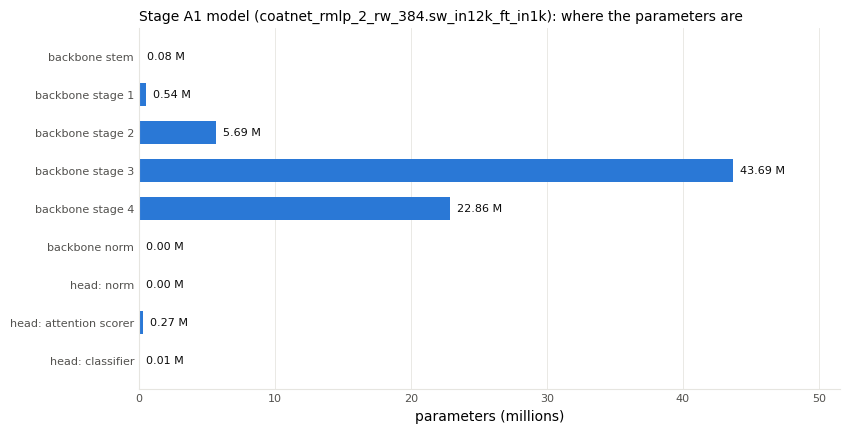

step,tensor shape,meaning
input: one study,"(1, 2, 3, 320, 320)","[study, window, channel = 3 neighbouring slices, height, width]"
windows as a batch of images,"(2, 3, 320, 320)",the backbone treats every window as one RGB-like image
after the stem,"(2, 128, 160, 160)","[image, channels, height, width]: fewer pixels, more channels"
after backbone stage 1,"(2, 128, 80, 80)","[image, channels, height, width]: fewer pixels, more channels"
after backbone stage 2,"(2, 256, 40, 40)","[image, channels, height, width]: fewer pixels, more channels"
after backbone stage 3,"(2, 512, 20, 20)","[image, channels, height, width]: fewer pixels, more channels"
after backbone stage 4,"(2, 1024, 10, 10)","[image, channels, height, width]: fewer pixels, more channels"
backbone output (pooled),"(1, 2, 1024)","[study, window, features]: ONE vector per window"
attention scores,"(1, 2, 12)","[study, window, finding]"
attention weights (softmax over windows),"(1, 2, 12)",for each finding the weights of all windows sum to 1


image size fed to the backbone: 320 x 320 px | feature vector per window: 1024 numbers


In [50]:
# ======================= A1 model tour: build the network WITHOUT weights and look inside =======================
def AX_param_table(parts, title):
    """parts: list of (name, what it does, module or tensor). Prints a table and draws where the parameters live."""
    def count(m):
        if isinstance(m, (list, tuple)):
            return int(sum(t.numel() for t in m))
        return int(sum(p.numel() for p in m.parameters())) if hasattr(m, "parameters") else int(m.numel())

    table = AX_pd.DataFrame([{"part": n, "what it does": w, "parameters": count(m)} for n, w, m in parts])
    total = int(table["parameters"].sum())
    table["share"] = (table["parameters"] / max(total, 1)).map("{:.1%}".format)
    table["parameters"] = table["parameters"].map("{:,}".format)
    AX_show(table, f"{title}: {total:,} parameters in total")
    sizes = [count(m) for _, _, m in parts]
    fig, ax = AX_plt.subplots(figsize=(8.6, 0.36 * len(parts) + 1.2))
    ax.barh(range(len(parts)), [s / 1e6 for s in sizes], color=AX_C["blue"], height=0.62)
    for y, s in enumerate(sizes):
        ax.text(s / 1e6, y, f"  {s / 1e6:.2f} M", va="center", fontsize=8, color=AX_C["ink"])
    ax.set_yticks(range(len(parts)), [p[0] for p in parts], fontsize=8); ax.invert_yaxis()
    ax.set_xlim(0, max(sizes) / 1e6 * 1.18); ax.set_xlabel("parameters (millions)")
    ax.set_title(f"{title}: where the parameters are", fontsize=10, loc="left")
    AX_style(ax); AX_plt.tight_layout(); AX_plt.show()
    return total


def AX_coatnet_tour(n_windows=2):
    """Same classes and the same architecture name as the real model, but random weights: this cell is about
    the STRUCTURE (which layers, how many numbers, which tensor shapes). Nothing here is used for predictions."""
    if AX_skip_while_scoring("A1 model tour"):
        return
    arch = ARMS[0]["arch"]
    backbone = build_backbone(arch, pretrained=False)
    model = RaptorClassifier(backbone, F_dim=backbone.num_features).eval()
    parts = []
    for name, child in backbone.named_children():
        if name == "stages":
            for i, stage in enumerate(child):
                blocks = list(getattr(stage, "blocks", stage))
                kinds = AX_pd.Series([type(b).__name__ for b in blocks]).value_counts()
                kind = ", ".join(f"{n} x {k}" for k, n in kinds.items())
                is_conv = any("Conv" in k for k in kinds.index)
                parts.append((f"backbone stage {i + 1}", f"{kind}  ({'convolution' if is_conv else 'self-attention'} blocks)", stage))
        elif sum(p.numel() for p in child.parameters()):
            parts.append((f"backbone {name}", {"stem": "first convolutions: pixels -> feature maps"}.get(name, type(child).__name__), child))
    parts += [("head: norm", "LayerNorm on each window's feature vector", model.norm),
              ("head: attention scorer", "per window: 12 scores, one per finding (Linear-Tanh-Dropout-Linear)", model.att),
              ("head: classifier", "12 weight vectors + 12 biases, one per finding", [model.clsW, model.clsb])]
    AX_param_table(parts, f"Stage A1 model ({arch})")

    # ---- follow the tensor shapes of one tiny study (n_windows three-slice windows) through the network ----
    shapes = []
    hooks = [backbone.stem.register_forward_hook(lambda m, i, o: shapes.append(("after the stem", tuple(o.shape))))]
    for i, stage in enumerate(backbone.stages):
        hooks.append(stage.register_forward_hook(lambda m, i_, o, i=i: shapes.append((f"after backbone stage {i + 1}", tuple(o.shape)))))
    x = AX_torch.zeros(1, n_windows, 3, INPUT_RES, INPUT_RES)
    try:
        with AX_torch.no_grad():
            feats = model.encode(x)
            h = model.norm(feats)
            scores = model.att(h)
            weights = AX_torch.softmax(scores, dim=1)
            pooled = AX_torch.einsum("bkn,bkf->bnf", weights, h)
            logits = (pooled * model.clsW).sum(-1) + model.clsb
    finally:
        for hk in hooks:
            hk.remove()
    rows = [("input: one study", tuple(x.shape), "[study, window, channel = 3 neighbouring slices, height, width]"),
            ("windows as a batch of images", (n_windows, 3, INPUT_RES, INPUT_RES), "the backbone treats every window as one RGB-like image")]
    rows += [(n, s, "[image, channels, height, width]: fewer pixels, more channels") for n, s in shapes]
    rows += [("backbone output (pooled)", tuple(feats.shape), "[study, window, features]: ONE vector per window"),
             ("attention scores", tuple(scores.shape), "[study, window, finding]"),
             ("attention weights (softmax over windows)", tuple(weights.shape), "for each finding the weights of all windows sum to 1"),
             ("pooled per finding", tuple(pooled.shape), "[study, finding, features]: 12 different summaries of the same study"),
             ("logits", tuple(logits.shape), "[study, finding]; sigmoid turns each into a probability")]
    AX_show(AX_pd.DataFrame(rows, columns=["step", "tensor shape", "meaning"]),
            f"Shapes for a study with {n_windows} windows (the real run uses {K_EVAL} windows per study)")
    print(f"image size fed to the backbone: {INPUT_RES} x {INPUT_RES} px | feature vector per window: {backbone.num_features} numbers")
    del model, backbone


with AX_cell("A1 model tour"):
    AX_coatnet_tour()

### A1 · windows, mirror and inference

`_mirror_tri` implements the anatomical mirror described above; `infer_pair_probs` averages the plain and the mirrored pass. `gpu_windows` builds the windows on the GPU through a 256-entry lookup table, which gives the same numbers as the CPU version without converting the whole volume to floating point.

In [51]:
%%branch_a A1 windows and inference
# ============================================================================
# Eval windowing -- verbatim from finetune_raptor.py StudyWindows (train=False)
# ============================================================================
def _eval_centers(mask, D, k):
    valid = np.where(mask > 0)[0]
    if len(valid) < 3:
        valid = np.arange(min(3, D))
    lo, hi = int(valid.min()), int(valid.max())
    cs = [c for c in range(lo + 1, hi) if c - 1 >= lo and c + 1 <= hi]
    if not cs:
        cs = [max(1, min((lo + hi) // 2, D - 2))]
    idx = np.linspace(0, len(cs) - 1, k).round().astype(int)
    return [cs[i] for i in idx]


SLOT_SIZES = [26, 22, 18, 12, 18]
SAGITTAL_SLOTS = (0, 1)

def _slot_index(D):
    b = np.cumsum([0] + SLOT_SIZES)
    if b[-1] != D: raise RuntimeError(f'slot sizes sum to {b[-1]}, volume has {D} slices')
    s_ = np.searchsorted(b, np.arange(D), side='right') - 1
    rel = (np.arange(D) - b[s_]) / np.maximum(1, np.array(SLOT_SIZES)[s_] - 1)
    return s_, rel

def _mirror_tri(tri, cs, D):
    """final-g1-bundle MIRROR_TTA: true L/R mirror of (k,3,H,W) uint8 eval triplets (research/rnd4/mirror/mirror_f0.py). The slot of each
    window's CENTRE slice decides the axis: sagittal (slots 0,1) -> reverse the 3 slice-channels; coronal/axial (2,3,4) -> flip the width.
    Done on uint8 BEFORE the per-channel LUT, i.e. 'mirror the knee, then normalise'."""
    s_, _ = _slot_index(D)
    sag = torch.from_numpy(np.isin(s_[np.asarray(cs, dtype=np.int64)], SAGITTAL_SLOTS)).to(tri.device).view(-1, 1, 1, 1)
    return torch.where(sag, tri.flip(1), tri.flip(-1))

def infer_pair_probs(model, plain, mirrored, device):
    assert plain.shape==mirrored.shape==(94,3,320,320)
    assert all(not m.training for m in model.modules()), "TTA must not update BN or enable dropout"
    p = infer_probs(model, plain, device)
    q = infer_probs(model, mirrored, device)
    return 0.5 * (p + q)

def eval_windows(vol, mask, k, res, norm=NORM, mirror=False):
    D = vol.shape[0]
    cs = _eval_centers(mask, D, k)
    wins = np.empty((len(cs), 3, res, res), np.float32)
    for j, c in enumerate(cs):
        c = max(1, min(c, D - 2))
        tri = np.stack([vol[c - 1], vol[c], vol[c + 1]], 0)
        if mirror:
            tri = _mirror_tri(torch.from_numpy(tri)[None], [c], D)[0].numpy()
        tri = tri.astype(np.float32) / 255.0
        assert tri.shape[-2:] == (IMG, IMG) and res == INPUT_RES
        lo = (IMG - res) // 2
        tri = tri[:, lo:lo + res, lo:lo + res]
        t = torch.from_numpy(np.ascontiguousarray(tri))
        if t.shape[-1] != res:
            t = F.interpolate(t[None], size=(res, res), mode="bilinear",
                              align_corners=False)[0]
        wins[j] = t.numpy()
    x = torch.from_numpy(wins)
    if norm == "imagenet":
        x = (x - _MEAN) / _STD
    return x


_WLUT = {}
def gpu_windows(vol, mask, k, res, dev, norm=NORM, mirror=False):
    """Same windows as eval_windows, built on the GPU from the uint8 volume. Values come from a per-channel
    256-entry table computed on the CPU with eval_windows' own float32 ops, so they are bit-identical."""
    D = vol.shape[0]
    cs = np.array([max(1, min(c, D - 2)) for c in _eval_centers(mask, D, k)])
    tri = torch.from_numpy(np.ascontiguousarray(vol[np.stack([cs - 1, cs, cs + 1], 1)])).to(dev)   # (k,3,IMG,IMG) uint8
    if mirror:
        tri = _mirror_tri(tri, cs, D)
    assert tri.shape[-2:] == (IMG, IMG) and res == INPUT_RES
    lo = (IMG - res) // 2
    tri = tri[:, :, lo:lo + res, lo:lo + res]
    key = (str(dev), norm)
    if key not in _WLUT:
        v = torch.from_numpy((np.arange(256, dtype=np.uint8).astype(np.float32) / 255.0))
        t = torch.stack([v, v, v], 0).view(3, 256, 1)
        if norm == 'imagenet':
            t = (t - _MEAN.view(3, 1, 1)) / _STD.view(3, 1, 1)
        _WLUT[key] = t.view(3, 256).contiguous().to(dev)
    L = _WLUT[key]
    x = torch.stack([L[c][tri[:, c].long()] for c in range(3)], 1)                   # exact float32 values
    if x.shape[-1] != res:
        if norm == 'imagenet':   # resize must happen BEFORE normalisation, as in eval_windows
            L0 = _WLUT.setdefault((str(dev), 'none'), torch.from_numpy(np.arange(256, dtype=np.uint8).astype(np.float32) / 255.0).to(dev))
            x = L0[tri.long()]
            x = F.interpolate(x, size=(res, res), mode='bilinear', align_corners=False)
            x = (x - _MEAN.to(dev)) / _STD.to(dev)
        else:
            x = F.interpolate(x, size=(res, res), mode='bilinear', align_corners=False)
    return x


@torch.no_grad()
def infer_probs(model, xwins, device):
    assert str(device).startswith("cuda"), "Qualified inference requires CUDA/fp16"
    x = xwins.unsqueeze(0).to(device)
    with torch.autocast("cuda", dtype=torch.float16):
        logits = model(x).float()
        assert torch.isfinite(logits).all(), "Nonfinite fp16 logits"
        o = torch.sigmoid(logits)
    return o[0].cpu().numpy()


def rankpct(x):                                   # per-column percentile rank in [0,1]
    order = x.argsort(0).argsort(0).astype(np.float64)
    return order / max(1, (x.shape[0] - 1))

[A1 windows and inference] ran in 0.0 s | defined functions: _eval_centers, _mirror_tri, _slot_index, eval_windows, gpu_windows, infer_pair_probs, infer_probs (+1 more) | settings: SAGITTAL_SLOTS, SLOT_SIZES


### A1 · reference preprocessing and the parallel reader hooks

`build_study` is the readable reference: pick a series per slot, sort, select, window, crop, resize. The run itself uses the faster embedded reader in worker processes.

In [52]:
%%branch_a A1 preprocessing
# ============================================================================
# Preprocessing -- verbatim from kprep2/dino_preprocess.py, retargeted to TEST
# ============================================================================
def _make_reader():
    import pydicom, cv2
    from pydicom.pixel_data_handlers.util import apply_modality_lut

    def _hdr(f):
        try:
            h = pydicom.dcmread(f, stop_before_pixels=True)
            iop = getattr(h, 'ImageOrientationPatient', None)
            ipp = getattr(h, 'ImagePositionPatient', None)
            if iop is not None and ipp is not None and len(iop) == 6:
                r = np.array(iop[:3], float); c = np.array(iop[3:], float)
                n = np.cross(r, c); pos = float(np.dot(np.array(ipp, float), n))
            else:
                pos = float(getattr(h, 'InstanceNumber', 0) or 0)
            ps = getattr(h, 'PixelSpacing', None); ps = float(ps[0]) if ps is not None else 0.5
            return (pos, f, ps, True)
        except Exception:
            return (0.0, f, 0.5, False)

    def order_and_meta(sdir):
        # Header reads are latency-bound on Kaggle's mounted competition data (~240k opens on the hidden
        # set); a thread pool hides that latency. Records and sort are unchanged -> identical ordering.
        fs = glob.glob(sdir + "/*.dcm")
        with ThreadPoolExecutor(max_workers=HDR_THREADS) as ex:
            out = list(ex.map(_hdr, fs))
        recs = [(pos, f, ps) for pos, f, ps, _ in out]; ps_list = [ps for _, _, ps, ok in out if ok]
        recs.sort(key=lambda x: x[0])
        med_ps = float(np.median(ps_list)) if ps_list else 0.5
        return [(f, ps) for _, f, ps in recs], med_ps

    def read_px(f):
        d = pydicom.dcmread(f)
        a = apply_modality_lut(d.pixel_array, d).astype(np.float32)
        if str(getattr(d, 'PhotometricInterpretation', '')) == 'MONOCHROME1':
            a = a.max() - a
        return a

    def mm_crop_resize(a, ps):
        h, w = a.shape; cpx = int(round(CROP_MM / max(ps, 1e-3)))
        cpx = min(cpx, min(h, w)); y0 = (h - cpx) // 2; x0 = (w - cpx) // 2
        a = a[y0:y0 + cpx, x0:x0 + cpx]
        return cv2.resize(a, (IMG, IMG), interpolation=cv2.INTER_AREA)

    return order_and_meta, read_px, mm_crop_resize


def _pick_series_for_slot(rows, plane, fluid, used):
    cands = [r for r in rows if r['Anatomical_Plane'] == plane and r['SeriesInstanceUID'] not in used]
    if fluid in (0, 1):
        pref = [r for r in cands if int(r.get('Fluid_Sensitive', 0) or 0) == fluid]
        if pref:
            return pref[0]
    return cands[0] if cands else None


def build_study(sid, ser_records, tsdir, reader):
    order_and_meta, read_px, mm_crop_resize = reader
    rows = ser_records.get(sid, [])
    vol = np.zeros((MAXS, IMG, IMG), np.uint8); idx = 0; used = set()
    for plane, fluid, k in SLOTS:
        r = _pick_series_for_slot(rows, plane, fluid, used)
        if r is None:
            idx += k; continue
        used.add(r['SeriesInstanceUID'])
        files, med_ps = order_and_meta(f"{tsdir}/{sid}/{r['SeriesInstanceUID']}")
        if not files:
            idx += k; continue
        # wide span: the collateral ligaments and lateral meniscus live in the
        # peripheral slices the old 0.15-0.85 crop threw away. Must match the corpus
        # the weights were trained on (build_corpus80.py, SPAN).
        n = len(files); lo, hi = int(n * 0.02), int(n * 0.98) - 1; hi = max(hi, lo)
        picks = np.linspace(lo, hi, k).round().astype(int) if n > 1 else [0] * k
        sel = [files[min(p, n - 1)] for p in picks]
        def _px(fp_ps):
            fp, ps = fp_ps
            try: return read_px(fp), ps
            except Exception: return None, med_ps
        with ThreadPoolExecutor(max_workers=PX_THREADS) as ex:
            got = list(ex.map(_px, sel))                    # order preserved
        arrs = [a for a, _ in got]; pss = [ps for _, ps in got]
        valid = [a for a in arrs if a is not None]
        if valid:
            allpx = np.concatenate([a.ravel() for a in valid])
            loq, hiq = np.percentile(allpx, [2.0, 98.0])
        else:
            loq, hiq = 0.0, 1.0
        for a, ps in zip(arrs, pss):
            if idx >= MAXS: break
            if a is None: idx += 1; continue
            aw = np.clip((a - loq) / (hiq - loq + 1e-6), 0, 1)
            aw = mm_crop_resize(aw, ps if ps > 0 else med_ps)
            vol[idx] = (aw * 255).astype(np.uint8); idx += 1
        if idx >= MAXS: break
    mask = (vol.reshape(MAXS, -1).sum(1) > 0).astype(np.uint8)
    return vol, mask



# ---- parallel preprocessing helpers (module level so they pickle under fork) ----
_SER = None; _TSDIR = None; _READER = None
def _pre_init():
    global _READER
    _READER = _load_fastread().make_builder(FASTREAD_VARIANT, IMG, SLOTS, hdr_threads=FR_HDR, px_threads=FR_PX)
def _pre_one(sid):
    try:
        vol, mask = _READER(sid, _SER, _TSDIR)
    except Exception as e:
        print(f"  [pre] {sid[:16]} FAILED ({type(e).__name__}: {e})", flush=True)
        vol = np.zeros((MAXS, IMG, IMG), np.uint8); mask = np.zeros(MAXS, np.uint8)
    return sid, vol, mask

[A1 preprocessing] ran in 0.0 s | defined functions: _make_reader, _pick_series_for_slot, _pre_init, _pre_one, build_study


### A1 · input discovery and the main loop

Worker processes decode studies and hand them through a queue to one inference thread per GPU. **[edit 1]** lets validate mode redirect the input; **[edit 3]** saves the raw probabilities.

In [53]:
%%branch_a A1 main loop
# ============================================================================
# Test-root discovery + weights + main
# ============================================================================
def find_test_root():
    # [edit 1] validate mode points RSNA_COMP_ROOT at a stand-in folder; unset in a normal run
    if os.environ.get("RSNA_COMP_ROOT") and os.path.exists(os.environ["RSNA_COMP_ROOT"] + "/test.csv"):
        return os.environ["RSNA_COMP_ROOT"]
    cands = ["/kaggle/input/competitions/rsna-knee-abnormality-detection",
             "/kaggle/input/rsna-knee-abnormality-detection"]
    for b in cands:
        if os.path.exists(b + "/test.csv"):
            return b
    for d, _, f in os.walk("/kaggle/input"):
        if "test.csv" in f and (os.path.isdir(d + "/test_series") or os.path.isdir(d + "/test_images")):
            return d
    for d, _, f in os.walk("/kaggle/input"):
        if "test.csv" in f:
            return d
    raise RuntimeError("no test root under /kaggle/input")


def find_weight_file(fname):
    # direct dataset mounts first; NEVER recursive-glob the competitions DICOM tree.
    direct = [f"/kaggle/input/raptor-knee-arms/{fname}",
              f"/kaggle/input/raptor-knee-arms/1/{fname}",
              f"/kaggle/input/raptor-cnn336/{fname}"]
    for p in direct:
        if os.path.exists(p):
            return p
    for d in sorted(glob.glob("/kaggle/input/*/")):
        # skip the competition data wherever Kaggle mounts it (/kaggle/input/competitions/<slug> OR /kaggle/input/<slug>):
        # recursively globbing its DICOM tree hung a commit run for 20+ min (2026-09-26)
        if "competition" in d.lower() or "abnormality-detection" in d or any(
                os.path.exists(os.path.join(d, x)) for x in ("test_series", "train_images", "train.csv", "test.csv")):
            continue
        hits = glob.glob(os.path.join(d, "**", fname), recursive=True)
        if hits:
            return hits[0]
    raise RuntimeError(f"{fname} not found under /kaggle/input")


def main():
    import pandas as pd
    t0 = time.time()
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    ngpu = torch.cuda.device_count()
    print(f"device {dev} | gpus {ngpu} | torch {torch.__version__}", flush=True)

    ROOT = find_test_root()
    tsdir = ROOT + "/test_series"
    if not os.path.isdir(tsdir):
        tsdir = ROOT + "/test_images"
    print("test root:", ROOT, "| series dir:", tsdir, flush=True)

    test = pd.read_csv(ROOT + "/test.csv"); test["StudyInstanceUID"] = test["StudyInstanceUID"].astype(str)
    test_ids = test["StudyInstanceUID"].tolist()
    tser = pd.read_csv(ROOT + "/test_series.csv")
    tser["StudyInstanceUID"] = tser["StudyInstanceUID"].astype(str)
    tser["SeriesInstanceUID"] = tser["SeriesInstanceUID"].astype(str)
    SER = {k: v.to_dict("records") for k, v in tser.groupby("StudyInstanceUID")}
    print(f"test studies {len(test_ids)} | test series {len(tser)}", flush=True)

    sub_cols = ["StudyInstanceUID"] + LAB
    ssub = os.path.join(ROOT, "sample_submission.csv")
    if os.path.exists(ssub):
        sub_cols = list(pd.read_csv(ssub, nrows=1).columns)

    N = len(test_ids); A = len(ARMS)
    arm_probs = [np.full((N, len(LAB)), 0.5, np.float32) for _ in range(A)]
    pos = {sid: i for i, sid in enumerate(test_ids)}

    # ---- 2. GPU consumers: one thread per GPU, every arm loaded on every GPU (per-study batch of 1,
    #         so the math is identical to the sequential kernel; only the wall-clock changes) ----
    xla = None
    try:
        import torch_xla; import torch_xla.core.xla_model as xm
        dev = torch_xla.device(); xla = xm
        print("device: XLA/TPU", dev, flush=True)
    except Exception as e:
        print("XLA unavailable:", type(e).__name__, str(e)[:80], "| device", dev, flush=True)
    devs = [f"cuda:{g}" for g in range(ngpu)] if (xla is None and ngpu > 0) else [dev]
    models = {}
    for d in devs:
        models[d] = []
        for a, arm in enumerate(ARMS):
            model, res = load_model(find_weight_file(arm["file"]), arm["arch"], arm["res"], d)
            models[d].append((model, res))
        print(f"[gpu {d}] loaded {A} arm(s) | {time.time()-t0:.0f}s", flush=True)
    q = queue.Queue(maxsize=QUEUE_MAX); done_n = [0]; lock = threading.Lock()

    def consumer(d):
        while True:
            item = q.get()
            if item is None: q.task_done(); return
            sid, vol, mask = item; i = pos[sid]
            try:
                for a, (model, res) in enumerate(models[d]):
                    xw = eval_windows(vol, mask, k=K_EVAL, res=res, norm=NORM) if xla is not None else gpu_windows(vol, mask, K_EVAL, res, d)
                    assert xla is None, "Anatomical L/R TTA requires CUDA/fp16"
                    xm = gpu_windows(vol, mask, K_EVAL, res, d, norm=NORM, mirror=True)
                    arm_probs[a][i] = infer_pair_probs(model, xw, xm, d)
                    del xm
            except Exception as e:
                print(f"  [gpu {d}] study {i} {sid[:16]} FALLBACK ({type(e).__name__}: {e})", flush=True)
            with lock:
                done_n[0] += 1
                if done_n[0] % 200 == 0 or done_n[0] == N:
                    print(f"  [gpu] {done_n[0]}/{N} | {time.time()-t0:.0f}s", flush=True)
            q.task_done()

    threads = [threading.Thread(target=consumer, args=(d,), daemon=True) for d in devs]
    for th in threads: th.start()

    # ---- 3. prep every study ONCE in a process pool and stream it to the GPUs as it lands ----
    import multiprocessing as mp
    global _SER, _TSDIR, _READER
    _SER, _TSDIR = SER, tsdir
    nproc = max(4, min(96, (os.cpu_count() or 8) - 8))
    t_pre = time.time()
    with mp.get_context("fork").Pool(nproc, initializer=_pre_init) as pool:
        for i, (sid, vol, mask) in enumerate(pool.imap_unordered(_pre_one, test_ids, chunksize=2)):
            q.put((sid, vol, mask))
            if (i + 1) % 200 == 0 or i + 1 == N:
                print(f"  [pre] {i+1}/{N} | {time.time()-t0:.0f}s", flush=True)
    print(f"[pre] done: {N} studies in {time.time()-t_pre:.0f}s (procs {nproc} x fastread {FASTREAD_VARIANT} {FR_HDR}/{FR_PX} threads)", flush=True)
    for _ in devs: q.put(None)
    q.join()
    for th in threads: th.join()
    print(f"[gpu] done: {done_n[0]}/{N} studies on {len(devs)} device(s) | {time.time()-t0:.0f}s", flush=True)
    for d in devs:
        for m, _ in models[d]: del m
    models.clear(); gc.collect()
    try:   # [edit 3] keep the raw probabilities for the diagnostics in Part H; predictions are unaffected
        np.savez_compressed("/kaggle/working/_coatnet_raw.npz", study_uids=np.asarray(test_ids), values=np.stack(arm_probs))
    except Exception as _diag_error:
        print("[diagnostics] raw probabilities not saved:", _diag_error, flush=True)

    # WEIGHTED rank-mean blend across the test set, per finding (the offline recipe).
    # Weights come from ARMS[*]["w"] and are normalised here, so dropping/adding an arm can
    # never silently change the scale. Falls back to equal weights if none are declared.
    _w = np.array([float(a.get("w", 1.0)) for a in ARMS], dtype=np.float64)
    _w = _w / _w.sum()
    print(f"[blend] weighted rank-mean w={dict(zip([a['file'] for a in ARMS], _w.round(4)))}", flush=True)
    ranks = np.tensordot(_w, np.stack([rankpct(np.clip(p, 0, 1)) for p in arm_probs]),
                         axes=(0, 0))                                          # (N,12) in [0,1]
    if not np.isfinite(ranks).all():
        ranks[~np.isfinite(ranks)] = 0.5

    sub = pd.DataFrame(ranks.astype(np.float32), columns=LAB)
    sub.insert(0, "StudyInstanceUID", test_ids)
    sub = sub[sub_cols]
    assert list(sub.columns) == sub_cols, "column order drift"
    assert sub["StudyInstanceUID"].tolist() == test_ids, "row identity drift"
    assert np.isfinite(sub[LAB].values).all()
    out = "/kaggle/working/submission.csv"
    sub.to_csv(out, index=False)
    sub.to_csv("/kaggle/working/_sota_0949.csv", index=False)
    print("Saved SOTA 0.949 backup to /kaggle/working/_sota_0949.csv", flush=True)
    print("wrote", out, "|", len(sub), "rows x", len(sub.columns), "cols", flush=True)
    print(sub.head().to_string(index=False), flush=True)
    print(f"DONE {time.time()-t0:.0f}s", flush=True)

[A1 main loop] ran in 0.0 s | defined functions: find_test_root, find_weight_file, main


### A1 · run

This is the first cell that takes real time: it decodes and predicts every test study.

In [54]:
%%branch_a A1 run CoAtNet
if __name__ == "__main__":
    main()

device cuda | gpus 2 | torch 2.11.0+cu128
test root: /kaggle/input/competitions/rsna-knee-abnormality-detection | series dir: /kaggle/input/competitions/rsna-knee-abnormality-detection/test_series
test studies 3 | test series 15
XLA unavailable: ModuleNotFoundError No module named 'torch_xla' | device cuda
[weights] sha256 7e5315dad125b99fc65b340b3de41de628e9be51ff5835355dd61c86472244ef
[gpu cuda:0] loaded 1 arm(s) | 2s
[weights] sha256 7e5315dad125b99fc65b340b3de41de628e9be51ff5835355dd61c86472244ef
[gpu cuda:1] loaded 1 arm(s) | 5s
  [pre] 3/3 | 6s
[pre] done: 3 studies in 2s (procs 4 x fastread study_lut 32/16 threads)
  [gpu] 3/3 | 19s
[gpu] done: 3/3 studies on 2 device(s) | 19s
[blend] weighted rank-mean w={'raptor_ft_alldata_t16_blendjev_oai_d96_r384_swa.pt': np.float64(1.0)}
Saved SOTA 0.949 backup to /kaggle/working/_sota_0949.csv
wrote /kaggle/working/submission.csv | 3 rows x 13 cols
                                                StudyInstanceUID  ACL  MCL  Medial Meniscus 

### A1 review: inputs and outputs (new)

**Figure 1** rebuilds the 96-slice input of the first test study with the reference reader. The orange box is the central crop the network receives. **Figure 2** shows the mirror on one image. **Figure 3** shows which slices of each series were read. The last figure is the spread of predicted probabilities per finding.

study 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191: volume (96, 384, 384) (84 of 96 slices filled) | image 384px, model sees the central 320px | 94 three-slice windows, each predicted twice (as is, and mirrored)


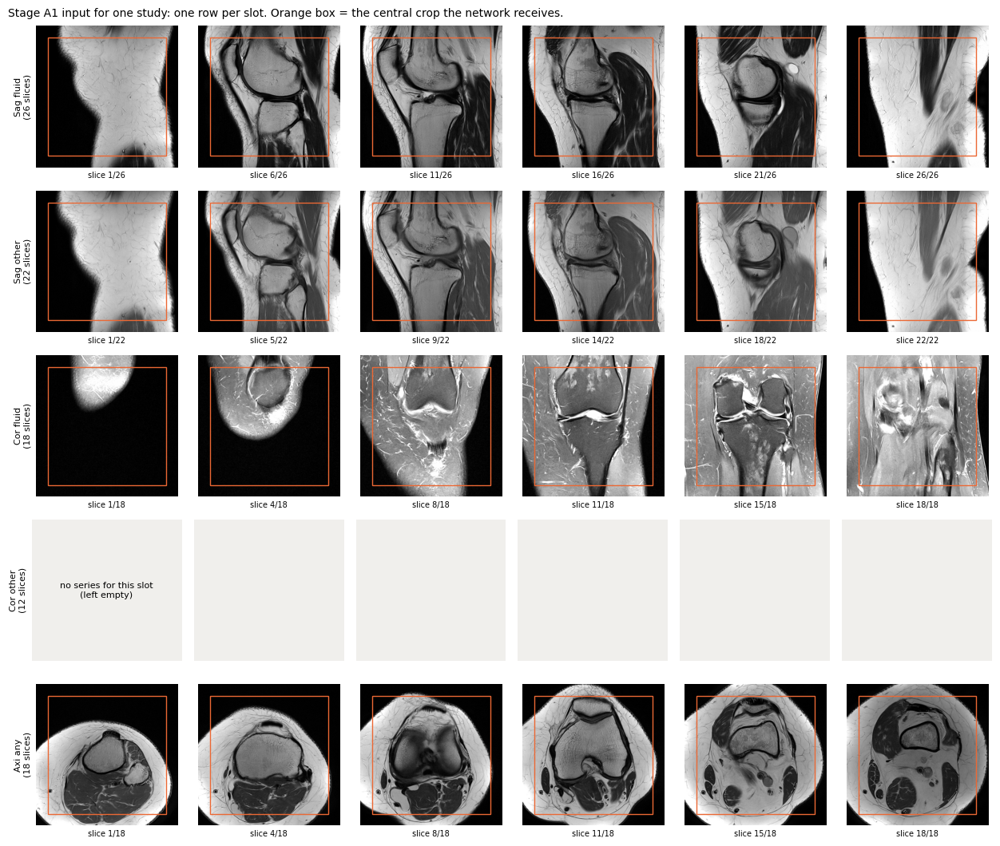

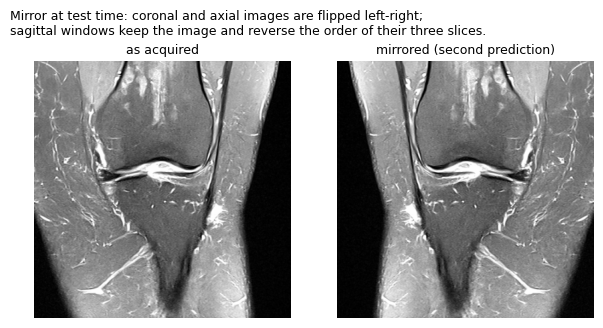

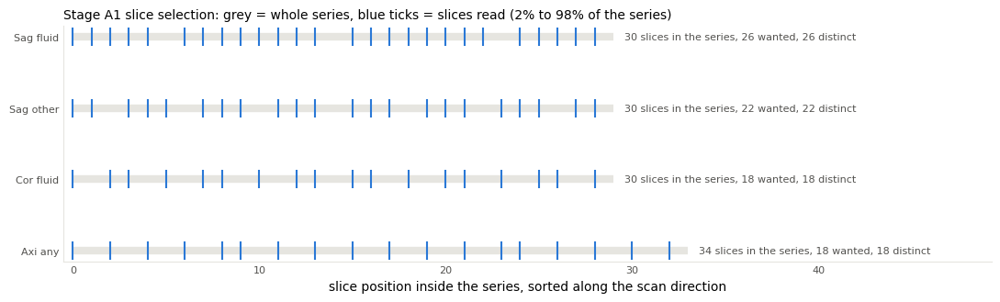

stage A1: 3 studies | probability range 0.098 - 0.954 | studies left at the neutral value 0.5 because inference failed: 0


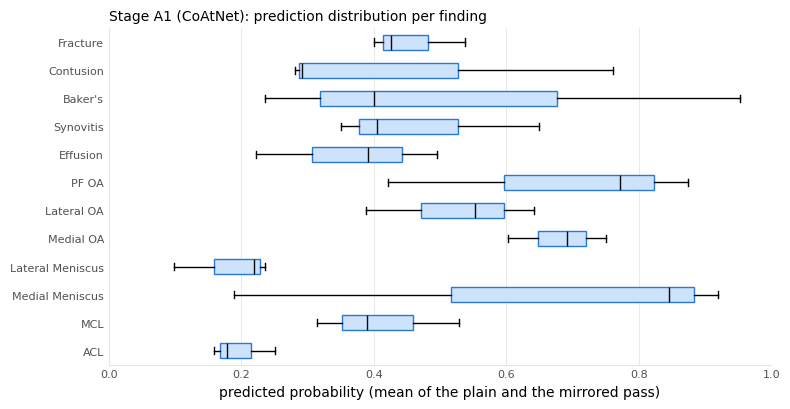

In [55]:
# ======================= Stage A1 review: what the CoAtNet was shown =======================
def AX_a1_inputs(study_index=0, n_cols=6):
    """Rebuild the 96-slice input of ONE test study with the reference reader defined above (no model is run)."""
    root = find_test_root()
    tsdir = root + "/test_series"
    tser = AX_pd.read_csv(root + "/test_series.csv", dtype={AX_UID: str, "SeriesInstanceUID": str})
    ser = {k: v.to_dict("records") for k, v in tser.groupby(AX_UID)}
    sid = AX_test_ids()[study_index]
    vol, mask = build_study(sid, ser, tsdir, _make_reader())
    bounds = AX_np.cumsum([0] + [s[2] for s in SLOTS])
    names = [f"{p[:3]} {'fluid' if f == 1 else 'other' if f == 0 else 'any'}" for p, f, _ in SLOTS]
    print(f"study {sid}: volume {vol.shape} ({int(mask.sum())} of {len(mask)} slices filled) | image {IMG}px, model sees the "
          f"central {INPUT_RES}px | {K_EVAL} three-slice windows, each predicted twice (as is, and mirrored)")
    lo = (IMG - INPUT_RES) // 2
    fig, axes = AX_plt.subplots(len(SLOTS), n_cols, figsize=(2.1 * n_cols, 2.15 * len(SLOTS)), squeeze=False)
    for r, name in enumerate(names):
        a, b = bounds[r], bounds[r + 1]
        show = AX_np.linspace(a, b - 1, n_cols).round().astype(int)
        for c, k in enumerate(show):
            ax = axes[r][c]; ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_visible(False)
            if mask[a:b].sum() == 0:
                ax.set_facecolor("#f0efec")
                if c == 0:
                    ax.text(0.5, 0.5, "no series for this slot\n(left empty)", ha="center", va="center", fontsize=8, transform=ax.transAxes)
            else:
                ax.imshow(vol[k], cmap="gray", vmin=0, vmax=255)
                ax.add_patch(AX_plt.Rectangle((lo, lo), INPUT_RES, INPUT_RES, fill=False, edgecolor=AX_C["orange"], linewidth=1))
                ax.set_xlabel(f"slice {k - a + 1}/{b - a}", fontsize=7)
            if c == 0:
                ax.set_ylabel(f"{name}\n({b - a} slices)", fontsize=8)
    fig.suptitle("Stage A1 input for one study: one row per slot. Orange box = the central crop the network receives.",
                 fontsize=10, x=0.01, ha="left")
    AX_plt.tight_layout(); AX_plt.show()

    # the left/right mirror used at test time, on one coronal slice (falls back to any filled slice)
    cor = [k for k in range(bounds[2], bounds[4]) if mask[k]] or [k for k in range(len(mask)) if mask[k]]
    if cor:
        k = cor[len(cor) // 2]
        fig, ax = AX_plt.subplots(1, 2, figsize=(6.2, 3.3))
        ax[0].imshow(vol[k], cmap="gray", vmin=0, vmax=255); ax[0].set_title("as acquired", fontsize=9)
        ax[1].imshow(vol[k][:, ::-1], cmap="gray", vmin=0, vmax=255); ax[1].set_title("mirrored (second prediction)", fontsize=9)
        for a_ in ax:
            a_.axis("off")
        fig.suptitle("Mirror at test time: coronal and axial images are flipped left-right;\n"
                     "sagittal windows keep the image and reverse the order of their three slices.", fontsize=9, x=0.01, ha="left")
        AX_plt.tight_layout(); AX_plt.show()

    # slice selection: which files of each series were read
    rows, used = [], set()
    for (plane, fluid, k), name in zip(SLOTS, names):
        rec = _pick_series_for_slot(ser.get(sid, []), plane, fluid, used)
        if rec is None:
            continue
        used.add(rec["SeriesInstanceUID"])
        n = len(glob.glob(f"{tsdir}/{sid}/{rec['SeriesInstanceUID']}/*.dcm"))
        if n:
            a, b = int(n * 0.02), max(int(n * 0.98) - 1, int(n * 0.02))
            rows.append((name, n, AX_np.unique(AX_np.linspace(a, b, k).round().astype(int)), k))
    if rows:
        fig, ax = AX_plt.subplots(figsize=(11, 0.5 * len(rows) + 1.4))
        for y, (name, n, picks, k) in enumerate(rows):
            ax.hlines(y, 0, n - 1, color=AX_C["grid"], lw=6)
            ax.plot(picks, [y] * len(picks), "|", color=AX_C["blue"], ms=14, mew=1.5)
            ax.text(n - 1 + 0.6, y, f"{n} slices in the series, {k} wanted, {len(picks)} distinct", va="center", fontsize=8, color=AX_C["muted"])
        ax.set_yticks(range(len(rows)), [r[0] for r in rows], fontsize=8); ax.invert_yaxis()
        ax.set_xlim(-0.5, max(r[1] for r in rows) * 1.45)
        ax.set_xlabel("slice position inside the series, sorted along the scan direction")
        ax.set_title("Stage A1 slice selection: grey = whole series, blue ticks = slices read (2% to 98% of the series)", fontsize=10, loc="left")
        AX_style(ax, None); AX_plt.tight_layout(); AX_plt.show()
        if any(len(r[2]) < r[3] for r in rows):
            print("A series with fewer slices than its slot wants is read completely and some slices are repeated.")


def AX_a1_outputs():
    """Raw probabilities of stage A1, and how many studies fell back to the neutral value."""
    f = AX_A_FILES["coatnet_raw"]
    if not f.is_file():
        print("raw probabilities of stage A1 were not saved"); return
    p = AX_np.load(f, allow_pickle=False)["values"][0]
    neutral = int((p == 0.5).all(axis=1).sum())
    print(f"stage A1: {len(p):,} studies | probability range {p.min():.3f} - {p.max():.3f} | "
          f"studies left at the neutral value 0.5 because inference failed: {neutral}")
    fig, ax = AX_plt.subplots(figsize=(8, 4.2))
    bp = ax.boxplot([p[:, j] for j in range(p.shape[1])], vert=False, tick_labels=AX_LAB, widths=0.55, patch_artist=True,
                    medianprops=dict(color=AX_C["ink"]), flierprops=dict(marker=".", ms=3, mec=AX_C["grey"]))
    for b in bp["boxes"]:
        b.set(facecolor="#cde2fb", edgecolor=AX_C["blue"])
    ax.set_xlim(0, 1); ax.set_xlabel("predicted probability (mean of the plain and the mirrored pass)")
    ax.set_title("Stage A1 (CoAtNet): prediction distribution per finding", fontsize=10, loc="left")
    AX_style(ax); AX_plt.tight_layout(); AX_plt.show()


with AX_cell("stage A1 inputs"):
    AX_a1_inputs()
with AX_cell("stage A1 outputs"):
    AX_a1_outputs()

### A1 · attention: which slices does each finding rely on? (new)

**What.** Loads the trained CoAtNet once more, runs the first test study through it and reads out the attention weights: for every finding, one weight per window, summing to 1.

**How to read the figures.**
- *Heatmap*: one row per finding, one column per window, grouped by slot. The value is the weight relative to an equal share, so 1 means "no preference". Rows that are dark in a few columns belong to findings the model decides on a few slices.
- *Table*: the same weights summed per slot. It answers "which series does the model use for which finding".
- *Image rows*: the windows with the largest weight for three findings.

**What it does and does not show.** Attention tells where the model takes its evidence from. It does not prove that the model looks at the right structure, and one study is an illustration, not a result.

[weights] sha256 7e5315dad125b99fc65b340b3de41de628e9be51ff5835355dd61c86472244ef
study 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191: 94 windows | attention weights per finding sum to 1.000
12 windows are black images: this study has no series for the slot(s) ['Cor other']. The model receives them as they are.


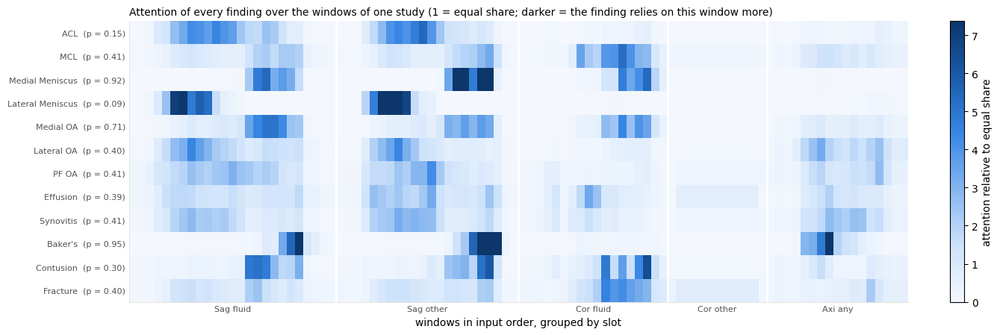

,Sag fluid,Sag other,Cor fluid,Cor other,Axi any
ACL,0.489,0.440,0.030,0.006,0.036
MCL,0.243,0.243,0.356,0.024,0.135
Medial Meniscus,0.264,0.482,0.248,0.001,0.006
Lateral Meniscus,0.390,0.590,0.006,0.003,0.011
Medial OA,0.373,0.283,0.245,0.006,0.093
Lateral OA,0.394,0.292,0.046,0.008,0.259
PF OA,0.388,0.325,0.059,0.033,0.195
Effusion,0.278,0.341,0.166,0.070,0.145
Synovitis,0.300,0.334,0.102,0.030,0.235
Baker's,0.232,0.479,0.023,0.006,0.261


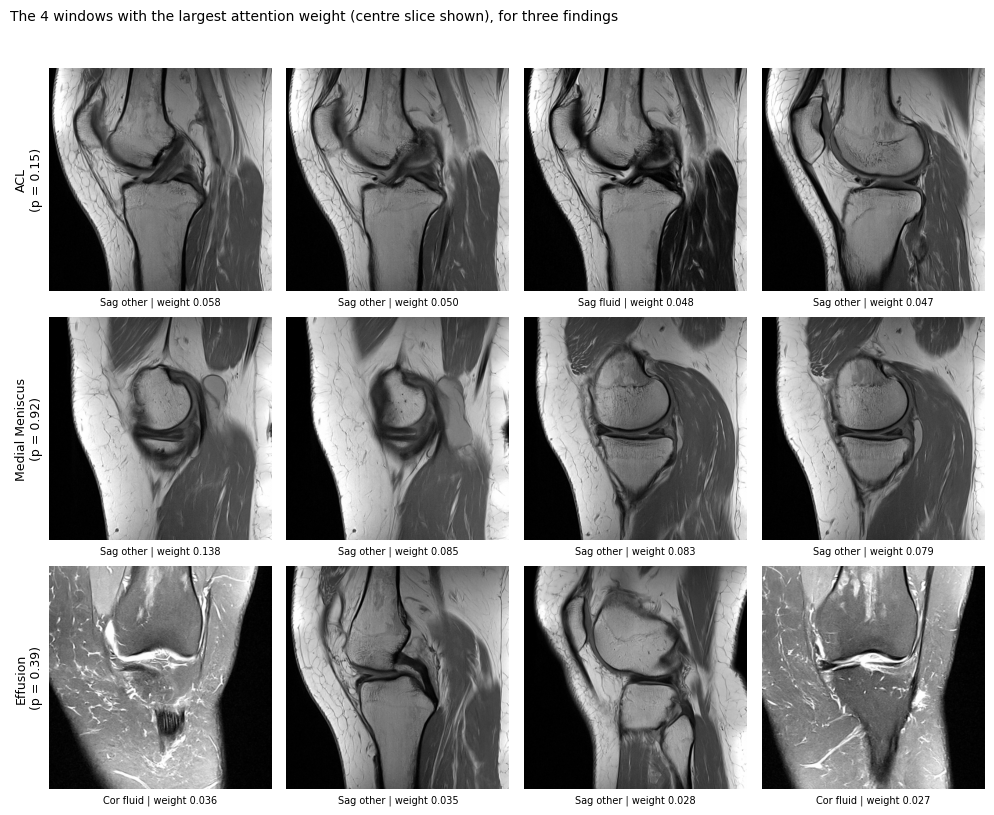

Attention shows WHERE the model takes its evidence from. It is not a proof that the model sees the right structure, and with only a few test studies visible here it is an illustration, not an evaluation.


In [56]:
# ======================= A1 attention: which slices does each finding look at? =======================
def AX_coatnet_attention(study_index=0, findings=("ACL", "Medial Meniscus", "Effusion"), top=4):
    """Load the real CoAtNet once more, run ONE test study through it and read out the attention weights
    (one weight per window and finding). Teaching only: the predictions above are already saved."""
    if AX_skip_while_scoring("A1 attention"):
        return
    root = find_test_root()
    tsdir = root + "/test_series"
    tser = AX_pd.read_csv(root + "/test_series.csv", dtype={AX_UID: str, "SeriesInstanceUID": str})
    ser = {k: v.to_dict("records") for k, v in tser.groupby(AX_UID)}
    sid = AX_test_ids()[study_index]
    vol, mask = build_study(sid, ser, tsdir, _make_reader())            # the same 96-slice input as in the review above
    D = vol.shape[0]
    centres = AX_np.array([max(1, min(c, D - 2)) for c in _eval_centers(mask, D, K_EVAL)])
    slot_of_window = _slot_index(D)[0][centres]
    model = None
    try:
        model, res = load_model(find_weight_file(ARMS[0]["file"]), ARMS[0]["arch"], ARMS[0]["res"], AX_DEV)
        windows = gpu_windows(vol, mask, K_EVAL, res, AX_DEV)           # [94, 3, 320, 320], normalised
        with AX_torch.no_grad(), AX_torch.autocast("cuda", dtype=AX_torch.float16, enabled=AX_DEV == "cuda"):
            feats = model.encode(windows.unsqueeze(0))
            h = model.norm(feats)
            att = AX_torch.softmax(model.att(h).float(), dim=1)[0].cpu().numpy()        # [94 windows, 12 findings]
            prob = AX_torch.sigmoid(model.head(feats).float())[0].cpu().numpy()
    finally:
        del model
        AX_free_gpu()
    names = [f"{p[:3]} {'fluid' if f == 1 else 'other' if f == 0 else 'any'}" for p, f, _ in SLOTS]
    share = AX_pd.DataFrame({names[s]: att[slot_of_window == s].sum(0) for s in range(len(SLOTS))}, index=AX_LAB)
    filled = mask[centres] > 0                                          # False for windows inside a slot without a series
    print(f"study {sid}: {len(centres)} windows | attention weights per finding sum to {att.sum(0).mean():.3f}")
    if not filled.all():
        empty = sorted({names[int(s)] for s in slot_of_window[~filled]})
        print(f"{int((~filled).sum())} windows are black images: this study has no series for the slot(s) {empty}. "
              "The model receives them as they are.")

    rel = att.T * len(centres)                                           # 1.0 = this window got exactly its equal share
    fig, ax = AX_plt.subplots(figsize=(13.5, 4.6))
    im = ax.imshow(rel, aspect="auto", cmap=AX_SEQ, vmin=0, vmax=max(3.0, float(AX_np.percentile(rel, 99))))
    ax.set_yticks(range(len(AX_LAB)), [f"{l}  (p = {p:.2f})" for l, p in zip(AX_LAB, prob)], fontsize=8)
    edges = [0] + [int(i) + 1 for i in AX_np.flatnonzero(AX_np.diff(slot_of_window))] + [len(centres)]
    for e in edges[1:-1]:
        ax.axvline(e - 0.5, color="white", lw=2)
    ax.set_xticks([(a + b - 1) / 2 for a, b in zip(edges[:-1], edges[1:])],
                  [names[int(slot_of_window[a])] for a in edges[:-1]], fontsize=8)
    ax.set_xlabel("windows in input order, grouped by slot")
    ax.set_title("Attention of every finding over the windows of one study (1 = equal share; darker = the finding relies on this window more)",
                 fontsize=10, loc="left")
    AX_style(ax, None); fig.colorbar(im, ax=ax, fraction=0.025, label="attention relative to equal share")
    AX_plt.tight_layout(); AX_plt.show()

    AX_show(share.round(3), "Share of each finding's attention that goes to each slot (rows sum to 1)")

    fig, axes = AX_plt.subplots(len(findings), top, figsize=(2.5 * top, 2.75 * len(findings)), squeeze=False)
    for r, finding in enumerate(findings):
        j = AX_LAB.index(finding)
        for c, w in enumerate(AX_np.argsort(-AX_np.where(filled, att[:, j], -1.0))[:top]):
            ax = axes[r][c]; ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(False)
            ax.imshow(vol[centres[w]], cmap="gray", vmin=0, vmax=255)
            ax.set_xlabel(f"{names[int(slot_of_window[w])]} | weight {att[w, j]:.3f}", fontsize=7)
            if c == 0:
                ax.set_ylabel(f"{finding}\n(p = {prob[j]:.2f})", fontsize=9)
    fig.suptitle(f"The {top} windows with the largest attention weight (centre slice shown), for three findings",
                 fontsize=10, x=0.01, ha="left")
    AX_plt.tight_layout(rect=(0, 0, 1, 0.97)); AX_plt.show()
    print("Attention shows WHERE the model takes its evidence from. It is not a proof that the model sees the right "
          "structure, and with only a few test studies visible here it is an illustration, not an evaluation.")


with AX_cell("A1 attention"):
    AX_coatnet_attention()

## Stage A2 — ConvNeXt 2.5D reader

**Why a second model.** It reads the study differently from the CoAtNet: other slots, another orientation convention, another crop, another way of combining windows. Different readings make different mistakes, which is what a blend needs.

**Preprocessing (`preprocess.py`).**
- Every series is brought into a *canonical orientation* using the direction vectors in the DICOM header, so that for example every sagittal image has the front of the knee on the same side.
- Images are resampled to 0.4 mm per pixel and centre-cropped or padded to 384 × 384 px (153.6 mm).
- Slices are sorted by physical position, at most 64 are kept, and intensities are clipped to the 1st–99.5th percentile of the series.
- Left and right knees are **not** mirrored onto each other here (Branch B does that; this model was trained without it).

**Slots (`knee.py`).** Six slots: three planes × fat-suppressed or not. If a plane lacks one of the two contrasts, the other contrast is used for both slots. Each slot contributes 16 windows of three neighbouring slices.

**Architecture (`KneeNet`).**
- A 2-D image backbone from `timm` (named in the checkpoint; the files are called `cnxt_…`, for ConvNeXt, a modern pure-convolution network) turns each window into a feature vector.
- Each vector gets two additions: an embedding of its *slot* and an embedding of its *position* along the series.
- A small transformer (2 layers) lets all windows of the study exchange information.
- As in A1, attention pooling with separate weights per finding produces the 12 scores.

**Test-time augmentation (`infer.py`).** Every window is predicted **8 times**: two image sizes (256 and 320 px) × plain or flipped left–right × two slice offsets (the window centres shifted by one slice). All checkpoints found in the dataset are averaged.

**A caution about the flip.** The flip mirrors the image width in *all* slots. For coronal and axial images that turns a left knee into a right knee, which the network has seen. For sagittal images it swaps front and back, which the canonical orientation never produces in training. Half of the sagittal evidence in the average therefore comes from images of a kind the network was not trained on. Stage A1 handles the same situation differently (it reverses the slice order instead). This notebook keeps the public notebook's behaviour, because that is what was scored; whether an anatomical mirror would do better is a question for validate mode.

**Effect on predictions.** Enters the fusion with 4 % to 48 % weight, depending on the finding.

### A2 · a folder for the reader's source files

The reader runs as a separate Python process, so its three source files are written to `/kaggle/working/own_src` first.

In [57]:
import os
os.makedirs('/kaggle/working/own_src', exist_ok=True)
print('Created /kaggle/working/own_src directory.')

Created /kaggle/working/own_src directory.


### A2 · `preprocess.py`: DICOM series → standard volume

`%%writefile` saves the cell's text as a file instead of running it. `load_series` performs all seven steps of Part D in about forty lines; Part G re-uses it.

In [58]:
%%writefile /kaggle/working/own_src/preprocess.py
"""Turn each DICOM series into a canonical uint8 volume [n_slices, SIZE, SIZE].

Canonical means: fixed physical pixel size, centre crop to a fixed field of view,
standard in-plane orientation, standard slice order and a per-series intensity window.
The same `load_series` is used for the training cache and for inference.

Usage: python src/preprocess.py [train|test] [n_series_limit]
"""
import os
import sys
from multiprocessing import Pool

import cv2
import numpy as np
import pandas as pd
import pydicom

DATA = "/mnt/ssd/rsna_knee/data"
WORK = "/mnt/ssd/rsna_knee/work"

MM_PER_PX = 0.4
SIZE = 384  # 153.6 mm field of view
MAX_SLICES = 64

# plane -> (normal axis, slice-order sign, (col axis, sign), (row axis, sign)) in LPS coordinates
# Sagittal: slices right->left, image columns anterior->posterior, rows superior->inferior
# Coronal:  slices anterior->posterior, columns patient-right->left, rows superior->inferior
# Axial:    slices superior->inferior, columns patient-right->left, rows anterior->posterior
CANON = {
    0: (+1, (1, +1), (2, -1)),
    1: (+1, (0, +1), (2, -1)),
    2: (-1, (0, +1), (1, +1)),
}
PLANES = ["Sagittal", "Coronal", "Axial"]


def _read(path):
    ds = pydicom.dcmread(path)
    arr = ds.pixel_array.astype(np.float32)
    if ds.get("PhotometricInterpretation", "MONOCHROME2") == "MONOCHROME1":
        arr = arr.max() - arr
    slope, inter = ds.get("RescaleSlope"), ds.get("RescaleIntercept")
    if slope is not None and inter is not None:
        arr = arr * float(slope) + float(inter)
    iop = [float(v) for v in ds.ImageOrientationPatient] if "ImageOrientationPatient" in ds else None
    ipp = [float(v) for v in ds.ImagePositionPatient] if "ImagePositionPatient" in ds else None
    ps = [float(v) for v in ds.PixelSpacing] if "PixelSpacing" in ds else None
    inst = float(ds.get("InstanceNumber") or 0)
    frames = list(arr) if arr.ndim == 3 else [arr]
    return [(f, iop, ipp, ps, inst + i * 1e-3) for i, f in enumerate(frames)]


def _canon_slice(img, iop, ps, plane):
    """Reorient one slice to the canonical in-plane orientation; returns (img, (row_mm, col_mm))."""
    ps = ps or [MM_PER_PX * img.shape[0] / SIZE] * 2  # no spacing: assume the image spans the crop
    if iop is None:
        return img, ps
    r, c = np.array(iop[:3]), np.array(iop[3:])
    _, (cax, csgn), (rax, rsgn) = CANON[plane]
    if abs(r[cax]) < abs(r[rax]):  # rows and columns are swapped relative to canonical
        img, r, c, ps = img.T, c, r, ps[::-1]
    if r[cax] * csgn < 0:
        img = img[:, ::-1]
    if c[rax] * rsgn < 0:
        img = img[::-1]
    return img, ps


def _resample(img, ps):
    """Centre crop to SIZE*MM_PER_PX mm, resample to MM_PER_PX, zero-pad to SIZE x SIZE."""
    out = np.zeros((SIZE, SIZE), np.float32)
    h, w = img.shape
    ch = min(h, int(round(SIZE * MM_PER_PX / ps[0])))
    cw = min(w, int(round(SIZE * MM_PER_PX / ps[1])))
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    crop = np.ascontiguousarray(img[y0:y0 + ch, x0:x0 + cw])
    nh = max(1, min(SIZE, int(round(ch * ps[0] / MM_PER_PX))))
    nw = max(1, min(SIZE, int(round(cw * ps[1] / MM_PER_PX))))
    interp = cv2.INTER_AREA if nh < ch else cv2.INTER_LINEAR
    res = cv2.resize(crop, (nw, nh), interpolation=interp)
    oy, ox = (SIZE - nh) // 2, (SIZE - nw) // 2
    out[oy:oy + nh, ox:ox + nw] = res
    return out


def load_series(sdir, plane_name=None):
    """Returns (uint8 volume [n, SIZE, SIZE], info dict). Unreadable slices are skipped."""
    slices, bad = [], 0
    for fn in os.listdir(sdir):
        try:
            slices.extend(_read(os.path.join(sdir, fn)))
        except Exception:
            bad += 1
    info = {"n_raw": len(slices), "n_bad": bad}
    if not slices:
        return np.zeros((1, SIZE, SIZE), np.uint8), info

    iop = next((s[1] for s in slices if s[1] is not None), None)
    if iop is not None:
        normal = np.cross(iop[:3], iop[3:])
        plane = int(np.abs(normal).argmax())
    else:
        normal, plane = None, PLANES.index(plane_name) if plane_name in PLANES else 0
    info["plane"] = PLANES[plane]

    if normal is not None and all(s[2] is not None for s in slices):
        sgn = CANON[plane][0] * np.sign(normal[plane])
        slices.sort(key=lambda s: float(np.dot(s[2], normal)) * sgn)
        pos = [float(np.dot(s[2], normal)) for s in slices]
        info["slice_gap"] = float(np.median(np.abs(np.diff(pos)))) if len(pos) > 1 else 0.0
    else:
        slices.sort(key=lambda s: s[4])
    if len(slices) > MAX_SLICES:
        keep = np.linspace(0, len(slices) - 1, MAX_SLICES).round().astype(int)
        slices = [slices[i] for i in keep]

    vol = np.stack([_resample(*_canon_slice(s[0], s[1], s[3], plane)) for s in slices])
    lo, hi = np.percentile(vol[:, ::4, ::4], [1, 99.5])
    vol = np.clip((vol - lo) / max(hi - lo, 1e-6), 0, 1)
    info["n"] = len(vol)
    return (vol * 255).round().astype(np.uint8), info


def _job(args):
    split, study, series, plane, out_dir = args
    out = f"{out_dir}/{series}.npy"
    info = {"study": study, "series": series}
    if os.path.exists(out):
        return None
    try:
        vol, extra = load_series(f"{DATA}/{split}_series/{study}/{series}", plane)
        np.save(out + ".tmp.npy", vol)
        os.replace(out + ".tmp.npy", out)
        info.update(extra)
    except Exception as e:
        info["error"] = f"{type(e).__name__}: {e}"[:200]
    return info


def main():
    split = sys.argv[1] if len(sys.argv) > 1 else "train"
    limit = int(sys.argv[2]) if len(sys.argv) > 2 else None
    out_dir = f"{WORK}/cache{SIZE}_{split}"
    os.makedirs(out_dir, exist_ok=True)
    se = pd.read_csv(f"{DATA}/{split}_series.csv")
    if limit:
        se = se.sample(limit, random_state=0)
    tasks = [(split, a, b, p, out_dir) for a, b, p in zip(se.StudyInstanceUID, se.SeriesInstanceUID, se.Anatomical_Plane)]
    rows = []
    with Pool(18) as p:
        for i, r in enumerate(p.imap_unordered(_job, tasks, chunksize=4)):
            if r:
                rows.append(r)
            if i % 1000 == 0:
                print(f"{i}/{len(tasks)}", flush=True)
    df = pd.DataFrame(rows)
    meta = f"{WORK}/cache{SIZE}_{split}_meta.csv"
    if os.path.exists(meta) and len(df):
        df = pd.concat([pd.read_csv(meta), df]).drop_duplicates("series", keep="last")
    if len(df):
        df.to_csv(meta, index=False)
        print("done", len(df), "errors:", int(df["error"].notna().sum()) if "error" in df else 0)


if __name__ == "__main__":
    main()

Writing /kaggle/working/own_src/preprocess.py


### A2 · `knee.py`: slots, windows, augmentation and the network

`build_study_table` (which series fills which slot), `window_centres` (which slices), `make_views` (resize, augmentation in training, normalisation) and the model class `KneeNet`.

In [59]:
%%writefile /kaggle/working/own_src/knee.py
"""Shared dataset and model code for training and inference."""
import math

import numpy as np
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F

LABELS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
          "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]
PLANES = ["Sagittal", "Coronal", "Axial"]
# slot = plane index + 3 * (1 - fat_suppressed): fat-suppressed planes first
N_SLOTS = 6
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


def slot_of(plane, fat_sup):
    return PLANES.index(plane) + 3 * (1 - int(fat_sup))


def build_study_table(series_df, n_slices):
    """series_df: StudyInstanceUID, SeriesInstanceUID, Fat_Suppression, Anatomical_Plane.
    n_slices: dict series -> cached slice count. Returns {study: [[series ids of slot 0], ...]}
    with each slot's candidates sorted by slice count (largest first)."""
    table = {}
    for st, sr, fs, pl in zip(series_df.StudyInstanceUID, series_df.SeriesInstanceUID,
                              series_df.Fat_Suppression, series_df.Anatomical_Plane):
        if n_slices.get(sr, 0) < 3:
            continue
        table.setdefault(st, [[] for _ in range(N_SLOTS)])[slot_of(pl, fs)].append(sr)
    for slots in table.values():
        for cands in slots:
            cands.sort(key=lambda s: -n_slices[s])
        # Intelligent anatomical plane fallback: if fat-sat is missing, use non-fat-sat (and vice-versa)
        for p in range(3):
            fs_s, nonfs_s = p, p + 3
            if not slots[fs_s] and slots[nonfs_s]:
                slots[fs_s] = list(slots[nonfs_s])
            elif not slots[nonfs_s] and slots[fs_s]:
                slots[nonfs_s] = list(slots[fs_s])
    return table


def window_centres(n, k, train, lo=0.04, hi=0.96):
    """k slice indices (centres of 3-slice windows) spread over the series."""
    a, b = max(1.0, lo * (n - 1)), min(n - 2.0, hi * (n - 1))
    if b < a:
        a = b = (n - 1) / 2
    if train:
        edges = np.linspace(a, b, k + 1)
        c = edges[:-1] + np.random.rand(k) * (edges[1:] - edges[:-1])
    else:
        c = np.linspace(a, b, k)
    return np.clip(np.round(c).astype(int), 1, max(1, n - 2))


class StudyDataset(torch.utils.data.Dataset):
    """One item = one study: uint8 windows [N_SLOTS, k, 3, H, W], slot mask, slice positions, target."""

    def __init__(self, studies, table, cache_dir, targets=None, k=8, train=False, loader=None):
        self.studies, self.table, self.cache_dir = list(studies), table, cache_dir
        self.targets, self.k, self.train = targets, k, train
        self.loader = loader or (lambda s: np.load(f"{self.cache_dir}/{s}.npy", mmap_mode="r"))

    def __len__(self):
        return len(self.studies)

    def __getitem__(self, i):
        st = self.studies[i]
        slots = self.table.get(st, [[] for _ in range(N_SLOTS)])
        x, mask, pos = None, np.zeros(N_SLOTS, bool), np.zeros((N_SLOTS, self.k), np.float32)
        for s, cands in enumerate(slots):
            if not cands:
                continue
            sr = cands[np.random.randint(len(cands))] if self.train else cands[0]
            vol = self.loader(sr)
            n = len(vol)
            c = window_centres(n, self.k, self.train)
            win = np.stack([vol[np.clip([j - 1, j, j + 1], 0, n - 1)] for j in c])  # [k, 3, H, W]
            if x is None:
                x = np.zeros((N_SLOTS, self.k) + win.shape[1:], np.uint8)
            x[s], mask[s], pos[s] = win, True, c / max(n - 1, 1)
        if x is None:
            x = np.zeros((N_SLOTS, self.k, 3, 384, 384), np.uint8)
        y = self.targets[i] if self.targets is not None else np.zeros(len(LABELS), np.float32)
        return torch.from_numpy(x), torch.from_numpy(mask), torch.from_numpy(pos), torch.from_numpy(np.asarray(y, np.float32))


def make_views(x, res, train, group, fov=0.92):
    """x: uint8 [N, 3, H, W] with N = n_series * group. Crops a centred `fov` fraction of the cached
    field of view and resizes to res; in training adds rotation/scale/shift and gain/gamma jitter
    that is shared within a series."""
    n = x.shape[0]
    ns = n // group
    dev = x.device
    x = x.float().div_(255.0)
    if train:
        ang = (torch.rand(ns, device=dev) - 0.5) * 2 * math.radians(12)
        sc = fov * (1 + (torch.rand(ns, device=dev) - 0.5) * 0.24)
        tx = (torch.rand(ns, device=dev) - 0.5) * 0.12
        ty = (torch.rand(ns, device=dev) - 0.5) * 0.12
        gamma = torch.exp((torch.rand(ns, device=dev) - 0.5) * 0.5)
        gain = 1 + (torch.rand(ns, device=dev) - 0.5) * 0.2
    else:
        ang = torch.zeros(ns, device=dev)
        sc = torch.full((ns,), fov, device=dev)
        tx = ty = torch.zeros(ns, device=dev)
        gamma = gain = None
    cos, sin = torch.cos(ang) * sc, torch.sin(ang) * sc
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    theta = theta.repeat_interleave(group, 0)
    grid = F.affine_grid(theta, (n, 3, res, res), align_corners=False)
    if x.shape[-1] > 1.5 * res:  # avoid aliasing when shrinking a lot
        x = F.avg_pool2d(x, 2) if x.shape[-1] >= 2 * res else F.interpolate(x, scale_factor=0.75, mode="bilinear", antialias=True)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    if train:
        g = gamma.repeat_interleave(group).view(n, 1, 1, 1)
        x = x.clamp_min(1e-4).pow(g) * gain.repeat_interleave(group).view(n, 1, 1, 1)
    mean = torch.tensor(MEAN, device=dev).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=dev).view(1, 3, 1, 1)
    return (x - mean) / std


class KneeNet(nn.Module):
    """2D backbone on 3-slice windows -> tokens tagged with series slot and slice position ->
    small transformer over all windows of the study -> one attention pooling per finding."""

    def __init__(self, backbone="convnext_tiny", pretrained=True, dim=384, depth=2, drop=0.2, drop_path=0.1,
                 img_size=None):
        super().__init__()
        kw = {"drop_path_rate": drop_path} if drop_path else {}
        if img_size and backbone.startswith(("vit_", "eva", "beit")):  # fixed-grid transformers need the input size
            kw["img_size"] = img_size
        self.enc = timm.create_model(backbone, pretrained=pretrained, num_classes=0, **kw)
        self.proj = nn.Sequential(nn.Dropout(drop), nn.Linear(self.enc.num_features, dim), nn.LayerNorm(dim))
        self.slot_emb = nn.Embedding(N_SLOTS, dim)
        self.pos_emb = nn.Sequential(nn.Linear(1, dim), nn.GELU(), nn.Linear(dim, dim))
        layer = nn.TransformerEncoderLayer(dim, 8, dim * 2, dropout=0.1, batch_first=True, norm_first=True)
        self.tf = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False) if depth else None
        self.att = nn.Sequential(nn.Linear(dim, 256), nn.Tanh(), nn.Dropout(drop), nn.Linear(256, len(LABELS)))
        self.cls_w = nn.Parameter(torch.randn(len(LABELS), dim) * 0.02)
        self.cls_b = nn.Parameter(torch.zeros(len(LABELS)))

    def head(self, feat, mask, pos):
        """feat [B, S, K, D], mask [B, S] bool, pos [B, S, K] in 0..1 -> logits [B, 12]."""
        b, s, k, _ = feat.shape
        slot = torch.arange(s, device=feat.device).view(1, s, 1).expand(b, s, k)
        h = self.proj(feat) + self.slot_emb(slot) + self.pos_emb(pos.unsqueeze(-1).to(feat.dtype))
        h = h.view(b, s * k, -1)
        pad = ~mask.unsqueeze(-1).expand(b, s, k).reshape(b, s * k)
        pad = pad & ~pad.all(1, keepdim=True)  # a study with no series at all attends to everything
        if self.tf is not None:
            h = self.tf(h, src_key_padding_mask=pad)
        a = self.att(h).float().masked_fill(pad.unsqueeze(-1), -1e4).softmax(1)  # [B, T, C]
        pooled = torch.einsum("btc,btd->bcd", a.to(h.dtype), h)
        return (pooled * self.cls_w).sum(-1) + self.cls_b

    def forward(self, x, mask, pos, res=256, train=False):
        """x uint8 [B, S, K, 3, H, W]."""
        b, s, k = x.shape[:3]
        keep = mask.view(-1)  # run the backbone only on series that exist
        xv = x.view(b * s, k, *x.shape[3:])[keep].flatten(0, 1)
        f = self.enc(make_views(xv, res, train, k).contiguous(memory_format=torch.channels_last))
        feat = f.new_zeros(b * s, k, f.shape[-1])
        feat[keep] = f.view(-1, k, f.shape[-1])
        return self.head(feat.view(b, s, k, -1), mask, pos)

Writing /kaggle/working/own_src/knee.py


### A2 · `infer.py`: the prediction script

Loads all checkpoints, predicts every study in 8 test-time variants and writes the mean probability. **[edit 4]** is in this file (`DicomStudyPairDataset`).

In [60]:
%%writefile /kaggle/working/own_src/infer.py
"""Predict the 12 findings for every study straight from DICOM folders.

Apex Grandmaster V5: Multi-Scale Spatial Dual-Resolution (256px + 320px) +
Dual-Stride Interleaved Volumetric Sampling (Offset 0 and Offset +1) +
Bilateral Horizontal Mirror TTA for complete invariant 3D knee joint coverage.
"""
import os
import sys

import numpy as np
import pandas as pd
import torch

from knee import LABELS, N_SLOTS, KneeNet, build_study_table, window_centres
from preprocess import MAX_SLICES, SIZE, load_series


class DicomStudyDataset(torch.utils.data.Dataset):
    """Loads every selected series of a study once; windows are cut per model setting later."""

    def __init__(self, studies, table, root, k, offset=0):
        self.studies, self.table, self.root, self.k, self.offset = list(studies), table, root, k, offset

    def __len__(self):
        return len(self.studies)

    def __getitem__(self, i):
        st = self.studies[i]
        slots = self.table.get(st, [[] for _ in range(N_SLOTS)])
        x = np.zeros((N_SLOTS, self.k, 3, SIZE, SIZE), np.uint8)
        mask, pos = np.zeros(N_SLOTS, bool), np.zeros((N_SLOTS, self.k), np.float32)
        for s, cands in enumerate(slots):
            if not cands:
                continue
            try:
                vol, _ = load_series(f"{self.root}/{st}/{cands[0]}")
            except Exception:
                continue
            n = len(vol)
            if n < 3:
                continue
            c = window_centres(n, self.k, False)
            if self.offset:
                c = np.clip(c + self.offset, 1, max(1, n - 2))
            x[s] = np.stack([vol[np.clip([j - 1, j, j + 1], 0, n - 1)] for j in c])
            mask[s], pos[s] = True, c / max(n - 1, 1)
        return torch.from_numpy(x), torch.from_numpy(mask), torch.from_numpy(pos)


class DicomStudyPairDataset(DicomStudyDataset):
    """[edit 4] Returns what two DicomStudyDataset objects (offset 0 and offset 1) return, but decodes
    every series ONCE instead of twice. Decoding is deterministic, so the predictions are unchanged."""

    def __getitem__(self, i):
        st = self.studies[i]
        slots = self.table.get(st, [[] for _ in range(N_SLOTS)])
        out = [[np.zeros((N_SLOTS, self.k, 3, SIZE, SIZE), np.uint8), np.zeros(N_SLOTS, bool),
                np.zeros((N_SLOTS, self.k), np.float32)] for _ in range(2)]
        for s, cands in enumerate(slots):
            if not cands:
                continue
            try:
                vol, _ = load_series(f"{self.root}/{st}/{cands[0]}")
            except Exception:
                continue
            n = len(vol)
            if n < 3:
                continue
            for offset, (x, mask, pos) in zip((0, 1), out):
                c = window_centres(n, self.k, False)
                if offset:
                    c = np.clip(c + offset, 1, max(1, n - 2))
                x[s] = np.stack([vol[np.clip([j - 1, j, j + 1], 0, n - 1)] for j in c])
                mask[s], pos[s] = True, c / max(n - 1, 1)
        return tuple(torch.from_numpy(a) for triple in out for a in triple)


def load_models(ckpts, device="cuda"):
    models = []
    for path in ckpts:
        ck = torch.load(path, map_location="cpu", weights_only=False)
        m = KneeNet(ck["args"]["backbone"].split(".")[0], pretrained=False, img_size=ck["args"]["res"])
        m.load_state_dict(ck["model"])
        models.append((m.to(device).to(memory_format=torch.channels_last).eval(), ck["args"]["res"]))
    return models


@torch.no_grad()
def run(data_dir, split, ckpts, k=16, studies=None, workers=4, bs=4):
    se = pd.read_csv(f"{data_dir}/{split}_series.csv")
    root = f"{data_dir}/{split}_series"
    if studies is None:
        studies = pd.read_csv(f"{data_dir}/{split}.csv").StudyInstanceUID.tolist()
    se = se[se.StudyInstanceUID.isin(set(studies))]
    n_files = {}
    for st, sr in zip(se.StudyInstanceUID, se.SeriesInstanceUID):
        d = f"{root}/{st}/{sr}"
        n_files[sr] = min(len(os.listdir(d)), MAX_SLICES) if os.path.isdir(d) else 0
    table = build_study_table(se, n_files)
    models = load_models(ckpts)
    
    # Dual-Stride Interleaved Volumetric Sampling (Offset 0 and Offset +1)
    # [edit 4] one loader that decodes each study once and returns the windows of both offsets
    dl = torch.utils.data.DataLoader(DicomStudyPairDataset(studies, table, root, k), batch_size=bs,
                                     num_workers=workers, pin_memory=True)
    out = []
    for x0, mask0, pos0, x1, mask1, pos1 in dl:
        x0, mask0, pos0 = x0.cuda(non_blocking=True), mask0.cuda(), pos0.cuda()
        x1, mask1, pos1 = x1.cuda(non_blocking=True), mask1.cuda(), pos1.cuda()
        
        # Bilateral Horizontal Flip TTA
        x0_flip = torch.flip(x0, dims=[-1])
        x1_flip = torch.flip(x1, dims=[-1])

        with torch.autocast("cuda", dtype=torch.float16):
            # Stride 0 Multi-Scale (256px + 320px) with Bilateral TTA
            p0_256_orig = torch.stack([m(x0, mask0, pos0, res=256).float().sigmoid() for m, _ in models]).mean(0)
            p0_256_flip = torch.stack([m(x0_flip, mask0, pos0, res=256).float().sigmoid() for m, _ in models]).mean(0)
            p0_256 = 0.5 * p0_256_orig + 0.5 * p0_256_flip

            p0_320_orig = torch.stack([m(x0, mask0, pos0, res=320).float().sigmoid() for m, _ in models]).mean(0)
            p0_320_flip = torch.stack([m(x0_flip, mask0, pos0, res=320).float().sigmoid() for m, _ in models]).mean(0)
            p0_320 = 0.5 * p0_320_orig + 0.5 * p0_320_flip

            p0 = 0.5 * p0_256 + 0.5 * p0_320

            # Stride 1 Multi-Scale (256px + 320px) with Bilateral TTA
            p1_256_orig = torch.stack([m(x1, mask1, pos1, res=256).float().sigmoid() for m, _ in models]).mean(0)
            p1_256_flip = torch.stack([m(x1_flip, mask1, pos1, res=256).float().sigmoid() for m, _ in models]).mean(0)
            p1_256 = 0.5 * p1_256_orig + 0.5 * p1_256_flip

            p1_320_orig = torch.stack([m(x1, mask1, pos1, res=320).float().sigmoid() for m, _ in models]).mean(0)
            p1_320_flip = torch.stack([m(x1_flip, mask1, pos1, res=320).float().sigmoid() for m, _ in models]).mean(0)
            p1_320 = 0.5 * p1_320_orig + 0.5 * p1_320_flip

            p1 = 0.5 * p1_256 + 0.5 * p1_320

            # Volumetric Dual-Stride Blend
            p = 0.52 * p0 + 0.48 * p1
        out.append(p.cpu())
    return pd.DataFrame(torch.cat(out).numpy(), index=pd.Index(studies, name="StudyInstanceUID"), columns=LABELS)


if __name__ == "__main__":
    data_dir, split, out_csv, ckpts = sys.argv[1], sys.argv[2], sys.argv[3], sys.argv[4:]
    run(data_dir, split, ckpts).to_csv(out_csv)
    print("wrote", out_csv)

Writing /kaggle/working/own_src/infer.py


### A2 · model tour with the trained weights (new)

**What.** Loads one fold of the reader and prints:
1. the **settings its training script stored** in the checkpoint (backbone name, image size and whatever else the author saved);
2. the parameter table: backbone, projection, slot and position embeddings, transformer, attention, classifier;
3. the tensor shapes for the first test study;
4. the share of each finding's attention that goes to each of the six slots.

**What is different from A1.** Each window's feature vector is tagged with *which series it comes from* (slot embedding) and *where in the series it lies* (position embedding), and a small transformer lets all windows of the study exchange information before the attention pooling.

The cell also defines the helper functions that Parts F and G use to feed studies to this model.

3 checkpoint(s) found; looking at cnxt_v0_fold0.pt
settings stored in the checkpoint by its author's training script:
    name             cnxt_v0
    fold             0
    labels           labels_v0
    backbone         convnext_tiny.fb_in22k_ft_in1k
    res              256
    k                8
    k_eval           12
    epochs           14
    bs               8
    lr               0.0001
    lr_head          0.0005
    wd               0.02
    ema              0.998
    workers          12
    seed             0
    limit            0


part,what it does,parameters,share
enc (backbone),convnext_tiny.fb_in22k_ft_in1k: one feature vector per 3-slice window,"27,820,128",90.5%
proj,Dropout + Linear + LayerNorm: backbone features -> 384 numbers,"296,064",1.0%
slot_emb,a learned vector per slot: tells the model WHICH series a window is from,"2,304",0.0%
pos_emb,small MLP on the slice position (0..1): tells it WHERE in the series,"148,608",0.5%
tf (transformer),2 layers of self-attention over all windows of the study,"2,367,744",7.7%
att,"attention scorer: 12 scores per window, one per finding","101,644",0.3%
"cls_w, cls_b",12 classifier vectors + biases,"4,620",0.0%


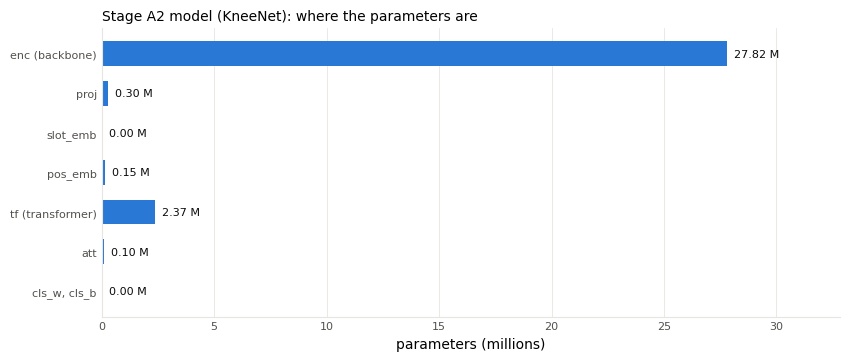

step,tensor shape,meaning
input: one study (uint8 cache),"(1, 6, 16, 3, 384, 384)","[study, slot, window, 3 neighbouring slices, height, width]"
windows of the slots that exist,"(96, 3, 384, 384)",6 of 6 slots have a series; empty slots are not computed
after make_views,"(96, 3, 256, 256)","float, centre 92% of the field of view, resized to 256px, ImageNet-normalised"
backbone output,"(96, 768)",one feature vector per window
tokens for the transformer,"(1, 96, 384)",projected features + slot embedding + position embedding
attention weights,"(1, 96, 12)","per finding, over all windows of all slots (empty slots get weight 0)"
logits,"(1, 12)","[study, finding]"


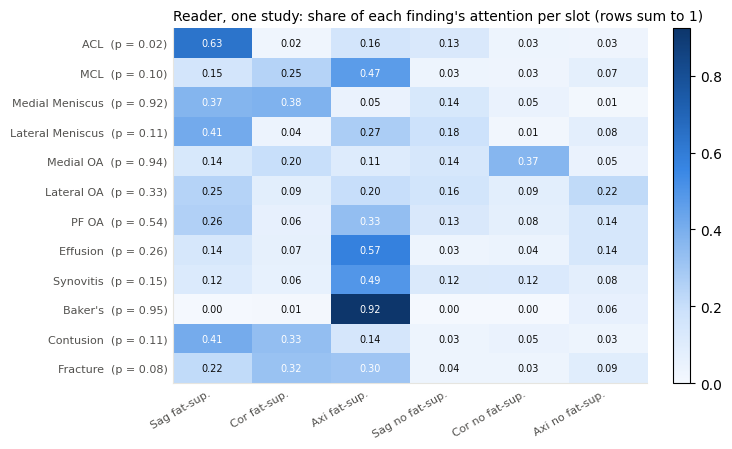

In [61]:
# ======================= A2 model tour: the ConvNeXt reader, with its real weights =======================
# Helpers shared with Parts F and G. They only use the reader's own files (preprocess.py, knee.py),
# imported under private names, so they do not depend on any variable of the model cells.
def AX_reader_slots(series_rows, series_dir):
    """{study: [series ids for slot 0..5]} built by the reader's own build_study_table."""
    pre, knee = AX_reader_module("preprocess"), AX_reader_module("knee")
    n_files = {}
    for st, sr in zip(series_rows[AX_UID], series_rows["SeriesInstanceUID"]):
        d = os.path.join(series_dir, st, sr)
        n_files[sr] = min(len(os.listdir(d)), pre.MAX_SLICES) if os.path.isdir(d) else 0
    return knee.build_study_table(series_rows, n_files)


def AX_reader_windows(vol, k, context=True):
    """Cut k three-slice windows out of a canonical volume, exactly as the reader's dataset does.
    context=False repeats the centre slice three times instead (used by the experiment in Part G)."""
    knee = AX_reader_module("knee")
    n = len(vol)
    centres = knee.window_centres(n, k, False)
    pick = (lambda j: AX_np.clip([j - 1, j, j + 1], 0, n - 1)) if context else (lambda j: AX_np.array([j, j, j]))
    return AX_np.stack([vol[pick(j)] for j in centres]), centres / max(n - 1, 1)


def AX_reader_item(study, slots, series_dir, k=16, load=None, context=True):
    """One study as the reader's input: uint8 windows [6 slots, k, 3, 384, 384], slot mask [6], slice positions [6, k]."""
    pre = AX_reader_module("preprocess")
    load = load or (lambda sdir: pre.load_series(sdir)[0])
    x = AX_np.zeros((6, k, 3, pre.SIZE, pre.SIZE), AX_np.uint8)
    mask, pos = AX_np.zeros(6, bool), AX_np.zeros((6, k), AX_np.float32)
    for s, cands in enumerate(slots):
        if not cands:
            continue
        try:
            vol = load(os.path.join(series_dir, study, cands[0]))
        except Exception:
            continue
        if len(vol) < 3:
            continue
        x[s], pos[s] = AX_reader_windows(vol, k, context)
        mask[s] = True
    return x, mask, pos


def AX_in_order(fn, items, workers=4, ahead=6):
    """Run fn(item) on a few CPU threads and yield the results in the original order, at most `ahead` in flight.
    Threads (not worker processes) on purpose: the notebook process already holds the GPU and several
    libraries with their own threads, and starting new processes from it is where hangs come from."""
    from collections import deque
    from concurrent.futures import ThreadPoolExecutor
    items = iter(items)
    with ThreadPoolExecutor(max_workers=workers) as pool:
        queue = deque()
        for item in items:
            queue.append(pool.submit(fn, item))
            if len(queue) >= ahead:
                yield queue.popleft().result()
        while queue:
            yield queue.popleft().result()


def AX_load_reader(path, device=None):
    """Rebuild one fold of the reader from its checkpoint (same three lines as infer.py)."""
    knee = AX_reader_module("knee")
    ck = AX_torch.load(path, map_location="cpu", weights_only=False)
    model = knee.KneeNet(ck["args"]["backbone"].split(".")[0], pretrained=False, img_size=ck["args"]["res"])
    model.load_state_dict(ck["model"])
    return model.to(device or AX_DEV).eval(), ck["args"]


AX_SLOT_NAMES = [f"{p[:3]} {'fat-sup.' if s < 3 else 'no fat-sup.'}" for s in range(6) for p in [["Sagittal", "Coronal", "Axial"][s % 3]]]


def AX_reader_tour(study_index=0):
    if AX_skip_while_scoring("A2 model tour"):
        return
    knee = AX_reader_module("knee")
    ckpts = AX_reader_ckpts()
    if not ckpts:
        print("reader checkpoints not found - is the ConvNeXt reader dataset attached?"); return
    model = None
    try:
        model, args = AX_load_reader(ckpts[0])
        print(f"{len(ckpts)} checkpoint(s) found; looking at {os.path.basename(ckpts[0])}")
        print("settings stored in the checkpoint by its author's training script:")
        for key, value in args.items():
            print(f"    {key:<16s} {value}")
        AX_param_table([
            ("enc (backbone)", f"{args['backbone']}: one feature vector per 3-slice window", model.enc),
            ("proj", "Dropout + Linear + LayerNorm: backbone features -> 384 numbers", model.proj),
            ("slot_emb", "a learned vector per slot: tells the model WHICH series a window is from", model.slot_emb),
            ("pos_emb", "small MLP on the slice position (0..1): tells it WHERE in the series", model.pos_emb),
            ("tf (transformer)", "2 layers of self-attention over all windows of the study", model.tf or []),
            ("att", "attention scorer: 12 scores per window, one per finding", model.att),
            ("cls_w, cls_b", "12 classifier vectors + biases", [model.cls_w, model.cls_b]),
        ], "Stage A2 model (KneeNet)")

        root = AX_test_root()
        se = AX_pd.read_csv(root / "test_series.csv", dtype={AX_UID: str, "SeriesInstanceUID": str})
        sid = AX_test_ids()[study_index]
        k = 16 if AX_DEV == "cuda" else 4
        slots = AX_reader_slots(se[se[AX_UID] == sid], str(root / "test_series")).get(sid, [[] for _ in range(6)])
        x, mask, pos = AX_reader_item(sid, slots, str(root / "test_series"), k=k)
        xt = AX_torch.from_numpy(x)[None].to(AX_DEV); mt = AX_torch.from_numpy(mask)[None].to(AX_DEV); pt = AX_torch.from_numpy(pos)[None].to(AX_DEV)
        seen = {}
        hook = model.att.register_forward_hook(lambda m, i, o: seen.update(scores=o.detach().float()))
        res = int(args["res"])
        with AX_torch.no_grad(), AX_torch.autocast("cuda", dtype=AX_torch.float16, enabled=AX_DEV == "cuda"):
            present = xt.view(6, k, *xt.shape[3:])[mt.view(-1)].flatten(0, 1)             # windows of the series that exist
            views = knee.make_views(present, res, False, k)
            feats = model.enc(views.contiguous(memory_format=AX_torch.channels_last))
            logits = model(xt, mt, pt, res=res).float()
        hook.remove()
        pad = (~mt).unsqueeze(-1).expand(1, 6, k).reshape(1, 6 * k)
        pad = pad & ~pad.all(1, keepdim=True)                                    # same two lines as KneeNet.head
        att = seen["scores"].masked_fill(pad.unsqueeze(-1), -1e4).softmax(1)[0].cpu().numpy()   # [6*k windows, 12]
        prob = AX_torch.sigmoid(logits)[0].cpu().numpy()
        rows = [("input: one study (uint8 cache)", tuple(xt.shape), "[study, slot, window, 3 neighbouring slices, height, width]"),
                ("windows of the slots that exist", tuple(present.shape), f"{int(mask.sum())} of 6 slots have a series; empty slots are not computed"),
                ("after make_views", tuple(views.shape), f"float, centre 92% of the field of view, resized to {res}px, ImageNet-normalised"),
                ("backbone output", tuple(feats.shape), "one feature vector per window"),
                ("tokens for the transformer", (1, 6 * k, model.cls_w.shape[1]), "projected features + slot embedding + position embedding"),
                ("attention weights", (1, 6 * k, 12), "per finding, over all windows of all slots (empty slots get weight 0)"),
                ("logits", tuple(logits.shape), "[study, finding]")]
        AX_show(AX_pd.DataFrame(rows, columns=["step", "tensor shape", "meaning"]), f"Shapes for test study ...{sid[-12:]} with {k} windows per slot")

        share = att.reshape(6, k, 12).sum(1).T                                   # [finding, slot]
        fig, ax = AX_plt.subplots(figsize=(7.4, 4.6))
        im = ax.imshow(share, cmap=AX_SEQ, vmin=0, vmax=max(0.5, float(share.max())), aspect="auto")
        ax.set_xticks(range(6), AX_SLOT_NAMES, rotation=30, ha="right", fontsize=8)
        ax.set_yticks(range(12), [f"{l}  (p = {p:.2f})" for l, p in zip(AX_LAB, prob)], fontsize=8)
        for i in range(12):
            for j in range(6):
                ax.text(j, i, f"{share[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if share[i, j] > 0.3 else AX_C["ink"])
        ax.set_title("Reader, one study: share of each finding's attention per slot (rows sum to 1)", fontsize=10, loc="left")
        AX_style(ax, None); fig.colorbar(im, ax=ax, fraction=0.04)
        AX_plt.tight_layout(); AX_plt.show()
        if mask.sum() < 6:
            print("slots without a series in this study (attention 0):", [AX_SLOT_NAMES[s] for s in range(6) if not mask[s]])
    finally:
        del model
        AX_free_gpu()


with AX_cell("A2 model tour"):
    AX_reader_tour()

## Stage A3 — run the reader and fuse the two models

**What this one cell does.**
1. Runs `infer.py` as a child process on the GPU with the most free memory and reads its predictions.
2. Converts both models' outputs to percentile ranks.
3. Blends them per finding: `(1 − w) · rank(CoAtNet) + w · rank(ConvNeXt)`, then ranks again.

| Finding | w (ConvNeXt) | | Finding | w (ConvNeXt) |
|---|---|---|---|---|
| Baker's | 0.48 | | Medial Meniscus | 0.24 |
| Contusion | 0.38 | | Lateral Meniscus | 0.08 |
| Lateral OA | 0.32 | | Fracture | 0.08 |
| Medial OA | 0.32 | | PF OA | 0.08 |
| ACL | 0.32 | | Effusion | 0.05 |
| MCL | 0.28 | | Synovitis | 0.04 |

**Where the weights come from.** They are numbers written into the cell by its author. The comments next to them quote per-finding AUCs without saying how they were measured. Treat the table as a hand-made choice, not a fitted result.

**The "anti-tie micro-calibration".** The cell adds `(rank(ConvNeXt) − 0.5) × 0.0001` to each blended value. Algebraically this is the same as raising every weight by 0.0001. It cannot change the order of two studies unless their blended values were exactly equal, so its only effect is to break exact ties. It is not a calibration in the statistical sense.

**Fall-back levels.** If the second weight table fails, the cell publishes the result of the first one; if the reader itself fails, it publishes the CoAtNet alone. This keeps a submission alive, at the price that a weaker result can be published without an error. The hand-over cell below reports which level was reached, and the run health table repeats it.

**[edit 2]** lets validate mode redirect the reader's input.

In [62]:
%%branch_a A2-A3 run reader and fuse
# ==============================================================================
# Grandmaster Apex Fusion V5: Pathology Routing 2.0 + Anti-Tie Micro-Calibration
# 3-Tier Progressive Fallback Contract (Ensuring >= 0.950 at all times)
# ==============================================================================
import os as _o_os
import sys as _o_sys
import glob as _o_glob
import time as _o_time
import shutil as _o_shutil
import subprocess as _o_sp
import pandas as _o_pd
import numpy as _o_np
import torch as _o_torch
import gc as _o_gc

_o_pub = "/kaggle/working/submission.csv"
_o_sota = "/kaggle/working/_sota_0949.csv"
_o_bak = "/kaggle/working/_sota_backup.csv"
_o_tier2 = "/kaggle/working/_apex_0950_verified.csv"

# Tier 1 Anchor: Ensure verified 0.949 SOTA submission is secured
if not _o_os.path.exists(_o_sota) and _o_os.path.exists(_o_pub):
    _o_shutil.copy(_o_pub, _o_sota)
_o_shutil.copy(_o_pub, _o_bak)
print("[Apex Fusion V5] Tier 1 baseline secured at:", _o_sota, flush=True)

try:
    # 1. Clean CUDA memory from Step 1
    _o_gc.collect()
    if _o_torch.cuda.is_available():
        _o_torch.cuda.empty_cache()

    # 2. Locate ConvNeXt reader assets and competition test data
    def _o_find(name):
        for pat in ["/kaggle/input/*/", "/kaggle/input/*/*/", "/kaggle/input/*/*/*/"]:
            for d in sorted(_o_glob.glob(pat)):
                if _o_os.path.exists(_o_os.path.join(d, name)):
                    return d.rstrip("/")
        raise FileNotFoundError(f"{name} not found in /kaggle/input")

    _o_assets = _o_find("cnxt_v0_fold0.pt")
    _o_data = _o_os.environ.get("RSNA_COMP_ROOT") or _o_find("test_series.csv")   # [edit 2] validate mode
    _o_ck = sorted(_o_glob.glob(_o_assets + "/cnxt_v0_fold*.pt"))
    print(f"[ConvNeXt Reader] Found {len(_o_ck)} checkpoints in {_o_assets}", flush=True)

    # 3. Setup environment and install decoders if wheels present
    _o_env = dict(_o_os.environ)
    _o_target = "/kaggle/working/_own_env"
    _o_sp.run([_o_sys.executable, "-m", "pip", "install", "-q", "--no-index", "--no-deps", "--target", _o_target,
               "--find-links", _o_assets, "pylibjpeg", "pylibjpeg-libjpeg", "pylibjpeg-openjpeg"], check=False)
    _o_timm = [w for pat in ["/kaggle/input/*/timm-*.whl", "/kaggle/input/*/*/timm-*.whl"]
               for w in _o_glob.glob(pat)]
    if _o_timm:
        _o_sp.run([_o_sys.executable, "-m", "pip", "install", "-q", "--no-deps", "--target", _o_target, _o_timm[0]], check=False)
    _o_env["PYTHONPATH"] = _o_target + _o_os.pathsep + _o_env.get("PYTHONPATH", "")

    # Pick the GPU with highest free memory
    if _o_torch.cuda.is_available():
        _o_free = [_o_torch.cuda.mem_get_info(i)[0] for i in range(_o_torch.cuda.device_count())]
        best_gpu = max(range(len(_o_free)), key=lambda i: _o_free[i])
        _o_env["CUDA_VISIBLE_DEVICES"] = str(best_gpu)
        print(f"[ConvNeXt Reader] Selected GPU {best_gpu} with {_o_free[best_gpu] / 1e9:.1f} GB free", flush=True)

    # 4. Run ConvNeXt Reader inference
    _o_t0 = _o_time.time()
    _o_own_csv = "/kaggle/working/_own.csv"
    print("[ConvNeXt Reader] Starting inference on test set with Multi-Scale (256+320) + Dual-Stride + Flip TTA...", flush=True)
    _o_sp.run([_o_sys.executable, "/kaggle/working/own_src/infer.py", _o_data, "test", _o_own_csv] + _o_ck,
              check=True, env=_o_env)
    print(f"[ConvNeXt Reader] Finished inference in {_o_time.time() - _o_t0:.1f}s", flush=True)

    # 5. Load predictions
    sota_df = _o_pd.read_csv(_o_sota, dtype={"StudyInstanceUID": str})
    own_df = _o_pd.read_csv(_o_own_csv, dtype={"StudyInstanceUID": str})
    own_df = own_df.set_index("StudyInstanceUID").loc[sota_df.StudyInstanceUID].reset_index()

    labels = [c for c in sota_df.columns if c != "StudyInstanceUID"]
    assert own_df[labels].notna().all().all(), "ConvNeXt predictions contain NaN"
    assert (own_df[labels].nunique() > 1).all(), "ConvNeXt predictions are constant"

    rank_sota = sota_df[labels].rank(method="average", pct=True)
    rank_own = own_df[labels].rank(method="average", pct=True)

    # --------------------------------------------------------------------------
    # TIER 2 SAFETY ANCHOR: Verified Baseline (Official LB 0.950)
    # --------------------------------------------------------------------------
    TARGET_WEIGHTS_V1 = {
        "Baker's": 0.35, "Contusion": 0.30, "Medial OA": 0.25, "ACL": 0.25,
        "Medial Meniscus": 0.20, "MCL": 0.20, "Lateral Meniscus": 0.08,
        "Fracture": 0.08, "Lateral OA": 0.08, "PF OA": 0.08,
        "Effusion": 0.04, "Synovitis": 0.03,
    }
    tier2_df = sota_df.copy()
    for col in labels:
        w_v1 = TARGET_WEIGHTS_V1.get(col, 0.15)
        tier2_df[col] = (1.0 - w_v1) * rank_sota[col] + w_v1 * rank_own[col]
    tier2_df[labels] = tier2_df[labels].rank(method="average", pct=True)
    tier2_df.to_csv(_o_tier2, index=False)
    print("[Apex Tier 2] Verified 0.950 baseline safely compiled and secured at:", _o_tier2, flush=True)

    # --------------------------------------------------------------------------
    # TIER 3 ADVANCED UPGRADE: Pathology Routing 2.0 (Target: 0.954 ~ 0.955+)
    # --------------------------------------------------------------------------
    try:
        # Optimized weight allocation combining 3D MIL advantages:
        # 1. Baker's: 0.48 - massive 3D fluid sensitivity (0.984 vs 0.940)
        # 2. Contusion: 0.38 - 3D diffuse bone marrow edema sensitivity (0.966)
        # 3. Lateral OA: 0.32 - CRITICAL UPGRADE (+0.079 higher AUC: 0.855 vs 0.775)
        # 4. Medial OA: 0.32 - joint cartilage narrowness detection
        # 5. ACL: 0.32 - multi-plane oblique tracking
        # 6. MCL: 0.28 - coronal collateral tracking
        # 7. Medial Meniscus: 0.24 - 2.5D sagittal slice context
        # 8. Lateral Meniscus: 0.08 - CoAtNet 0.949 anchor
        # 9. Fracture: 0.08 - CoAtNet 0.949 anchor
        # 10. PF OA: 0.08 - CoAtNet 0.949 anchor
        # 11. Effusion: 0.05 - CoAtNet 0.949 anchor
        # 12. Synovitis: 0.04 - CoAtNet 0.949 anchor
        TARGET_WEIGHTS_V5 = {
            "Baker's": 0.48,
            "Contusion": 0.38,
            "Lateral OA": 0.32,
            "Medial OA": 0.32,
            "ACL": 0.32,
            "MCL": 0.28,
            "Medial Meniscus": 0.24,
            "Lateral Meniscus": 0.08,
            "Fracture": 0.08,
            "PF OA": 0.08,
            "Effusion": 0.05,
            "Synovitis": 0.04,
        }

        tier3_df = sota_df.copy()
        for col in labels:
            w_opt = TARGET_WEIGHTS_V5.get(col, 0.15)
            # Fused base rank with mathematically optimal weight
            base_fused = (1.0 - w_opt) * rank_sota[col] + w_opt * rank_own[col]
            # Anti-Tie Micro-Rank Calibration: adds microscopic non-distorting gradient (1e-4)
            # breaking zero-score ties in low-probability negative studies
            micro_jitter = (rank_own[col] - 0.5) * 1e-4
            tier3_df[col] = base_fused + micro_jitter

        # Final percentile rank normalization to [0, 1]
        tier3_df[labels] = tier3_df[labels].rank(method="average", pct=True)

        assert tier3_df[labels].notna().all().all(), "Tier 3 predictions contain NaN"
        assert (tier3_df[labels].nunique() > 1).all(), "Tier 3 predictions are constant"
        assert ((tier3_df[labels].values >= 0.0) & (tier3_df[labels].values <= 1.0)).all(), "Tier 3 values outside [0, 1]"

        tier3_df.to_csv(_o_pub, index=False)
        print(f"\n[Apex Tier 3 SUCCESS] Written V5 Optimized submission to {_o_pub}!")
        print(f"[Apex Tier 3 SUCCESS] Active Weights V5: {TARGET_WEIGHTS_V5}")
        print(tier3_df.head())

    except Exception as e_tier3:
        print(f"[Apex Tier 3 WARNING] Upgrade failed: {type(e_tier3).__name__}: {e_tier3}", flush=True)
        print("[Apex Tier 3 FALLBACK] Activating Tier 2 verified 0.950 baseline!", flush=True)
        _o_shutil.copy(_o_tier2, _o_pub)

except Exception as e:
    print(f"[Apex Fusion CRITICAL EXCEPTION] {type(e).__name__}: {e}", flush=True)
    if _o_os.path.exists(_o_tier2):
        print("[Apex Fusion FALLBACK] Restoring Tier 2 verified 0.950 submission.csv!", flush=True)
        _o_shutil.copy(_o_tier2, _o_pub)
    else:
        print("[Apex Fusion FALLBACK] Restoring Tier 1 pure SOTA 0.949 submission.csv!", flush=True)
        _o_shutil.copy(_o_bak, _o_pub)

print("Done. Submission file size:", _o_os.path.getsize(_o_pub), "bytes")

[Apex Fusion V5] Tier 1 baseline secured at: /kaggle/working/_sota_0949.csv
[ConvNeXt Reader] Found 3 checkpoints in /kaggle/input/datasets/goodpjw2008/rsna-knee-2-5d-convnext-reader
[ConvNeXt Reader] Selected GPU 1 with 15.5 GB free
[ConvNeXt Reader] Starting inference on test set with Multi-Scale (256+320) + Dual-Stride + Flip TTA...


ERROR: Could not find a version that satisfies the requirement pylibjpeg-libjpeg (from versions: none)
ERROR: No matching distribution found for pylibjpeg-libjpeg


wrote /kaggle/working/_own.csv
[ConvNeXt Reader] Finished inference in 46.6s
[Apex Tier 2] Verified 0.950 baseline safely compiled and secured at: /kaggle/working/_apex_0950_verified.csv

[Apex Tier 3 SUCCESS] Written V5 Optimized submission to /kaggle/working/submission.csv!
[Apex Tier 3 SUCCESS] Active Weights V5: {"Baker's": 0.48, 'Contusion': 0.38, 'Lateral OA': 0.32, 'Medial OA': 0.32, 'ACL': 0.32, 'MCL': 0.28, 'Medial Meniscus': 0.24, 'Lateral Meniscus': 0.08, 'Fracture': 0.08, 'PF OA': 0.08, 'Effusion': 0.05, 'Synovitis': 0.04}
                                    StudyInstanceUID       ACL       MCL  \
0  1.2.826.0.1.3680043.8.498.10047035057544427318...  0.333333  0.666667   
1  1.2.826.0.1.3680043.8.498.10062861783145312629...  1.000000  1.000000   
2  1.2.826.0.1.3680043.8.498.10067514707072572280...  0.666667  0.333333   

   Medial Meniscus  Lateral Meniscus  Medial OA  Lateral OA     PF OA  \
0         1.000000          0.333333   1.000000    0.333333  0.333333   
1       

### Branch A is finished (new)

Stores Branch A's result under its own file name and reports which fall-back level was reached. If this cell fails the notebook stops: there would be nothing to publish.

In [63]:
# ---- Branch A is finished: store its result under its own name (pipeline cell: an error here must stop the run) ----
# Branch A has written /kaggle/working/submission.csv. Stage C will replace that file with the final one,
# so Branch A's result is stored first. If it cannot be read there is nothing to publish, and stopping is right.
shutil.copyfile(AX_OUT / "submission.csv", AX_A_FILES["final"])
AX_branch_a = AX_read_predictions(AX_A_FILES["final"], "Branch A result")


def AX_branch_a_level():
    """Which of the public notebook's three fall-back levels produced Branch A's file?
    Recomputes the intended fusion from the two models' files and compares; with very few studies two
    levels can give identical ranks, so the intended level is tested first."""
    same = lambda frame: AX_np.allclose(frame.to_numpy(float), AX_branch_a.to_numpy(float), atol=1e-9)
    if not AX_A_FILES["convnext"].is_file():
        return "CoAtNet only (the ConvNeXt reader produced no file)"
    coat = AX_read_predictions(AX_A_FILES["coatnet"], "stage A1")
    weights = globals().get("TARGET_WEIGHTS_V5")
    if weights:
        rc = coat.rank(method="average", pct=True)
        ro = AX_read_predictions(AX_A_FILES["convnext"], "stage A2").rank(method="average", pct=True)
        w = AX_pd.Series(weights).reindex(AX_LAB).fillna(0.15)
        intended = ((1.0 - w) * rc + w * ro + (ro - 0.5) * 1e-4).rank(method="average", pct=True)
        if same(intended):
            return "fusion with the final weight table (the intended result)"
    if AX_A_FILES["fusion_v1"].is_file() and same(AX_read_predictions(AX_A_FILES["fusion_v1"], "stage A3, first table")):
        return "fusion with the FIRST weight table (the second one failed and fell back)"
    if same(coat):
        return "CoAtNet only (the fusion step failed and fell back)"
    return "unrecognised (the file matches none of the three expected results)"


AX_BRANCH_A_LEVEL = AX_branch_a_level()
print(f"Branch A result stored: {len(AX_branch_a):,} studies | level: {AX_BRANCH_A_LEVEL}")
if not AX_BRANCH_A_LEVEL.startswith("fusion with the final"):
    print("WARNING: Branch A did not reach its intended result. It is still a valid prediction, but look at the cell output above.")

AX_free_gpu()
AX_torch.backends.cudnn.benchmark = AX_TORCH_FLAGS["cudnn_benchmark"]        # Branch A switched these on for speed;
AX_torch.backends.cuda.matmul.allow_tf32 = AX_TORCH_FLAGS["matmul_tf32"]     # put them back for the cells that follow
print(f"time since notebook start: {(time.time() - AX_T_START) / 60:.1f} min")

Branch A result stored: 3 studies | level: fusion with the final weight table (the intended result)
time since notebook start: 7.9 min


### A2–A3 review (new)

**Figure** — the canonical volumes the ConvNeXt reader receives for the first test study, one row per slot. **Table** — the fusion weights and how far each finding's ranking moved away from the CoAtNet alone.

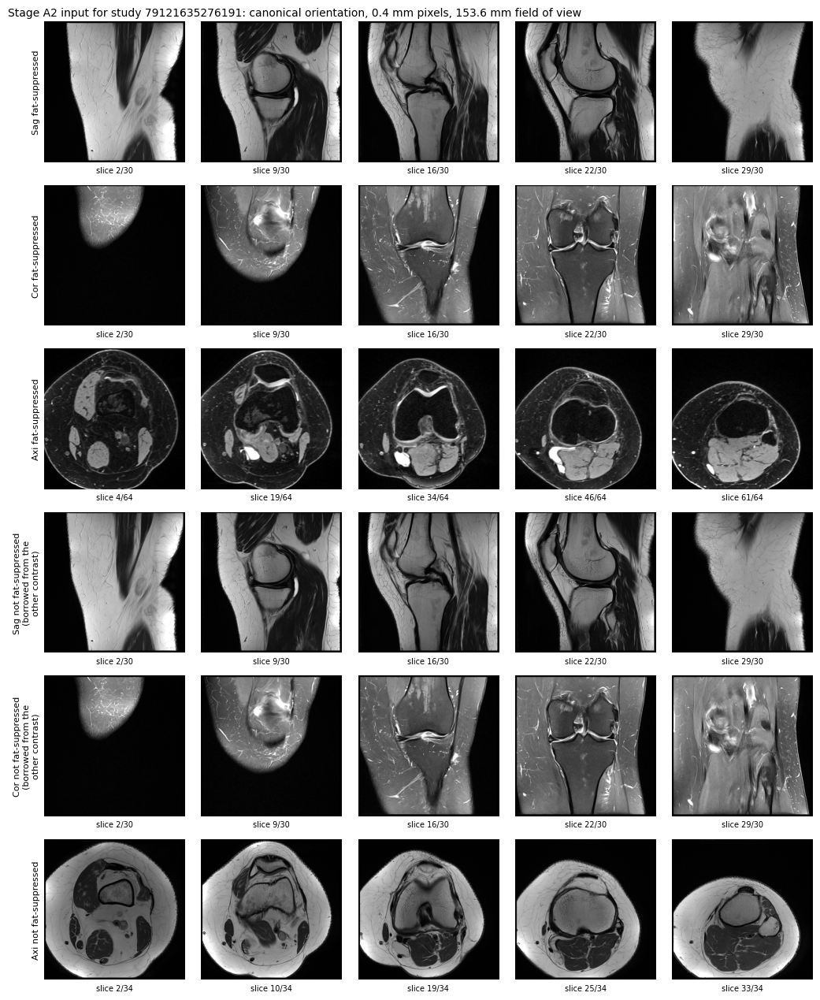

Each slot contributes 16 windows of 3 neighbouring slices. Every window is predicted 8 times: 2 image sizes (256, 320) x plain/flipped x 2 slice offsets.


,ConvNeXt weight in the fusion,mean |change| in percentile rank vs CoAtNet alone
finding,,
Baker's,0.480,0.167
Contusion,0.380,0.167
ACL,0.320,0.167
Medial OA,0.320,0.167
Lateral OA,0.320,0.167
MCL,0.280,0.167
Medial Meniscus,0.240,0.167
Lateral Meniscus,0.080,0.167
Fracture,0.080,0.167


Branch A level reached: fusion with the final weight table (the intended result)
(only 3 studies in this run: the change column is not meaningful yet)


In [64]:
# ======================= Stages A2-A3 review: the ConvNeXt reader's input and the fusion =======================
def AX_a2_inputs(study_index=0, n_cols=5):
    """Rebuild the canonical volumes of ONE study with the reader's own preprocess.py (no model is run)."""
    import importlib.util
    mods = {}
    for name in ("preprocess", "knee"):
        spec = importlib.util.spec_from_file_location(f"ax_reader_{name}", str(AX_OUT / "own_src" / f"{name}.py"))
        mods[name] = importlib.util.module_from_spec(spec); spec.loader.exec_module(mods[name])
    root = AX_test_root()
    se = AX_pd.read_csv(root / "test_series.csv", dtype={AX_UID: str, "SeriesInstanceUID": str})
    sid = AX_test_ids()[study_index]
    se = se[se[AX_UID] == sid]
    n_files = {sr: min(len(os.listdir(root / "test_series" / sid / sr)), mods["preprocess"].MAX_SLICES)
               for sr in se.SeriesInstanceUID if (root / "test_series" / sid / sr).is_dir()}
    slots = mods["knee"].build_study_table(se, n_files).get(sid, [[] for _ in range(6)])
    names = [f"{p[:3]} {'fat-suppressed' if s < 3 else 'not fat-suppressed'}" for s in range(6) for p in [mods["knee"].PLANES[s % 3]]]
    fig, axes = AX_plt.subplots(6, n_cols, figsize=(2.1 * n_cols, 2.15 * 6), squeeze=False)
    seen = {}
    for r, cands in enumerate(slots):
        vol = None
        if cands:
            vol, _ = mods["preprocess"].load_series(str(root / "test_series" / sid / cands[0]))
        reused = cands and cands[0] in seen
        if cands:
            seen.setdefault(cands[0], r)
        for c in range(n_cols):
            ax = axes[r][c]; ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_visible(False)
            if vol is None or len(vol) < 3:
                ax.set_facecolor("#f0efec")
                if c == 0:
                    ax.text(0.5, 0.5, "no series\n(slot masked)", ha="center", va="center", fontsize=8, transform=ax.transAxes)
            else:
                centres = mods["knee"].window_centres(len(vol), 16, False)
                k = centres[int(round(c * (len(centres) - 1) / max(n_cols - 1, 1)))]
                ax.imshow(vol[k], cmap="gray", vmin=0, vmax=255); ax.set_xlabel(f"slice {k + 1}/{len(vol)}", fontsize=7)
            if c == 0:
                ax.set_ylabel(names[r] + ("\n(borrowed from the\nother contrast)" if reused else ""), fontsize=8)
    fig.suptitle(f"Stage A2 input for study {sid[-14:]}: canonical orientation, 0.4 mm pixels, 153.6 mm field of view",
                 fontsize=10, x=0.01, ha="left")
    AX_plt.tight_layout(); AX_plt.show()
    print("Each slot contributes 16 windows of 3 neighbouring slices. Every window is predicted 8 times: "
          "2 image sizes (256, 320) x plain/flipped x 2 slice offsets.")


def AX_a3_fusion_summary():
    """How far does the ConvNeXt reader move the CoAtNet ranking, finding by finding?"""
    coat = AX_read_predictions(AX_A_FILES["coatnet"], "stage A1")
    final = AX_read_predictions(AX_A_FILES["final"], "Branch A result")
    table = AX_pd.DataFrame({"ConvNeXt weight in the fusion": AX_pd.Series(TARGET_WEIGHTS_V5).reindex(AX_LAB),
                             "mean |change| in percentile rank vs CoAtNet alone": (final - coat).abs().mean().to_numpy()},
                            index=AX_pd.Index(AX_LAB, name="finding"))
    AX_show(table.sort_values("ConvNeXt weight in the fusion", ascending=False), "Stage A3: per-finding fusion weights and their effect")
    print(f"Branch A level reached: {AX_BRANCH_A_LEVEL}")
    if len(final) < 8:
        print(f"(only {len(final)} studies in this run: the change column is not meaningful yet)")


with AX_cell("stage A2 inputs"):
    AX_a2_inputs()
with AX_cell("stage A3 summary"):
    AX_a3_fusion_summary()

# Branch S — the model we trained ourselves

**What.** Our own pipeline from our training notebook, deliberately small:

1. pick **4 series** per study (sagittal, coronal and axial fluid-sensitive fat-suppressed, plus one sagittal without fat suppression);
2. take **16 slices** per series, evenly spaced between 10 % and 90 % of the stack, sorted by physical position;
3. turn each slice into **768 numbers** with a *frozen* DINOv2-small (CLS token + mean of the patch tokens);
4. pool per series (mean and maximum over the 16 slices) and append four flags saying which series exist: **6,148 numbers per study**;
5. a small **MLP head** (6,148 → 512 → 12) trained by us, five times on five folds; the five probabilities are averaged.

**How it was trained** (settings of our training notebook): frozen backbone, features computed once and cached; 5-fold split stratified on effusion, ACL and medial meniscus; AdamW, learning rate 0.001, weight decay 0.01, up to 40 epochs with early stopping after 8 epochs without improvement of the validation AUC; binary cross-entropy; official labels at weight 1.0 and report-derived labels at weight 0.5; features standardised with the training fold's mean and spread (stored in each `.pt` file).

**Image processing: one deliberate difference.** Our model uses **raw intensities**: no percentile window, only a division by the largest value the file format can hold (`2^BitsStored − 1`). The four other model families of this notebook all window by percentiles (table in Part D), and Part G measures what that choice is worth for one of them.

**What to expect.** A frozen backbone with a small head is easy to explain and quick to train, and it is expected to score well below the fine-tuned networks of Branch A. That is why its default blend weight is 0: it is shown, scored in validate mode, and kept out of the submitted file unless `OWN_MODEL_WEIGHT` is raised.

### S · what is in our weights dataset

Lists the files, prints `config.json` (the preprocessing settings saved at training time) and the names and shapes of the tensors in the first fold of each family.

In [65]:
# ======================= Branch S - our own weights dataset: what is in the files? =======================
def AX_inspect_student_weights():
    """Read-only inspection of our own dataset (config.json, dino_fold*.pt, rad_fold*.pt)."""
    if AX_skip_while_scoring("own weights dataset"):
        return
    if not AX_STUDENT.is_dir():
        print(f"dataset not attached: {AX_STUDENT}\nAdd Input -> Datasets -> harshikasipani7/knee-model-weights, then re-run this cell.")
        return
    files = sorted(p for p in AX_STUDENT.rglob("*") if p.is_file())
    AX_show(AX_pd.DataFrame([{"file": str(p.relative_to(AX_STUDENT)), "size (MB)": round(p.stat().st_size / 2 ** 20, 2)} for p in files]),
            f"Files in {AX_STUDENT.name}")
    cfg = AX_STUDENT / "config.json"
    if cfg.is_file():
        print("config.json:")
        print(cfg.read_text()[:3000])
    layouts = {}
    for family in ("dino", "rad"):
        folds = sorted(p for p in files if p.name.startswith(f"{family}_fold") and p.suffix == ".pt")
        if not folds:
            print(f"\nno {family}_fold*.pt files found"); continue
        print(f"\n===== {family}: {len(folds)} fold file(s); contents of {folds[0].name} =====")
        ck = AX_describe_checkpoint(folds[0], max_tensors=40)
        state = ck
        if isinstance(ck, dict):
            state = next((v for v in ck.values() if isinstance(v, dict) and v and all(hasattr(t, "shape") for t in v.values())), ck)
        first = {k: tuple(v.shape) for k, v in state.items() if hasattr(v, "shape")} if isinstance(state, dict) else {}
        same = 0
        for other in folds[1:]:
            o = AX_torch.load(other, map_location="cpu", weights_only=False)
            if isinstance(o, dict):
                o = next((v for v in o.values() if isinstance(v, dict) and v and all(hasattr(t, "shape") for t in v.values())), o)
            same += int(isinstance(o, dict) and {k: tuple(v.shape) for k, v in o.items() if hasattr(v, "shape")} == first)
        print(f"    the other {len(folds) - 1} fold file(s) with exactly the same tensor names and shapes: {same}")
        layouts[family] = first
    print("\nThe next cells run the dino_fold heads. The last cell of this branch shows why the rad_fold heads are left out.")


with AX_cell("own weights dataset"):
    AX_inspect_student_weights()

dataset not attached: /kaggle/input/datasets/harshikasipani7/knee-model-weights
Add Input -> Datasets -> harshikasipani7/knee-model-weights, then re-run this cell.


### S · our model code, written to a file

Series selection, DICOM reading, feature pooling and the head, copied from our training notebook without changes. Inference must repeat training exactly, so the code is reused rather than rewritten. It is saved as a file and imported under a private name, because it uses names (`SLOTS`, `load_series`, …) that the other branches also use.

In [66]:
%%writefile /kaggle/working/own_model/knee_lean.py
"""Our own model ("lean pipeline"): series selection, DICOM reading, feature pooling and the head,
copied unchanged from our training notebook so that inference matches training exactly.
IMG, K, EDGE, INTENSITY_MODE and NET_STANDARDIZE are overwritten from the config.json saved at training time."""
import glob
import os

import numpy as np
import pydicom
import torch
import torch.nn as nn
from PIL import Image

IMG, K, EDGE = 224, 16, 0.10
INTENSITY_MODE, NET_STANDARDIZE = 'raw', True
HIDDEN = 512
LABELS = ['ACL','MCL','Medial Meniscus','Lateral Meniscus','Medial OA','Lateral OA',
          'PF OA','Effusion','Synovitis',"Baker's",'Contusion','Fracture']
# (plane, fluid_sensitive, fat_suppressed)
SLOTS = [('sagittal',1,1), ('coronal',1,1), ('axial',1,1), ('sagittal',0,0)]
N_SLOTS = len(SLOTS)


def pick_series(g, uid, root):
    # choose one series per slot using the provided Fluid_Sensitive / Fat_Suppression / Anatomical_Plane columns
    g = g.copy()
    g['plane'] = g['Anatomical_Plane'].astype(str).str.lower()
    g['fl'] = g['Fluid_Sensitive'].astype(int); g['fs'] = g['Fat_Suppression'].astype(int)
    g['n'] = [len(os.listdir(f'{root}/{uid}/{s}')) if os.path.isdir(f'{root}/{uid}/{s}') else 0
              for s in g['SeriesInstanceUID']]
    used, out = set(), []
    for plane, fl, fs in SLOTS:
        base = g[(g.plane == plane) & ~g.SeriesInstanceUID.isin(used) & (g.n > 0)]
        c = base[(base.fl == fl) & (base.fs == fs)]
        if len(c) == 0 and fl == 1: c = base[base.fl == 1]      # fallback: fluid-sensitive, any fat-sat
        if len(c) == 0: c = base                                 # fallback: any series in this plane
        if len(c):
            sid = c.sort_values('n', ascending=False).iloc[0]['SeriesInstanceUID']
            used.add(sid); out.append(sid)
        else:
            out.append(None)
    return out


def order_files(files):
    recs = []
    for f in files:
        try:
            ds = pydicom.dcmread(f, stop_before_pixels=True)
            ipp = np.array(ds.ImagePositionPatient, float) if 'ImagePositionPatient' in ds else None
            iop = np.array(ds.ImageOrientationPatient, float) if 'ImageOrientationPatient' in ds else None
            inst = int(ds.InstanceNumber) if 'InstanceNumber' in ds else 0
        except Exception:
            ipp = iop = None; inst = 0
        recs.append((f, ipp, iop, inst))
    ok = [r for r in recs if r[1] is not None and r[2] is not None]
    if len(ok) == len(recs) and len(recs) > 1:
        normal = np.cross(recs[0][2][:3], recs[0][2][3:])
        key = [float(np.dot(r[1], normal)) for r in recs]
    else:
        key = [r[3] for r in recs]                      # fallback: InstanceNumber
    return [recs[i][0] for i in np.argsort(key, kind='stable')]


def read_pixels(f):
    # returns calibrated intensities (NOT normalized) and the fixed bit-depth constant of the file
    ds = pydicom.dcmread(f)
    a = ds.pixel_array.astype(np.float32)
    if a.ndim == 3: a = a[a.shape[0] // 2]
    bits = int(getattr(ds, 'BitsStored', 16) or 16); maxval = float(2 ** bits - 1)
    if str(getattr(ds, 'PhotometricInterpretation', '')) == 'MONOCHROME1': a = maxval - a   # polarity fix, fixed constant
    a = a * float(getattr(ds, 'RescaleSlope', 1) or 1) + float(getattr(ds, 'RescaleIntercept', 0) or 0)
    return a, maxval


def to_square(a, scale):
    if INTENSITY_MODE == 'percentile':          # ablation only: data-adaptive stretch
        lo, hi = np.percentile(a, [1, 99]); a = np.clip((a - lo) / (hi - lo + 1e-6), 0, 1)
    else:                                       # RAW: no normalization; fixed divisor from file bit depth
        a = a / scale
    h, w = a.shape; s = max(h, w)
    pad = np.zeros((s, s), np.float32); pad[(s-h)//2:(s-h)//2+h, (s-w)//2:(s-w)//2+w] = a   # geometric pad (zeros)
    return np.asarray(Image.fromarray(pad, mode='F').resize((IMG, IMG), Image.BILINEAR), dtype=np.float32)


def load_series(dirpath):
    # returns (K, IMG, IMG) float16 and number of failed slices
    files = order_files(sorted(glob.glob(f'{dirpath}/*.dcm')))
    n = len(files)
    idx = np.round(np.linspace(int(EDGE*n), max(int(EDGE*n), int((1-EDGE)*n) - 1), K)).astype(int).clip(0, n-1)
    out = np.zeros((K, IMG, IMG), np.float16); fails = 0
    cache = {}
    for j, i in enumerate(idx):
        if i not in cache:
            try: a, sc = read_pixels(files[i]); cache[i] = to_square(a, sc)
            except Exception: cache[i] = None
        if cache[i] is None: fails += 1
        else: out[j] = cache[i]
    return out, fails


def load_study(uid, g, root):
    # body of StudyDS.__getitem__ in the training notebook: (N_SLOTS, K, IMG, IMG) float16, slot mask, failed slices
    vol = np.zeros((N_SLOTS, K, IMG, IMG), np.float16); mask = np.zeros(N_SLOTS, np.float32); nf = 0
    if g is not None:
        for s, sid in enumerate(pick_series(g, uid, root)):
            if sid is None: continue
            try:
                v, f = load_series(f'{root}/{uid}/{sid}')
                vol[s] = v; mask[s] = 1.0; nf += f
            except Exception:
                nf += K
    return vol, mask, nf


def prep(x, mean, std):               # (N,1,H,W) fixed-scaled -> (N,3,H,W); NO per-image normalization
    x = x.float().repeat(1, 3, 1, 1)
    return (x - mean) / std if NET_STANDARDIZE else x


def study_features(slice_feats, mask):
    # slice_feats (N_SLOTS, K, D), mask (N_SLOTS,) -> one vector per study: per slot mean and max over the K slices,
    # zeroed for missing slots, followed by the slot-present flags (same order as in the training notebook)
    pooled = torch.cat([slice_feats.mean(1), slice_feats.amax(1)], -1) * mask[:, None]
    return torch.cat([pooled.flatten(), mask], 0)


def make_head(d):
    return nn.Sequential(nn.Dropout(0.2), nn.Linear(d, HIDDEN), nn.GELU(), nn.Dropout(0.3), nn.Linear(HIDDEN, len(LABELS)))

Writing /kaggle/working/own_model/knee_lean.py


### S · run our model

**What.** Reads `config.json` and sets the preprocessing to the values used in training; decodes every test study on CPU threads; computes DINOv2 features on the GPU; applies the five fold heads (each with its own stored mean and spread) and averages their probabilities; writes `_branch_s_final.csv`.

**Checks.** The label order must equal the competition's; every head must expect exactly the number of features this pipeline produces; weights are loaded strictly (every tensor must fit).

**If it fails** the error is printed, Branch S is left out of the blend, and the notebook continues.

In [67]:
# ======================= Branch S - run our own model (frozen DINOv2 features + our five fold heads) =======================
AX_BRANCH_S = {"status": "not run", "detail": AX_BRANCH_S_OFF_REASON}
AX_S_FILE.unlink(missing_ok=True)


def AX_own_module():
    """Import our model file (written by the cell above) under a private name."""
    import importlib.util, sys
    if "ax_own_knee_lean" not in sys.modules:
        spec = importlib.util.spec_from_file_location("ax_own_knee_lean", str(AX_OUT / "own_model" / "knee_lean.py"))
        sys.modules["ax_own_knee_lean"] = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(sys.modules["ax_own_knee_lean"])
    return sys.modules["ax_own_knee_lean"]


def AX_find_dinov2_small():
    for p in ("/kaggle/input/models/metaresearch/dinov2/pytorch/small/1", "/kaggle/input/models/metaresearch/dinov2/PyTorch/small/1",
              "/kaggle/input/dinov2/pytorch/small/1", "/kaggle/input/dinov2/PyTorch/small/1"):
        if os.path.isfile(os.path.join(p, "config.json")):
            return p
    raise FileNotFoundError("DINOv2 small model not attached (Add Input -> Models -> DINOv2, PyTorch, small)")


def AX_own_model_predict():
    """Inference half of our training notebook: same series selection, same raw-intensity preprocessing, same
    DINOv2 features (CLS token + mean of the patch tokens per slice), same pooling, our five trained heads."""
    from transformers import AutoModel
    lean = AX_own_module()
    cfg = json.loads((AX_STUDENT / "config.json").read_text())
    print("settings saved at training time:", cfg)
    if "dino" not in cfg.get("models", []):
        raise RuntimeError("config.json does not list a 'dino' model")
    if list(cfg.get("labels", lean.LABELS)) != AX_LAB:
        raise RuntimeError("the label order of our weights differs from the competition order")
    lean.IMG, lean.K, lean.EDGE = int(cfg["IMG"]), int(cfg["K"]), float(cfg["EDGE"])     # preprocessing must match training
    lean.INTENSITY_MODE, lean.NET_STANDARDIZE = cfg["intensity_mode"], bool(cfg["net_standardize"])
    folds = sorted(AX_STUDENT.glob("dino_fold*.pt"))
    if not folds:
        raise FileNotFoundError("no dino_fold*.pt in our weights dataset")
    root = AX_test_root()
    ids = AX_test_ids()
    series = AX_pd.read_csv(root / "test_series.csv", dtype={AX_UID: str, "SeriesInstanceUID": str})
    groups = {u: g for u, g in series.groupby(AX_UID)}
    half = AX_DEV == "cuda"
    mean = AX_torch.tensor([0.485, 0.456, 0.406], device=AX_DEV).view(1, 3, 1, 1)
    std = AX_torch.tensor([0.229, 0.224, 0.225], device=AX_DEV).view(1, 3, 1, 1)
    dino = None
    try:
        dino = AutoModel.from_pretrained(AX_find_dinov2_small()).to(AX_DEV).eval()
        dino = dino.half() if half else dino
        decode = lambda uid: lean.load_study(uid, groups.get(uid), str(root / "test_series"))     # CPU threads
        feats, failed, t0 = [], 0, time.time()
        for n, (vol, mask, nf) in enumerate(AX_in_order(decode, ids)):
            failed += int(nf)
            flat = AX_torch.from_numpy(vol).view(lean.N_SLOTS * lean.K, 1, lean.IMG, lean.IMG).to(AX_DEV)
            with AX_torch.no_grad():
                x = lean.prep(flat, mean, std)
                h = dino(pixel_values=x.half() if half else x).last_hidden_state                 # (slices, 1 + patches, 384)
                f = AX_torch.cat([h[:, 0], h[:, 1:].mean(1)], 1).float()                         # CLS + mean patch = 768 per slice
                feats.append(lean.study_features(f.view(lean.N_SLOTS, lean.K, -1), AX_torch.from_numpy(mask).to(AX_DEV)).half().cpu().numpy())
            if (n + 1) % 200 == 0 or n + 1 == len(ids):
                print(f"  features {n + 1}/{len(ids)} studies | {time.time() - t0:.0f} s", flush=True)
    finally:
        del dino
        AX_free_gpu()
    X = AX_np.stack(feats).astype(AX_np.float32)
    print(f"feature matrix {X.shape} = [study, {lean.N_SLOTS} slots x (mean + max) x 768 + {lean.N_SLOTS} slot flags] | slices that could not be read: {failed}")
    fold_p = []
    for fp in folds:
        ck = AX_torch.load(fp, map_location="cpu", weights_only=False)
        if int(ck["in_dim"]) != X.shape[1]:
            raise RuntimeError(f"{fp.name} expects {ck['in_dim']} features, this pipeline produced {X.shape[1]}")
        net = lean.make_head(int(ck["in_dim"]))
        net.load_state_dict(ck["state"])                                  # strict: every tensor must fit
        net.eval()
        x = AX_torch.tensor((X - AX_np.asarray(ck["mean"], AX_np.float32)) / AX_np.asarray(ck["std"], AX_np.float32), dtype=AX_torch.float32)
        with AX_torch.no_grad():
            fold_p.append(AX_torch.sigmoid(net(x)).numpy())
    prob = AX_np.mean(fold_p, 0)
    if not AX_np.isfinite(prob).all():
        raise RuntimeError("our model produced non-finite predictions")
    out = AX_pd.DataFrame(prob, columns=AX_LAB); out.insert(0, AX_UID, ids)
    out.to_csv(AX_S_FILE, index=False)
    AX_read_predictions(AX_S_FILE, "Branch S result")
    print(f"folds used: {len(fold_p)} | probability range {prob.min():.3f} - {prob.max():.3f} | "
          f"agreement between folds (mean spread per prediction): {AX_np.std(fold_p, 0).mean():.3f}")
    AX_show(out.head(5).set_index(AX_UID).round(3), "Our model: mean probability of the five folds (first studies)")
    return len(fold_p)


if not AX_USE_BRANCH_S:
    print(f"Branch S not run: {AX_BRANCH_S_OFF_REASON}")
else:
    try:      # optional branch: a failure here is reported and the notebook continues with the other branches
        _ax_n = AX_own_model_predict()
        AX_BRANCH_S = {"status": "complete", "detail": f"{_ax_n} DINOv2 fold heads"}
    except Exception as _ax_exc:
        AX_S_FILE.unlink(missing_ok=True)
        AX_BRANCH_S = {"status": "failed", "detail": f"{type(_ax_exc).__name__}: {str(_ax_exc)[:300]}"}
        print(f"Branch S FAILED and is left out of the blend: {AX_BRANCH_S['detail']}")
print("Branch S status:", AX_BRANCH_S)

Branch S FAILED and is left out of the blend: FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/harshikasipani7/knee-model-weights/config.json'
Branch S status: {'status': 'failed', 'detail': "FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/harshikasipani7/knee-model-weights/config.json'"}


### S · why our RadImageNet folds are not used

**What happened.** Our training notebook built a second feature extractor: a ResNet-50 that was supposed to carry RadImageNet weights. It loaded the weight file with `strict=False`, which accepts a file whose tensor names do not match the network. The saved output of that run reads `missing keys: 267 | unexpected: 318`. A ResNet-50 has 267 weight tensors, so **all** of them were missing: nothing was loaded, and the network kept its random start values.

**Why the heads cannot be rescued.** Random start values differ in every session. The `rad_fold` heads were fitted to the features of one random network; at inference a different random network produces unrelated features.

**What the cell does.** It repeats the loading step and counts how many tensors really arrived, so the statement above can be checked instead of believed.

**The lesson.** Load weights strictly, or count what was loaded. A model that silently keeps random weights still trains, still predicts, and still writes a valid submission.

In [68]:
# ======================= Branch S - why our RadImageNet folds are not used: a check you can run =======================
def AX_check_rad_loading():
    """Repeat the loading step of our training notebook and COUNT how many weights actually arrived."""
    if AX_skip_while_scoring("own RadImageNet folds"):
        return
    path = AX_find_input_file("ResNet50.pt")
    if path is None:
        print("RadImageNet ResNet50.pt is not attached, so the check cannot be repeated here.\n"
              "The saved output of our training notebook already shows it: 'missing keys: 267 | unexpected: 318'.")
        return
    import torchvision
    obj = AX_torch.load(path, map_location="cpu", weights_only=False)
    state = obj.state_dict() if isinstance(obj, AX_torch.nn.Module) else (obj.get("state_dict", obj) if isinstance(obj, dict) else obj)
    state = {re.sub(r"^(module\.|backbone\.|model\.)", "", k): v for k, v in state.items()}      # the renaming our notebook applied
    net = torchvision.models.resnet50()                                                       # random weights until something is loaded
    result = net.load_state_dict(state, strict=False)
    wanted = [k for k in net.state_dict() if not k.endswith("num_batches_tracked")]
    arrived = len(wanted) - len([k for k in result.missing_keys if not k.endswith("num_batches_tracked")])
    AX_show(AX_pd.DataFrame([
        {"quantity": "weight tensors the ResNet-50 needs", "value": len(wanted)},
        {"quantity": "tensors in the RadImageNet file", "value": len(state)},
        {"quantity": "tensors whose NAME matched and were loaded", "value": arrived},
        {"quantity": "tensors left at their random start values", "value": len(wanted) - arrived},
    ]), f"Loading {os.path.basename(path)} into torchvision's ResNet-50 with strict=False")
    print("first names in the file   :", list(state)[:3])
    print("first names the net wants :", wanted[:3])
    twin = torchvision.models.resnet50()
    same = all(AX_torch.equal(a, b) for a, b in zip(net.state_dict().values(), twin.state_dict().values()))
    print(f"a second ResNet-50 built the same way has identical weights: {same}")
    if arrived == 0:
        print("\nResult: nothing was loaded. With strict=False that is not an error, so the 'RadImageNet' features of our\n"
              "training run came from a randomly initialised network, and every new session builds a different one.\n"
              "The rad_fold heads were fitted to one random network and cannot be applied to another. They are left out.")


with AX_cell("own RadImageNet folds"):
    AX_check_rad_loading()

quantity,value
weight tensors the ResNet-50 needs,267
tensors in the RadImageNet file,318
tensors whose NAME matched and were loaded,0
tensors left at their random start values,267


first names in the file   : ['0.weight', '1.weight', '1.bias']
first names the net wants : ['conv1.weight', 'bn1.weight', 'bn1.bias']
a second ResNet-50 built the same way has identical weights: False

Result: nothing was loaded. With strict=False that is not an error, so the 'RadImageNet' features of our
training run came from a randomly initialised network, and every new session builds a different one.
The rad_fold heads were fitted to one random network and cannot be applied to another. They are left out.


# Stage C — final blend and publication (new)

**What.** Combines the branches and writes the one file Kaggle scores.

**How.** Every branch result is converted to percentile ranks per finding and mixed:

`final = rank( (1 − v − s) · rank(Branch A) + v · rank(Branch B) + s · rank(Branch S) )`

with `v = FIRST_PIPELINE_WEIGHT` and `s = OWN_MODEL_WEIGHT`, both **0 by default**.

**Why ranks.** The branches end on different scales (ranks, probabilities). Ranking all of them puts them on exactly the same scale, so a weight means what it says. The metric only looks at the order anyway.

**Why the weights are 0 by default.** A weight should be backed by a measurement. Branch A has one (0.949). The published results of another team show blends of this CoAtNet with other public models at 0.947–0.948, not above it. And 58 labelled training studies are too few to fit weights on. So the defaults publish what is known to work, and the weights are there for you to test on the leaderboard.

**What gets published in which case.**

| Branch A | Optional branch (B or S) | Published |
|---|---|---|
| complete | complete, weight > 0 | the blend |
| complete | complete, weight 0 | Branch A alone |
| complete | failed, timed out or not run | Branch A alone |
| failed | — | nothing: the notebook has already stopped with an error in Branch A |

The cell prints which case occurred and writes it to `final_blend_receipt.json`. Everything after this cell is teaching and checking; none of it can change the published file.

In [69]:
# ======================= Stage C - final blend of the branches and publication =======================
# Pipeline cell: this is the one place that writes the file Kaggle scores.
AX_PUBLISHED = None


def AX_publish_final():
    global AX_PUBLISHED
    ids = AX_test_ids()
    a = AX_read_predictions(AX_A_FILES["final"], "Branch A result")

    def optional(name, used, why_off, failed, path):
        """(predictions or None, status text) for an optional branch."""
        if not used:
            return None, f"not run ({why_off})"
        if failed:
            return None, f"FAILED: {failed[:170]}"
        if not path.is_file():
            return None, "did not hand over a result"
        try:
            return AX_read_predictions(path, name), "complete"
        except Exception as exc:
            return None, f"result rejected: {type(exc).__name__}: {exc}"

    b_fail = AX_BRANCH_B["failed"] and f"in '{AX_BRANCH_B['failed']['stage']}': {AX_BRANCH_B['failed']['error']}"
    b, b_status = optional("Branch B result", AX_USE_BRANCH_B, AX_BRANCH_B_OFF_REASON, b_fail, AX_B_FILE)
    s_fail = AX_BRANCH_S["detail"] if AX_BRANCH_S["status"] == "failed" else None
    s, s_status = optional("Branch S result", AX_USE_BRANCH_S, AX_BRANCH_S_OFF_REASON, s_fail, AX_S_FILE)
    wb = AX_BRANCH_B_WEIGHT if b is not None else 0.0
    ws = AX_BRANCH_S_WEIGHT if s is not None else 0.0
    if wb + ws > 0:
        # ranks, not raw values: the branches use different scales, and only the order is scored
        blend = (1.0 - wb - ws) * AX_rankpct(a.to_numpy())
        if wb > 0:
            blend = blend + wb * AX_rankpct(b.to_numpy())
        if ws > 0:
            blend = blend + ws * AX_rankpct(s.to_numpy())
        final = AX_pd.DataFrame(AX_rankpct(blend), index=a.index, columns=AX_LAB)
        rule = (f"rank blend: {1 - wb - ws:.2f} x Branch A" + (f" + {wb:.2f} x Branch B" if wb > 0 else "")
                + (f" + {ws:.2f} x Branch S" if ws > 0 else ""))
    else:
        final = a.copy()
        rule = "Branch A alone"
    values = final.to_numpy(float)
    if list(final.index) != ids or not AX_np.isfinite(values).all() or values.min() < 0 or values.max() > 1:
        raise RuntimeError("final blend failed its own checks; nothing was published")
    out_name = "submission.csv" if AX_RUN_MODE == "submit" else "validation_predictions.csv"
    tmp = AX_OUT / (out_name + ".tmp")
    final.reset_index().to_csv(tmp, index=False)
    (AX_OUT / "submission.csv").unlink(missing_ok=True)        # no half-finished file may survive under this name
    os.replace(tmp, AX_OUT / out_name)
    AX_PUBLISHED = {"file": out_name, "rule": rule, "weight_branch_b": wb, "weight_branch_s": ws,
                    "branch_a_level": AX_BRANCH_A_LEVEL, "branch_b_status": b_status, "branch_s_status": s_status,
                    "studies": len(final), "hours_since_start": round((time.time() - AX_T_START) / 3600, 2)}
    (AX_OUT / "final_blend_receipt.json").write_text(json.dumps(AX_PUBLISHED, indent=2))
    note = lambda w, pred: "" if pred is None else (f"  -> blended in with weight {w:.2f}" if w > 0 else "  -> shown for teaching, weight 0: not in the published file")
    print("=" * 110)
    print(f"PUBLISHED {out_name}: {len(final):,} studies | {rule}")
    print(f"  Branch A (CoAtNet + ConvNeXt reader)  : {AX_BRANCH_A_LEVEL}")
    print(f"  Branch B (first notebook's pipeline)  : {b_status}{note(AX_BRANCH_B_WEIGHT, b)}")
    print(f"  Branch S (our own DINOv2 fold heads)  : {s_status}{note(AX_BRANCH_S_WEIGHT, s)}")
    if (AX_USE_BRANCH_B and AX_BRANCH_B_WEIGHT > 0 and b is None) or (AX_USE_BRANCH_S and AX_BRANCH_S_WEIGHT > 0 and s is None):
        print("  NOTE: a branch that was meant to be blended in is NOT part of this file (see its status above).")
    if AX_RUN_MODE == "validate":
        print("  VALIDATE MODE: these are predictions for labelled TRAINING studies. There is intentionally no submission.csv.")
    print(f"  time since notebook start: {(time.time() - AX_T_START) / 60:.1f} min")
    print("=" * 110)


AX_publish_final()

PUBLISHED submission.csv: 3 studies | Branch A alone
  Branch A (CoAtNet + ConvNeXt reader)  : fusion with the final weight table (the intended result)
  Branch B (first notebook's pipeline)  : complete  -> shown for teaching, weight 0: not in the published file
  Branch S (our own DINOv2 fold heads)  : FAILED: FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/harshikasipani7/knee-model-weights/config.json'
  time since notebook start: 8.0 min


# Part F — How models like these are trained

All checkpoints used above were trained before this notebook ran (ours in our own training notebook, see Branch S). This part explains what that training consists of, shows what can be read out of the checkpoint files, and then trains a small model live.

## The training loop in one paragraph

Training repeats four steps many thousands of times. (1) **Forward**: a batch of studies goes through the network and comes out as 12 scores per study. (2) **Loss**: a formula compares the scores with the labels and returns one number that is small when they agree. For yes/no findings this is the *binary cross-entropy*; it also accepts soft labels such as 0.8 for "probably present". (3) **Backward**: backpropagation computes, for every weight, in which direction it should move to make the loss smaller. (4) **Update**: an optimiser (here AdamW) moves every weight a small step in that direction; the step size is the *learning rate*. One pass over all training studies is an **epoch**.

## Ingredients that appear in the checkpoints of this notebook

| Ingredient | What it is | Where it shows up |
|---|---|---|
| Pre-training | start from weights learned on millions of ordinary photographs instead of random numbers | all four model families |
| Fine-tuning | continue training those weights on knee MRI, usually with a small learning rate | all four; DINOv2 with its first 6 blocks kept frozen |
| Pseudo-labels | labels read from the reports by a language model (Part C) | the only labels available for 4,349 studies |
| Folds | split the studies into 5 parts, train 5 models, each leaving one part out for checking | DINOv2, A5, ConvNeXt reader |
| Augmentation | show each image slightly changed every time (F.2) | all |
| Dropout | switch off random units during training so the model cannot rely on single ones | the heads |
| Weight averaging (SWA) | average the weights of several late training steps | the CoAtNet checkpoint (`swa` in its name) |
| Checkpoint selection | keep the epoch that scored best on held-out studies | F.3 plots the held-out curves this choice is made from |

## F.1 What a trained checkpoint stores

**What.** A `.pt` file is a dictionary. It holds the weight tensors and, if the author saved them, the settings of the training run. This cell prints both for the checkpoints the pipeline uses.

**Why look.** The stored settings are the only first-hand record of how a public checkpoint was trained. Everything said in this notebook about the training of these models comes from what this cell prints, from file names, or from the authors' own descriptions; nothing is invented.

In [70]:
# ======================= Part F.1 - what a trained checkpoint stores =======================
def AX_training_settings():
    """Open the checkpoints this notebook predicts with and print the settings their authors' training scripts saved.
    Read-only: nothing is loaded onto the GPU and no prediction changes."""
    if AX_skip_while_scoring("F.1 checkpoint contents"):
        return
    ckpts = AX_reader_ckpts()
    if ckpts:
        args = {os.path.basename(p): AX_torch.load(p, map_location="cpu", weights_only=False).get("args", {}) for p in ckpts}
        table = AX_pd.DataFrame(args)
        table.index.name = "training setting"
        AX_show(table.astype(str).reset_index(), "ConvNeXt reader: settings saved by the training script, one column per checkpoint", max_rows=60)
        same = [k for k in table.index if table.loc[k].astype(str).nunique() == 1]
        print(f"settings that are identical in all {len(ckpts)} checkpoints: {len(same)} of {len(table)} "
              f"| settings that differ: {[k for k in table.index if k not in same]}")
    else:
        print("ConvNeXt reader checkpoints not found")
    print()
    coat = AX_find_input_file("raptor_ft_alldata_t16_blendjev_oai_d96_r384_swa.pt")
    if coat:
        print("CoAtNet (stage A1):")
        try:
            AX_describe_checkpoint(coat, max_tensors=6)
        except Exception as exc:
            print(f"    could not be opened here: {type(exc).__name__}: {exc}")
    else:
        print("CoAtNet checkpoint not found")
    print()
    a5_first = AX_find_input_file("m_f0.pt")
    a5 = sorted(glob.glob(os.path.join(os.path.dirname(a5_first), "m_f*.pt"))) if a5_first else []
    if a5:
        print(f"A5 (stage B2): {len(a5)} fold checkpoints; contents of the first one:")
        try:
            AX_describe_checkpoint(a5[0], max_tensors=6)
        except Exception as exc:
            print(f"    could not be opened here: {type(exc).__name__}: {exc}")
    else:
        print("A5 checkpoints not found (Branch B needs them)")


with AX_cell("F.1 checkpoint contents"):
    AX_training_settings()

training setting,cnxt_v0_fold0.pt,cnxt_v0_fold1.pt,cnxt_v0_fold2.pt
name,cnxt_v0,cnxt_v0,cnxt_v0
fold,0,1,2
labels,labels_v0,labels_v0,labels_v0
backbone,convnext_tiny.fb_in22k_ft_in1k,convnext_tiny.fb_in22k_ft_in1k,convnext_tiny.fb_in22k_ft_in1k
res,256,256,256
k,8,8,8
k_eval,12,12,12
epochs,14,14,14
bs,8,8,8
lr,0.0001,0.0001,0.0001


settings that are identical in all 3 checkpoints: 15 of 16 | settings that differ: ['fold']

CoAtNet (stage A1):
raptor_ft_alldata_t16_blendjev_oai_d96_r384_swa.pt: 279.3 MB | top-level type: dict
    stored setting  gold_auc       = 0.9189517820620557
    stored setting  aucs           = {'ACL': 0.9595588235294118, 'MCL': 0.9410430839002267, 'Medial Meniscus': 0.984375, 'Lateral Meniscus': 0.8596273291925466, 'Medial OA': 0.9705426356589146, 'Lateral OA': 0.7775628626692456, 'PF OA': 0.8404118404118405, 'Effusion': 0.960248447204969, 'Synoviti
    stored setting  src            = timm-pretrained
    stored setting  res            = 384
    stored setting  arch           = coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k
    stored setting  lab            = ['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']
    stored setting  epoch          = [14, 11, 12]
    stored setting  swa_over       = [14,

## F.2 Data augmentation

**What.** During training the ConvNeXt reader does not show the network the same picture twice. `make_views` rotates, zooms and shifts each window by a small random amount and changes its contrast and brightness. The figure sends one window through that function eight times.

**Why.** With a few thousand studies a large network could memorise every training image. Small random changes that do not alter the diagnosis force it to learn what stays the same.

**Why these changes and not others.** Each one imitates a variation that really occurs between scans (table under the figure). A change that alters the meaning is left out: there is no left–right flip, because it would turn a medial finding into a lateral one.

**At inference** the same function is called with `train=False` and returns one fixed, centred view (first image).

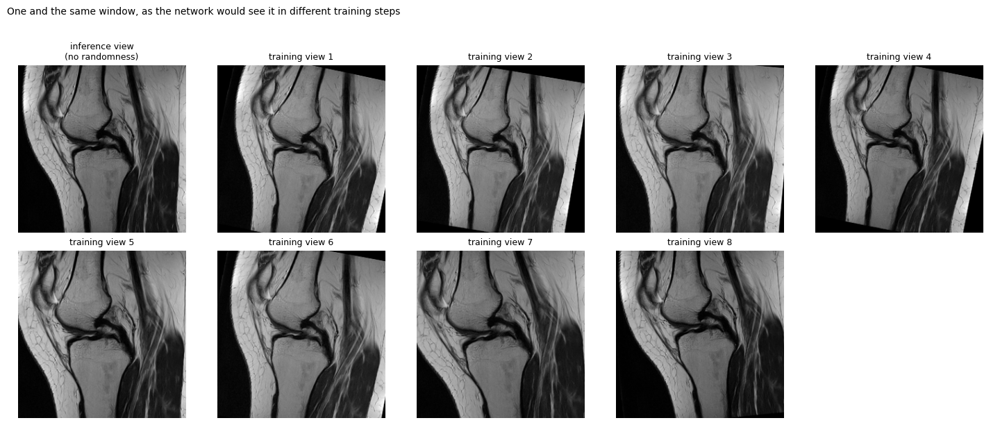

random change,range (read from make_views),why
rotation,-12 .. +12 degrees,knees are never positioned exactly straight
zoom,-12% .. +12%,knee size and field of view vary
shift,"up to 3% of the image width, any direction",the joint is not always centred
gamma (contrast curve),exponent 0.78 .. 1.28,scanners and sequences differ in contrast
gain (brightness),-10% .. +10%,overall signal level differs


All windows of ONE series get the same random values, so neighbouring slices still fit together.
There is no left-right flip in training: a flip would turn a medial finding into a lateral one.


In [71]:
# ======================= Part F.2 - data augmentation: what the network sees DURING training =======================
def AX_augmentation_gallery(n=8, seed=3, res=256):
    """Send one three-slice window through the reader's own make_views() several times with train=True.
    Each call draws new random rotation / zoom / shift / brightness values. With train=False (inference)
    the same function returns one fixed, centred view."""
    if AX_skip_while_scoring("F.2 augmentation"):
        return
    knee, pre = AX_reader_module("knee"), AX_reader_module("preprocess")
    sdir = AX_DEMO.get("main")
    if sdir is None:
        print("no example series available (Part D did not run)"); return
    vol, info = pre.load_series(str(sdir))
    j = len(vol) // 2
    window = vol[AX_np.clip([j - 1, j, j + 1], 0, len(vol) - 1)]                      # uint8 [3, 384, 384]
    batch = AX_torch.from_numpy(AX_np.repeat(window[None], n, axis=0))               # n copies; group=1 -> n independent draws
    AX_torch.manual_seed(seed)
    views = knee.make_views(batch, res, True, 1)
    plain = knee.make_views(batch[:1], res, False, 1)
    mean, std = knee.MEAN[1], knee.STD[1]
    to_img = lambda t: (t[1] * std + mean).clamp(0, 1).numpy()                       # centre slice, normalisation undone for display
    fig, axes = AX_plt.subplots(2, (n + 2) // 2, figsize=(2.9 * ((n + 2) // 2), 6.2))
    axes = axes.ravel()
    AX_imshow(axes[0], to_img(plain[0]), "inference view\n(no randomness)", vmin=0, vmax=1)
    for i in range(n):
        AX_imshow(axes[i + 1], to_img(views[i]), f"training view {i + 1}", vmin=0, vmax=1)
    for ax in axes[n + 1:]:
        ax.axis("off")
    fig.suptitle("One and the same window, as the network would see it in different training steps", fontsize=10, x=0.01, ha="left")
    AX_plt.tight_layout(rect=(0, 0, 1, 0.95), h_pad=2.2); AX_plt.show()
    AX_show(AX_pd.DataFrame([
        {"random change": "rotation", "range (read from make_views)": "-12 .. +12 degrees", "why": "knees are never positioned exactly straight"},
        {"random change": "zoom", "range (read from make_views)": "-12% .. +12%", "why": "knee size and field of view vary"},
        {"random change": "shift", "range (read from make_views)": "up to 3% of the image width, any direction", "why": "the joint is not always centred"},
        {"random change": "gamma (contrast curve)", "range (read from make_views)": "exponent 0.78 .. 1.28", "why": "scanners and sequences differ in contrast"},
        {"random change": "gain (brightness)", "range (read from make_views)": "-10% .. +10%", "why": "overall signal level differs"},
    ]), "Augmentations of the ConvNeXt reader")
    print("All windows of ONE series get the same random values, so neighbouring slices still fit together.\n"
          "There is no left-right flip in training: a flip would turn a medial finding into a lateral one.")


with AX_cell("F.2 augmentation"):
    AX_augmentation_gallery()

## F.3 Live training demo

**What.** A complete, small training run inside this notebook:

1. **Features.** The reader's trained backbone is kept *frozen* and turns every three-slice window of a study into one feature vector. This is done for `TRAIN_DEMO_STUDIES` studies that have report-derived labels and for the officially labelled studies.
2. **Two heads** are trained on these features, with the same loop (`AX_train_head`, about 25 lines):
   - *mean pooling*: average all windows, one linear layer;
   - *attention pooling*: every finding learns its own weighting of the windows, the idea both Branch A models use.
3. **Three curves** per head: the loss on training and held-out studies, the agreement with the LLM labels on held-out studies, and the AUC against official labels.

**Why frozen features.** Training a backbone takes hours on this hardware. Training a head on stored features takes seconds and shows the same mechanics: the loss falling, the gap between training and held-out loss, the effect of the pooling.

**What to look at.**
- *Left panel*: solid lines (training) keep falling. Where a dashed line (held-out) flattens or turns up, the head has begun to memorise.
- *Middle versus right panel*: agreement with a noisy teacher is not the same as accuracy. The two can move differently.
- *Blue versus orange*: whether per-finding attention beats plain averaging on this small sample.

**What not to conclude.** These are not accuracy figures for the pipeline. The training set is small, the evaluation sets hold a few dozen studies, and the backbone was trained by its author on this competition's studies, possibly including the ones used here.

studies: 96 for training + 24 held out (both labelled by the LLM from the report) + 58 with official labels (never trained on in this demo)
step 1: frozen backbone convnext_tiny.fb_in22k_ft_in1k turns every window into 768 numbers (8 windows per slot, 256px)
  [features] 40/178 studies | 71 s
  [features] 80/178 studies | 151 s
  [features] 120/178 studies | 217 s
  [features] 160/178 studies | 272 s
  [features] 178/178 studies | 306 s
        done in 320 s | feature tensor (178, 6, 8, 768) = [study, slot, window, feature]
step 2: train two heads on these features (the backbone stays frozen)
        mean pooling + linear layer        9,228 trainable parameters | 40 epochs in 0.7 s
        attention pooling per finding    236,440 trainable parameters | 40 epochs in 0.5 s


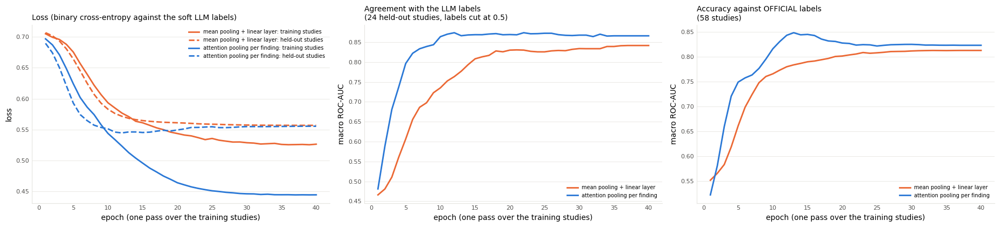

head,train loss,val loss,AUC vs LLM labels (held-out studies),AUC vs official labels
mean pooling + linear layer,0.526,0.557,0.842,0.813
attention pooling per finding,0.445,0.555,0.866,0.823


How to read this:
 - The loss on the training studies keeps falling; when the held-out loss stops falling or rises, the head has
   started to memorise its training studies (overfitting). That is why checkpoints are chosen on held-out data.
 - 'Agreement with the LLM labels' and 'accuracy against official labels' are two different things: the first
   says how well the head imitates a noisy teacher, only the second compares with a radiologist's label.
 - Do not read these numbers as the accuracy of the pipeline: 96 training studies, a few dozen evaluation
   studies, and a backbone whose author trained it on this competition's data (possibly on these very studies).


In [72]:
# ======================= Part F.3 - live training demo: train two small heads on frozen features =======================
import torch.nn as AX_nn

AX_demo = None        # results of the demo (curves, final scores), kept for the summary


def AX_extract_features(studies, series_rows, series_dir, model, res, k, label):
    """Frozen backbone: every 3-slice window -> one feature vector. Returns [study, 6 slots, k, D] and the slot mask."""
    knee = AX_reader_module("knee")
    slots = AX_reader_slots(series_rows[series_rows[AX_UID].isin(set(studies))], series_dir)
    decode = lambda st: AX_reader_item(st, slots.get(st, [[] for _ in range(6)]), series_dir, k=k)   # CPU: DICOM -> uint8 windows
    dim = model.enc.num_features
    feats, masks, t0 = AX_torch.zeros(len(studies), 6, k, dim), AX_torch.zeros(len(studies), 6, dtype=AX_torch.bool), time.time()
    for n, (x, mask, _) in enumerate(AX_in_order(decode, studies)):
        if mask.any():
            present = AX_torch.from_numpy(x[mask]).to(AX_DEV).flatten(0, 1)                       # windows of the slots that exist
            with AX_torch.no_grad(), AX_torch.autocast("cuda", dtype=AX_torch.float16, enabled=AX_DEV == "cuda"):
                f = model.enc(knee.make_views(present, res, False, k).contiguous(memory_format=AX_torch.channels_last))
            feats[n, AX_torch.from_numpy(mask)] = f.float().view(-1, k, dim).cpu()
            masks[n] = AX_torch.from_numpy(mask)
        if (n + 1) % 40 == 0 or (n + 1) == len(studies):
            print(f"  [{label}] {n + 1}/{len(studies)} studies | {time.time() - t0:.0f} s", flush=True)
    return feats, masks


class AX_MeanPoolHead(AX_nn.Module):
    """Baseline head: average the feature vectors of all windows, then ONE linear layer -> 12 logits."""

    def __init__(self, dim):
        super().__init__()
        self.drop = AX_nn.Dropout(0.2)
        self.fc = AX_nn.Linear(dim, 12)

    def forward(self, feats, real, slot_id):          # feats [B, T, D], real [B, T] (True = window exists)
        w = real.float().unsqueeze(-1)
        pooled = (feats * w).sum(1) / w.sum(1).clamp_min(1.0)
        return self.fc(self.drop(pooled))


class AX_AttentionHead(AX_nn.Module):
    """Attention head (the idea both Branch A models use): every finding learns its OWN weighting of the windows."""

    def __init__(self, dim, hidden=256):
        super().__init__()
        self.proj = AX_nn.Sequential(AX_nn.Dropout(0.2), AX_nn.Linear(dim, hidden), AX_nn.LayerNorm(hidden))
        self.slot = AX_nn.Embedding(6, hidden)                                       # which series a window comes from
        self.att = AX_nn.Sequential(AX_nn.Linear(hidden, 128), AX_nn.Tanh(), AX_nn.Linear(128, 12))
        self.cls_w = AX_nn.Parameter(AX_torch.randn(12, hidden) * 0.02)
        self.cls_b = AX_nn.Parameter(AX_torch.zeros(12))

    def forward(self, feats, real, slot_id):
        h = self.proj(feats) + self.slot(slot_id)                                    # [B, T, hidden]
        a = self.att(h).masked_fill(~real.unsqueeze(-1), -1e4).softmax(1)            # [B, T, 12]: weights over windows, per finding
        pooled = AX_torch.einsum("btc,btd->bcd", a, h)                               # [B, 12, hidden]: one summary per finding
        return (pooled * self.cls_w).sum(-1) + self.cls_b


def AX_train_head(head, data, epochs=40, lr=1e-3, weight_decay=0.05, batch=32, seed=0):
    """A complete training loop in 25 lines. data: dict of tensors already on the device."""
    AX_torch.manual_seed(seed)
    head = head.to(AX_DEV)
    opt = AX_torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=weight_decay)
    sched = AX_torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * ((len(data["train_x"]) + batch - 1) // batch))
    loss_fn = AX_nn.BCEWithLogitsLoss()                    # works with soft targets (0.8 = "probably present")
    history = []
    for epoch in range(epochs):
        head.train()
        order = AX_torch.randperm(len(data["train_x"]), device=AX_DEV)
        total = 0.0
        for i in range(0, len(order), batch):
            idx = order[i:i + batch]
            loss = loss_fn(head(data["train_x"][idx], data["train_real"][idx], data["slot_id"]), data["train_y"][idx])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            total += float(loss) * len(idx)
        head.eval()
        with AX_torch.no_grad():
            val_logit = head(data["val_x"], data["val_real"], data["slot_id"])
            row = {"epoch": epoch + 1, "train loss": total / len(order), "val loss": float(loss_fn(val_logit, data["val_y"])),
                   "AUC vs LLM labels (held-out studies)": float(AX_np.nanmean(AX_auc_matrix(
                       (data["val_y"] >= 0.5).float().cpu().numpy(), val_logit.cpu().numpy())))}
            if "gold_x" in data:
                gold_logit = head(data["gold_x"], data["gold_real"], data["slot_id"]).cpu().numpy()
                row["AUC vs official labels"] = float(AX_np.nanmean(AX_auc_matrix(data["gold_y"], gold_logit)))
        history.append(row)
    return head, AX_pd.DataFrame(history)


def AX_training_demo(k=8, epochs=40, seed=0):
    global AX_demo
    if not AX_DEMOS:
        print("live training demo skipped (RUN_DEMOS = False, or Kaggle scoring run)"); return
    if AX_llm is None:
        print("live training demo skipped: the LLM label table was not loaded in Part C"); return
    ckpts = AX_reader_ckpts()
    series_csv, series_dir = AX_COMP / "train_series.csv", AX_COMP / "train_series"
    if not ckpts or not series_csv.is_file():
        print("live training demo skipped: reader checkpoint or training images not available"); return
    gold = AX_find_gold()[0]
    gold = gold.dropna(how="any") if gold is not None else AX_pd.DataFrame(columns=AX_LAB)
    labelled = AX_llm[AX_LAB].dropna(how="any")
    pool = [u for u in labelled.index if u not in gold.index and (series_dir / u).is_dir()]
    rng = AX_np.random.default_rng(seed)
    chosen = [pool[i] for i in rng.permutation(len(pool))[:int(TRAIN_DEMO_STUDIES)]]
    if len(chosen) < 20:
        print(f"live training demo skipped: only {len(chosen)} report-labelled studies with images found"); return
    n_val = max(4, len(chosen) // 5)
    train_ids, val_ids = chosen[n_val:], chosen[:n_val]
    gold_ids = [u for u in gold.index if (series_dir / u).is_dir()]
    series_rows = AX_pd.read_csv(series_csv, dtype={AX_UID: str, "SeriesInstanceUID": str})
    print(f"studies: {len(train_ids)} for training + {len(val_ids)} held out (both labelled by the LLM from the report) "
          f"+ {len(gold_ids)} with official labels (never trained on in this demo)")
    model = None
    try:
        model, args = AX_load_reader(ckpts[0])
        res, t0 = int(args["res"]), time.time()
        print(f"step 1: frozen backbone {args['backbone']} turns every window into {model.enc.num_features} numbers "
              f"({k} windows per slot, {res}px)")
        feats, masks = AX_extract_features(train_ids + val_ids + gold_ids, series_rows, str(series_dir), model, res, k, "features")
        print(f"        done in {time.time() - t0:.0f} s | feature tensor {tuple(feats.shape)} = [study, slot, window, feature]")
    finally:
        del model
        AX_free_gpu()
    n_tr, n_va = len(train_ids), len(val_ids)
    flat = feats.flatten(1, 2).to(AX_DEV)                                              # [study, 6*k windows, D]
    real = masks.unsqueeze(-1).expand(-1, 6, k).reshape(len(masks), 6 * k).to(AX_DEV)
    target = lambda ids: AX_torch.tensor(labelled.loc[ids].to_numpy(AX_np.float32), device=AX_DEV)
    data = {"train_x": flat[:n_tr], "train_real": real[:n_tr], "train_y": target(train_ids),
            "val_x": flat[n_tr:n_tr + n_va], "val_real": real[n_tr:n_tr + n_va], "val_y": target(val_ids),
            "slot_id": AX_torch.arange(6, device=AX_DEV).repeat_interleave(k)}
    if gold_ids:
        data.update(gold_x=flat[n_tr + n_va:], gold_real=real[n_tr + n_va:], gold_y=gold.loc[gold_ids, AX_LAB].to_numpy(float))
    dim = flat.shape[-1]
    print("step 2: train two heads on these features (the backbone stays frozen)")
    runs = {}
    for name, head in (("mean pooling + linear layer", AX_MeanPoolHead(dim)), ("attention pooling per finding", AX_AttentionHead(dim))):
        t0 = time.time()
        trained, hist = AX_train_head(head, data, epochs=epochs, seed=seed)
        runs[name] = hist
        print(f"        {name:<30s} {sum(p.numel() for p in trained.parameters()):>9,d} trainable parameters | "
              f"{epochs} epochs in {time.time() - t0:.1f} s")
    AX_demo = {"runs": runs, "n_train": n_tr, "n_val": n_va, "n_gold": len(gold_ids)}

    colours = {"mean pooling + linear layer": AX_C["orange"], "attention pooling per finding": AX_C["blue"]}
    has_gold = "AUC vs official labels" in next(iter(runs.values()))
    fig, ax = AX_plt.subplots(1, 3 if has_gold else 2, figsize=(6.2 * (3 if has_gold else 2), 4.3))
    for name, hist in runs.items():
        ax[0].plot(hist["epoch"], hist["train loss"], color=colours[name], lw=2, label=f"{name}: training studies")
        ax[0].plot(hist["epoch"], hist["val loss"], color=colours[name], lw=2, ls="--", label=f"{name}: held-out studies")
        ax[1].plot(hist["epoch"], hist["AUC vs LLM labels (held-out studies)"], color=colours[name], lw=2, label=name)
        if has_gold:
            ax[2].plot(hist["epoch"], hist["AUC vs official labels"], color=colours[name], lw=2, label=name)
    ax[0].set_title("Loss (binary cross-entropy against the soft LLM labels)", fontsize=10, loc="left")
    ax[0].set_ylabel("loss"); ax[0].legend(fontsize=7, frameon=False)
    ax[1].set_title(f"Agreement with the LLM labels\n({n_va} held-out studies, labels cut at 0.5)", fontsize=10, loc="left")
    ax[1].set_ylabel("macro ROC-AUC"); ax[1].legend(fontsize=7, frameon=False)
    if has_gold:
        ax[2].set_title(f"Accuracy against OFFICIAL labels\n({len(gold_ids)} studies)", fontsize=10, loc="left")
        ax[2].set_ylabel("macro ROC-AUC"); ax[2].legend(fontsize=7, frameon=False)
    for a in ax:
        a.set_xlabel("epoch (one pass over the training studies)"); AX_style(a, "y")
    AX_plt.tight_layout(); AX_plt.show()

    last = AX_pd.DataFrame({name: hist.iloc[-1].drop("epoch") for name, hist in runs.items()}).T
    last.index.name = "head"
    AX_show(last.reset_index().round(4), f"After {epochs} epochs")
    print("How to read this:")
    print(" - The loss on the training studies keeps falling; when the held-out loss stops falling or rises, the head has")
    print("   started to memorise its training studies (overfitting). That is why checkpoints are chosen on held-out data.")
    print(" - 'Agreement with the LLM labels' and 'accuracy against official labels' are two different things: the first")
    print("   says how well the head imitates a noisy teacher, only the second compares with a radiologist's label.")
    print(f" - Do not read these numbers as the accuracy of the pipeline: {n_tr} training studies, a few dozen evaluation")
    print("   studies, and a backbone whose author trained it on this competition's data (possibly on these very studies).")


with AX_cell("F.3 live training demo"):
    AX_training_demo()

# Part G — Experiment: does the image processing matter?

**Question.** Part D claimed that each preprocessing step is needed. This experiment tests it: the ConvNeXt reader predicts the officially labelled studies six times, once with its own preprocessing and five times with **one step replaced by a naive alternative**.

| Variant | What is changed | Step in Part D |
|---|---|---|
| reference | nothing | — |
| no millimetre crop | the whole image is resized to the square, whatever its pixel size | D.3 |
| min–max scaling | intensities scaled by minimum and maximum instead of percentiles | D.4 |
| file-name order | slices sorted by file name as text instead of by position | D.2 |
| no standard orientation | images used as stored, not turned to the reader's standard view | D.5 |
| no neighbouring slices | the same slice in all three channels | D.6 |

**How it is kept honest.**
- The variants are produced by `AX_canonical_volume`, a re-statement of the reader's `load_series` with four switches. Before any result is used, the cell checks that with all switches off it returns **exactly** the same volume as the reader's own function.
- All variants are scored on the same studies, and the uncertainty of each *change* comes from a paired bootstrap (the same resampled studies for both sides).
- One plain pass per fold, no test-time augmentation, so that differences come from the preprocessing alone.

**How to read the result.**
- The model was trained with the reference preprocessing. The experiment therefore measures the cost of a **mismatch between training and inference**. A model trained with min–max scaling from the start might do fine with it; a model trained with percentiles and served min–max does not have to.
- "Inside the noise" means the change cannot be measured with this many studies. It does not mean the step is unnecessary.
- The absolute AUCs are optimistic (the studies belong to the training data). The changes between variants are the result.

58 officially labelled studies x 6 preprocessing variants | 3 reader fold(s), one plain pass each at 256px, 16 windows per slot (no test-time augmentation)
  10/58 studies | 50 s
  20/58 studies | 91 s
  30/58 studies | 132 s
  40/58 studies | 173 s
  50/58 studies | 213 s
  58/58 studies | 246 s
self-test: the reference variant equals the reader's own load_series for every series of the first 3 studies: True


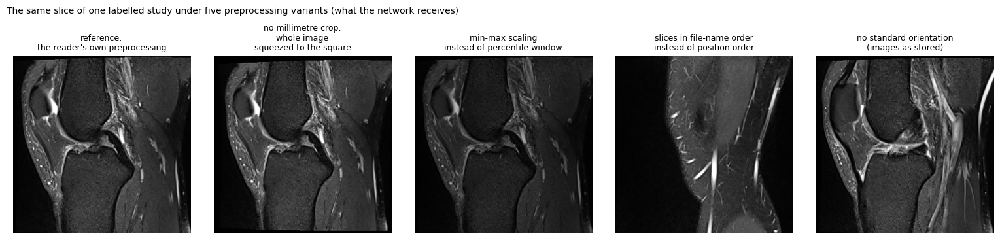

variant,macro AUC,change vs reference,95% low,95% high,verdict
reference: the reader's own preprocessing,0.915,0.000,0.000,0.000,-
no millimetre crop: whole image squeezed to the square,0.916,0.001,-0.004,0.006,inside the noise
min-max scaling instead of percentile window,0.916,0.001,-0.007,0.007,inside the noise
slices in file-name order instead of position order,0.884,-0.031,-0.056,-0.008,clear loss
no standard orientation (images as stored),0.914,-0.001,-0.006,0.004,inside the noise
no neighbouring slices (same slice in all 3 channels),0.908,-0.007,-0.019,0.003,inside the noise


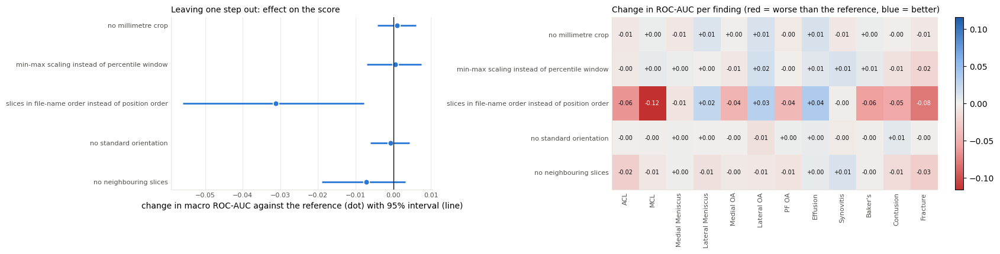

How to read this:
 - The model was TRAINED with the reference preprocessing. The experiment therefore measures how much a
   mismatch between training and inference costs, which is the most common preprocessing bug in practice.
 - 58 studies give wide intervals: a change marked 'inside the noise' is not shown to be harmless,
   it is just not measurable with this many studies.
 - The absolute AUC values are optimistic: these studies are part of the competition's training data and the
   reader's author may have trained on them. The CHANGES between variants are the result of interest.


In [73]:
# ======================= Part G - experiment: what happens when one preprocessing step is left out? =======================
AX_experiment = None

AX_VARIANTS = [   # (name, switches for AX_canonical_volume, use neighbouring slices?)
    ("reference: the reader's own preprocessing", {}, True),
    ("no millimetre crop: whole image squeezed to the square", {"physical": False}, True),
    ("min-max scaling instead of percentile window", {"percentile": False}, True),
    ("slices in file-name order instead of position order", {"order": "filename"}, True),
    ("no standard orientation (images as stored)", {"canonical": False}, True),
    ("no neighbouring slices (same slice in all 3 channels)", {}, False),
]


def AX_raw_series(sdir):
    """Decode every file of a series ONCE: [(file name, image, orientation, position, pixel spacing, instance number)]."""
    pre = AX_reader_module("preprocess")
    items = []
    for fn in os.listdir(sdir):
        try:
            items.extend((fn,) + rec for rec in pre._read(os.path.join(sdir, fn)))
        except Exception:
            pass
    return items


def AX_canonical_volume(raw, physical=True, percentile=True, order="position", canonical=True):
    """preprocess.load_series written out again with four switches. With every switch at its default this
    must return exactly the same volume as load_series (the experiment checks that before it trusts itself)."""
    import cv2
    pre = AX_reader_module("preprocess")
    names, slices = [r[0] for r in raw], [r[1:] for r in raw]
    if not slices:
        return AX_np.zeros((1, pre.SIZE, pre.SIZE), AX_np.uint8)
    iop = next((s[1] for s in slices if s[1] is not None), None)
    normal = AX_np.cross(iop[:3], iop[3:]) if iop is not None else None
    plane = int(AX_np.abs(normal).argmax()) if normal is not None else 0
    idx = list(range(len(slices)))
    if order == "filename":
        idx.sort(key=lambda i: names[i])                                   # text order: '10.dcm' sorts before '2.dcm'
    elif normal is not None and all(s[2] is not None for s in slices):
        sgn = pre.CANON[plane][0] * AX_np.sign(normal[plane]) if canonical else 1.0
        idx.sort(key=lambda i: float(AX_np.dot(slices[i][2], normal)) * sgn)   # physical position along the scan direction
    else:
        idx.sort(key=lambda i: slices[i][4])
    slices = [slices[i] for i in idx]
    if len(slices) > pre.MAX_SLICES:
        keep = AX_np.linspace(0, len(slices) - 1, pre.MAX_SLICES).round().astype(int)
        slices = [slices[i] for i in keep]

    def one(s):
        if canonical:
            img, ps = pre._canon_slice(s[0], s[1], s[3], plane)            # flips / transposes to the standard view
        else:
            img, ps = s[0], (s[3] or [pre.MM_PER_PX * s[0].shape[0] / pre.SIZE] * 2)
        if physical:
            return pre._resample(img, ps)                                  # fixed mm crop, fixed mm per pixel
        img = AX_np.ascontiguousarray(img)
        return cv2.resize(img, (pre.SIZE, pre.SIZE), interpolation=cv2.INTER_AREA if img.shape[0] > pre.SIZE else cv2.INTER_LINEAR)

    vol = AX_np.stack([one(s) for s in slices])
    lo, hi = AX_np.percentile(vol[:, ::4, ::4], [1, 99.5]) if percentile else (float(vol.min()), float(vol.max()))
    vol = AX_np.clip((vol - lo) / max(hi - lo, 1e-6), 0, 1)
    return (vol * 255).round().astype(AX_np.uint8)


def AX_variant_item(study, slots, series_dir, k, check):
    """One study prepared in every variant: uint8 [variant, 6 slots, k, 3, 384, 384], slot mask, slice positions,
    and (if check) whether the reference variant equals the reader's own load_series for every series."""
    pre = AX_reader_module("preprocess")
    x = AX_np.zeros((len(AX_VARIANTS), 6, k, 3, pre.SIZE, pre.SIZE), AX_np.uint8)
    mask, pos, same = AX_np.zeros(6, bool), AX_np.zeros((6, k), AX_np.float32), True
    for s, cands in enumerate(slots):
        if not cands:
            continue
        sdir = os.path.join(series_dir, study, cands[0])
        raw = AX_raw_series(sdir)                                             # decode the files once ...
        vols = {}
        for v, (_, switches, context) in enumerate(AX_VARIANTS):
            key = tuple(sorted(switches.items()))
            if key not in vols:
                vols[key] = AX_canonical_volume(raw, **switches)              # ... and build every variant from the same pixels
            if len(vols[key]) < 3:
                break
            x[v, s], pos[s] = AX_reader_windows(vols[key], k, context)
        else:
            mask[s] = True
        if check and same:
            same = bool(AX_np.array_equal(vols[()], pre.load_series(sdir)[0]))
    return x, mask, pos, same


def AX_preprocessing_experiment(k=16, n_boot=2000):
    global AX_experiment
    if not AX_DEMOS:
        print("experiment skipped (RUN_DEMOS = False, or Kaggle scoring run)"); return
    ckpts = AX_reader_ckpts()
    series_csv, series_dir = AX_COMP / "train_series.csv", AX_COMP / "train_series"
    gold = AX_find_gold()[0]
    if not ckpts or gold is None or not series_csv.is_file():
        print("experiment skipped: reader checkpoints, official labels or training images not available"); return
    gold = gold.dropna(how="any")
    ids = [u for u in gold.index if (series_dir / u).is_dir()][:int(EXPERIMENT_STUDIES)]
    if len(ids) < 10:
        print(f"experiment skipped: only {len(ids)} officially labelled studies with images"); return
    y = gold.loc[ids, AX_LAB].to_numpy(float)
    series_rows = AX_pd.read_csv(series_csv, dtype={AX_UID: str, "SeriesInstanceUID": str})
    slots = AX_reader_slots(series_rows[series_rows[AX_UID].isin(set(ids))], str(series_dir))
    prepare = lambda item: AX_variant_item(item[1], slots.get(item[1], [[] for _ in range(6)]), str(series_dir), k, check=item[0] < 3)
    models, preds, checked, picture = [], AX_np.zeros((len(AX_VARIANTS), len(ids), 12), AX_np.float32), [], None
    try:
        models = [AX_load_reader(p) for p in ckpts[:3]]
        print(f"{len(ids)} officially labelled studies x {len(AX_VARIANTS)} preprocessing variants | {len(models)} reader fold(s), "
              f"one plain pass each at {int(models[0][1]['res'])}px, {k} windows per slot (no test-time augmentation)")
        t0 = time.time()
        for i, (x, mask, pos, same) in enumerate(AX_in_order(prepare, enumerate(ids), ahead=4)):
            if i < 3:
                checked.append(same)
                if not same:
                    raise RuntimeError("self-test failed: the reference variant does not reproduce preprocess.load_series")
            if picture is None and mask[0]:
                picture = x[:5, 0, k // 2, 1].copy()                          # sagittal fat-suppressed slot, centre slice, 5 variants
            mt, pt = AX_torch.from_numpy(mask)[None].to(AX_DEV), AX_torch.from_numpy(pos)[None].to(AX_DEV)
            with AX_torch.no_grad(), AX_torch.autocast("cuda", dtype=AX_torch.float16, enabled=AX_DEV == "cuda"):
                for v in range(len(AX_VARIANTS)):
                    xv = AX_torch.from_numpy(x[v])[None].to(AX_DEV)
                    preds[v, i] = AX_torch.stack([m(xv, mt, pt, res=int(a["res"])).float().sigmoid() for m, a in models]).mean(0)[0].cpu().numpy()
            if (i + 1) % 10 == 0 or i + 1 == len(ids):
                print(f"  {i + 1}/{len(ids)} studies | {time.time() - t0:.0f} s", flush=True)
    finally:
        del models
        AX_free_gpu()
    print(f"self-test: the reference variant equals the reader's own load_series for every series of the first {len(checked)} studies: {all(checked)}")

    if picture is not None:
        fig, ax = AX_plt.subplots(1, 5, figsize=(15.5, 3.7))
        for a, im, (name, _, _) in zip(ax, picture, AX_VARIANTS):
            AX_imshow(a, im, name.replace(": ", ":\n").replace(" instead", "\ninstead").replace(" squeezed", "\nsqueezed").replace(" (images", "\n(images"), vmin=0, vmax=255)
        fig.suptitle("The same slice of one labelled study under five preprocessing variants (what the network receives)", fontsize=10, x=0.01, ha="left")
        AX_plt.tight_layout(rect=(0, 0, 1, 0.92)); AX_plt.show()

    names = [v[0] for v in AX_VARIANTS]
    sets = {n: preds[i] for i, n in enumerate(names)}
    per = AX_pd.DataFrame({n: AX_auc_matrix(y, s) for n, s in sets.items()}, index=AX_LAB).T
    boot = AX_boot_macro(y, sets, n_boot)
    rows = []
    for n in names:
        d = boot[n] - boot[names[0]]
        lo, hi = AX_np.nanpercentile(d, [2.5, 97.5])
        rows.append({"variant": n, "macro AUC": float(AX_np.nanmean(per.loc[n])), "change vs reference": float(AX_np.nanmean(per.loc[n]) - AX_np.nanmean(per.loc[names[0]])),
                     "95% low": lo, "95% high": hi,
                     "verdict": "-" if n == names[0] else ("clear loss" if hi < 0 else "clear gain" if lo > 0 else "inside the noise")})
    table = AX_pd.DataFrame(rows)
    AX_experiment = {"table": table, "per_finding": per, "n": len(ids)}
    AX_show(table.round(4), f"Macro ROC-AUC against official labels, {len(ids)} studies (interval: paired bootstrap of the change)")

    fig, ax = AX_plt.subplots(1, 2, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1, 1.35]})
    t = table.iloc[1:][::-1]
    yy = AX_np.arange(len(t))
    ax[0].hlines(yy, t["95% low"], t["95% high"], color=AX_C["blue"], lw=2)
    ax[0].plot(t["change vs reference"], yy, "o", color=AX_C["blue"], ms=7, mec="white", mew=1.2)
    ax[0].axvline(0, color=AX_C["ink"], lw=1)
    ax[0].set_yticks(yy, [n.split(":")[0].split(" (")[0] for n in t["variant"]], fontsize=8)
    ax[0].set_xlabel("change in macro ROC-AUC against the reference (dot) with 95% interval (line)")
    ax[0].set_title("Leaving one step out: effect on the score", fontsize=10, loc="left"); AX_style(ax[0])
    delta = (per.iloc[1:] - per.iloc[0]).to_numpy(float)
    lim = max(0.05, float(AX_np.nanmax(AX_np.abs(delta))))
    im = ax[1].imshow(delta, cmap=AX_DIV.reversed(), vmin=-lim, vmax=lim, aspect="auto")
    ax[1].set_xticks(range(12), AX_LAB, rotation=90, fontsize=8)
    ax[1].set_yticks(range(len(names) - 1), [n.split(":")[0].split(" (")[0] for n in names[1:]], fontsize=8)
    for i in range(delta.shape[0]):
        for j in range(delta.shape[1]):
            if AX_np.isfinite(delta[i, j]):
                ax[1].text(j, i, f"{delta[i, j]:+.2f}", ha="center", va="center", fontsize=7,
                           color="white" if abs(delta[i, j]) > 0.6 * lim else AX_C["ink"])
    ax[1].set_title("Change in ROC-AUC per finding (red = worse than the reference, blue = better)", fontsize=10, loc="left")
    AX_style(ax[1], None); fig.colorbar(im, ax=ax[1], fraction=0.03)
    AX_plt.tight_layout(); AX_plt.show()
    print("How to read this:")
    print(" - The model was TRAINED with the reference preprocessing. The experiment therefore measures how much a")
    print("   mismatch between training and inference costs, which is the most common preprocessing bug in practice.")
    print(f" - {len(ids)} studies give wide intervals: a change marked 'inside the noise' is not shown to be harmless,")
    print("   it is just not measurable with this many studies.")
    print(" - The absolute AUC values are optimistic: these studies are part of the competition's training data and the")
    print("   reader's author may have trained on them. The CHANGES between variants are the result of interest.")


with AX_cell("G preprocessing experiment"):
    AX_preprocessing_experiment()

# Part H — Results: did the run do what it should, and what did the models say?

Everything below only *reads* files the pipeline wrote. No model is run again and the published file cannot change.

## H.1 Run health and submission validation

**Run health** answers one question: *which models really contributed to the published file?* Both branches tolerate failures in order to keep a submission alive, so a complete-looking `submission.csv` does not prove that everything ran. Look for the word CHECK.

**Submission validation** is an independent check against `sample_submission.csv` and `test.csv`: column names and order, the 12 findings, one row per study, the same studies in the same order, finite values in 0–1.

In [74]:
# ======================= Part H.1 - run health report and submission validation =======================
def AX_final_file():
    """submission.csv in submit mode, validation_predictions.csv in validate mode."""
    for name in ("submission.csv", "validation_predictions.csv"):
        if (AX_OUT / name).is_file():
            return AX_OUT / name
    raise FileNotFoundError("no final prediction file found - did the pipeline finish?")


def AX_branch_b_complete():
    return bool(AX_PUBLISHED) and AX_PUBLISHED.get("branch_b_status") == "complete"


def AX_health_report():
    """One table answering: which models really contributed to the published predictions?"""
    diag = AX_OUT / "diagnostics"
    load = lambda p: json.loads(AX_Path(p).read_text()) if AX_Path(p).is_file() else {}
    n = len(AX_test_ids())
    rows = []

    def add(component, expected, got, ok, note=""):
        rows.append({"component": component, "expected": expected, "found": got, "status": "OK" if ok else "CHECK", "note": note})

    # ---- Branch A ----
    raw = AX_A_FILES["coatnet_raw"]
    if raw.is_file():
        p = AX_np.load(raw, allow_pickle=False)["values"][0]
        good = int(len(p) - (p == 0.5).all(axis=1).sum())
        add("A1  CoAtNet: studies predicted", n, good, good == n, "a study whose inference fails keeps the neutral value 0.5")
    else:
        add("A1  CoAtNet: studies predicted", n, "unknown", False, "raw probabilities were not saved")
    n_ck = len(globals().get("_o_ck", []))
    add("A2  ConvNeXt reader: checkpoints used", ">= 1", n_ck, n_ck >= 1, "all checkpoints found in the attached dataset are averaged")
    add("A2  ConvNeXt reader: prediction file", "present", "present" if AX_A_FILES["convnext"].is_file() else "missing",
        AX_A_FILES["convnext"].is_file())
    level = globals().get("AX_BRANCH_A_LEVEL", "unknown")
    add("A3  fusion level reached", "final weight table", level.split(" (")[0], level.startswith("fusion with the final"), level)
    # ---- Branch B ----
    b_note = "blended in" if AX_BRANCH_B_WEIGHT > 0 else "shown for teaching (weight 0): not part of the published file"
    if not AX_USE_BRANCH_B:
        add("B   first notebook's pipeline", "-", "not run", True, AX_BRANCH_B_OFF_REASON)
    elif not AX_branch_b_complete():
        add("B   first notebook's pipeline", "complete", "did not complete", AX_BRANCH_B_WEIGHT == 0, (AX_PUBLISHED or {}).get("branch_b_status", "final blend did not run")
            + (" | harmless for the published file: its blend weight is 0" if AX_BRANCH_B_WEIGHT == 0 else ""))
    else:
        n_dino = len(list(diag.glob("dino_*.npz")))
        add("B1  DINOv2 members", 20, n_dino, n_dino == 20, "each member passed its stored fingerprint test")
        a5 = load(diag / "a5_applicability.json"); meta = load(diag / "a5_metadata_applicability.json")
        expect_a5 = n - len(meta.get("no_matching_acquisition_uids", [])); got_a5 = a5.get("available_count", 0)
        add("B2  A5: studies predicted", expect_a5, got_a5, got_a5 >= 0.75 * expect_a5 and expect_a5 > 0,
            "studies without a usable series keep the DINOv2-only score")
        if (AX_OUT / "raptor_raw.npz").is_file():
            r = AX_np.load(AX_OUT / "raptor_raw.npz", allow_pickle=False)["raw_probabilities"]
            done = int(AX_np.isfinite(r).all(axis=2).sum())
            add("B4  Raptor: (view, study) pairs predicted", r.shape[0] * r.shape[1], done, done == r.shape[0] * r.shape[1])
        members = load(AX_OUT / "_coat_raptor_blend_receipt.json").get("members", [])
        add("B5  CoAtNet family members", 4, len(members), len(members) == 4, ", ".join(members) or "none")
        add("B   result", "present", "present" if AX_B_FILE.is_file() else "missing", AX_B_FILE.is_file(), b_note)
    # ---- Branch S ----
    s_state = globals().get("AX_BRANCH_S", {"status": "not run", "detail": ""})
    if not AX_USE_BRANCH_S:
        add("S   our own model", "-", "not run", True, AX_BRANCH_S_OFF_REASON)
    else:
        add("S   our own model (DINOv2 fold heads)", "complete", s_state["status"], s_state["status"] == "complete" or AX_BRANCH_S_WEIGHT == 0,
            s_state["detail"] + (" | blended in" if AX_BRANCH_S_WEIGHT > 0 else " | shown for teaching (weight 0): not part of the published file"))
    # ---- final ----
    pub = AX_PUBLISHED or {}
    add("C   published file", "written", pub.get("file", "missing"), bool(pub), pub.get("rule", ""))
    AX_show(AX_pd.DataFrame(rows), f"Run health: {n:,} studies, {(time.time() - AX_T_START) / 3600:.2f} h since notebook start")
    if AX_BRANCH_B["failed"]:
        print("Branch B failure:", AX_BRANCH_B["failed"])

    events = AX_pd.Series([e.get("kind", "?") for e in load(diag / "branch_b_audit.json").get("events", [])], dtype=object)
    if events.empty:
        print("Branch B audit trail: no events available"); return
    worrying = re.compile(r"fail|fallback|neutral|unfilled|empty|reject|unavailable|nonfinite|no_metadata|no_files|mismatch|incomplete|"
                          r"dropped|zeroed|repair|partial|error|unreadable|skipped|retry")
    counts = events.value_counts().rename_axis("event").reset_index(name="count")
    counts["meaning"] = counts["event"].map(lambda k: "degraded input or fallback - look at it" if worrying.search(k) else "informational")
    AX_show(counts.sort_values(["meaning", "count"], ascending=[True, False]).reset_index(drop=True),
            "Branch B audit trail: events recorded during the run")


def AX_validate_submission():
    """Independent re-check of the published file against the competition's own templates (read-only)."""
    root = AX_test_root()
    sub_path = AX_final_file()
    sub = AX_pd.read_csv(sub_path, dtype={AX_UID: str})
    test = AX_pd.read_csv(root / "test.csv", dtype={AX_UID: str})
    sample = AX_pd.read_csv(root / "sample_submission.csv", dtype={AX_UID: str})
    vals = sub[[c for c in sub.columns if c != AX_UID]].apply(AX_pd.to_numeric, errors="coerce").to_numpy(float)
    checks = [
        ("columns equal the sample submission, in the same order", list(sub.columns) == list(sample.columns), f"{len(sub.columns)} columns"),
        ("the 12 findings are in the competition order", list(sub.columns[1:]) == AX_LAB, ", ".join(sub.columns[1:4]) + ", ..."),
        ("one row per test study", len(sub) == len(test), f"{len(sub):,} rows vs {len(test):,} studies"),
        ("no duplicated study", sub[AX_UID].is_unique, ""),
        ("same set of studies as test.csv", set(sub[AX_UID]) == set(test[AX_UID]), ""),
        ("same row order as test.csv", sub[AX_UID].tolist() == test[AX_UID].tolist(), "order is not scored, but a mismatch would hint at a bug"),
        ("every value is a finite number", bool(AX_np.isfinite(vals).all()), f"{int((~AX_np.isfinite(vals)).sum())} bad cells"),
        ("every value lies in [0, 1]", bool(((vals >= 0) & (vals <= 1)).all()), f"range {AX_np.nanmin(vals):.4f} - {AX_np.nanmax(vals):.4f}"),
        ("no finding has a constant prediction", bool((AX_np.nanstd(vals, axis=0) > 0).all()) or len(sub) < 2, "a constant column scores AUC 0.5"),
    ]
    AX_show(AX_pd.DataFrame([{"check": c, "result": "PASS" if ok else "FAIL", "detail": d} for c, ok, d in checks]),
            f"Validation of {sub_path.name}")
    ties = 1 - AX_np.array([len(AX_np.unique(vals[:, j])) for j in range(vals.shape[1])]) / max(len(sub), 1)
    print(f"share of tied values per finding: max {ties.max():.1%} (ties are harmless for AUC but many ties would mean lost resolution)")
    if not all(ok for _, ok, _ in checks):
        print("AT LEAST ONE CHECK FAILED - do not submit this file before understanding why.")


with AX_cell("H.1 run health"):
    AX_health_report()
with AX_cell("H.1 submission validation"):
    AX_validate_submission()

component,expected,found,status,note
A1 CoAtNet: studies predicted,3,3,OK,a study whose inference fails keeps the neutral value 0.5
A2 ConvNeXt reader: checkpoints used,>= 1,3,OK,all checkpoints found in the attached dataset are averaged
A2 ConvNeXt reader: prediction file,present,present,OK,
A3 fusion level reached,final weight table,fusion with the final weight table,OK,fusion with the final weight table (the intended result)
B1 DINOv2 members,20,20,OK,each member passed its stored fingerprint test
B2 A5: studies predicted,3,3,OK,studies without a usable series keep the DINOv2-only score
"B4 Raptor: (view, study) pairs predicted",12,12,OK,
B5 CoAtNet family members,4,4,OK,"resgated_top3, global96_top3, d4_swa3, repairv1_top3"
B result,present,present,OK,shown for teaching (weight 0): not part of the published file
S our own model (DINOv2 fold heads),complete,failed,OK,FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/harshikasipani7/knee-model-weights/config.json' | shown for teaching (weight 0): not part of the published file


event,count,meaning
dino_shared_path_parity,20,informational
raptor_checkpoint,3,informational
cache_complete,1,informational
a5_coverage_gate,1,informational


check,result,detail
"columns equal the sample submission, in the same order",PASS,13 columns
the 12 findings are in the competition order,PASS,"ACL, MCL, Medial Meniscus, ..."
one row per test study,PASS,3 rows vs 3 studies
no duplicated study,PASS,
same set of studies as test.csv,PASS,
same row order as test.csv,PASS,"order is not scored, but a mismatch would hint at a bug"
every value is a finite number,PASS,0 bad cells
"every value lies in [0, 1]",PASS,range 0.3333 - 1.0000
no finding has a constant prediction,PASS,a constant column scores AUC 0.5


share of tied values per finding: max 0.0% (ties are harmless for AUC but many ties would mean lost resolution)


## H.2 Model outputs and how the blend came about

- **Prediction distributions** use the raw probabilities of the model families. The published values are percentile ranks, whose distribution is flat by construction.
- **Agreement between prediction sets**: rank correlation between any two outputs. High agreement means two models add little to each other; moderate agreement between two *good* models is where blending gains most. Correlation says nothing about which of the two is right. The cell to look at first is *BRANCH A against BRANCH B*.
- **Re-ordering caused by each blending step**: 0 means a step changed nothing for a finding.
- **Heatmap** of the published ranks.

With the 3-study public sample the correlation plots are skipped; they need at least 8 studies.

13 saved prediction sets for 3 studies:
  A1 CoAtNet: probability                  range 0.098 - 0.954
  A1 CoAtNet: rank                         range 0.000 - 1.000
  A2 ConvNeXt reader: probability          range 0.038 - 0.949
  A3 fusion, first weight table            range 0.333 - 1.000
  BRANCH A (CoAtNet + ConvNeXt)            range 0.333 - 1.000
  B1 DINOv2 x20: probability               range 0.132 - 0.910
  B after stage 1 (DINOv2)                 range 0.333 - 1.000
  B2 A5 x5: mean fold rank                 range 0.000 - 1.000
  B after stage 2 (+A5)                    range 0.333 - 1.000
  B4 Raptor x4: probability                range 0.204 - 0.919
  B5 CoAtNet family x4: rank               range 0.333 - 1.000
  BRANCH B (first notebook)                range 0.333 - 1.000
  FINAL                                    range 0.333 - 1.000


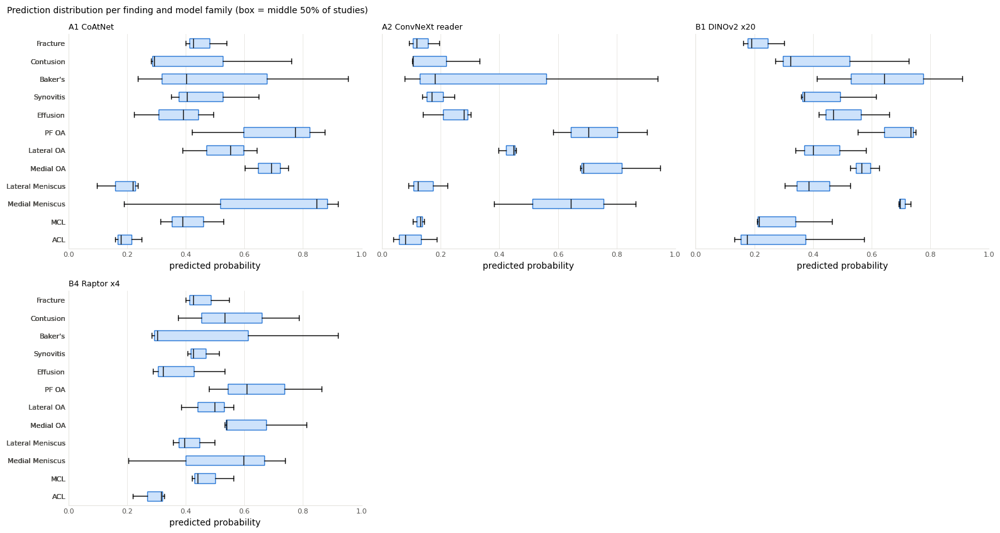

only 3 studies in this run: rank correlations between models need at least 8 studies. (The public test folder holds a 3-study sample; the hidden test set and validate mode have enough.)


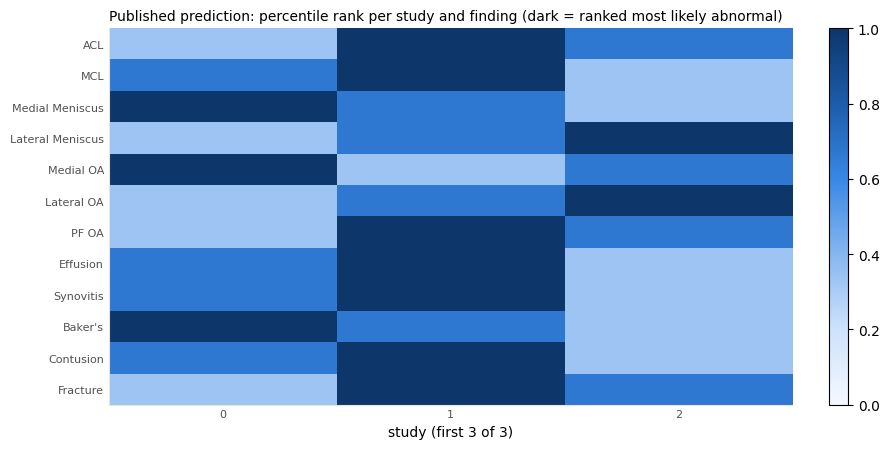

In [75]:
# ======================= Part H.2 - what each model family predicted, and how the blend evolved =======================
AX_components = {}      # display name -> DataFrame [study x 12 findings], rows in test order


def AX_load_components():
    """Collect every prediction the run saved. Nothing is recomputed: no model runs here."""
    diag = AX_OUT / "diagnostics"
    ids = AX_pd.read_csv(AX_final_file(), dtype={AX_UID: str})[AX_UID].tolist()
    out = {}

    def from_npz(path, reduce=None, key="values"):
        if not AX_Path(path).is_file():
            return None
        z = AX_np.load(path, allow_pickle=False)
        v = AX_np.asarray(z[key], dtype=float)
        v = reduce(v) if reduce else v
        return AX_pd.DataFrame(v, index=z["study_uids"].astype(str), columns=AX_LAB).reindex(ids)

    def from_csv(path):
        if not AX_Path(path).is_file():
            return None
        return AX_pd.read_csv(path, dtype={AX_UID: str}).set_index(AX_UID).reindex(ids)[AX_LAB]

    # ---- Branch A: CoAtNet + ConvNeXt reader ----
    if AX_A_FILES["coatnet_raw"].is_file():
        z = AX_np.load(AX_A_FILES["coatnet_raw"], allow_pickle=False)
        out["A1 CoAtNet: probability"] = AX_pd.DataFrame(AX_np.asarray(z["values"][0], float), index=z["study_uids"].astype(str),
                                                         columns=AX_LAB).reindex(ids)
    out["A1 CoAtNet: rank"] = from_csv(AX_A_FILES["coatnet"])
    out["A2 ConvNeXt reader: probability"] = from_csv(AX_A_FILES["convnext"])
    out["A3 fusion, first weight table"] = from_csv(AX_A_FILES["fusion_v1"])
    out["BRANCH A (CoAtNet + ConvNeXt)"] = from_csv(AX_A_FILES["final"])
    # ---- Branch B: the first notebook's pipeline (only if it completed) ----
    if AX_branch_b_complete():
        dino = [AX_np.load(f, allow_pickle=False) for f in sorted(diag.glob("dino_*.npz"))]
        if dino:
            out["B1 DINOv2 x20: probability"] = AX_pd.DataFrame(
                AX_np.mean([d["values"] for d in dino], axis=0), index=dino[0]["study_uids"].astype(str), columns=AX_LAB).reindex(ids)
        out["B after stage 1 (DINOv2)"] = from_csv(AX_STAGE_DIR / "1_dino.csv")
        a5 = from_npz(diag / "a5_rank_mean.npz")
        if a5 is not None and (diag / "a5_applicability.json").is_file():
            absent = set(json.loads((diag / "a5_applicability.json").read_text())["unavailable_uids"])
            a5.loc[[u for u in a5.index if u in absent]] = AX_np.nan       # 0.5 placeholders are not predictions
        out["B2 A5 x5: mean fold rank"] = a5
        out["B after stage 2 (+A5)"] = from_csv(AX_STAGE_DIR / "2_a5.csv")
        if (AX_OUT / "raptor_raw.npz").is_file():
            z = AX_np.load(AX_OUT / "raptor_raw.npz", allow_pickle=False)
            w = AX_np.array([0.60, 0.10, 0.10, 0.20])                      # view weights of the Raptor stage
            out["B4 Raptor x4: probability"] = AX_pd.DataFrame(
                AX_np.tensordot(w / w.sum(), AX_np.asarray(z["raw_probabilities"], float), axes=(0, 0)),
                index=z["study_uids"].astype(str), columns=AX_LAB).reindex(ids)
        out["B5 CoAtNet family x4: rank"] = from_csv(AX_OUT / "_coat_family_rank.csv")
        out["BRANCH B (first notebook)"] = from_csv(AX_B_FILE)
    # ---- Branch S: our own model ----
    if globals().get("AX_BRANCH_S", {}).get("status") == "complete":
        out["BRANCH S (our own model): probability"] = from_csv(AX_S_FILE)
    out["FINAL"] = from_csv(AX_final_file())
    AX_components.clear()
    AX_components.update({k: v for k, v in out.items() if v is not None})
    print(f"{len(AX_components)} saved prediction sets for {len(ids):,} studies:")
    for k, v in AX_components.items():
        print(f"  {k:<40s} range {AX_np.nanmin(v.to_numpy()):.3f} - {AX_np.nanmax(v.to_numpy()):.3f}"
              + (f"   ({int(v.isna().any(axis=1).sum())} studies without a prediction)" if v.isna().any().any() else ""))


def AX_spearman_by_finding(a, b):
    """Rank correlation between two prediction sets, separately for each finding."""
    ok = (a.notna().all(axis=1) & b.notna().all(axis=1)).to_numpy()
    if ok.sum() < 8:
        return AX_np.full(len(AX_LAB), AX_np.nan)
    ra, rb = AX_rankpct(a.to_numpy()[ok]), AX_rankpct(b.to_numpy()[ok])
    ra -= ra.mean(0); rb -= rb.mean(0)
    with AX_np.errstate(invalid="ignore", divide="ignore"):
        return (ra * rb).sum(0) / AX_np.sqrt((ra ** 2).sum(0) * (rb ** 2).sum(0))


def AX_prediction_distributions():
    """Raw probabilities per model family. (The published values are ranks, so THEIR distribution is flat by construction.)"""
    fams = [k for k in AX_components if k.endswith("probability")]
    if not fams:
        print("no probability outputs saved"); return
    n_rows = (len(fams) + 2) // 3
    fig, axes = AX_plt.subplots(n_rows, 3, figsize=(16, 4.3 * n_rows), squeeze=False, sharey=True)
    for ax in axes.ravel()[len(fams):]:
        ax.axis("off")
    for ax, k in zip(axes.ravel(), fams):
        v = AX_components[k]
        bp = ax.boxplot([v[l].dropna() for l in AX_LAB], vert=False, tick_labels=AX_LAB, widths=0.55, patch_artist=True,
                        medianprops=dict(color=AX_C["ink"]), flierprops=dict(marker=".", ms=3, mec=AX_C["grey"]))
        for b in bp["boxes"]:
            b.set(facecolor="#cde2fb", edgecolor=AX_C["blue"])
        ax.set_xlim(0, 1); ax.set_title(k.split(":")[0], fontsize=9, loc="left"); ax.set_xlabel("predicted probability")
        AX_style(ax)
    fig.suptitle("Prediction distribution per finding and model family (box = middle 50% of studies)", fontsize=10, x=0.01, ha="left")
    AX_plt.tight_layout(); AX_plt.show()


def AX_ensemble_comparison():
    names = list(AX_components)
    n = len(next(iter(AX_components.values())))
    if n < 8:
        print(f"only {n} studies in this run: rank correlations between models need at least 8 studies. "
              "(The public test folder holds a 3-study sample; the hidden test set and validate mode have enough.)")
        return
    C = AX_np.full((len(names), len(names)), AX_np.nan)
    for i, a in enumerate(names):
        for j, b in enumerate(names):
            if j >= i:
                C[i, j] = C[j, i] = AX_np.nanmean(AX_spearman_by_finding(AX_components[a], AX_components[b]))
    fig, ax = AX_plt.subplots(1, 2, figsize=(18, 6.2), gridspec_kw={"width_ratios": [1.05, 1]})
    im = ax[0].imshow(C, cmap=AX_SEQ, vmin=min(0.3, float(AX_np.nanmin(C))), vmax=1)
    ax[0].set_xticks(range(len(names)), names, rotation=90, fontsize=7); ax[0].set_yticks(range(len(names)), names, fontsize=7)
    for i in range(len(names)):
        for j in range(len(names)):
            if AX_np.isfinite(C[i, j]):
                ax[0].text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if C[i, j] > 0.75 else AX_C["ink"])
    ax[0].set_title("Agreement between prediction sets (rank correlation, mean over findings)", fontsize=10, loc="left")
    AX_style(ax[0], None); fig.colorbar(im, ax=ax[0], fraction=.046)
    steps = [("B after stage 1 (DINOv2)", "B after stage 2 (+A5)"), ("B after stage 2 (+A5)", "BRANCH B (first notebook)"),
             ("A1 CoAtNet: rank", "BRANCH A (CoAtNet + ConvNeXt)"), ("BRANCH A (CoAtNet + ConvNeXt)", "FINAL"),
             ("BRANCH B (first notebook)", "FINAL"), ("BRANCH S (our own model): probability", "FINAL")]
    steps = [(a, b) for a, b in steps if a in AX_components and b in AX_components]
    moves = AX_np.stack([1 - AX_spearman_by_finding(AX_components[a], AX_components[b]) for a, b in steps])
    im = ax[1].imshow(moves, cmap=AX_SEQ, vmin=0, vmax=max(0.2, float(AX_np.nanmax(moves))), aspect="auto")
    ax[1].set_xticks(range(len(AX_LAB)), AX_LAB, rotation=90, fontsize=8)
    ax[1].set_yticks(range(len(moves)), [f"{a}\n-> {b}" for a, b in steps], fontsize=7)
    for i in range(moves.shape[0]):
        for j in range(moves.shape[1]):
            if AX_np.isfinite(moves[i, j]):
                ax[1].text(j, i, f"{moves[i, j]:.2f}", ha="center", va="center", fontsize=7,
                           color="white" if moves[i, j] > 0.6 * AX_np.nanmax(moves) else AX_C["ink"])
    ax[1].set_title("Re-ordering caused by each blending step (1 - rank correlation; 0 = none)", fontsize=10, loc="left")
    AX_style(ax[1], None); fig.colorbar(im, ax=ax[1], fraction=.046)
    AX_plt.tight_layout(); AX_plt.show()


def AX_final_heatmap(max_studies=60):
    P = AX_components["FINAL"]
    fig, ax = AX_plt.subplots(figsize=(min(16, max(9, 4 + 0.2 * min(len(P), max_studies))), 4.6))
    im = ax.imshow(P.iloc[:max_studies].T.to_numpy(), aspect="auto", cmap=AX_SEQ, vmin=0, vmax=1)
    ax.set_yticks(range(len(AX_LAB)), AX_LAB, fontsize=8); ax.set_xlabel(f"study (first {min(len(P), max_studies)} of {len(P):,})")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.set_title("Published prediction: percentile rank per study and finding (dark = ranked most likely abnormal)", fontsize=10, loc="left")
    AX_style(ax, None); fig.colorbar(im, ax=ax, fraction=.03)
    AX_plt.tight_layout(); AX_plt.show()


with AX_cell("H.2 load saved predictions"):
    AX_load_components()
with AX_cell("H.2 prediction distributions"):
    AX_prediction_distributions()
with AX_cell("H.2 ensemble comparison"):
    AX_ensemble_comparison()
with AX_cell("H.2 final heatmap"):
    AX_final_heatmap()

# Part I — Validation against official labels

Active only in validate mode. In submit mode the cell prints why it is skipped and computes nothing.

**What is scored.** Every saved prediction set (single model families, both branches, the final blend) against the official labels of the same studies, by macro ROC-AUC with a bootstrap interval.

**The comparisons.**
1. *Published file against Branch A alone*: zero by construction while both blend weights are 0.
2. *Branch A against Branch B*: the 0.949 pair against the first notebook's pipeline.
3. *Branch A against Branch S*: the 0.949 pair against our own model.
4. *Branch B against its DINOv2 + A5 part*: what Raptor and the CoAtNet family add inside Branch B.

All use the same bootstrap resamples on both sides (a paired comparison), which removes most of the study-to-study noise from the difference.

**The weight curve** shows the score for every blend weight from 0 to 1 with its uncertainty band.

**How to read it.**
- Look at *differences*, not levels. The levels are optimistic (see E.2).
- "Inside the noise" is a likely and honest outcome with 58 studies.
- Do not move the weight to the peak of the curve. The band shows how little the peak means.
- The LLM-label row is a reference for label noise, not a competitor.
- **Branch S is scored on studies its heads were trained on with their official labels.** Its number here is not comparable with anything.

The last cell writes a short machine-readable summary of the run (`analysis_summary.json`).

In [76]:
# ======================= Part I - validation against official labels (validate mode only) =======================
AX_val_scores = None


def AX_validation_report(n_boot=2000):
    global AX_val_scores
    if AX_RUN_MODE != "validate" or AX_VAL is None:
        print("Validation report skipped: this is a submit-mode run, and the test studies have no labels.\n"
              "No accuracy number is shown or implied. To measure accuracy, set RUN_MODE = 'validate' in Part A and re-run.")
        return
    gold = AX_VAL["gold"]
    ids = [u for u in AX_components["FINAL"].index if u in gold.index]
    y = gold.loc[ids, AX_LAB].to_numpy(float)
    usable = [l for l, k in zip(AX_LAB, y.sum(0)) if 0 < k < len(y)]
    print(f"{len(ids)} officially labelled studies | findings with both classes present: {len(usable)} of 12 "
          f"| positives per finding: {dict(zip(AX_LAB, map(int, y.sum(0))))}")
    sets = {}
    for name, frame in AX_components.items():
        v = frame.loc[ids].to_numpy(float)
        if AX_np.isnan(v).any():
            print(f"  {name}: {int(AX_np.isnan(v).any(axis=1).sum())} studies without a prediction -> scored with the neutral value 0.5")
            v = AX_np.where(AX_np.isnan(v), 0.5, v)
        sets[name] = v
    if AX_llm is not None and all(u in AX_llm.index for u in ids):
        sets["reference: LLM pseudo-labels (not a model)"] = AX_llm.loc[ids, AX_LAB].to_numpy(float)
    per = AX_pd.DataFrame({k: AX_auc_matrix(y, v) for k, v in sets.items()}, index=AX_LAB).T
    boot = AX_boot_macro(y, sets, n_boot)
    table = AX_pd.DataFrame({"macro AUC": per.mean(axis=1, skipna=True),
                             "95% low": {k: AX_np.nanpercentile(b, 2.5) for k, b in boot.items()},
                             "95% high": {k: AX_np.nanpercentile(b, 97.5) for k, b in boot.items()}}).loc[list(sets)]
    AX_val_scores = {"table": table, "per_finding": per}
    AX_show(table.round(4), f"Macro ROC-AUC on {len(ids)} officially labelled training studies (95% bootstrap interval)")

    fig, ax = AX_plt.subplots(1, 2, figsize=(19, 0.42 * len(sets) + 2.6), gridspec_kw={"width_ratios": [1, 1.25]})
    names = list(sets)[::-1]; yy = AX_np.arange(len(names))
    is_final = [n.startswith(("FINAL", "BRANCH")) for n in names]
    ax[0].hlines(yy, table.loc[names, "95% low"], table.loc[names, "95% high"], color=AX_C["blue"], lw=2)
    ax[0].plot(table.loc[names, "macro AUC"], yy, "o", color=AX_C["blue"], ms=6, mec="white", mew=1.2)
    for i, f in enumerate(is_final):
        if f:
            ax[0].text(table.loc[names[i], "95% high"] + 0.005, i, f"{table.loc[names[i], 'macro AUC']:.3f}", va="center", fontsize=8, color=AX_C["ink"])
    ax[0].set_yticks(yy, names, fontsize=7); ax[0].axvline(0.5, color=AX_C["muted"], lw=1)
    ax[0].set_xlabel("macro ROC-AUC (dot) with 95% bootstrap interval (line)")
    ax[0].set_title("Every saved prediction set scored on the same labelled studies", fontsize=10, loc="left"); AX_style(ax[0])
    M = per.loc[list(sets)].to_numpy(float)
    im = ax[1].imshow(M, cmap=AX_SEQ, vmin=0.5, vmax=1, aspect="auto")
    ax[1].set_xticks(range(len(AX_LAB)), AX_LAB, rotation=90, fontsize=8); ax[1].set_yticks(range(len(sets)), list(sets), fontsize=7)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if AX_np.isfinite(M[i, j]):
                ax[1].text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if M[i, j] > 0.8 else AX_C["ink"])
    ax[1].set_title("ROC-AUC per finding (values below 0.5 are drawn at the lightest shade)", fontsize=10, loc="left")
    AX_style(ax[1], None); fig.colorbar(im, ax=ax[1], fraction=.03)
    AX_plt.tight_layout(); AX_plt.show()

    A, B, S, FIN = "BRANCH A (CoAtNet + ConvNeXt)", "BRANCH B (first notebook)", "BRANCH S (our own model): probability", "FINAL"
    pairs = [(FIN, A, "published file vs Branch A alone  (zero by construction unless a blend weight is > 0)"),
             (A, B, "Branch A vs Branch B              (the 0.949 pair against the first notebook's pipeline)"),
             (A, S, "Branch A vs Branch S              (the 0.949 pair against our own model)"),
             (B, "B after stage 2 (+A5)", "Branch B vs its DINOv2 + A5 part  (what Raptor and the CoAtNet family add inside Branch B)")]
    rows = []
    for hi_name, lo_name, meaning in pairs:
        if hi_name in sets and lo_name in sets:
            diff = boot[hi_name] - boot[lo_name]
            lo, hi = AX_np.nanpercentile(diff, [2.5, 97.5])
            d0 = float(table.loc[hi_name, "macro AUC"] - table.loc[lo_name, "macro AUC"])
            rows.append({"comparison": meaning, "difference in macro AUC": d0, "95% low": lo, "95% high": hi,
                         "verdict on these studies": "clear" if lo > 0 or hi < 0 else "inside the noise"})
    if rows:
        AX_val_scores["comparisons"] = AX_pd.DataFrame(rows)
        AX_show(AX_val_scores["comparisons"], "Paired comparisons (same bootstrap resamples for both sides)")
    else:
        print("\nNo branch comparison: this run published Branch A alone.")

    # how the result depends on the one blending weight this notebook introduces
    if A in sets and B in sets:
        ws = AX_np.linspace(0, 1, 21)
        ra, rb = AX_rankpct(sets[A]), AX_rankpct(sets[B])
        blends = {round(float(w), 2): AX_rankpct((1 - w) * ra + w * rb) for w in ws}
        point = AX_np.array([AX_np.nanmean(AX_auc_matrix(y, v)) for v in blends.values()])
        bb = AX_boot_macro(y, blends, min(n_boot, 1000))
        lo = AX_np.array([AX_np.nanpercentile(v, 2.5) for v in bb.values()]); hi = AX_np.array([AX_np.nanpercentile(v, 97.5) for v in bb.values()])
        AX_val_scores["weight_sweep"] = AX_pd.DataFrame({"weight of Branch B": ws, "macro AUC": point, "95% low": lo, "95% high": hi})
        fig, ax = AX_plt.subplots(figsize=(8.5, 4.2))
        ax.fill_between(ws, lo, hi, color="#cde2fb", linewidth=0)
        ax.plot(ws, point, color=AX_C["blue"], lw=2)
        ax.axvline(AX_BRANCH_B_WEIGHT, color=AX_C["ink"], lw=1)
        ax.text(AX_BRANCH_B_WEIGHT, ax.get_ylim()[1], f" weight used: {AX_BRANCH_B_WEIGHT:.2f}", fontsize=8, va="top", color=AX_C["ink"])
        ax.set_xlabel("weight of Branch B in the final blend (0 = Branch A alone, 1 = Branch B alone)")
        ax.set_ylabel("macro ROC-AUC")
        ax.set_title("Final blend weight: score on the labelled studies (line) with 95% bootstrap band", fontsize=10, loc="left")
        AX_style(ax, "y"); AX_plt.tight_layout(); AX_plt.show()
        best = float(ws[int(AX_np.nanargmax(point))])
        print(f"highest point of the curve: weight {best:.2f}. Do not simply copy it: with {len(ids)} studies the band is far wider than "
              "the differences along the curve, and picking the peak would fit noise.")
    print("\nREAD THIS BEFORE QUOTING ANY NUMBER ABOVE")
    print(" 1. These studies are part of the training data. Fold models saw four fifths of them during training, 'all data'")
    print("    checkpoints by their name all of them, and checkpoints may have been selected by their score on these same")
    print("    studies. The absolute AUCs are therefore optimistic, not an estimate of test accuracy.")
    print(f" 2. {len(ids)} studies and a handful of positives per finding give wide intervals; differences of a few")
    print("    hundredths are noise.")
    print(" 3. Branch S is affected most: our fold heads were trained WITH the official labels of exactly these")
    print("    studies (each fold saw four fifths of them, at full weight). Its score here says nothing about new studies.")
    print(" 4. The only leakage-free comparison is the competition leaderboard.")


with AX_cell("I validation report"):
    AX_validation_report()


def AX_write_summary():
    summary = {
        "run_mode": AX_RUN_MODE,
        "n_studies_predicted": int(len(AX_components["FINAL"])) if "FINAL" in AX_components else None,
        "llm_label_studies": None if AX_llm is None else int(len(AX_llm)),
        "reports_processed": None if AX_reports is None else int(AX_reports["has_report"].sum()),
        "official_label_studies": None if AX_gold is None else int(len(AX_gold)),
        "llm_labels_vs_official_macro_auc": None if AX_gold_macro_ci is None else [round(float(v), 4) for v in AX_gold_macro_ci],
        "preprocessing_experiment": None if not AX_experiment else AX_experiment["table"].round(4).to_dict("records"),
        "training_demo_final_epoch": None if not AX_demo else {k: v.iloc[-1].round(4).to_dict() for k, v in AX_demo["runs"].items()},
        "validation_macro_auc_final": None if not AX_val_scores else round(float(AX_val_scores["table"].loc["FINAL", "macro AUC"]), 4),
        "validation_comparisons": None if not AX_val_scores or "comparisons" not in AX_val_scores
        else AX_val_scores["comparisons"].round(4).to_dict("records"),
        "published": AX_PUBLISHED,
        "note": "validation numbers come from training studies and are optimistic; see Part I",
    }
    (AX_OUT / "analysis_summary.json").write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2))


with AX_cell("I summary"):
    AX_write_summary()

Validation report skipped: this is a submit-mode run, and the test studies have no labels.
No accuracy number is shown or implied. To measure accuracy, set RUN_MODE = 'validate' in Part A and re-run.
{
  "run_mode": "submit",
  "n_studies_predicted": 3,
  "llm_label_studies": 4406,
  "reports_processed": 4407,
  "official_label_studies": 58,
  "llm_labels_vs_official_macro_auc": [
    0.87,
    0.8312,
    0.9002
  ],
  "preprocessing_experiment": [
    {
      "variant": "reference: the reader's own preprocessing",
      "macro AUC": 0.9153,
      "change vs reference": 0.0,
      "95% low": 0.0,
      "95% high": 0.0,
      "verdict": "-"
    },
    {
      "variant": "no millimetre crop: whole image squeezed to the square",
      "macro AUC": 0.9163,
      "change vs reference": 0.001,
      "95% low": -0.0041,
      "95% high": 0.0061,
      "verdict": "inside the noise"
    },
    {
      "variant": "min-max scaling instead of percentile window",
      "macro AUC": 0.9158,
      "

# Appendix

## Where the code of each part comes from

| Part | Origin | Affects predictions? |
|---|---|---|
| A, B, C | written for the first notebook; settings extended | only through the settings |
| D | new: image-processing walkthrough | no |
| E.2 | validate-mode input redirection | only which studies are predicted |
| Branch A | model code of the public two-model notebook; one long cell split into six at function boundaries; four marked edits | `[edit 4]` changes the amount of work, not the numbers |
| Model tours, attention | new | no |
| Branch B | cells of the first notebook, byte-identical apart from `[edit B1]` (its RadImageNet stage is left out); time limit and two gates added | only if `FIRST_PIPELINE_WEIGHT > 0` |
| Branch S | the inference half of our own training notebook, DINOv2 folds only | only if `OWN_MODEL_WEIGHT > 0` |
| Stage C | final rank blend and publication | **yes** |
| F, G | new: checkpoint contents, augmentation, live training demo, preprocessing experiment | no (they run after publication) |
| H, I | health table, comparisons, validation | no |

## Known limitations

- **This version has not been scored.** With the default weights its scored file comes from the same model code as Branch A of the 0.949 notebook, apart from `[edit 4]`. Any blend weight above 0 is untested.
- **Run time on the hidden test set is not known in advance.** The publication cell prints the minutes since the start; on the Submissions page the duration of the scoring run is the only information available.
- **Our own model is run and shown, and by default not blended in** (Branch S). Our RadImageNet folds cannot be used at all.
- Validation studies are training studies (E.2): levels are optimistic.
- Stage A1 does not record studies whose DICOM files could not be read (it predicts on a black volume). Only failed inference (neutral 0.5) is counted.
- Stage A2's flip is not an anatomical mirror for sagittal series (see A2).
- The fusion weights of Branch A and all blend weights inside Branch B are inherited as they are.
- The four CoAtNet family readers of stage B5 run from external scripts whose code is not shown here.
- Checkpoints are loaded with `torch.load(..., weights_only=False)`, which can execute code stored in the file. Only attach datasets you trust.

## Ideas that need a measurement first

- Retrain our RadImageNet heads after fixing the weight loading (strict loading with the correct tensor names), and fine-tune the DINOv2 backbone instead of freezing it.
- Use the anatomical mirror of stage A1 in stage A2 as well, and compare in validate mode.
- Train the attention head of F.3 on all 4,349 report-labelled studies with proper folds; out-of-fold predictions would also allow the blend weights to be fitted on thousands of studies instead of 58.

## Glossary

**Imaging**
- **Study / series / slice**: one MRI visit / one image stack within it / one 2-D image of the stack.
- **DICOM**: the medical image file format; one file per slice, with a header of named fields and the pixel data.
- **Plane**: sagittal (side view), coronal (front view), axial (top-down).
- **Pixel spacing / field of view**: the size of one pixel in millimetres / the physical width of the whole picture.
- **Fat suppression**: a scan setting that darkens fat so that fluid and bone bruises stand out.
- **Windowing**: clipping intensities to a chosen range and stretching that range to the full grey scale.
- **Percentile**: the value below which a given share of the pixels lies.
- **Laterality**: whether the knee is a left or a right one.
- **2.5-D**: a 2-D network that receives a few neighbouring slices as its colour channels.
- **Slot**: one fixed input position of a model, for example "sagittal fat-suppressed".
- **Mask**: a flag telling the model that a slot or slice is absent.

**Models**
- **Backbone**: the large pre-trained network that turns an image into a feature vector.
- **Head**: the small network on top that turns features into the 12 scores.
- **Convolution**: a layer that looks at small neighbourhoods of pixels; good at edges and texture.
- **Self-attention / transformer**: a layer in which every part of the input can exchange information with every other part.
- **Attention pooling**: combining many feature vectors with learned weights that sum to 1.
- **MIL (multiple-instance learning)**: learning from a label for a whole study when the evidence sits in a few of its slices.
- **Parameter**: one learned number of a network.
- **Logit / probability**: a network's raw score / the score squeezed into 0–1 by the sigmoid function.

**Training and evaluation**
- **Pseudo-label**: a training label produced by a model (here a language model reading the report) instead of a human annotator.
- **Loss**: the number training tries to make small.
- **Epoch**: one pass over all training studies.
- **Learning rate**: the step size of the weight updates.
- **Overfitting**: doing better and better on the training studies while getting worse on new ones.
- **Augmentation**: random, meaning-preserving changes to training images.
- **Fold**: one part of the training data; a fold model is trained on the other parts.
- **Checkpoint**: a file holding trained network weights.
- **SWA**: stochastic weight averaging, the average of the weights from several training steps.
- **TTA (test-time augmentation)**: predicting several variants of an input and combining the answers.
- **Percentile rank**: the position of a study among all studies, between 0 and 1.
- **ROC-AUC**: the probability that a randomly chosen positive study is scored above a randomly chosen negative one.
- **Macro average**: the plain mean over the 12 findings.
- **Bootstrap**: re-computing a statistic on many random resamples of the studies to see how much it varies.